<div style="background:linear-gradient(120deg,#14213d 0%,#2a4a9b 38%,#4285f4 70%,#c96442 100%);padding:32px 34px 26px 34px;border-radius:14px;color:#ffffff;"><div style="color:#ffffff;font-size:12px;letter-spacing:3px;text-transform:uppercase;opacity:0.9;">Name That LLM &middot; an error map &middot; 18 models</div><div style="color:#ffffff;font-size:38px;font-weight:800;line-height:1.12;margin-top:10px;">Which LLMs Look Alike?</div><div style="color:#ffffff;font-size:17px;margin-top:8px;line-height:1.45;">Where a fingerprint detector gets confused, what the strongest public notebooks already do about it, and where a better score could come from</div><div style="margin-top:18px;line-height:2.0;"><span style="display:inline-block;white-space:nowrap;background:#ffffff;color:#14213d;border-radius:12px;padding:3px 11px;font-size:12.5px;font-weight:700;margin:0 6px 6px 0;">18 models, 150 prompts</span><span style="display:inline-block;white-space:nowrap;background:#ffffff;color:#14213d;border-radius:12px;padding:3px 11px;font-size:12.5px;font-weight:700;margin:0 6px 6px 0;">prompt-grouped 5-fold CV</span><span style="display:inline-block;white-space:nowrap;background:#ffffff;color:#14213d;border-radius:12px;padding:3px 11px;font-size:12.5px;font-weight:700;margin:0 6px 6px 0;">analysis: simple proxy model, not the 0.704 model</span><span style="display:inline-block;white-space:nowrap;background:#ffffff;color:#14213d;border-radius:12px;padding:3px 11px;font-size:12.5px;font-weight:700;margin:0 6px 6px 0;">no leaderboard claims</span><span style="display:inline-block;white-space:nowrap;background:#ffffff;color:#14213d;border-radius:12px;padding:3px 11px;font-size:12.5px;font-weight:700;margin:0 6px 6px 0;">CPU, about 10 min</span><span style="display:inline-block;white-space:nowrap;background:#ffffff;color:#14213d;border-radius:12px;padding:3px 11px;font-size:12.5px;font-weight:700;margin:0 6px 6px 0;">code collapsed: click Show hidden code</span></div></div>

<div style="background:#14213d;color:#ffffff;padding:13px 18px;border-radius:8px;margin:12px 0;font-size:15px;line-height:1.55;">This notebook has two parts: the <b>analysis</b> (sections 1 to 13, CPU only, runs only in the interactive run) and, below it, the unchanged public <b>pipeline</b> by lightningv08 that produces the leaderboard score (credits at the end). Charts are drawn by code. The illustrations were made with AI assistance (see Credits). <b>The score in the title belongs to the Part 2 pipeline; the analysis in Part 1 uses a much simpler model</b>, because the hidden test labels are not public.</div>

In [1]:
import os
# The analysis cells run only in the interactive run. The hidden scoring rerun skips them, so the
# leaderboard path is exactly the pipeline further down.
RUN_ANALYSIS = os.getenv('KAGGLE_IS_COMPETITION_RERUN') is None
if RUN_ANALYSIS:
    import os, re, itertools, time, warnings
    import numpy as np, pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap
    from sklearn.model_selection import GroupKFold
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.svm import LinearSVC
    from sklearn.cluster import KMeans
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from scipy.sparse import hstack
    warnings.filterwarnings('ignore')
    DATA = next(p for p in ['/kaggle/input/competitions/name-that-llm', '/kaggle/input/name-that-llm'] if os.path.exists(p + '/train.csv'))
    df = pd.read_csv(DATA + '/train.csv')
    classes = sorted(df.model.unique()); idx = {c: i for i, c in enumerate(classes)}
    y = df.model.map(idx).values; groups = df.prompt_id.values
    fam = lambda m: m.split('-')[0]
    order = sorted(classes, key=lambda c: (fam(c), c)); o = [idx[c] for c in order]
    FAMC = {'claude': '#c96442', 'gemini': '#4285f4', 'glm': '#2a9d8f', 'gpt': '#6b6b6b', 'kimi': '#8e6bbf', 'qwen3.8': '#e0a100'}
    plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
    def colour_ticks(ax, names, axes=('x', 'y')):
        labels = []
        if 'x' in axes: labels += list(zip(ax.get_xticklabels(), names))
        if 'y' in axes: labels += list(zip(ax.get_yticklabels(), names))
        for t, c in labels: t.set_color(FAMC[fam(c)])
    def family_lines(ax, names, axes=('x', 'y')):
        fams = [fam(c) for c in names]
        for i in range(1, len(names)):
            if fams[i] != fams[i - 1]:
                if 'x' in axes: ax.axvline(i - .5, color='k', lw=.8)
                if 'y' in axes: ax.axhline(i - .5, color='k', lw=.8)
    t0 = time.time(); store = {}
    for k, (tr, va) in enumerate(GroupKFold(5).split(df, y, groups)):
        v = TfidfVectorizer(analyzer='char', ngram_range=(1, 4), sublinear_tf=True, min_df=3, max_features=200000)
        Xtr = v.fit_transform(df.text.iloc[tr]); Xva = v.transform(df.text.iloc[va])
        for a, b in itertools.combinations(range(18), 2):
            mt = np.isin(y[tr], [a, b]); mv = np.isin(y[va], [a, b])
            m = LinearSVC(C=.5).fit(Xtr[mt], y[tr][mt] == b)
            store.setdefault((a, b), []).append((y[va][mv] == b, m.decision_function(Xva[mv])))
    auc = np.full((18, 18), np.nan)
    for (a, b), L in store.items():
        auc[a, b] = auc[b, a] = roc_auc_score(np.concatenate([l[0] for l in L]), np.concatenate([l[1] for l in L]))

    ART_B64 = {"cover_art": "...", "band_fingerprint": "...", "band_confusion": "/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAkGBwgHBgkIBwgKCgkLDRYPDQwMDRsUFRAWIB0iIiAdHx8kKDQsJCYxJx8fLT0tMTU3Ojo6Iys/RD84QzQ5Ojf/2wBDAQoKCg0MDRoPDxo3JR8lNzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzf/wgARCAC2BXgDASIAAhEBAxEB/8QAGgABAQEBAQEBAAAAAAAAAAAAAAECAwUEBv/EABkBAQEBAQEBAAAAAAAAAAAAAAABAgMEBf/aAAwDAQACEAMQAAAB/Zo57pChAUALAEqEpUoShAWUAJQElFBAIVZQgAAAAAFlAARLlcqmoACS5XlDHRKMzUlmpo58vowvF1S83Spjdupvn05duOB34jNzmy9M3XPKeXhPb5ailgv0fPvN/V8evH5nsDUqUojXbh056xCZBAVvGl1y6cwEAtzTrrnudOYVYLAdOey8O3HVWWgAOusay52WiUAbxqNY3jlQlAA3c63kKlCACIFFJZQEBSVAoAJZQABAAAUEAEKKCUQsAAAAoiwWCywqUZ1kglSlkomdZl4jPQACbm0zz7c6y1ZctSwNTXHty68uY7cmN41mU1mc941nyYns81QWwXpy6S/qee8/M9sFjWRZLJrry641zRnK5GmaXWdLefTmoMgAu+nPc3gKCgN42OPblqylAAdNZ1lzsVUoBN43GsbxyoSgAa1nW8hQEAESyqikoAgLKAIAAAAFABAACUqWACwAAKCUQACyiURRFElGRKAlisbyvAY6AAOmOlzMbwAoIJqa5defblzHXlMdM6zmmpnl25az45Pb5qgqC9ePaP1OOmPl+6S5sM6ZIk1059Ma5iZABbvGpdY3hQQAF3rO28BQlAu+ey8e3HVEqoFlOm8by5KoBLBvOo1jeOVCUADWpd5CksAAgAAUgoJQAAQAsoIAJQKACIsWwAAFgWCwKgAKBCgCxKlgMtZUIAixeWe8muLsOLqOfSknPrDm6F5OkrDduc503nhPovTn88+lrPyz6lnz8/rxZ+c4fo+fq4eBP0Kz8+/Q6Pzvsff35dNVPJ2553bjF0jKotnKOjzeV5eu8geu8cezry/SnTcqdMlSNFi01Ym5mwQoBvNXWLDK23LQzbo0MsqqKItJuWGdTLKpYolUo1ABAAAiWhAAAAVKCChAAoIAAACpSWAAAUEoiiKIoASrBIoEpYADLUWAEjAmyUShrOkY3mopYsuS2xnpy6c8DrzAkqx15ds3hnpNTm6LMXVidJc3fLpzwBmY3zZlJN+Z9/k3HzJN+bUgqC+z4vqZ6+xx6c+frCzVzpQl6XFdOQUAB15dF1w7cdUNAFg+jXPphgUQLA689xrnvHHQZoAHS430xFlAABEsLUqAAAAAAoAIAAFBAUEJYoFQLBQJQAQiwtgVKgUEApAAUSUZm8ryGd1ABdY6JM9M2RRFlBZvn0x05889J054blZaGO2O2b87pNTF1YzaJmyTpz6c8QEzjWWUsSeT63kXl80N+cFEL6vk+rN+vz3jn7QS6zpUSa3rFbwwXTA2xTfTh0OnHrx3qpaAFOvTl1wwKlBLBvG41jeeOoszQAN6zemalsiwCAWLCkKlAQlVKAAAQAKACAABCyxQAAFlEsFQsAABZQLAlQAAACiY6YOIz0qICnXl1S51nWQVLALOnPpz3zwOmAKQvbh3zeUs1ABEyVnpy68sUGc46YZkpM+P7HjXl8yN+eoKgvq+T606etjpz5+0aQmZuwXesGub4+a+g88eg84ej08/0S8uvLeqlqlAOnTn1wwsoABrOo1nWOOqjNspEpdazrplLLAEslApCyiVChCVQAQFAABAAAUEAEUogCwAUEohSKIUlAACAAqCxQBKOOfok1wd6fNe449quXPork6JebpLOethnTWeDs1ni7K4upM7M3OOquLss4zvg5a1ZmZ1qOLqTjn6Inzz6YnDy/Z4s/l5+hzvz+Bffp+ffoaeB+i69c9rnes9+M6xeTrF5OkV8P2+QvmZKUAHu+F656+N1eTpdXleo5a3uJvLJm5qxCwldM3Ky3ncNSWNCWE6Ma3KLAEsUChIpRCoKEAAAAAAACggABKWVCpSWCoLKECoLFJZQAEBSUQFlAARLleYzsAB15dLLy3iwRQsWDtm51jMreIKA114d8a55s3kBLEllk1nWMgRKSApV4Z3GM20zdB159JrXHtwbBZnWRLF35XqeWvligAHreT6x63Dry3pZdW3I0yPp1x3zYkuiWAQ7cekdInn0HOhKBu510zdYupoaiWAFQLBZRKAAICgBYEoIACggAUEsKRYLKAJVhEtFgSxRFEoAQpAKAIFMbzLzGdkoA6c92MbxYCiFFnTOs6xkbyCSyk78e2dcZZvNSoBlZJvG8ZAgAFqy8W1zi6GbUrWdLeHbi0BnO8qC3y/U8s8sUAA9byfXPT5dePTVZaurKQHXfPpzchbUsAN41J1iefVRi0ZoGrLvIVrXPes0aRRLKAgAAAi1KBZKSgAgEKqUSoUIBFKlAAIFSyykoCRYtBKACUAAAgUzrMvMZ2AA3jdjn050ABQdM6zvnlG82UAO3Htm8ZZvIJUFilx248wXIARqytYIzUCg1nos4fR8zdAzqLlReH05PzfL3814V9ynhPeq+L7rtT5/o+Xpq3LdvxcuG79V+Np9efmR9f2+PY/QjzSpRrG8umdZ8ugxQlqDpc66YDRYOiXpkCUAQKCUEBZQAABAApCWhECwWgBAAUEAQWgBAWUIChAUAECgEDkMdAAHUuXEoFUFDrk1z5jpkCUNdDF54N5CwB0Jd8znrELzBFDVG+cGFC6Gp0FfMTUFiCgdaL8+SgLQdTVnyG7Mm75eTrqCgED9FTx5UidTnd4PNqUzQAOlOuAoDWjeQr/xAAnEAABAwMEAQUBAQEAAAAAAAABAAIRIDAxAwQQEmATFDIzQUAhIv/aAAgBAQABBQLwU2AnBQoUKFCjl9jVPVhNeg7rq2G5sCy1GwE7FbUcVhGwPBjYdisJ1l2eTRuPrrZ87AybARxW1HFbU7FbUcVtRsDw52K2p1l2aitx9dbPnYbk2AjitqOK2p2K2o4rajYHhzsVtTrLs1Fbj662fMWG5PE1BHFbUcVtTsVtRxW1GwPDnYranWXZqK3H11s+YsDJsBHFYRsNTsVtRxW1GwPDnYranWXZr3P116X+6g5NLc2BZFlqditqOKwjYHh5aoUFQVBUKOYUKKI4IldSoK6ldSupXUoMT2yn6ZYpUqVKlZW10HNIRCKhQVBUFRchQoUKFCin/VFUKCoKgqCoK60woUKFHMcR5PIUqQpCkcEItXQLqF1C6hdQhCHBPEqV2C7BTw54aHbhe4cvcuXuHL3Dl7hyZukDI47BdgpUqQp5ldguy7BdgpCnmV2XZdguwXYKRRKlSpUqaJUqVKnyJ1Y4PEKKG2QVun/917J0ssCyEcVtNkeLmwEbLs2D/DuPsr2KOK2p2K2p2K2I2Go2B4cbARsBOUX/ANoNOv8AZXsV+VtTsVtTsVsRsNRsDw52K2o2AnZ5jiFChRUajTuPsr2K/K2p2K2p2K2r8rajYHhzsVtRsBOz/Iadx9texX5W1OxW1OxW1flbUbA8OditqNgJ2bB/h3H217FflYTsO3DQvche4XuF7le5TdcFNw7FbV+VhGwPDyKo5iqOD/qioDgisDgiiFChQtzplymF2ClSpCkJrXah0NP0tNEVRxun9dMma9k6dNRVHlk/ym2UQjpgr0mr02r0mr0mr0mICieJUhTzvbGxxxIUhSFIUjmeJUqVKkeRGyaxwf6Rwawt7Y2OMDNbTIsAz4ucVhOsDBsnN8I4ranYrat7Y2OHYrYnYrbZHhxsNTrAwbJzfCOIUKFCjkJ2OTQFvbGxw7FbE7FbbI8OditqdYGDZP8AAEcVhOxyaAt7ivY/F3xmtiOK22R4c7FbU6wMOsn+AI4rCd8awtZgc12k9qhyh66vXV66vTNDUetFoY1/x5c8NR1yvWcvWK9dy9d6Gs9aWt2NLbI8OOK2p1gYNk5qGYsBHFbU741tTx/nVdV1XVQoQCan/HnVMuqmKmo4rHi5smscOrbwRWLI4P8AhqA4NEKOAIR/0cFP+VYxQL45/8QAJBEAAgEDAwUBAQEAAAAAAAAAAAEgAhARAzBQEhMhMTIiQEH/2gAIAQMBAT8B4ZiZkyNlVnZvw4L2OCfiCHBet5cWoMRm9dnZ+nFwXqCHBet5cWoMUK7Oz9OCioIcFvLjMmTJm2TJm2EYRhGB6R2jtFGljzfweDODu0ndpO9SUVKr1bweDxzzjVBRdnbUf5hov9jgt5cWoONUFBjs7anzDS+0Oyst5cWoP0KFUFF2dtX5hpfY4LeXGdR1HUN2yZM2wYMWwYGjFsHSdJVRlYOyzss7DNPS6TAqTBjnmKDgovYX8a4tQYoOCi4f4YMWX8a4tQYoOCi9hbS2Vx7FBwQ7oewh7K2Vs//EACYRAAEDAwQCAwADAAAAAAAAAAEAAiAQETESITBQA0ATMkEiUWH/2gAIAQIBAT8B6qyZmgoB/IQdhCDs8wh+wKMB1YqKeMUFG/YQOEIO5hD9gUYDqxFlBRv2EDiJ5hD9gUYDqLKytWytXUVqK1FB26HnXzj+l8/+LyeckWFLq5VzTStK0lEce63W8N67LZbdi2BpdXRiMwdjiEDmBToDsGwcVdXmMwdjiEDmBToDqxFsHcLcwdjiEDAowHUWVlaepaldXV1qV1eIK1LUtSJvy3iUYX6sREHIes2BzBydAIHqhFsHeu3EDmBT8wFAepEWwd67cUDQrBWCLAalPO8B1YiIFNxV2PTbwPTpin//xAAqEAABAgQEBQQDAAAAAAAAAAABAAIhMDFwETJBcRJRgZGhECBAYSJQYP/aAAgBAQAGPwL+fMhp+7Xt3te3e17d7Xt3tOZDd7Q0VFRUVFH05j3QGK4310H6aFk8SuSzeFm8LN4Wbws3hflFYi0+HKQRyNpzIf0tOZD+lpzIf0tOZD+lpzIfLhFaLRaLRaKNlsW1Cj7sGDFBveVhzkYHSy0QsreyoOyoOyo3sqN7TGyH9PWqqqqqraBsh/S07ZD5Js82Q+07d5Dj92nIKpiFkKyFZCshWQqI4QuEae6C1WqgSsxVSsDWyR+MbXmQPj//xAAqEAACAQIGAQUBAQADAQAAAAAAAREwMRAgIUFRYWBxgZGx8aFAUMHw0f/aAAgBAQABPyH/AJ12oNCyPJqRoZgIJGw1lkeKcOSdp7Gtn9inyIernO1g3ConoqD7GhULRoeg+kGii2ULPFhvEsQQQQRhArUIy77Dvn/m/ZzR7HQuL1C6jbqPe6NuLPDj/wAAlxLYwQRirUZc9h3z/wA37FmnFsoXF6hfRtx91C90bcW+HH/gNxsobZJ2yr/sb5/5v3mTkbGTgkkkkkvL1C6ibqNe6NuLPDj/AMBuNlBUZf8Aah/N+6CcKx0L6JeWUNx91C90bcWeLLlCwsoLLRi1IntxQRpq7XBGDZh2onaja0zybjVQb3SNnh50OAlwdB0M6CXAn30IggbkuCXBD4IfBD4EGQBoO4dofKO0d4ctQpGnZjPfZZAiRIkRNtDm6Izx8DBIS2JnViUxKMYIZDIIEhYMSJEiRITCENGpAkQyGQxOCR5qqk27FpYkaIZIkSJC54vgQyRDIZDI8QZKJRKJRKyyiScjuQaK7wIZIrk2D0L4OtfB1r4Fwr4Fwr4FS2ntgWBKIEcD1hK98ZLJ0a/oaNw7A7gfPC541oinKUMShkp6p4NpXwPUIkcJI8Wiuz1CHZ6h6h6wkeLRXIdkT1j1j1hOs8ZIECGGIkeMwQIECBAlPw90E5Q7UIGjRZ2hkF8EYkEEGh9DG5xY8XWGPoZZxlPq9yR6vXFZH0G4U0HlDRKhMtdh2oPKHoqCenhMZba1GKtSE1eMECQkTDWV5Fc+nR1yhc6Luo1zLKG4t8TwRhbToIy2FwxGd3eMEY3ou59WindnbL3iySSSiVhuo1zLKG4t8emqaKzIRgjIGksgjKV8t+RXPp0RuyLB4NqxtdB7j0N7HQbizx4b6OyiId3nV6JXPo0U7siQ2Thc6Lvom+i3FnjwtZbQspFzyu2CusryK5/MqC6PtKQ7sUN5L2NqHMe5sf8AiyP7P/ckePmR4+ZxbtM0XXyqyb6LeWEk+Kmq2pDIZDNeCGJ2JQoLjZEEYwLAkBstssG68JLEPIyGQYcBHRHRD4G3BLhknsNUuyE9K5Q5IWHxgRIYXcSRtzsjXCXduWI4ER0OSGR0Q+CQtEaY3x7EjNrsMcy/T0wbLsh8EPgjohkPgTsShRg1jPRLwSYlCwaya4LxGVySuSVySuSVzksQ5JXJK5JXJK5yWJXJK5JXJK5JXOWVySuSVyNrfLJPZK5JXJPZcQnLaP1RH/8AAflj8cfjD8ILShQJCwhyiVyQ5OxDTlEyMs9boP8AL/2EWOodQ6h1DqCadnOJvshyQ5IckOTsE1sTjK5JXJK5JXJK5wkWvhr0G5vmQnKGhEzmTaNh4ztHpg+2V4LBvOnI0PUggggjDVg03ztK7LPW6H9gnUG20vNJcLj0Ujc3zxMJnOnKwT8UrWbKNfQRcyvBUbi9mjC4u5HbJcyz1uh/Yj76D6hqDeOmT8LtobjZRr6CLn+C4XUSxJYIwvLtBe/Qt9bof2I+3GTfJc6JuHaoT8SNxso19BFzzMVG4uULy7QXv0L7ZUCdZw+D7sEzmbV0a5jJJJpE/ETcbKNdQRc8+9G4uULxNWR5L2IZ0Y507SPxT8E/BPzT8cZe4MSbI+zFMUa34Jup+x3DuEFh7n6uClWtrPnNuHbPOYnHiNYy1US+jcz2B8KFxczwXUZczUjzpqXPuxk90RnTNKutROUnzludcq3hD1GocZ0oQkqM6UvBdM6y8E3zpvhEyMyYNQ8kEYJCHroJoZoIkNSJDgggjAhBAFkXI9HGDDfPndj+ZZUhDoLSi//aAAwDAQACAAMAAAAQOGjCCBJbSSSeqCKLiDD6i+++u+WqCDWyuBoc9XWY+fsMBroWeIkmnqdDjSDWsJ2+rd2uessrDDUrLDHjBBVLAhtDi6qTCb9NCiKLPLCXjHBCGe+++y2uWKWnSZL8IEndbOMQMhhZX/j+6+saAqiK1oDjenX+++4jDDUvLD/DBBRpoB9/qairKiLLLLf99jD3SWym++iK++qSy66DLGA+uWxrErFKD/qWkIcpASYDg5BUnrDD+Id+6GAHPrIzDX3HJBNjIV9zPHb9KCCT3V7D7V5j2eeeuueO+yGCFS+k/vuQhNjXBkbOepa5FHZgr9JCliC2dgb8dW7Nt8/6y+SqSpAHtNsAAF9BOjbjjCSODj9PDTnti++2iSyyyCRHDS+ug9rCIQTQwlTCAC9lixPPwCViOVZhWf8AQX5ZTUeMvBdUATbcXvvvi9aec7m07x29wgg08wT9Q1vjrgkgj7ni6Qwjvsj6dDPS/wB/Y5hWEDXDrGIu4J6Nv7YkjRUP0G9v8QtXkImFX3rb74QnUMLYYoMpIoJMPnHMNcdb776paZ7r6rUp7777LX0/2+kBbFb74Zt76flzxXhPb8c2Rm54u8vP/wAZxBa1tBVEOTSIVpW+GSmTKCTiKCDDDCPHGy+2+iS6y6yCK++OaCSGKu1cOFmcuAfDK18a55dV74kdlrSmyOcgAR3IwquRXOlr0Qfe/jW+HyGODDLHDDTDRPHjSmKuOSeOa6CTCKeqCDSiDWqaG9+4TsOOhCC6sKLCweu1ryC7FiEgAR4oME8RVrxo/qAomCW+OuSiCnCChCDrCTjBi62qCROFCyyiC6+iD9aDLDkLCGBrCDr2+LD2V99EHwhSGJHzM/AAAVhlJ5b9a6Hx9gAV8rCyqjDDzGKJiCHD6SmHDySGLBqKD2CiCSCCH5iDDLUQ9+CpOSCcC3PN+99/UGOiLtSS63lJi1P4qNfLzJfbxMWX8+COiDBefCiCCDfdeDfeCfDCDDeCDCi+DCCf9hdiD+/e9gCDAAgfjf8A4Yvv4/P44IQ/3APHPI/I44vAHAQ/ooPHAfPIwv/EACQRAAICAgICAgMBAQAAAAAAAAABETEQICFRMFBxsUBBYYGR/9oACAEDAQE/EPzlorwiRuDg0B+BsaFhi0mhHmsic2L5kfQvFTR36NXpbRuBuMG3huPByvKYG5wSSSixfR9C8VNHfo1pbShTDxQkbbWQxuCSSmltVdELw00d+kTzInJ9ExsxOCWDYfNj7R9w+4axBycMl2S7ENJyOI5HDI7HyGiSxrZ858om5HB8iOwkF5lJLJY2/TJ4WlBYY2M9TXJBAuOR5w2H/wDejEg2EIpoheGmjv00jc6UE+CdEEECjRBA3MZ2Gfdp9j60Eimq8NNHfp7a1PCvD0oM+3Sr/frBciWKaIXhpo79QmJdEuhjE4JEuhsNSRzJQMfMRAg0mR7GnZHsVIIv2f0P6CucyzkhGC1LxJksljGvTq9F41cNbcvDoWpUQQQXGv1hC1QswR4TGvTW0oU8O809ECQgQIRYZBGysRGf3oymjvDXpbaUKeHd5iRWtFWi8jWsEECWSRBBGicEZd+oW8ymlC2bi8DyqHeEkX/KDvH/xAAiEQACAgIDAQEAAwEAAAAAAAAAARExECAhMFFQQWGh4fD/2gAIAQIBAT8Q+E60VjRBAgoSEl4Q5PRLKJumLeHhNS0d6Mro9FC+lPhvR1onI1yQIscmn+xpdk8W1WjvRldHooX0p8d1pYd4WL6f7GYOLCvDxfRi0etdHooX0p8hoQICSQ1ggkJxQvESfwXmM5M4+VOBH/n+ECIknkmPFctkiWBivHJzup/CfBPgbw5OSQ2/0aTsj0R6EvmEPCIFTetOFgw0oWJwuhAuleNE0ULaNK+NA60VkECxcklEiBcMJHQumF016ChbSnx3WlsrF9SrLF0gumultG4H5JWafIaEfSIkkQQQQJwJvCXhPwchOuCXhPwbPEkkkDnGBEeJJ6E4JfhL8Gw+RSckvwdsROyF6QvRQKXx30ll6cORIWXXS9VqnE5gSIaJKLwMeGlH4v4zrS2ttSrL1/e5BG9Q4BjxTH5fFdaWHpbUqy6F0MW8CQogUXJ/EfxCistwSiRiZXCcCcr5J6W0uNkwXQxdVCrR2MZxqWa4/8QAKBAAAgECBgICAgMBAAAAAAAAAAEREDEgIUFRYXEwkYGxofDR4fHB/9oACAEBAAE/EBY2sOpAzQYlkZ11p81YqxTIVGkRSTqvfhSwOip0NDPwTbV9B13DpEiXbrIQrLjUabHQXAXETsLQs06GTo3dJoySljcslj1I80x0KPIn3kSQ0VhskmqGpm4i3WRr8kE+hpG1qsDpaGLY1dIbbvje6+R5HssKE6ZD+SGbWvA8stiQK7yFjmZtLDSNX8D5NbDQ/gb0xvA3W1b4GLLyrmksvgVFgjMdHXWkY1VmlbIxOl/tUmjzGoGqLkMrtRCqgkILkPrWB5cbUQ2TG1P2x8xJNVRv1dAnn2eBXrI8p0z8LwXuvAEzO/Rf7Qsf/A+5Cx/iIvdrwXdD7/Ba8Cq1MUypJGtdK/BNHVlmaCfh1NBDwL0QSrGg1sSPHI3WCPDpxOl3tYoQ0SrNqMS7EEImZVmLcQiKGf4qsjzzohsmP7vuNmJJJJJJP2uweW+3gV6PYXLHTLvVHSaRS914U2fofP8AAsd3wPreD8VFzteC7ofZ4LX4UQR4Pqiq6fFEaDwRSR1dqJ5jJJJwa1gimQ71XFejtYZNONl/tDx2di3sQQhUaqrD6VSC51gsZ+T9x3EkkkkiG/V0Gr5wWHKiLHTIfENFqPgN2S3JifgW4ZSjbwi50PL/AB4Lh968H4iLnfgu6H3+C1489CBUyqlg1oqdkk5moy9Fi7Hh6ppWceYmMiv2OVhik0ZbRYr/AGvBZ2RZ2qqOth9Kq806QQWMeO37oblvDImftdgl/kircvikxQzj06KcKEy50Nm8F/oui8B9bwfioudrwXdD7vBa8fyPg6JprVmtexDEQLwThvhQx4FiVIr1gvW5GVWpTRGF0RvizIxIuPdiSj2eF1TJCwj3WBwIGMyK43oM/hodySSSSRMQdYfYl+RwcbUSshOWhsdNTZGdlxjRe2Z2XgXNv4JnjsVsErclEBsmjgzvDnwK4+AWW8C5N/Akt4EhYYo6RWDogiumVHiiiqyeaaFyJRFI5oxD8HZ1WT2Z1VJJRlS1zTAsOZviaIGJznWxzzm+j/COb6Of6HtgSJCsNGodmIWzRyjlD3xzDmDW8xIYqJ5bPYZWnoT6ASP+Q/68k/7DGZSrJaGc2hprdDumpGStOdh0jnFunKLDAsklv0JMbTT7zu3zwK0sy6ThiJki7kWz+Rf6Di/JwfkXCu2IWF8skaTsSpcX5J8eyXHsb0IkoQiTNHR7ONezjXs417ONexq7SESUKw0IXdOOBrSl7G7/AE4V7ONex7K9iddpIakJKBK7oncso2ZxL2cS9nEvZwL2cS9jjsLgyEsiRIlzWR+0nR7OFezjXs4V7GO70JJKFao4jgXs4l7OL8nF+RbxYZNS1XAsPVdaPBOdZoyaWpYXgWN9HVZJew8EEUsTVkEZDUqGRGJogr1D9IP2g5BQ7ZkEDaV3QgNGyUPMRcFKyJdkfGYkWf4Od+jkfo5n6HufgbSSnK4NkLmbGbmz4C/q5/nz+nxf+KObekBMlRArwLefoj39Ee/o7PQ930NndqByh/Y0rJK7eyH2SvRJSLN6Al/wBvt6gz/A/g1HofwQIjUQD4sxWNeBZoTEuaCDf0L/ACHf6O/0d3ofQnnzRuDSYf8AkP3I/Qj9CP2IbQnns6SXlnsJevob8+j9yP3IX+IcxmbPKrRXZ2HYRbkOfRwMYQnnVpczu9Hd6O70d3o7PQrR+DmqpNFgiqpNESTWCCKNViueCdiXSBZYJEiCaRSTIhUmMMmhoSNSh4WhN7DbbnWsjoi4XHjljQlblkRZU3LYGhozLTUaGdtCrQEolEVcDuHjJEifVbB4XNVE3cxmiAXkmO3dkkjaJok7YzP0D4JP5X5HBNvQZsdzIo2lIENbJ3RObBtttvNvHeXmia9CW3LcsmkUTox6aXqGhmTLzx5A7oeRl8c3Imi8GVJJxRzRV1rJNNK9UWJkDQkyM8iKWYsWeBEYWiR5kYGjuNNeRsYuSwMkJbmQmViv0WF0Ylkuj2RBFSWwhHYSPUVqQWMbl0Y8fFjz1fSkjZJJNGj9Nz8LAnDVbZjT1F7teC/4H3rBNUz8VF/wX9Efb4LH3W1sDZrnS9zImiNSK2EyNvDlj+ycDZJdZklyaTSKSTTSs4cqdGldKaVzWyGyvT7fBYy1CRI5jWCyIvU2BsrqsUYrLo/OEiBMJVfOqbQ+cLQo3HRi+rH9X0GycEkjwu3/AEPglR5Eh+AXO1RotSO5GdTuOYTm0F/wPtXg/FRf8F/Q+3wWPBBcmk8Yb00LE4VTumlND4H4XSMGpA8DwdYdKLKjvtRwdqk7CeGaQIkzzuiSaySSKklpAqhQtayPBZPoq1fB2J7ktWWXFlWemx8yIkBJKraL5EydjpFLHVWfSxvR9MEk1s7/APQ8+rBmao0ssKXUP9A23fMkkmkiY6c2xLylEkieH8RGeh4ruh9/gtde8GWC68SrBBYYjXFNWPLmuuDSR4NCTWsVROWFrXBbw3+14Le6LF3geC2fV4GyXR+diebkXJ2RV2FyTqzJ8WP6PoSSTgkt7f8AR+FVLMiFrJUSz8YufAycVz9H3qkidIIpd0Q7vBd0Ps8FrxvinzhVJ2p8VvXQ1qqOiJnE2pMzOqppj08Ko2O2KNqd1VFc/hkY1zOS134EhRcnK8CsuBI7sdnVzSIo1kJKaIjJjGZn4TFa5WL0Zkkkkklx/wDcKGJ6KpGbuQqF7JrlYthlwYEKGtx8NxO09xJb8w1WnuIf5AmfzBslFeQl2rkUODulamZo0aqsJLuhrN4HukZO4gQ3JW4iCKWvvFxVUvSS9fkk7IpYkY664IHW+LQZoTkZ0XJka1sdU1pYnMiRKqHXPC7VVGpTTWTG2RpwcT9HA/RwP0Ruejgfod2hbsUpLIaSNM0CVuiWz9Etn6Iez9EPZ+iWz9D3fJFjLLNWYyzYh7P0Q9n6Iez9EPZ+hM9H6Ins2VLy4aLp+iHs/RD2foh7P0TyUP0SPJP0MzO/1RjcpO6JbvQ23eh7j0PZyno/xha76gY1drsh6rEvV2OY4u7KGjYYm6nORXYnicYX/IbsiIYU7ku+tKGrOZCbdPQjaOOjgfolu9HI9EmSXsslmNUyHK6KWMY2QQz5JJE5Js09yR44+xSl7kyah5plsUODkejmehNN3o4H6OR6HVoW7FqQ4Gq2aM9mTwyW4f6Icvca/siEqM0zIezIezIezF2JeqM3HYslCJJwM6OsOWtZypFZx51dc6LC7GdIoiaxh1O6PCrEU4w/dL4JpMcHF9i2vs4vs4vs4vslOzTq2szcdnB9nF9j2ns4ns4nurG1c0ji+zi+zi+zieybR7rHA2ldpfJwPZx/ZxfYp5EeW4nOqpFIbr2Q2ezgD2HsabPYo1TR2xYL4mKyAWn+5wJl/wBTgX6x9CkX7HwL0JLRZIiEHCQ/7A4vs4fsf90aP3CSxp9Fhn/fyWKBMc/0MhAbSS2kuT/YF/cC/tj/AEBf3gqyujE0nmPYvY3WCHs/ZwzjnHOL7Gs2T6FpE5LLM4hxDiHEOIJp2ciZDLsSTj+KyXIVPgggimtFV4L01ozuibw/IuTLDI+KzhUQOuh3g6wxXWjQl2Qx5bEzTlZGdezNtdBs0ty8THJ/AnKPcaiSuycME8QPmGl8N1HdqObjSrQ62juIiWTfjamNdBLYy87osm7JXGvNmi2q7Do91cl5suP+lovB+02Y1Y+hOGX9EiE8yaSTlNp7ofNYcMZMayGtIkkdU2nKye5nLurkxmNmzdHgUpyrmYEkuTp3i1wrMV8TirxXojPbBCoi1qRVmuHWutNaWZJlXQdVavQjXDe78Ms7UeKwfXjZYuj8jDvpcsTU0ij+ENEECRAgkI5dGSPbBlYmjPwRf0tF4P0+zPpCojUb2JJPUIzPwSSsV/RFvgtdEaL8OtfivJBGBEU1pJmyKXzratq/OCaWvVWGs8MCO6QamhFO8KwKkC/n4LBb2o8MFg+usEYLF0fkPC1KorrvHBAkluRsdHslsS2R0C3MSKl7ofAWqirGT9PJEk1iv6fZn1hFiGglMmOv4qLvaoiaujw4bDT4FrwaXrBFVhgWWPQmkcjRYdHVuiJo8qPMgivzWBDOjsVe6ZDNaSRnW9ZqsFzteCzsi3t4LB9fgsXR+U8Saly78NsydBI6TWR83WErYikCQBHk8wm9pWX0XIpJNJge0Fk0+Gf2JHwGQeoIThUaJgU83REZ57UmlsH4AzSJCaiU9cFr7wIkQh4NB4NcaHkqPDpimRDvTouaEyi9O8FxqvVZwpSM+KaD2oiKvB9i8FnwLe3gsfJ9PgsXR+U8cQnY/BbPwPBe6Imu8f8AcCSqOi+gleKz45QxJyrXflD/ALSJ38sTv5p/pR6ftiCka934QtCMpbvdvkfVsGyaKXc6lS/LHGyXFJC1/cjL/wCyMw2z2Qb8mxdP4Enn8kMRo7KyTbRo6SLOt/QS/mkk1TIFrwyJwKCK/ky8jOsUZYNcMVvXSjYnTojKugh4b0dXbBrhvdrwfkCeyiwKlo+vwKy6E9jxpKL5o1/XwfWfgVnAgsM+BfV/3C0NUWegc4id5ohsR2ElKKEKShwKlPgNkjgMTm3oQ2TSCSRAe0yDW6NAIJx2ponnX8QSJcrwWPsWF56VVYIzEsyLiVXWKzIxXq7STSJwNFjbkkmas0qpaeZaiNTjFeths0gXAqLWmlYIwIkaepIbCMECWZFIkvQSIwxC3EoSSsieWqxIuFlnSN88nVYJ230yVFcDzHteKBTuRJlVUpFG7Eisho7hiwbWeQ9juYs6ukUavm82JRp2ZKtoyJESkBA9CIBTnqJY2yCStdOBkCJO7jvdDfpaLDHLV5szJrRkQ2tiBDqrrkSEIWG6v//Z", "band_pairs": "...", "band_groups": "...", "band_length": "/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAkGBwgHBgkIBwgKCgkLDRYPDQwMDRsUFRAWIB0iIiAdHx8kKDQsJCYxJx8fLT0tMTU3Ojo6Iys/RD84QzQ5Ojf/2wBDAQoKCg0MDRoPDxo3JR8lNzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzc3Nzf/wgARCAC2BXgDASIAAhEBAxEB/8QAGgABAQEAAwEAAAAAAAAAAAAAAAECAwQFBv/EABkBAQEBAQEBAAAAAAAAAAAAAAABAgQDBf/aAAwDAQACEAMQAAAB+zS+e4pJYtCAAAAAAAAAAAAAFlqALICggAAAAAAAAUiwCgiwCkhalAAAUgCiFIsCiGTWciwIAKqClATVwNpQuamdNTKzUlkTUzK245ZyzjHIxoqpYoiiKIoKIsECSwEAoRAoiiE4eTj3vPV7nU59T53q+r5X0OSK3l6Xm+95enrde353X2JNee+xc3w2EsABBKIUAAAAAABYAAAAAABQQAAAAAAAWAtRRFkUWJYFiqIAAAAsoAAABKgkgBABUKQpAlsoKSgJVuJqcmcrGdNTKcZyzj3YmpWVlgDebHJris1yJrNk0MqIsiTQysqLCLEiqk1CKsk0rM3K4pzcOs56nd+b9/L6Dxuf0rPlr9PfXHle1xdHw9eT1Op2vPbn4O14elsvluolggIgUAAAAAAAUiwAAAAAAAAAAAAAAWKspIoAAEKAAAAAUlAAkNMQ5HGORxjecaLAQAoAVIsAJVoCs5s1mNQWrc2L17wm+Nku84rn5uty6m5pZlViyyrNRNEu7jWbZUsVGZqGVVJRJRFEVZFGbbWboZ4ubxfXHQ62Povocjh7zj6Og71Oj3Ns3WM9nOuXed+HpRigsJm1KQAAAAAAAAAAAAAAAAAAAAAABVRSSglEWSrKgAUAWCygAyamIakCWAADFgQW5pvXHa1ZQEEqpQBQSZ1Is1kKJDTPUs5et0PRPP8AMTz1fd8HuV6fY6Hk9Pj9i+Y9PU9M1z+ubSy1FLLLLm3WbkUsmoZmskVEmhm0RVRQqkrranB8rv2vqcPY7nLn5/Z1s9mJ1nZp1+Tm1mzS505MbijOgiIlAAAAAAAAAAFIAAUgAAAAAAAACwWUCwQoAiLCgClgoJZRJBLBKICKIokoyoyozVpYTVza1McWpzzq3ee1evyS8txM3kzKSVZBUlxZep5/k9vP2+p6XqemPH9Hk4uDp6Xn/R489/P+12cGHPybz5fmfWXp8vk/f6/idHj9u+a+j4enSzy9KM0ItjN0llQJNQiyEsUWAFloubMfI82fq8PY+jXh6s51PLWVLKoqw1LpdZ1FGaBkSgAAEoAASghUoAAAAAAAAAABLKAAALBUFSgIAlAAKFgFzYRRFEBKEURRJqEWEiFSWVlWpni3mcfFvo8ubPy86fD6bl6m/D272+r2PD01c6xqpZYnjeuPR+c6/p9/J0ve7eub3423N7Y4u1Y6XF3cy9Tm5tpw82y5aE4ews+Vx9b899Dk9rs/F/SeHr6Fjj6KIolUiyZzrbjppZYhKEUtCWPl9dD6vDv6zPPye7NnP7QBRFCqKajUstEASEoAAAAAAAEUCFAlCUEoAAAAAAAAAAAABQIACwACnX4+2s6XY5g49jy56Y8vudil4eWHhT3pXg33aSpHgcf0cs+az9MPl8/VSvlX1Cz5XH1nH648Hn7js5/nG3dzdzm7nX4+jqd/rdfefb5vlcY19R0vI7adbXs+lL0e9XF1FuLLbm5ukZaLloZaJmblZWAp43h/a9Lt5+n7fxfZ3n6t1+x83rDOnFNeO9zr8ubrWOKOXl4LXKPTKliujvPa+X6/J9bh4/q9c3F0InJ7xZUoFEqgalstNSwABkSgAEoAiksFlgBQIolgKSgAAAAAAAAAAAAAsFgAALBRYAAWCWCUEAhZRKglgBJRJVSaWYzySzqdf0ut0efDnknpjrdjl5olt8fTOqzpbYzbZc2oFlWWLZSpVikiwSjM1CKJSXh+f+le/n8V7Pc8Lv5Pq9fE+rxdPv8AX6/c+Z13zePj4Onm9Dybm+tzY4u7n7HL0ut1ePrcPz3mfQ5fX8ns/Q9Hl5n0FfM7KTx9AIsBSUpTUCygtAACCEFAASwsogKAACUJQAIKBKBCgAAAAAAAAKJKAFQUJUKlAQBYEqoCASiAAAiwiwlAqk1ExNzUw0rNtMNIzaJVlFgFFgUagqUqJblYyogEsEsEslIOn0Pb47PE9vOOb18t2ut8vri8kvoeN7XU+rx+Nj6PufS5PnfV7t8t1LzetS0FAIoLZKagVRY0ABKAQSwAAhYFlEsFAAAAAAlhQAJQAAAAAAAAAAAAsFSiWFlgsBQSoQpSZalRYJRAFEmqYbGG4RYJVZaiRYRRm2KAELBSgFA0S1EESiQAEpJFQqJlYktkS8fB2J47nDrPnqdjgpnsRqb5Jffztl1lYqiwKAqWlXWQ0BFWgAEsKgAQlAAJRKICgAAAAAAAAAAAAAAAALAAAAAAAAACpUBUqwIAACgLAqCpSZ3DKiAiqgIshKM2wFIBZol1YlFiyEslCEBLJUslSyBJQiCWKiZ2l4XKzeNyUxs1lSqNRYsoAqlsWvTIUA0WACFQAABAECgIChAKAAAAACBQAAAAAASgABQQAAAAAAAAAFCIALQAgUAAEKVKEAgQEAAgAShdEtAAAhCAGagQZsCwZISgSkQKEKVKQBKWKUBRYFbp64CgLSwAACAAA//EACwQAAICAgEBBwQCAwEAAAAAAAECAAMEERITECAhMDFAYBQiUHAjMgUkMzT/2gAIAQEAAQUC+P7m/M3+Sb+0v9Zlf+juYH/c+lPZV6/IN+x35O5ubm5szc3Nzfv37Lh9qNtM5fHuYK6S06SkfYfSr5pvt3525v3jCCN4hDwJUEXY5XsHjKcXcAjE2WD0aL4D5pvulgJznOAg+Xv3Wp6FiFF93VfHvJnrOIMCgQkLHtLylOAijk3zPfeLcienXPqJ9Qs0jhW8fwjDcybucqQ2OKkCmtlm7ROVsFTNERV7PUqND4rubm5ubm5ym/a779hltgqCUhY2ZUsTIpsllPGKy31odj8HnZGogLtVWKl7vpPFoq6g+J783c37geL0ffZmXc37MK3lD/DlKf5fwWXf0V8ScSjpKRuFJ4zZnIz7jAkHxLfv9+TZk1pPqTrF/wCB9ezE39R/kBPSJl2rKs1Gg0R76+0Uo7l3wsfXmD5NubHnXXrVLcmyyAbKYzMcT7Zl18H7MOllhHVyOhWz2Ycet65XY9Zx8pLPe2Ota32tc+Hj9Q+YPkhOptmhNazdRmisVt+USAL8vc8SasQmLWqBho2Ixldi2hsWuJRWkstLFV6NaLoT1F2HuMrKcbKNcRldfckgDKyOu2NQbnACj5hvkfvuhWmoDoWQg0zYIB2O/dclQuua41VPYaaVq7dTxSNWls6LCGjlBwQBDvuW1Lat+O9JpvalqL1uX25Opl5PWNNTXPWgrT5TsTYmxNichNichHYBXYEZFvQqLFjMO7qBPsurPeJAF+bCSTRiloAAJruGsGdMzpwKB3yARk4ZSI5rbGylu8nc5TlOQ8okAZeV1ZVW1r01LSnxZid8jNmV71H3x2ZyM2ZRvUt30+3xi/13G5ctdupqa7SJij/Y/wAgPHswt9fMZhamS6lc5IuVSZ16YcygR8+WWPYaqnsNOMlftMrD5T0OPm97c3ygAhdROos8DPEeQ7rWuTkteaa2temlaU+ZN/Ww/ban1FbIyFVJONX0lKi5vpOQbFtEKMJqCtzExLTK8NBAND2uRjLdLEatsfKemVWpcO31JYKNNZAiicFnErFflPTvZGSlMuta5qMd7jVWtS/NOPE6NR66GdWsA87pxgGvfWVpYuRitVFYqac8xHWwN4AeAX+RrLAga5zBZYJVbylggPJU7bLUrF+azdmPhFooCj5qROJWHiZqsTTNAuvwN2JXZLaLKoCQasizRyVK1+CWMXbtQ8kq8CbERnz61lmda0J2acey2UYqU/qCzGqefSsk6brB/TuU/wDO8/yn0Wt3iYNhlWJVX+o29GXktJ+25NHsRORP2LXUrBK03+phHBVlIYGlTBQJ4KN9UnwC+A+Zampr8kRAY1c/kE3bOG54LAP1SRuaM3NzxMC/o7X6s1NfAv/EACkRAAICAQEGBgMBAAAAAAAAAAECAAMREhAhMUFQYBMgIjBRYQRAQnH/2gAIAQMBAT8B67mZ/SHGOMNsqGWnOc+07G0zAcTwYMJFHOL2k5CjJiqXOTNImj7gUCcYOsZ8hYDjA2dr2aTFuU/oHdCTc0CgDE0zTNPVSZqmfM93JYKmfe0VcbSAY1APCZeqI4f3rXNh0rK6wg6wTM/M8f6gPxAdrOF4wu1pwIlQXzkZllRTesquDbj5cTB81t2r0rKatA++suuRNHpK7NJCYgNqzx2+J4tjcItBO9oFA4e1ZRnesrv07ngOdgEwOcwOUI2swUZMstaw6VlNOjeePW2WeqBZj33qV5psq4Sm/W2DFIK6hErAG+NWDOX+SyxV4mP+UP5gSy45MrqVOHZ+IKl1ZiJpTAgOYZYpZDiN+LnGTFoRe0wYPow/Z2HtXMz3T//EAC4RAAEEAAQDBgcBAQAAAAAAAAEAAgMRBBASMSAhUBMiMDJBYBRAQlFhYnEFI//aAAgBAgEBPwHrlKlXyR8oURtgynNMK+lHy+xK8YFQsL+St0RXxP4R1SlSG+QT/t1mlXyVq1atWrUTS91BPcIm0F2hXafhF5ctkesAcAYXbItI3yCji1hOw72+Dedq1atNtxoIBuGjs7p0hcbK1rWPsi85HqYatCLVXAFFhr5uTp44+TU95dmHEbJmLcN+aqOcKWJ0e/hXwQRCFut+6mmMrrytX1UC0GnlS+F/bmi02QdwnCjnHG5+ybGyAaipcQX8vRWrzvIOINhRYhsndkU+GLO83bh1BahlfBhsOIxresTiO1NDbq1q8o3aXArtP+geVYWsGTV6IiB6+EjOxXYQM3T8U1opic8uNlX4MOKruvU2FDu9GnAg0ci6/wCIPcfKEXPG4QcNxmxheaaocO2Aa37rE4ky8ht1q0x67v2TpFatWrV+DeUWIdHsg+HECjusThDGwuaVI0h4Y5SzuceWyZM5pQPe5eqhikfsFHgHfWU6WHDCm7qXEPlPPiHVrVq1avwLVq1edq0/ESaNNqWXXLqPqE5uk0gLNKCQRyNv0TP9CroKTGSyevGPZFq83C+SP7hDl5AgK/qHLjA9m0tK0oCuIID3D//EADYQAAEDAgMFBgQGAgMAAAAAAAEAAhEhMRIiUQMQIDJxQWBhcIGRMEBQoRMjQmKSsTPhUoCC/9oACAEBAAY/AvKAbn8PoijuPlKEHjoeEuP6uA+UkLC5QVkqN1FO09t0Nt3+sqhU+jybKezsWF/vuqFRVWFi8e/kNWY1WXZuK/MY4KdmVhdf6NgHKPusIUBZSv8AS/0sxVBugd+sI7UGsq8rFtDLvFRinooxehWPY0OikcwXj9E/CZftQa0VKw+/kESnbU9AsA5R99/4briyvDXrr9Dpzmy1Kl3Oftx1791MnQIhoumozvatmqK+Lqs4wqQZHz+I+g1Rc41K/Fff9I753+NW+i0GgUAKuVO2ZuCsQGU78bu2y1awKMPsvy3ehWZpCljoWF+V32+dLnGgWI+gWN/IPv3y0CzOXMspn4ckwFGy/lunaU8FlELEhtNnzD7qDQ6FWI6KY91g2NTrooXjugqdlTwUOEFYX5m/0sTTI+ak2VOQWX7RcoAWHfGTYLLRiz4fVZcB6KWmW9oWNnwc19FW2iy+6pU68Hgq3WXalZ3uKhil3DDh6qtW6qW+oUtv2j5iqws5P7WFvqdEGtt3rurhXCuFcK491cJrB+pZL2Clxk7ix9wnbPsNQiOKSYCjZfyUkyVi2lBooAgcfMqlU44NQsWzq3TRYmmCoNH6a/CsrfDkrCzk/tYWLC31Ovdi6uVXcYVyrlXKM23HDfgpKE33HFfhtwtTOm+miaQYMLsPVZmkdFzx1X+RvuuaegX5bPUrO6VlHqpOZ2vymPZX7QvFYdt/L4N1f4WJ5gKBRmiwtUN9Tr30Dh+lU9FDhCgCUS7mKc827FId7q09FVp9t1GO9lUYeqznEoFvlps/VYXiCouzRSw+nFWg3WUsK8eOtXaKX+ypRvaVhYO+vgVLKt0VfuqfYL/ixYW2+fh4lS3M1S0wVG2H/oKWOB34jZVV46LmUG6xC/DL3Qo2WUa9u7FtaDRQ0QO++WqzMVGLQfQpGVyzCmoUgwVnOJRBBQRPACnBVeFllyyw1STJWUQNSp5nanyg5cJ1CyuBWYIdOEJ3XdlaSsxDVbEdT5Sxop7DwdFLgqNHlPCxt9d1KKpK0C/b5VVUtotVZZyqKT5V2Vv+v/8A/8QAKhAAAgECBAUDBQEAAAAAAAAAAAERITFBUWFxECAwQIFgkaGxwdHw8VD/2gAIAQEAAT8h9QJdOXzm+9nsRoGRHUz+3Kjk8E58It4PgeoG4H2Qq88o2kiRLM1CZM2iR9aexuTLk6PJiGNCiXITBHqtmxKZuhFLNjQxY3p9vLuDQbfLBBHMmEj7yRD0EkbEm2wm6bjkmU7obtq8vFDo60FbQjb0Jipr57iFawt2lvyUolZD0SFhXp1j7Z0NHLcnUeV2RxEXRPSTgWbnjqxxggjgjbGl8IpbGRFC0QVXUrfmJQlVQ7Ie6LAS2EEtCG0Th+7LpfcTi5UnZenW+2bHzGYXiyLO0KrQO1uKFCWdBqsc3COinAq9aOeCCOEbUe+LXzC15XkhNVEY4jL6BjE/Iksn4DKYt6sQ42fBshUHpWUQNpMkSJj0cMru1m4EFYEnsdN2IZQbbM1ngxJJsN85GSLiyZf7L9RPtII4tVsqvWGhLUsFNK4syjsRxgbVzKsIUuuZd6SbQxL6D5JdgbgdeeTbZHMuyPY/P1cWq2yiXeRFLgjXcgaHKydBcq7ZMelZajzjH7so9m/YLuMhlJpIyEJAvEIkoQuCt/nP/BeQbfSdedE9R5OhJS/KBGgLM6svFeWO85LnitDrPsKu1E73aejMnslKA987odJJmKfftt22YJswREmq5hrwfCCCORcLPRrZPTfSni0V2kTWTlkb6COucu5RJMZMG8kRB1uuSz5LYaysZ2fFQ1Q0hNBbpiA8jaMiSWgxf0cx1GsYEnGZYMhIfndJdnAWB7oq2QinlSizcGPmXBejjfWjjHOhJfBDaETuK3ReS+gZCF1JJ6Dggi7Y6T4X6oaht/JUWOS5FFpoOWnkdN/YFGeKTblbgNoTaxeYJdS3whcBy882Vh3CQ0mITTwYqdRnsPLyLpkPL8oSEmYrunNqSKW2PulYZ6kWt/KFlpIhJD5Y516ajoyRdQKWQ2tmWYauNSZmqpV9juA1biMfQlbS1luytMYVsQpaK7WQkozX4QVXKlp+krSblRis6tRtm5FCvCHMXgiCCOHhyS6MRCykmaO7ZljKXbruEI20JXbL5JQs0PgC84T54PqL022s17jzF7mk9z+gR/mP6x/Y4MfPrDS1LVhiFq5/UdHGXb4PqhdG8UNSKQeEYhcj0ki7Yiq5eb7Dk8y7ZHJeHif4FtZFkiOCBIgrVnoQWcqvst7zwjle0pl0yRmxcQQITij9ajLotViaBrCZ0mJiSV2xjuZKUxVXd4IWfuDcH1V6IXvaQ80Mxn+PgyYmD+4f1D+4S1DwTwdfhCrzK6kvUUniYQSWRV4JorqrI9A1oPb4G2XwfpBs+CNPg8fAzL4HVVn9Ct4S4t5CRjpF6GZty3gRPOVGDthrhb8zBhfo5EiZowRAp1i1kRO4rLbjBHCCOaOaSS0peK9iHWlI/KFUdt+ZdSrcrRXJtCohLUuCib+Q1Y90eVCcqVzvCKC0Dtm3E5e7wRjSxL+rEc6yxme0iqqt2yZPG2pIk2SEuCxNEI5eGAmoLRDB66iz/cSeD9i+zZixiayvsfKyEIQklkuhBBBHJHOi8LNufnQBgvK4bFcjNroji3SVkTdrZCqG0zBJ3G26eB3o0F0WyDlpVuZLGjX7kutksjCcu4FPhYvF9gvS0dZodwU9UriHFGiDrRbAlFL7glhWghElwgRL7qiu+hKT5qutxMeRZopZn6VRFA6DIYhUopsiRXOyGdIsg8ve9RGF+sjw0uLW8xrrLjBl9TJ7fF34JbdatkDL79/gT1EWS9ZwQQIahjawMmJm2ws5bCuCUkIgjso6sxuys/B94QiYLMTHoIRZ3GIR7XI0tsNuEimZTqSxiqjJi7MbGqtyxH6KEUWDpVjnNMxbG/wsiKh8Nt2S9TwQQQQR2SXGOrWfYI58C86EyqtSbgxFceVTQh1Ma+1It9e7IB/pcPW8c8cH/hqJFTdEszrQSa/g40JWxYykwShVkbeYk7hrQVKdqvUMEd0l2jqoL5GCjAUd5RjDYIuoNOgbQqiCKJeBfVZBDI5II5hHQjsIF201VcwAiZJE5QkwITvMuhQhPA5vri9Ux26UiXdCC1SWPBRpCFr66ZHZphLvo66XrCBrrIf56XMur//aAAwDAQACAAMAAAAQKzs+CCCCCyeuC+qC+o8mgyW6y+GS2662s+ez5hBNZ9x51xxfj60MYTH3kakvSjfr2evN1BVhdmoHyo6yKpzUZaP+NB+GCCCSuOe2KCWi2+Q6Gq+OK+uWIQ2RV0hBB99pBBJJlvC+A4I/r7nAQPd6FKuGvACQ82ywmn52vAUKun5+9S9MpD+GCSCSS26mGSyGaymG6iC2W+sRxBVFBhBdt5hBJFhpLbaMMb3P5QJjYLmiQMKZKrnnQD/IaSCBCq2cKpeJsSX8mK+yKSKKGWyy2Oe++6K2eaqe2wxhV2rDJ91pBFdpVxBDOekgPUo8gIn5N5XPddJ7k3QqnwU0nTjRMIsXQ73Di9Q+KeqaCW+G62+6+m6u2+qCSiy+2qBFVD3DhtBpJ1ZtpDbLq4PZQKsEIaoXk8PRWt8+z0CdGSN1HW6OoVmSX+8fsICB++uKKeqKGKCGSSS++mKiiqC2+uOKDDTDCB9V9xNt5/HCet+9bTJj5IkbAOxSvee1HWuRVzSknINQf3fJuCV/kmDBe+qWCyiCCyGCSSKCC2+qOCCCCWKeCe6u+6NBZ+2N08RdvQrbTIOUObj0dC/iOfZHb4IPS6RHukl28NPnvxzesCBB+qCKCauW8CaW6iCCCCKiSCCCi2quS++uFNdhFZNFVl9BbcAfU6Df+h4ha/7ojzR3xiohOX+4tNciNlP3LkMfHjBBDe+CWS9CCCiiyOCSGG+yuOCO++yeCmimKTzjRB9R9xhlnuUDlOM7h4zEabmdQa6KWX2JmCxQMoYLKwAa59+FmJJBC+uGeSsCCCCGCWCSSCC+++u+i++62uKWWuyLOj1FZNBdNTWU3nhkMeu5dFsBum5yPo/VI1yZPzjmTx3M7AH5BBVNJe+CKS+CCCyOCCCCCKqyay2+2++qa+6iS+LCRDDDB9dNJVrPwMOTlJdp38/WDZ0w1kpsvycOHCUly0XRAWlhFN99DD+Ceg9iCCCiCeCCC+i+ii++CiCCCi+AC++Df+CDd9dfBh9BD/8AwQYYgAHHnQwY4I3oY/PoIgoYAgXooAAQQQffff/EACcRAAMAAQMDAwUBAQAAAAAAAAABESEQMUEgUGEwUbFxkaHR8EBg/9oACAEDAQE/EO7XRsetRBBV/gW7GjlBaQfBaqFsF3qjekGiaoT9GEIQg1HREPkdYTXcRcW45ZbsSui7w3BvqaITVCIQhCEIQhCDSHEz+wN2xXuMoJP6BMC7u9VENaCGc40ZgIcnBEJokLWEIQhCDJK9iFWyFpNiOCvcSckF3KiFg3Sr7i4MpdXgWuRjqgjbruiMtgUR7fgXY3IQhCaQhCEIPAl7XyQK35IQhNF3KCo1jbYW/wCibhYJaT2P8MsqLRXWJQx/bmdeWQhCEIJSNYG3H8HAL+dFqnY1aJatwc/H8iaPcMhCartEJpCaQhBooowVy9yOyEHm3RBjK+4l4aDwk+yGdRTEIQhCdEPMhjEhKnVpCYyNW+vwJu6PyNbjUetAREEY+RKbmiEJo+6Q9kfki7rEEiEIQhNJpCEILM7+427s/AlC4x4yXBgTIjwoxqvdwyqBBRb9TjB/bCGbvfqfdWQhCEIQnRCEIQhCaJ0xi7Gz+RS1DJKs99X7GtwEZ9KvyTqb7zCdcJ0wgkQSIZQnMhGybT8JDV3rb7zPWXTROHmTwhtvfqbg3f8AhlqvWb9L/8QAKhEAAwABAgMIAgMBAAAAAAAAAAERIRAxQVFhIFBxkbHR4fAwoYHB8WD/2gAIAQIBAT8Q74SosaRiYsoj1pdKX8EGsIWsQlxcpovrsCUd8zcH3ykJMSQmUTE9XGMPBSlKUpSlKJlKKFDgFHfwNJ7h7G8fpCI2ENEg+94J2JEPS6ITKXRjYxspSl7YCYPF39yJLznxJ5DHcBtLXuPXWPvOE0hzdYOolFqfFpuLrsyZ5KroPBSjY2MpdFL2DYiCK2bwG/b5eAzuyxPxyMDW2C3vNB7V4CwsfkQVWVoSgnpkN4FcuPwIJ3w28+JAT4DV2Eob+hg8X7HWTj/fyNJs5lGxso2UpS6KUVbiHv4nTx/wqG3BF1KJ4G+8Ui5IqRcvC6dRPK2C3uIjCD0bxfYtWv7sjBsfW4wxS6KITIxZxn5P5LWT0DY7pRq4ifilGKISbwjZG/T59BvBG3XqJlKUWSj7opdKXS6EEzpgzJJFs/37lFU8Daxgp4jyNpPy+B5jP0LNe+L/AKRGf9LyL5rGGylKUulHzkXPkJefw4Pw+wakRobMxtxBBiS5v2NgmunsxZUq9NEIqqylVHkvDr9Q02vX4iKUonRYKPvBCYhXD/0S53moISi4cPcZYeopSlKUpdFHfEuRHE8j/h8fuC4Bdd84+7C+okr7Dyngvm6uRBXs9fyJI9zA87Jclv7epO15Fv8Ay/vgWT44LgUpS6JO9ULRespSlLo2PsFSj0UGyLGHnZ0fNmDy/wBHNYYpNzf90eEJePbeX99TBOFyWPkouwhO97pSlL2WylKUpRhhsbEpX8MeqV6odYZeuB7O5bdixEJiZS6Ihvou9727o12GNjfYg6wzHZlvdiEiEIWqN7EP+EYxjGP8K0Wi3Ektvxf/xAApEAACAQMEAQMFAQEBAAAAAAAAAREQITEgQVFhcTCBkaGxwdHw4fFA/9oACAEBAAE/EKbjGbDHVmw6KkU9671etC0eaQPS0Kjp4FRjrgzTFFjQqbVimKxSYJkeRVXoI2o2lduBosKRs6G28ufQgUrDYlcMSb2FDur+NLnZWRBBBBBFHSNMECRHJBBAuz2ERSDYexIcvLIpNN9MkkjZhe1ieSUbQ/uOalE93o14hBBYkTY+jNy92h4k5fYyfBNhpZ01ZGqbKr5o/RWhotqi1FjRN6wYrbcjgimNEnsSzfXakDpub6oruQJa4GbU3qjIY8KBrmrZOiaLRAreRNvcZJZkRdjv4IHTA1b/AAPgHtpIfP8AQf8AzH9ELl+h1JiXdjdo8ivggggggggjmkEUYd80aHYb9BsmjJJTgTaJ8nuTeGKPmx+VYZgDS6Hs/wAGSCBJkJiSJT47+7EwnsvyMU+8/YmHQnmNIWnJ5ItajvY3pMUehVZjSy9JpFIFVDsKjJrY2p5PFIZakDEeKxX3pbcfqwefUdl0NxZ3R0vR1zVCeiCKTaRM83MocLIhi40+PA025ZBA1YYYYgiqlOU48C+b+TIW8kIgaIsQQQiBwkNkEDsMZFILVijIIGi8xdXJY7o2YJDHplAmbtLHyKFrwzDRwBA/pkmJWy2agS2Vsksj3DdTv+BdCRKCReEkOPm033EFqEQkd5d2baOJYsVRA0fAzzqb9KK5VtLLaWZG4FgZOjc8Um+KXFAzJA1YgisEU80wXZFhZ0b1jj1XRoGn0YI5IHSSdLtkdxlkyeyCZyQQeS3p6K7Et2oSw09npuMY6wJCozB+wt2sZEkEEEDoijGQQRpiiCNAuzuO2f8AwKkzQwkNjF6Mxy+y7RGPw/sIQxMw05PphjEEJOiQ5rK3ZfzUY/4ok3FpvWF0hKS0JFpNx/hCyLW0Ojoxd6dqzTeruq5GhYNo9Dqm4iKz6X10eaIjRHI+x6ENVYtEac1g8mc0YySdOS3vVnYmIRJIlZ+BjsrEXEIRI+YQx6La6ZS34QvmulH2TFGkR7yL6wWEzljyso8JDkNDoggSMCEiB2GBklvirIIGhkEDUEDGpoiCCCCERQhHca4HW1Zglvuk2PwthIELMduYYPVbLl2+Rob2u8P4MRoFZp+wfI8BGoGy92xQlMwh6kyp+RbS73fLELRijPbS6XI0zqjRsbGdKuoI1Z9PNY1JjxXszpVI5HRaGjLSGrCbOiHQkd6+DvXweL4GpYSJXlMn3gtsMvREEGKwMikEUkbaTbcIbvFkeaIVExvvLwYjgWJ6n9IjkfdJ+XPktY1r7S97IYqBWvjF7MS97v0YXhL8ESFp9A8MtTbPYaGiCCBCQiCBKGcg7kEUaGiB0emCCCCBBCBpIsIq+x4dvfoegehF/YIuk7mG7frgSVLJjQUrBdiHPHCFYNvp7ltXbIaPIQr1kyeaRRmx7021+w6tE0x6Ko8V8VYu9D60ZdPaqpGrYUU2pFN9aX+DdlA2ZbpNJpA3CljNuSeMDYnDtYSM38iR9Gb08EEG9GQQiBIggUnfAze+OCI0STQ85h4XQqanA4f8+7IhjIVbOZ6WCOiFuh7uSK73J8wNMEXJwly+fuKWUnKbSuSzWSEQQRwQRQqeaNFmNVY0QOw2yGQyCCNqRSEJLYgSpOdNT6PL8cjNPcW7Z92xrkmq/hw/JynvcYnM3mzHvptdqRqyC2H4kR4aXwSpc+kQoSXCEEi5HqniqH59DFFR1vRaY1PxTakk6yxS9LEEasDr40paFSxKFK1z5Gsv0N6NK2NhzVCEN2LkiCCSSSdFy5tfIdyKsbGW7DVxXtLzsiNrlO6IW8SzX5kZZLfOZuSy49NePYlIjcU8+LD3g7Dcmvgg00Tyvrkh3Ps/7owtIWafvRIggiGIxRKidtLcDUsggggggggggSIpFe9wvwftk25S3suEukYzCUMOfb2+RoQaORfFhQwJCSWwhLiRsaX0bi808UxTPq20x6Wwiauk0UHtS2h+ks0g8Va0JVtxs80a9FrUga5GuybUgXYmISSfW8YrZn3JE4E+xNMaIYxoijJH2MjjYrXW88e4xby9yJ8vLFNp4TLH90WVd8ENL7rsbf7P3HmM4lZ2U/uiw52Q4TPJXW5+5kABKlN8/wB0X/BG+QhJy3sj8P0XCjEJbw8EwS+zyLDHjLFk27vT2fTGknFYIW5FYVCdGxkQMij0LRFEklpb3fCXLZI0nLtxeeWLRv0bW3hb/A1QhBBAkJCCRBUwdYHgjYXFGz31Sea7aVTI8F5isUmsV8j4enzp3Irj0NyejeiNhus6eH5N6OkEEXIIIIsQNDDQ1NECVJETA8vhL6ixV3bsljb1d9ixun2X3IkrLK5aVkyhwJeBOdTEogliEl2xs2wtld+G3kWRL+W35FKY92+Xscq2hd+XliNbYgWyVj6HnoeJQo3/ADE58ZHdle0K+GKSlwveHAx4WXg3af5E5Bt3u5PAiFcsuRBmAsiU/YQNrPLd4exjbo7k2MVOZ8T3XRgVv9jp9UdtCdETwZyRWKwRWKqRIetUwhJLcgsxv7uXf2J2TcTRsuHbFg2YZIsGMaIogSEISpv07mSNDdIpF6bakPzo86J1behNNzN9GSTNEzJZqs6dtHVN6NzYaFSCCCCCCCCCCKIGiCKNEEjhdiZrYTjyJiylw95UGjWsJt+3+F542Qv2JZaXYlpyjKpu/wDRSnf6CZIm6tDcFoMf1LLsnsU5fs88vs/t+x56JvIqxv7cIhPY6jgaSU8oUqGe/cWqdj5eRvHB7vyQMY5QhYZl+6+3uTqn4JYIIJF/ZrieF/gnF6haz6fDLu37g8Psl9AuLv5XeiaZ2ohPajq6QOiIIEhIV0SbYhJcsa1jPw35fXCFZwyxW5H+EQ9jl5bdvtjGl1ikCEiCBKmL0qkwN19q71Z7UejBOhua7ehmr4pv6HBbSqLRNbUbl0RI3SCC/BHTIfFIvYjoglGSKbDSWWl5Yjn4wl+sSP8ADH/lR/qEcn4P7H/nR/4r9jjT27Ql/Y73UUBwv77EcCtL25bx92MINLctialOLq6ayjPRmVjv2hFqRjjr+4IkYzYwnW60hmEhNbMNNl4b+WM5fLUtk+Rvh8/D6lvEqcJEaEeQgxtBPm/QWFV2fjYeyueV2RRBBAkIWDCUpo57vJ+1fVDfeD9jtdCVLS1eVu36CuRRMXVZMlJ8IfMfuWO4jeYfdW6wIiixbyxCS5Y7Jtd4bcvrolc3mYd2+hWcvLPcP9DOA6wQQJCFVFipmswRo2IOap7qjqtM0m5t6WSLaPGhC0vRueRafJ7UkbJExjmlsEbn+rNn8w9Nm73PLQkMK5bIH/vh/wCoJHf5g0gsJct4IGhKzyjePYb3vmxpf+i9/oVSST3Jnounj98XMLK+0m+DZBzz9AhZ+gSQY3hvuDUmy3hqcuIUpkEmoSwtvKBszYrzK/wcITIppZe2t+YM/fBEXZ15sW/dDSJ9u1J8OGJLdT8YJClkUu9+HBbTaT2b+H7J3tYw8CwS5Iew8z/BFpI2PgfkzeSPBLhCYS6FQggggi4w1B7VliZiWQ74e3g+sMUUnakxfZj9ueIrf3n5E0hibKU05TVZJEDdiW42SeVizlyyyyOFf7DCI+xoQSiuF8Vzn+aIojNcZvd8JbvodJmJlv3/AE2J0by/Dy/64pLlrpXOX1wqOw860qqqrGh4ujxWTerJtRaEjc3sOkaHqVtqL0r81jg9qtCiuBU24GSdEV8UjogSoxjVIliUId9yOS6JPAp5GiESxyy7JC2HbA2xoa7GrXFI5efge2OYjjcVUtZb4H9hzWfCz8PcQmDhMsj6SXmytp+4tWS+0OFv/ckhbt2kL5RNRzCn9Hcdx5ME1Cf1IZq4/wArDVd8ufCIdQ7vs5ZYQIhCXsRIkJISEIS6pYwMCCCBpFxoaIEiCBpVpCsq3RN/ORnZRdbpOU90NinNdn1NvGCM9ktp51+cUQR2O89MtJLCMtme7hN/b9ib67SJYS7sH8hN3/ri9uoMsQeRlChpNXTqqN7mxXd/dsi6fHET0vyRhZEJW6Ll9CTvBl28t0bGMggg2IolRCVEvqn0p1zR1bknUzexkzWS80mdDzairNVRipvSaukG5asUeKOkEIijc0aoi9HcdXSCBoaGmS7C2pPwDXJ3WSP7kV7eclD9CXS/RcdPdvP7/Yx3RDc4RhCShECbl/JJYbJN38iQlwX4LiEqIQmJiga4qk3RjQyCKxI9KZU8NuU9mL4Su0W+n5RnYs4aELDxDD/jg5yRO68rKHBp3dkPP6lse8TYdv8A2RVU3i8v/B2+CPrkSGkuLTG6WtqMeHfRb75huuRWbQuuGMaa71RM+yb+BZZDhvs/pG33Dft2xdu7bI9ZaS3n4fUSYOEoSRI3VoaqkQJGNKxqijyXpver6PNNhY0ffS9Szp2vowQOmUYp4pGhYr5NtMV2onTeuKMzWdFtLHgepouJD6DWmU9ieMvdBla8pjBNLTH/AGYR9xkHYW73dCECQkJCRBBsJUQhEEMnkySyyRujrGiaQ7Tbx3O/yQxba52vPvt7iOtMPJ/KGZ0VDWPksiHsVGZUbjKAleR+blkhnCcJgmhlRpI5T4ZGdbTvDFLEplLjr9ENQ3d32JpbM+4P9Clpb4/Uf6MnSJzfuxMcjn6Zu/YwSNj6G33ESSOrpGhKKQRRJfoQfb0PNN6uixpjurojxpvVipB96RHobUeh9FuabUg3IN9Doh6nq9qO21WtCIljUDQ9EKYzFsEEUQq2ZFEIVc4ELySOGOyx507Vdbb3nK5Je4/9SwxxIC0JfobNpekr5L0qyl8DSW2WIIE0ssikveWvEimGcTLghEAnd3x84GCe+1P0lb6k2urtjxgja2BMXpJERpS4FZWpvpgQ2IdFSOzbQtDpFfcto8ejJFEQRG+qNP1qxaIHi4iS9ZsXpwbjWl0gg8EjdGh6IIExAxoaI6IFcRBcQ5NyOBaURNIEKiRMWSG26STYmUQoI7IL8DzR0YySB7RzhkB3WPJBQHyXWw+63S43ECSGrU4ewhsRRAT7IZpdNSwugwWv7lhJZcIT9ZKKb6Ehd+r50uu1PBJkmqwzzXxTbQ9e1xE6d9CvWayO+qFNNqut8HvRxFyIwYVydD1O9ZcC5CJGxkXpFoLDZMkGKWLURIqIivQzckkkdGSSSSSN0sOBkjZIiY2GWMyGnYzoYMMuVdyvKHjbN4uRMEvGBbL+D3ENTZu3v/og2bQnA29l3YnIkJemhLfRFEi46Nf+H7CryRpd8D9D29GaQOu9FkQ9tU0jcmtpo8E8acDpBvSE9h8WPoJcEPhns/gh8Mk9hPshN0Lk/gaf9IjYamhoa0QNDEEEWGho3pBFFVUTPwIlgnRNHSaNjZJJMjZI6NjYziPqMew/uNzPXj/DHhHNmYq7MIXHn4McFRJYQ+CKE+RCEyaTSSSdCR51JXvomuT2H6P31+4iRU6140+NHROqfcnmsGCXCpOjNU9qSM2JJFRZzpkRNINxszsResmTwMwQnkdEVggirRFGXIIIIqvNGbBKzdlxqjeh0kdh4Jtkbox0bpcgSIEZWfJLuhwQZSWzHAgMZd1EIRInWdKU4Eo0roSS81Rvqb4r5rkvTHoW2EeKeabnnT7X0WvGlDFotRPRYVYnQtKHXB2qdV96yToVFomkkiSSo+tEEDGiNEaIbcJNm6cCV2TVsdHrdZo6RpggggQiKRVaZqjlIHRUSnwJRrmk07NqNUYswO2ras0ujYZujBmk0V6ukC0dnVHmjGLNIGTFNjBMs2pGnzTfTvBueTo2FVV31Mgwq7ERSKNH0Qa2tyDYdFewrbv4EhYnyJaZHcnVtR1el64I9ZKXAheaSbiMMQ3ij0Rem4hm8H//2Q==", "band_ideas": "...", "hero_fingerprint": "...", "hero_puzzle": "...", "hero_funnel": "...", "concept_same_prompt": "...", "concept_twins": "...", "fam_claude": "iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAABdmlDQ1BJQ0MgUHJvZmlsZQAAeJx1kbtLw1AUxn+2iuKDIjqIOHSo4qAoCuKodehSpNQKvpY2TVuhaUPSIsVVcHEoOIguvgb/A10FVwVBUAQRZ0dfi5R4blOoiL3h5vz47v0OJ1/AE85qht08A0auYEVDQf/S8oq/9ZUOuvExRiCu2eZsJBKm4fq6p0nVu1HVq/G9f1dHUrc1aGoTntJMqyAs0xDeKJiKd4R7tUw8KXwkPGLJgMLXSk+4/KI47fKHYisWnQOP6ulP/+LEL9YyliE8LBwwskWtNo/6kk49t7ggtV/2ADZRQgTxk6DIOlkKjErNSWb/+8arvnny4tHkbVLCEkeajHhHRC1KV11qSnRdniwllfvfPO3U5ITbvTMILc+O8z4IrbtQKTvO97HjVE7A+wSXubo/LzlNf4permuBQ/BtwflVXUvswcU29D2acStelbyyPakUvJ1B1zL03EL7qptV7ZzTB4htyi+6gf0DGJL7vrUfS2BoLClWsYQAACBpSURBVHja7d17dF3VYSbw79vnXj0sv3DACYnB4EBaBCWkpkYOkCsRyKQNaWlXr/tIOwmYcZJ2mDRl+kg7a13f1UlXOkmm01kpIQ42kLRpx5eZaZkmoW2CJR62AVNCADU8YmxeSew4+ClLuufsb/44R7ZqYmPMlS1L328tLYP1AJ1z9rcfZz8AMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzMzOzaYC+BFPvnqr4h5U1cCVqaAwOsgqgf9s2ovfffvGs7+3l4tNnqn/8X/YDvfPnqwGg2t0trKxr7EkhIF9iB4CdYAK4sgaeP1jlad3b2Ds4X2g04vEooGur1eS07m3cPjhfT3Q3tLIOORgcADaBhR21Gvv7+0Pv/Plio5Ed6Ws3VHs6ko6uGaW25JQRpPOCNFfETCDOYAwzRHWGgESRAURZgAA1A9CMQgpoKIRkF0LcnSrZjSxuG90Td/R2Y5j1gfRw/93+SiXZPn++qnkQFX9tDgA7tgKP/tCPgVivIx76NY//VmXmnpHyGVS6iIGLAJ4p6XRCbxbxZgJzBZYJlAWUIZQEJAnJQIDMb30oqm4JkAQBiBIkpABSEE1JoyT2Qtwm4KUAPAvo2Ri4JSh8J9u17/l3NjbuP/T/cV2lUurt7Y2o191CcADYqxX6RrUaAGDZITX8sx+sdGwr4ycFLib4tiicD6Ab0DyCHaXAdpJIY4SkCCAlmAmSAAUyQlCE8j48qXHFUQeeAwKSimhgKP6GAAkoAZiAKJWK1EilUQr7APxA0iACvi3xoTgyvOnSv9qw7dBuAwBUj1M3xRwAJ8X1X1uthiqA8c36TSsWl9Pm7G4meJeAJQAWQ1hAYlYpBDSzKECjIFKAEUCWFylRAAly3KAdpGO/zyQ0Vlop5G0DcOwnJpISAiWSbaVANLM4CuKHEh8DcD9iXDccsanv9oHh8WFQ7e4W6/XoR8ABMP1qe4H9vZWkb+Bgf3p9taczmd1VIeOVEegF8LaEnCUAMWoUUBNAmg/yi8hb8q+rcLfoCSpaE4pFMCTMuxsdpUBmUftFfBfiOgV8XTPf0P/OP28c6C6oWk3gVoEDYFoU/FotNAYHOdbEVw3hwed7+yLx3kC8R+J5pcByGpUCGhGQ5jeJgZwEhf01hYJi0dUogWgrkW1pVBPCM6K+igR3LF3V/8C/CYK1jUg6CBwAU7DgY2VdYw/3/df1LQzgNYSqJC5OAtubUU0SwxAyAgEET5oCfzRDHEQGIIHQXgpsS6V9ADZKvC3T8N9ftmb9ngPdA7cIHABTpeCvRB1jo/gbr+9bzIgPifjlUuCbUsUM4BCAjEIQEKbDZQGRQSgBmEEyCPHJIN6eKLl98ZpvvOQgcACc9H38lSvBsYK/4dorL2No/g4Y3pOQs7Ko/SBGJAXmo+3T8zpBRQFnZylhW5rF5yB9OcT4hSW33fv8WNfgSPMezAEwqa6nqtUw9sCuX37FkgB9HMDPk5ghYa+gjGSAfO3HPYRRRITQUQrsSGN8DuDNzbbmzZd//r6XJRAra/RbAwfApG7ujz2g91/XtzAJ+CMIHyDZJWkvoAxg4it1xKdREDIQHQnZkUZ9BzF+cumtA3817hoL7hY4ACZV4S+aqWur1eSMuTv+I6L+cylgQRaLGt8F/7UHAZBJ6CJRRtTXUqh22ZqBTYeGrTkATphaDWFsIcwD1191EdT8bAjhikwaBjBcDHTZ6+kaQCI5R8AeRfz5rDNO/eQF9cbo2mo1WeaxAQfAia71BfCB5b2/B/APAcwFsQtC4mvb0qudASglIXRlwj2AfrfnlnUPH/p61RwAx8VY7fPghy4/I0uSm8ohXJ0q7oOQup8/sd0CCHMk7WYJf9yzqv8v3SVwABy/eqhYsLOs0cgeuO7Kd8eQrgrgIgk7QSQe2T9erQGWAzFD0K2jQ+mNl3/lvpfdJXAATHjhLy6YHriu7wZRnwZBgEPu65+A1oAUSyHMaUqbmPGDPbfePegQeO2CL8GrqxXL5gnogeW9/w0B/xNgU/JA3wlKYwJM0qidFBYjxH++/7redy9rNDIVy47NLYDWFP4aQr2OuO6DlY7OUrilFPiBZoy7CdLXb1I8wSmkToKpAj7a88V1X3ZLwC2Alhb+TSuuntFZ4ldKCT+QSjt5YLMMmwStgRKAYVBgxJqN11/x28uKORm+Rw6A1134N37gvbObcd/aJIRfTKN2usk/KZsBCcRMwDCgzz1wfe8fFCHgoHYAHEulkj80T93w3nZ2jHypHPi+VCdP4SchFB/FZJoIKBOU5bsI/ZuPpsb/O5EKyoqvj0WPe9K/a1e+hFoA9hDhUxuX9/7+uBAwjwG8hsJfqxH1uh5a3rcmBH4ojdoJTNLCT4j5fn/KtxA4sMIwgAhFaAUSIRQ7hfHgjmH5bn/FL55Pss83/YoSBGUSMoIZgCxfvcdY7BM4KTcpIRGLAJ+lqN9Zuqb/L7yi0AFw1NdjbDXfg9dXPhOY3NiMcdekmss/tttOsf1WUcDLIbBUIjGaRYEaAjACYS/J7RJeFvQyyV2Q9oNhn6JGGRQhjhIKAMsiSpK6AMwOwOwIzAfwJgKnAOwU0NWWBBabj46Oaz1gUq1wLForBLoQufySNXffprXVhMscAg6AI1hXqZT6BgbSDcv7PpoE3pTlo/1hkjzQmYQQ8m2+O8pJYDPLRkHuArAVwBOQNkN8FiHbEsrlF0dH9m/vKI0MX7zq4eYxtYZqCBt297QnI+1zMKyzgbAokucG6HyBF4B4SyBnAUCUhiE0x+38c0KfLRIx37CUIYC/8DOr7/5ntwQcAIc19urooQ9XemMavgYgU748lSfoAZakyHxjvfYkhPaomCnfm/9fCD0I4eGYhm+1deza9mqFPO/agI3BKk8bd0TYrO/t5Z7TZ+b9+35g+/yjO+1nfbWnE13l85KkdImAS5F/LEgCS5k0DGmk+E1OWOtJQAxEm6J2xRiveudt9zzmacMOgFeo1WqhXq/HBz96+RmxWboH0JslDJ+g2l/F4Fs5kDMkREHPBvEbCLgbbfGeS24a+P4rfweEXlQC+oHe3t64EnWsrB9oChfl4Ri6RGPfuTI/mQi9QG99IDs0HB75WGXuyD5WovC+AF5F4qziwIE9+VkFJygI8nkCs0k81llO+y78/H07pWKg1BwAY/P7q2vXxgeu7/u7wPDzUSdg0O9AjY+OJIT2LOplQP0K+OsyS9+4eNU3dh3aXdk+f76qaxsRPP6Hdh7p9KL1y3vmAR3vT8hfgdDLwM4YT+imKGkSODeL8W97Vvf/mvcbdAC8oum/4borPpYk+B/xeL/ue2XB3xKJvy6V8OUlN6978mB/vBYwOMjJuof+gSA95MCPDcsrvUT4MICrAzEz5i0CHe/WlaCsFMKcLMt+r2fNwGc8W9ABcGAZ6f3XvfsdgbGfVAIwHr9+f75bEMmZUXErwZvT8vCaS2/Oj9U6UKhOstpKAJG/TYljXY8N1/ZeEhLcKPAX8nMKtee4vjk4OJ6TgPGKnlsGNipf4xEdANO06T924m7HOfzHQPZGac9xeeV3cFR/DoF9hG5pqvTpy8Ztif1Ed0M/7lDQkzFkx2+N/uB/qFwZY6gF4rIoDQFoHr9ugTKCXSAebcaRvkvPWL8PKzGtNxSZtgEw1gRcf13lI6UQPh+B49L0LybThCRwZhqzb8ZMn7j0tnseAib8mCwe8mc87kFQr6MOxHW1SmnGC/yYiE9AnFfsolQ6Tk98mpBzY8SnL1l99+9P967AtAwA1WoB9boe+ujlCzSabAA5D0Jzwg/mIFIIXYBGI/GnL+w67c/GFq60uJmfr1SsVAIGBuJhCjtxAroV4wvc+hXv+qkkS/4iBPbFqN0a+/+eyFtAKAokUE6gd//M6v7711aRLGtgWobAtF3YQkAbR0t/mAS+JTs+o/4pgbmSnooJVrzzi/0DyE8HbkUNVBScKoFGhrFZvXnhBwAuWNDTgc7985DyzWXEXc8+++2nTsR1P3AuYrWacFXjsU0rFv+7ZjbrkwRvBDAsKJ3IAUIJZH42Q2cmfurxWve7z8dgqnGzot0CmOK1P+v1uPHDfW9HhnuL03k0wVc5TYC5WUT/SEz/feW2e58vZqXF11kLh3GF/oDT37b41FJz9DyG8JOEzpG4EMCZIGYCaKNQUoh/+Nwzj92R/4wTM9YwflLOhuWV3yD4ORCdEvZP9FiMoKzEMCcTbuhZfffnpmtXYPoubc3wiUDMzITdAJIJLfzk3FSxMdyh6/puunfv65yXTqAaikIfgQbOOeec9mF2vZ0pLg1Bi2OadpNhDoAZERCpEeSDbZFUKvIUxPB+AHfgBNZ6rNfjgTcGqxt/tWFFZQvS8DekTpe0l5y4EAggM2hYwB9sWnH5/168qvH96ThLcFotlVxbrSas1+P65b2XQromCnsnuKZJAzE3VfxKOez5QN9NA3tVq4VjLPwEqkleYPPvP2PRBRef8dYLPzGirq8mEV9hwO8LuJzEDBCjAHZSGIKYAJxNaLaELkbsQYj/bzK0AgmIjUa2rlIpLV01cF8IeC/A7wKcVSxdnqAWAAKA4VLggixLPk5AjcHBadcinlYtgCe6uwUAgbyBRHvMNDyBtUwaAudmUXeUkz0funjVw2mthmOsYapJXugb2cKFlQ6VX34fIquAFgOcCWFI1AjAJoAOAHMBDRerAV+M0uaAsAXE9wBtD1FPPfvMY2NjAJOixusbGEjXVSqlS25Z98T65e95Hzn6VYBvBbR3ol4TEkjSGIcoLH/wI32rl9zceGq6tQKmTQCM3dgHrq9cRODnsqh9E1X4iwNA50Spf7g9Xrv0poebYzsMHUMLTUAjW7Cgp5Nt+5aBO3+DQrfy2nEfoJdBdgnoZD6Y+S2SD4n6NlM+3tXVfGlwcHD0MOM/k2rQq29gIK1VKqV3rv6nZzYsf9c1RPi6wNMFTci6jHxAkKNJwnlZM94IYMV0GxfjdAuAjdf3fjFhuD6boCm/giKJDgrPZ81QeeeX7n7xGGuVBMhfTS186wXXCMlvEbgAwLCAfZA6mBf83QAeIfFPSeR9mzd/a/PY971i3KCyjRiYL6AhTOIZcAeWZV/bewkD7wLUDjCdqOe12ERlhAw9l9zyzWnVCihNp8K/acWVZzaz7Bcyxf0kk5ZXf4QoBkhZKl536ZfuflH5uEP2mn5KLlt47jvOU4x/IOlKUE2BOwB0AjgV5FYJt5cQ/37z5scee2WXAQAa8WCXt5Fh4OS4X30DA+m6WqW0tN7/wIPL+5ZH8G+L8YAJWZ5NcjQhT8li/C0AvzOdxgKmxyBgcUPTtLmsFHiahNGJ2MpKUkwCZwL8k0vXrLtnXaVSeo0bUBSDfNDCsy+8TjGuBXAVyJcBjgI4lcD3AHySafOa5zY/+l8PFv5qUtxPjo0XjP2sk/GW9dXzMYElq9f9HyH+aULOypcVT8xYQBbjflC/eu9vXnnmskYjU602LcrGtEm6TStWlJvZ0+sDcFEEhtjy8FNGcJake0qlPe/Z/PKi+Bpn9yUAsgXdPfPCyNCfCPglAnsAjkCaB/JHgG7vSMq3PfXUwz88JDCmZHP1wGIoAA/M2X4nwZ+N0u4JeXMz9ro26hNLV6/71HSZFzDlU+7ASTHp030E3i5of6sLPwkJKAkYSqHfu3jVw81qd7dea+E/++wL3xZGhv4G4C8FYUfxG8wDeRfTrPrcd7/9mbzwH9jzPsMUXs1GQNXubrHRyEKW3CDh+4Fsm4hWjYCQRTUp/dqzH6x0FIWfDoCTXKP4M6V+MQksI9/htqVifk5dl6CbL1szsGlsvsHRfXc1AZCdde6Fl8SEX4F4HoDtImdRbFL8L89999HlW7c+/p0iKMZP9536TdR6PapaTZbc+s3NAv4YQAfQ+q4AhSBofwg8f1s5+VkAXFepJA6Ak7wJuazRyDbesGQ2gKuyGEfA1s76IxFJtmfS8yHVZwWwWsw3OLrC38jOOvcd78oibpX0BhA7Ab2BwNOM/PWtmx+9tbhPoajxp9/S1UYjrq1Wk54F626PEf9IcFa+u9CEPDJBwq8CUH9vb3QAnMT6iwQvjcy8IjAsZL5VdkubdVFSIDsk3HTJ7QPfb1SrR/kKKS/8C8/56Z4sxpsD2E5wr6BTAfYn0q9v2fKtR4taP2Iab1xxoCtQR4wIfyRgSBPwBiuQIUrDQOx98EPvOaNer0dhag8GTulfrncgT/CYxZ8jURIYW/xkKpDtUXFr6AhfFMAnuhtHUUPXAtDIFiy68AIp+0IA2kEMRehUCv+X6dzlmzd/exvGzQWY7livR9Vq4dI133wEwJdKIXS1eqqwBEIaDSGcliXNqwEAa6f2K8EpGwD58s563LTi6hmReFca4yjZ2t9XUgxkB8HbL/nLb+5oVKtHM9uPQD0uWnTh/AB+DsBcEPsknQrijrM3n/KxrVsHhsc1+e2Q+6o0fjrGuA1Se8t38yGgKAXi/XlDrREdACdjt7E4Ey6NQ4sJnklwVGrd71s8eOU0xh1CehsAHEXfnwBYqVRKGfgZEm8jtAvSqQC+PqstvXEAAxlO4BLdyd4KaFSrYentA1sg/HUSQqdaHJIkg6ThKC3Z8MHKWcUbnuAAOMmctm0b8xojqySBna1uLkYpJiHMIHhXzy33Pls7qumj1QAgbn7h5f8k4ioBOyTMjcAjJe39eDFnny78R7iCecgyxvj5LMYdktpa3g0gmgl5CtvCFQDQX6s4AE6yQSP0DgxkeTeA78qyGCWFFl84SkoFfEUAV7769NG833/u25cQ/G1IOyl0gviRkHxs8+bNu3BwwM+OPBbApbfd8zTIfyiFMKPly4ZJAQyIyAMAA9EBcBKJxfZO6z+y9DSJPwVwhCRb+HzEKHYKeLqcdPUXa9rjq2QSFizo6QwZ6oASAVFAGwL/+IXvPvLM2HwAF/GjMDhIAUTIbo/SCKRWv69PMsURAJf+84or59TrB04cdgCcTP3/Utr+DkKniEhbefckxnLCMqG7Ll71D0Nrq2MbdRwxAGJo378cxEUAd5OcR+pvnnv60a8eXO9vRxXAjUZGQF9/kvdK+hcQM9TKllO+TLhJ4I1dzfSi8c+UA+Bk6P93F/1/8afLSdIOIWvl4h8CSSaNRIWvA0D11a+xzjrvHQuRrzffTaCL0uZsJP2z/Mc1fE7day2j1WpSHxhIFXlniSEh0epXvGkSQieJnvHPlAPgJKggeusDY7Xp4jRKgFrY/EeMUJukF7N5MzfmTY5XfVWkOBo/AuA0AqOC2gF89oUXBn8Ej/gfm+KNSxO8sxnjLkjl1iaMmEliwBIgPxDVAXAy1Ax5laqnbnhvO4DzY1QKtm43GQExCaFdwP2XffrOPbUawhEW/QQAcdGii84FdA2gXSLmQFi/9Td/8e9c+F9HEOdvXHj5rXf/K8lHSHa0dHowGaJiEwpv/8ffuKqLgKbiOMCUC4CVtfwm/XBo/xkk5pNqtrZiECGICPcDQC9e/RVRivghgnMkZJBiCPEvUTzA8Am1x6xWqSQEpBi/mZBJPnrfyl4AmoJOm1NOzxn/bDkAJnMADFaLm5ScF6GZALNWzf8vnq5SpjgEalMeAId9RRQAxAXnvv0tIN4nYE8gZwO4f8szj9+Dg8t57RidP3++ihvTn8W4v6VbvAkUmCVEFxNdcLRh7wA4wfqLwZpA/WRbCG2tLGQhH2gqM/DFUtj9rwCA+mFr8Dx0Iq4hOB9SU5JE3l5kSXARfn2qxdhLxuajAl4CVG7lYCCJmISQCOGCqXoNp9xDeNPggABAEW+NQkt7bcpX/pUR9a2LVz089CrHSWWLFy8uF3PKh0F0gXxsVluzf+zzLsKvu4kuCbxszfo9IDcFhnZJauENZ5pFUDoHAPqm4EDgVAsANvJDHhmCzkgltXYGIFUOgQT/FQD6a4fbMCLfhWjbj0Z7IP0EpP0E2xVwZz7dt5q4+LaoxbcyvweEHklCfo9aGDAUkApa9IUVi8s4MMbsAJiUxu781254b1sUzqLUJFo3A1BQGM1izID8UI3+w31lcQBJ4HsAdohIBOxImuGu/PN+798q2weLcQAkTzQzjbZywxfls0ebIN5yXrNz7vhnzAEwib0h238KwNMApi3La0IEEgJ7kaXfAYD+3oHDHLtdjwsXVjokXAZoH8AuAA9u2fLIVnixT0s90cjDNDbTxwHtgZSgRUuE81c0igBnJKVwFgCg5hbApDU2XTOMJGeS6gAQW3q3yBCBoSQb3goAK1f+uAetmDJa/tFFJM8EMAooACraCxU3/1toZVEpzxqa/xKIbQBLraqmJTCQmaSOROU3AwAOvGVyAEw6Y1Nym0jfKLEDzAeJWtP7lyCUCL30rc64+0AV8QpjU0ZDj4AZyAcKdyLo/vzvB1z7tzKTiz8vaDRGIX4XRFlo3UCgJJUYykB8I3DwLZMDYBIauzlEcmogyq0cES7mE5cBbv3wqoebzB8+vfJ5HMi3k5YuBjBKsF3CU889/diW4mscAC0e+hnb+l3UlhJJspVbv1FJIIL0pql48abmfgDEqaUQwBbuASgBSSBIvAgA/6t62JF8LVjQfUqxvfd+ATNIPZQXfI/+T2jwky8FsqUjdYKYSUiFNwHjBx0dAJNOb3FzJM1vfahQIRCitgOHWx1Wyx/EtlK3iDkABGIkZnjcxfQ4yPCDZhQiWvfqlwBi3o+cCwDVtVNrj8ApFQArix15A3hKJuVT9ltZE0RBGX54hLoofxMd8BMAugCAEXsZWZzf59d/E+FgrawfSHE0aeHmL0X3DyRnFa1LtwAmbQAU03JFzFSLT/8MALMYs8Cw/fBNwXyATwpvIyBIpQj94LmZ6YvjniVrsbHNWBNiJ4imBLaqoAqgoiKo2bWD5YUOgMnY9y8KGIWZrS5pAgPAZgR2Hqm1mFcW8WxBIwDaSTyNfLNPB8CEqec3ICntVkQKqGXTAQMIkhmAWdVatTTVbmKYWuUfqAFBxExFtWwft3xraBFAGpTuHV/rHOr00xd3QjwD4CjINiJsLT7lAcCJavkVfzZHmntIpGjp7M+xJdvsGBx8fsrdwykTAGOl8f1fWJFAmEUyCy1qqR2cAK4sK7XtzR+6+o/92vKs5hsJzc57IohCfD7/TIUuqhPb9RtN4wjzw19bPAYgUCgtOqXp/QAmuz3rn0xEdaDlgzWkgDRE7j3StWSWvElEGXl/YBjSS+PHB2zidMXQBNXyk4IISER5x9A8B8Bk1z40QoqlfOJeS2sCEoxp3DcC/LhpwGPzEOMbIbYXz85Iqdy2zUXzOJlVbkZRLS+lpCCV3zJ71AEw2bWdcioBJUSrzwEGAIltXenBEYdxKvm8gIyaB6A4rUbNlAdeG3oAcIINp0NxQvbuy4eWw85hdwEmvdLQCAWU2fr94QAysskjnkKTZJxTXFcSGB55ubnbRdMcAMfJ3rZ9IQBJ618DghC0L9nx43eFGcj7+DFgDqEMUojgnje8IW36MTMHwHEkMExUg7szbX+VwTx2CpDIhMLewfPP99Zf5gCYBvJpyFInxEiIhIbHHRriMQBzAEz5FKDaisLOGDjigm8OgOkUADow44+U3Pw3B8C06gKQPDgZhZ78Yw6AaZYCnvJrDgAzcwCYmQPAzBwAZuYAMDMHgJk5AMzMAWBmDgAzcwCYmQPAzBwAZuYAMDMHgJk5AMzMAWBmDgAzcwCYmQPAzBwAZuYAMDMHgJk5AMzMAWBmDgAzB4CZOQDMzAFgZg4AM3MAmJkDwMwcAGbmADAzB4CZOQDMzAFgZg4AM3MAmJkDwMwcAGbmADAzB4CZOQDMzAFgZg4AM3MAmJkD4GRFQCg+in82cwBMj7IPCEoglCCUBCXjP2cTq9lRFoC05Vc7/3nN4uc7AOwIjwn1VZDD+Ye+6gA4frZv3z4qYAcikpa1vQQgIiGwY1a6d8QBcBLUAgSaJ6AWiADw3DOP3cE0u5ppdvVzzzx2x/jP2cR1uyRwWWNwlMKTIbAkKLam/CuGwJKEpy5e9XBTAqdS127KBcD27dtHI/CjE1gLcOvWx7+zdevj33HNf/z0r6wkRRjcT4KtvPckSOD+8f8dB4BrAR0hLkLx4UHA4xUA9YEIAClwZxa1jUSZrzMGSIhEOY3angJ3AkBvfSBzALgWeLVaILrZf3zVgagawqVr1m0F45dLSZgRhddVWKOQlZIwg8CXL12zbqtqCFPtzc7UCoBxtUAatd21wPSyssjq0Sz7syzGJwnMBJEeY5MyJTAzi/HJ0dj8lACunJrjJ1OLagisI25c3vfZUsLfbWbaSaD0Oir/tJxwbprpv/esXnfj2M93cZuk9x8IBOKGayuXMQlfo9Qmcj/0Gp4BIqXUKXJUWfy5pbcO3Df2c6fa9Zpyg4AHaoHY/JRrgemHQFxbrSZLbx24DxG/DHAXgbmCMkDZ4VqE+d8rE5QRmAtwFyJ+eemtA/etrVYTTtEu3ZQcpXYtYGur1WRZo5E9eF3lgsjw5ySvlARBQwQzEBlUlAAhEZQQnEESkr4RFD++ZM3A42M/Z6pepyk5Eci1gC1rNLK11WqyZM3A4z2r112FTL8C6i4A+wF0lALntpXC3FLgXAAdAPaDuguZfqVn9bqrpkPhn7ItANcCdnBMqBZYrx8I7o3XX362VHpHgBZEcEaAhiL4Apk+0nPLvc8e7vscACd5CADAA9f2LVOiayX8DMHZpYTlQCJKSDM1Be0m8RAz3nrJrevWHvr9dvI+56pWA4/iPqpaTdhoREyTORzTYqaaawEbU6shrByssr97G3sB9APoHZyvld0N1f12Z8rXAkc1jbP4Ok/jNbcAXAuYmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZmZ2Y/1/wEGHUn4FLB2BgAAAABJRU5ErkJggg==", "fam_gemini": "iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAABdmlDQ1BJQ0MgUHJvZmlsZQAAeJx1kbtLw1AUxn+2iuKDIjqIOHSo4qAoCuKodehSpNQKvpY2TVuhaUPSIsVVcHEoOIguvgb/A10FVwVBUAQRZ0dfi5R4blOoiL3h5vz47v0OJ1/AE85qht08A0auYEVDQf/S8oq/9ZUOuvExRiCu2eZsJBKm4fq6p0nVu1HVq/G9f1dHUrc1aGoTntJMqyAs0xDeKJiKd4R7tUw8KXwkPGLJgMLXSk+4/KI47fKHYisWnQOP6ulP/+LEL9YyliE8LBwwskWtNo/6kk49t7ggtV/2ADZRQgTxk6DIOlkKjErNSWb/+8arvnny4tHkbVLCEkeajHhHRC1KV11qSnRdniwllfvfPO3U5ITbvTMILc+O8z4IrbtQKTvO97HjVE7A+wSXubo/LzlNf4permuBQ/BtwflVXUvswcU29D2acStelbyyPakUvJ1B1zL03EL7qptV7ZzTB4htyi+6gf0DGJL7vrUfS2BoLClWsYQAACUvSURBVHja7d15lF1XdSbw79v3vrmqVCoNHvGEg4xlQ4IZY2zJwhAT0yuBTimEdEKnuwOZaLohDME2VYUtpoSmE3olHUhWSAhhoSIMaRMIYCR5wICxIcYSxgzGA5qHGt94z/n6j/tKkieQjaUa3v6tVWtplaqk9+47Z5999j3nXMA555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHss9EtwvIkQgFFwBMCOtfk137t9K4H1C+y1bsXqteuFceD886GxUSh/tZR/js4da4cfkQ1vVgKJS+U9DW9WMjIiA+SDhmcA7uEdZGQkv5ZjY4xH/826EaUlTA5kxfLJEXEVg5aJsT9JmAYhXVCNQdaRoWUxTkULB2XpjyuV6r7Pv56to38uDwSPfK/OA0CP9XtxeCNsfJxh7ltX/LlK7ZmZNYbkggidF6WnEjgFQBlkUVIBQEqCILnA3o8ERIIdQG0AbQIHJX4vQndbwm829lZ3fPX9bMz9yvCwkvFxRJ8meADoqY6PURDdEXB4RMU9Nv28JLWLAXsuEE8V0EdRINpQDAAjiChAFNS9+gur0wiEARQowAQYAQNQgpCAmAXtx4rZVw3Jli93qt84fA08EHgA6I35/ZGOv+G62dMCwy+b+BLQzhFQItAE1AGRZwUR1r3Ki/FaC8rLmBQEIgFYEFAm1KD0HdE+XWtXP3/9GOtHAsGRjMh5AFgShoc3J+PjGwMArHtX4yyL4ZUgXyJpNcEWpBaACMDAJXxd8+wl5rmCKoAlkH5g0idmq32f/Oob2Th854OeDXgAWArpPvLG/JL3aShrzfw2xJdLGAJRh9BZ8p3+sRtPzLMDlgGUo7A9pX3wS1dVbgDyYqEXCj0ALFpHN+AN1828VOQfSjrLiBkJWT4K+jU8khVYRVBiwBfSyA984ZrqA/k1hLw24AFgkeX8mxOMbwxXbNKqFupvlPBSmtqIaHnHf+yMIE+aMABiN4X/9eWr+z7XjaaGsTHPBjwALPjhjCMj4NgY44brJp4rJm+HeCaJqbxsn98Ddz8xIwggShKKFD5WGtj5/s+//mktjMjgUwIPAAu5889V+ddtmn6lgW8QmFBq5BVw93imBd1S4DJCt8YCr9n25r7dRxdTnQeAhdX580ui9ZumX0/wvwKYzRfGwEf9J97EMgDLJN0rS9647W2V73sQWDi8YR898oO6bFP9rQb+LoFpCPLO/zNf2xTAJKkzTOGvLn/H9IXj4xvD8LA8o/IAsHDm/BhjvOy6mT+B9FsQJtSjt/aOWxAQZwUOhYR/seG9088YH6cHAZ8CzL+5lWvrr5v+7wBeS7NDkDfM49PaGCiUozTJmP7BlreXv+srBz0AzHvnv2xTfSOgqwVNe8p/3FtcgFgF4s5M/N2bru7bJYn0VYM+BTiRRkZk4+MMl1w38VwgvAlQnZ4RnYDZQHdTkfiUBHrPi/9UNQJYOmcneABYBI1QHBuDXjIyMZSy8HbBjEDwKdEJu/4pyCkjnxVaM28FqeGN8MNGPACckNbHkdG84p+VkjdBOpNSQ576n+jPIZUwIfBX1187/evj4wxzh6o4rwEc19R/bIzx0utmXmrGdzNiGvSi3zxNB/ITCIRYYPwvX7hq4G5fLegB4Lim/gDwK6MTyyYL6UdpXE2h7aP/vLbAIKmPtG/uaVVfuwPI4JuHfApwXIyCIDVdTF8N8kwArZ7s/AIPf2Gev4TUwFlBz11VmH0Vxhgveg1SjIx4TcAzgCc79Ydeci1Ob3P2oySKANQTnX3u6LHu+vzu6T751wJItruvKYGxWVf8za9d1b/n6Kxt3SiS9UD0bcVPvrS33i7VwcxvGrhc0uSS3OCjwweQ5Qd8GgMgQ1QKWgFQGVCJQiowzVc7zu8Ox/zRA8wYVamSf77+upmPFMvpD4rTpfuvJ+vbgGxb92eHNys5fzvkB414BvA4hv+8sHTJdTOnpIj/JFp1bu/6khvpidA9oKMAsQZqGYQqgDKIAqTu4R2MeQbUPaZ0/lsi86KgqgB2ExYkZaR9Bwh30tIvZM3dX902dnYTRwWD8Y1+EKlnAD+t/wMYA5ASLxOSVZQmlszon3f8CCIDkEIYgjgExIHuwSUZiJaASQJtgZHITyfOO5xpYfQf5v1YLIH4NqVPCjiNCmsEbID0G0lpdfOyTTNbk6T40S+9tXjz+MZ8CXEeCHw5sWcAP8H5IyquLjb+EdBTDWou+uJfnurH7unDZUirSa5QHtRbAmYANAAECGC+sYl6+GeuBdQGjtQqCOCDQPx+XiNIAqOW0fRzFF+IJH2qGX+kGD50wx3XfxTjGwNADA9/3LcZewB4qLnRYf3Y1MVM+QEIzQX3QI4nkuoDWbfjnwpyBYQIclLQLIRA5mf7P+x3FkODjAKqBL4aYZ8wdapEEiUEmFoxqG1mQzD7xSRJ1oM2BcX3f+ktpY8AR4q9Pi04Nkv+Ftj5w3nDZ2KXClYEFnHxKF82kyEvnD+F4IUkBwHsE/GgoOm5qd1DMhwuprsdZD5VwXmEVkjWipaHMJGVxGyQtDakf+00Gtco63wFwLWXv7dz4+Wb6uvy4iDlW409A5h7f7ridfeUWief+jGAZ5BoSYv2XL8M5CCBswCkijoIcAYUl9h6hkigItmnyHBzFKv2sKIt8ycXxRhj3RCLTEtXAroSCh9PDs684YvvO2XWawO9ngGM5AtJ2iefsgbCqYA6i67z53frpTxzORvS06PUUtSDImZFJUttMVN3VBIRzxdRsEe5Y6Pu9xKzPliaZrHziahwFWAXx9VDt627bvL54xsZhjcr8QVFPRoAhtfO3WJOLoRZDUJYdJ3fkIEomOKFAFYKeBDCAeVFvSX5+QkwCR0RpyNihUxBj1GsPBwIZIMMOCSEtyvGbxjsSxs2zf7h+EYGCL7duBcDwPj2UQFAkNYgCouu8wMZIvsJXNidyN9PodM9Z2+pz90igaqBZzFDRz/teDYiKGWBsoEQ4ycJvouWvOOyTdN/DVIghRE/0r3XagAYHlay75n1fyBxHqTWojjnL6/adyCsALUG4EEJB3vpaPLuY8eqiLhV1D9DLNuxLt4yJIw2ExkHjLxGIe4oDfS9/POvpz+boHcygDzlmzx/chkNp4DKFkW4EwiyQ3ElofMA2yv0Vuc/HAOEDNCpJEsWw7F32ogQ1Okj1AhZfCuMZ7VmZr704j9VDWOM+UYjt7QDQPdwiaxYPllRZSyGpb/dzg9pBainRWK3gCmg9x5K0l2wFEkuR4w1pYXHVb8xJiEqFo0sRPDthPWH1uy/Pf9991cwOiqvCSzxADC8Iw8AEXEVySJi/sDqBT/nJwYArZG4F+A00NP3s6OAImDLGUKUPb7Pz5DEyJBYZCUgXCdgWaUx9JmRUXB4fNw8CPTAQiBSyyQVuMAXwyhf1luC4nkADwrqyZH/IZ9dvm05pXEAlgTFxx/ADUlUEs1oFdCuBXHuTYWZD49v3BiGx/0cwqUbAIbnelbsI5BKCzsAGClKayC0enTO/xiRUSliqNGe+OfHCAkwMRQgjAp82fprp942vpFh3UhvX+clGwD2bt/K7lywsKAr/93UX4hniiiB3O2dv3tpmG9jElhE/Nme1sIIKbIgU0vSdWa8Zt07Z67YNsZspIdvDy7hN74eABAUU5ALczOMQIAZyEGAJwvctaB25y2EaQBImll4EtZwGRAJVo12r6S/tYgPb9g0fdLYKNSrQcBvh8xv6xYog+I5ECYgtOTPI3yUWUB88q5JRJA0qCT5IqDvA/Y3ILVjbW9edw8A857661QAKejz/hN36RGZaQDiXwv6xfXXzrx6fGNvPqzUA8D8jf4RQJngKSL3+eb1E3jpCZFIaGwI/FszvetF75xcMb4ZsdeWC3sAmL/RP3RH/wzCLOSj/4nOAhSzflO4VbDdinYtSGHtOD0AuOMtH/2FlQAOQrLFdWjHEgkCSRJlLJPxH0T++oZNU+dj43DspYKgB4D5GP2JAGk18pVujUV9RNlingpECIHlIP2IwLcgjPTaUWIeAE783F/ID+5cCdrE8Wlwyr/0GF9zf+8AIhhYhfgpWHLZhk1T54+NsWeygNRbwAke/Q0ZIoZApoJm8YSX+6rbh7sdmd2nbZEgU5GGw1sfDicYR35HEqTAwwFBeuS/1SsxQCyGiAcN8R4yeT2A1+7Y0RsXwAPACQ8CFAxDiLEJMABKwWPJAuY6KQAawASWFIQkzb8Z2oyhTWVtKmtaaM9azJqUOkTodJ8WlAiWKrESWKxEK9YirQBYQVYoC5bkC6ZjhzF2CMXu/8mjgsjSE2IAYGWBnyPi760bmVo5Psb9kHhsn40HAHds6WYEVKAwEMFD+RLln9TAup2ezDt8WhLMFNt1U2vaGjMPpmF6Z5pN70mzxoEktCbS0JhIFJqUIqDIh4zshzMCA2mCFZQU+6KVBmJSGcrS6qqQ1lZnhYGndJLaqmDFWmRSFGJgDG1C4cjrWUIDpFkSZShZ1D0AG2nJNgL4y3WjSLblx697AHBPRv+HJNREJQQf++Ekinkqb0UxLUqhw1jfn8we+kGxc+B7xfbkfcXO9M5UWcOUtQgFgonIBEiOPiP0YR3/qH9fEhEzZp1Z0/ROQqEERcIKYlqKVhqIxf7TO4VlZ3aKQ09tF5ef005KyyKSVMraVGxzKQUDBRioTOLXQLwCwF9uHUXgmE8B3JM0/5chAFoGoKP8iT3Jkdt/3dHeUlixFhU6zKZ3ps093y619t1Vbh36YVHt6UShQ1gqJgUBBNNy/osxo2IAOh3Lj9MwgUmeZJh1n7gTqcPFwMAjP2dgUhSYzL0WxsahpDGzJ23svK3KtBStvDyUlj+1XVq1plVadWGr0HdyhqSg2GkYYnhYrWERZgFEiGKVpq9L+pPLRw6eQfL+pX6EmAeAExkBQJNYBdE6XJHrdjlLS0JSUKjvT2bvv6XW2PWNSuvAPaXYnjEAYFoSkqJoBSm0qU7DQBMLZTGpxrQyFJLK8mClwWCl/miFarRCLdJS2FydQBExZFRoMnQapvaMhdaUhdZkEur7ktiaTvJ/u9X9P4sRlgggYmsiqT/4lWr9wVurVhqIxaFzW5WTn9msnPysZlJdFYCImLXyugEXaQE9YQppD4CJUE6vAPDBdYBtW2oPkvUAMB/5v0XFmIIsS5pE93m4lpYFEO2DPyjUH7ilWt91eyXM7i0AENOyWKgIMUCdpsFMVqjGQv85ncLgGe3i4BmdtP8pnULtpMBiNVpSzIMEj9QLESMfMhWgPXS/YXd+r9BmbE1ZNr0rbU89UMimf5x2Ju4tZo2DqTp1Hg5CTKDQYnPXHZXmrjsqU5XPhNLqC5vV019Qr6xe20JaUuzU86xgkU0PGGBIrMkY70XkxQA+uHoHvAjonpwMALQUCgWAbUsrAKKae+8qzf7whlpj750VtWeNaSmyUA1QyEd5S5RUh7LSivPqpZXntUor1rST6spghVp+Pk7IDlfsY2gTWYuPWn04UhPgI/6OBK2gtHZSVug/Nauc/twGYmBsz1g2sztt7v9usX3wu8X2wR+WQvNgghjJQimCKWJnxuo/2tpXf+CWWnHo3FbtjIvrlVOf20gqy0M+PcgWTSBQgkjFMojtgG0YHt6cjI8z5KcGLc27AR4ATswME0IQFMpJWo5ikjV331me+sHn+tv7dpSUtYyFSmSxLyhrGkKbVl4eKidf1KieelGjuOrpraS8PMKSbgGuw9ietqM78CP//BhlyJ8QoBTbVMhrAPnDtwoqLj+nXVy5poXQYWgcSpr7tpeau+8stw58pxQaBxOAYLEaAaC9/7ul9v67S1Pf+1x/3xmXztTOfGEjqa4OMaszzwgW+NQgBAhWEHAfLZ66+5nDqzGOXQv8NEkPAAt+ZAkdY1rKrFBKWwfv4dR3PrO8ueebNcUOWKiKxWpUp0HQWFx2drtyxvPr1VOf00hrJwUwUcwaFjsNAuKRBT/HozOx29CPZAwxtIisSZBgqT/Wzr5stnbmpfVQ35s0dn+zXH/w9kr70D0ldRrGQjmCqcLMnnTyro8tn7n3hv7aWetn+s5aX0+qK0LMmgs6EJCJmBij4gyCGkXMrAGwa2QUHFuiSyc9ABzvtB9AUhnIOlM7ixPfu36o8eOvF0NzospiTUwKUKdhtIJKJz2z2X/OZTOl1c9sWbEWlbV4pNPbPKbRR2UVioitaQMIlgZj37m/PNN39uWzzQP3FOv33VRt7v5WJTQOJEyKYKkWYvNQMrXj44Oz999Y6zv7RTO1szbUk2JfjFnjqFuIC0tUJzFZS9SsYGcBwFZsNSzRQqAHgOPZ+a0oEJj67vVDU9/9zKrQmhhICrXAYl9Up57AElROuajed+4vzZRXrW2Bhpg1GVvTli/+WYBz57nRWwFzr7O88rx2edUFrc7UgzP1+2+szt5/Sy3M7k2ZFGTF/hDq+9PJb390ef3+m2t95145XTvz4jphiFmDC+09KibMEraSoKYUT86/u96LgO5xDSNgWlQ2u6dw8I4Pndrcu33AmMS0NBBiaBUUOlZadUGr/2kvm6qc9IwWSBwZFW2R3EY7khnETpOAmNZWZcsueNVU39kvnp2578bq7H1ba52ZXYUkLUcUy7Ez9WDh0O1/NVR/4Jbq4NNfMVVcfX7rSKFwYbznBIA6WWCSdAj2L/Wm2hsBIJ7gQcYIWKKJ7R87qbnrW4NWWd5BaCO0p5LisrOy2rkvPdh35gsbYNLt+MCREX8R6o7iih0qtMFSX1y29j9O9Z11aX3m3htqM/duqcXGgZSFagRNrb13lvceuqfUd+a6mf41L59OKkMhdvKpxXxnA7K5DRqIUSwBwMyupbsxaAkHgK15RKdlEVJ3H/4JHyWFiNiZTZkUmsvWvKLVd+5Lg5UHp2N7pghAecdfKte8G8S60wMrDYTBC145WTvjktmp7322v/7ALVV16sZCNQKBk9/73EBjz53lwfOHpyqnv6ChmEGhzaOzASHCiBBOYAmOlqi7B2rJ7whcsgFg9dr1+cZXoo582e0JnQIgBi57+vDebitm/7lX7KysvvC00Kkvi+1pAraEd9zmgUCxw9BqM62uCkMXveZQ9SmX1Kfu/ueB1p47y2CCtNQfspk9hQNf/8CKyq47ZgfXvnIqqa3OYnvG8hsShMAYg0Lih6Z4AHhcxuc6Y5iA0Dmhk0wjFNtM+09tr3r+Gx7In26hTmhN2dza+944jyMPBDG2iVaL5RU/1y5d/Jb99fturE7e/emBMLOrwGItAsDM/Tf2tQ7cU1q+9jcmKme8oBk7TSIG0iwCaopklJ9g86Q31SXb/8/vHn0RuBdkCzSe8MYf24xZw5Q1LGZNwgzoyePn83ULMWtSocW+c140e9Kl1+yrnfOSacQOlLWYFvtDqB9ID9z2gZUHb/+bQSiAhaqkGMCknj8XMHiP9QBwjEbzAGBpeBBiQwoJTvi4y4d99bhusTC0ps3Ky8LQs19zaMXz/ueBtP+UTmxNJ0yLQlrU7A+/0L/3xutWtQ99r2TF/jYUpqmQ0BI/x8wDwDE3NgHADa2BQyQeJJCyxw58XLifjUGxw9iatsqpz2msvvSafbVzLp9G1oayDq3UHzoT9xb33vze1dN3f6ac1Pr3o1iBso5HUQ8Ax26ku5c7QneTVpTkAWChTQva08a0oqFnvWZi+XP+4GBSXhZieyZhoRoR2zh0598PPfgvf/Ti2JwoFcqD7Rg7XgbwAHBs5p73ZuK3oxTkefiCzAaggNiZZe2MS+qrLrl6X/mkn2+oPWOg0ZJivbVv+3N2/uvrXj17/1dWlgYHGx4EPAAck/GNowKAZqd+O4gJ0Fc+LvRsoFBbna26+M37+5/+ikkpMGSNYElxOmvsf8qeW975Owe++vfnl/oHG37NPAAcg7EIiV8ZW7WTwF0GlkB6KXkBZwOxe7rx4AWvml7x7D/aQ0snYmzXyFJDWbN28M6P/MauLe+6OCnWMil4RucB4CcbHs/fY5S2CjBFeaNZ0EGAoKDYmipWn/KCnasvvepDSe2kexUbfWTSpiXZ7I+2vGTq+58/LS0NdDwIeAD4KdOA7q2/srZA2kOiAH8szkKfEQiWJLE9eX/l1Gfdf9qVH/xoaeXaryl2qgqdCuS1HA8Ax96a4siIbNsfD+wHsQ1kBVq6hzwuCfkOiQ6Y3K3ZyYIVyvH0l/2fT/efe8VnistOv7v/aVdc3//UK3ZmrakC6WsDfhY9VRRLkvSfQ8heBvqjuBfu4A8pz9L2kLxXaVpQ1mQIncJJl7z5awq4Ld9EOVv0zu8ZwDEZG2OUxC+9tfwdCDcDqEG+rnRhDv5QfreGd0GajRHJXEfv1KdKWWuq0KlPlfxKeQB4XEZH83ljpD4MqDkvWYAg0IuQjz36UwQSClMEvgUkKXWkXsP86Uc6riN/AFKkoER2j0gFbvcAsBSygJER2bar+u8S7PMQ+k5YFqD8SpOM7M5xjzwRyB11oSSgJMVvK8a9xljgCb9OASG2E5EGWQsA+k65SB4Alk4jY4j8EIwHRBSgE9TABArIJLIXDpp4QnN/IQEwY+CtNCTzMUeLhMgkgZAq0ZRPAZZYFoAR8KZrqg8I/DsANZyo014FAmwDMvptrEe/QoYSidvEZGcUi4wnPkvKdxwyJVU04ED+3a0eAJZOFIAwItvb+uHHSN4mqg88zlMB5k+al9AE0X18r88ADl8eQRAKAPdJvDkiFKn5uUDMoMhYklCBsBMA1o+ujx4AllJzA7Bj7II2kuTdAGclHfepQPdsnFa3EFjwrcmPCJAJo25AjBMQU85TjYSJIogSyBqQ/jAfM+A1gKWVBeQFwS1vKX8X1F9QVj0BUwEKzAA2KZYlRsjvCBCIgqqMuhOm25GwbPP0EA4JDBHBIlZCaFVWHHhw7kV6AFhy9QBoeHhzsvVt/R8X8SkSgwCz41kDIBEAzRIs+xSgm/oDBcL2AfrsfB/5ZwTNrEXqHAj3Xv/a0+pLPUhbLze/8c3DESMjdrA49R6J34AwAB7HIEAQ5KSoIohk7tSiHh351e3wksKnlfCgIgvzUfg7OgMAkSniaSR2AMC6USRYwtO13t4fT0oSSM5ect3Mn6TEX0M8HUQdepIXChGCYACmCEZBZQoN9eotQQGEipA+A/FuRVZsvp+/RwQE1kCeQtNf9cLH0PMnq5DU8LCSm67u22UMfwzpIKQKdRzODcgDQEf5Srd+AbEXd7YRiCIqom2JkTfP57z/oaO/spiEk0DUrIAtALBtbGlvHPOjlQCMjzMMDyu54W3L7klLhf8B2qSIyvFYKUiCovZTqoBIe21FYF70QxXCrSQ/ZzY/9/sf5XVZkBomPpvS9i++qX+vJAL0ANBLQeCLbyrdBUtfJ+kAydqTWhjk4dVuUyJaJPrRI4fd5885hwRUAXwF0qcRY0ELJAOyBJFEQuEi0a4HgPWjS3/XqAeARwSBzcmWt5a2q5P9gaB7IQ0+qZmAQIKBsD0QBrrTgqXd+QUpf59liltI+xQTWl5+mf/RXwJjUNtkZ4MayKRPAMC20aUfnD0APCIIbAwYVrJtbPD7zbZ+D+RXBAwKjE/KYiFCgFJJ+/Ot7+oDlu48k0AEmTLfBfnpyPhZxFhQgHGBTH+MYDQ1hHi5pJtuurpv18iIrBfu0ngAeNQowIAR2a1j/XunVlb/CMBHANSQbx762UeF/HZTB8IuEENLcaUJAVGHU/4JgR8G7CaSJSmQC6n2QWVmNmSwXxDTDwDAjrXjPVGc9U0pPzk35NwosP7djV9iFt4I8mRC03k//tkDKIFnCJyBMCHEdCmMOswzmoKklMS/A/qsmB5UjPN/q++Rr9UyxMlEfBXIlVuu7rtsZEQ2NsaeODbOM4Cf2DooQMSIbOtbK//WKvA/g/icwKrACojwhKcFArvZxAOEhgQt6jsC3cM8YnfbcxXgBMGPA/gnRU4txM4/N/onsOUgNyDRtQCwY0fvDIyeARyjo0eF9Zvq6wj9PqS1JFuimsoPsrTHHQQMGYSnQyqI3AVpUWUBVB7KBKQgioyahfHrIG9C5IRirOSxdAEGNyFRyoMW4+8DCF++qv/KXhr9PQN4HMbG5jbviFuvqm57YPePX03YO0Q9AHGAUBX5oV+PIysQFGGCfkSiTKgPZFjo68+Zb2SIcwd4iqhCbAK4BcT/hdn/izHWo2KVhBZi548IFk0NBj1NwvMBvSm/U9ljSa537cdveFjJ+Hi+UvBlI6rWy9O/hMhfFXg+wYqAJqAOhNCtIswt+OWjZgFEh+DJUjxbwH0k40J6juHcKD9X9yCQCCgQ6AjYC+guCP8OYQ8NSRSL1MLs+IdHPjNK2azA9yLin7Zc03/18GYl4xt768lRHgCeeP7I4WHYXCDAiGxDYfLZkel6Ei+AcBqEWl4nUFtkYD5qRrH7ZIK5DpIvhslIrZFYE7kTUIp5mDMfdWYhukHIul9pfmYvWyQOEvxBRLyHij8CbQZI0qhYpEELYWXfT8l7E5EHLeq3AJ1b7Nv1vOcd/LnO2CjUaxu0PAA82YEAwLoRlZNC+/zIzi9IeLoZzkXEEIgSwCKEFFQC8sj1j4IIJmlpTcxaUwL2gezjCXyISX7XDupW8QOErJudHBK0T9AugA9Q2C1pNm9ALMZ8Bd2CHvGPnvdH47QpXkjiDVnAL9749v5v99rc3wPAcTAyIjtcLzjKFX+uUnu6vhLAacE0xKBlJEvdB2DkH0SEgQgiK5TGQD4A6EZIy0SEfBA+vu3TiIDILMKaNDUQNA2Lk5Q1JLVIZBJSgKkSmCJoi2gRUwTMTC0FDZB8HxRft+WaZX/Xi6m/B4DjnBWMjIA71oLjGxEf737y9Zum1hH2SSj+76h4G5EskxSO/8r0BIkiRVARZAKLQmIkBZhFMC6GFP8xOj/NOggBJN9H8qNfvqr2xl7u/B4ATmBAgICRUXDHDhDDwN7tWwmsf9jPbcU+rLcdY2xv2DT7a1D8mGjviQHfSiwMApadiFc71xto+UoFLvIdixEwUJkhaUPxXYDu2HJ1/3De+R9/gPYA4I6rdSNKt40xu2zT9KsI/J1kf8aI25RqOaI/0uxxNnATrR2BaArXgvj+pe2+KwGgF4t+HgAWWRBYt2nq1xLYRwT8jcQvCVrORZqGn/jEC4mgOsAyqXcAuDN2+l5+eJcf/WRmXwi0QG0bY7ZuROm2qwY+EaGXEfxNGv+TwElJgf7ZPXa/z1ctJFCcBHCaJemfgvjylqv7/8O2MWYYHaV3fs8AFkkmsCXdNnZZdtk7ptcmheLmENttiO9nooYy9gmI9OcMPiTlDwoBxumExQ2I2X+D2aYvv626aa4W453fM4BFlAlclg1vVrLl7f3b0+b0Cyj80NLieyS7ICoekplnA+gu7QUsgtMQEhPfDNivxBQv//LbqpuGh5V42u8ZwKJ19EKVF72n8RoFbYLinYrhH0VOQdZn+eOGYm91fFgCQFQ9BsW0WHghYb8es/bXO+Dv3XR1365ev9XnAWDpTG45MgqOjTFedm3jqbT4F5akF0WFfwlZewtpbcJqBCwulpV5T3COnwc7izFBI4ZWTFm80MyGYUYAYze8pfRxAPDO7wFgyTm6Ub/oXZ1fAePVJIZiDJ8PnXCrTLMJWRFZsJg/hGCxBwMZeHghktQJUoORpSSxZ9DsSomDYPzbyeahP7t97LQ6RmTw23weAJbwnMCAUaA7Lbj83Y3fAe33JaxS1rkjUjcK+rGEkIhlJExjRGLdgzijdQPCQhsbE0ARTLojvYBophCADEFNGAsETkkSez6QPhuIUQofayv+5c1XDezzUd8DQM9mAwB4+bubL4+Rvw1lzwW5H1F3CfomgD2IcQZpkimGAskkIjFDMMX5bwc0CBESEGUWAGRGRIhlKPYBOE1mP2/SGiAOWVK6Q8o2zxb3j3/1jWc0jlyL3l7Z5wGgN4sDHN4MO3rUu+za+plkeDkt2RBjfCaIjNIh0PYIcSeJ/RInI9Wk0FkAbyKlWBTVb9IgaKsjcAqFQRoHEdUm7ZtAuCnG5F+2XFO9b+4X141sSbeNrg+e7nsA6PnPc3izbHw7hKN2JF75ronldZR+ASE8j8ZzEcPpAFcAXAaqLLEwz21BoDKAbQjTJCYA2yPEHxO8G0pvW1Epfmf8jWwc+Q1xeBzmI74HAPeoXUpcN4pk2ygedWRcN7Il7cf6YoYDaQPJvK8jqGAwNrA3rsbq9vgY249e9pBtBeyx3pPzAOAeIxiMjIJbAVu9FloUBbIR2TrAgK1Yj/VxbAzykd4DgHsS6wYLvGl6Z3fOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHPOOeecc84555xzzjnnnHNu4fn/IW+Ob6hoF0UAAAAASUVORK5CYII=", "fam_glm": "iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAABdmlDQ1BJQ0MgUHJvZmlsZQAAeJx1kbtLw1AUxn+2iuKDIjqIOHSo4qAoCuKodehSpNQKvpY2TVuhaUPSIsVVcHEoOIguvgb/A10FVwVBUAQRZ0dfi5R4blOoiL3h5vz47v0OJ1/AE85qht08A0auYEVDQf/S8oq/9ZUOuvExRiCu2eZsJBKm4fq6p0nVu1HVq/G9f1dHUrc1aGoTntJMqyAs0xDeKJiKd4R7tUw8KXwkPGLJgMLXSk+4/KI47fKHYisWnQOP6ulP/+LEL9YyliE8LBwwskWtNo/6kk49t7ggtV/2ADZRQgTxk6DIOlkKjErNSWb/+8arvnny4tHkbVLCEkeajHhHRC1KV11qSnRdniwllfvfPO3U5ITbvTMILc+O8z4IrbtQKTvO97HjVE7A+wSXubo/LzlNf4permuBQ/BtwflVXUvswcU29D2acStelbyyPakUvJ1B1zL03EL7qptV7ZzTB4htyi+6gf0DGJL7vrUfS2BoLClWsYQAACvXSURBVHja7b15mNXVle7/eb/nFFMxSIymNQoqGCmQwaRzk07nRu1oYkZN7Kok7TUKFBrTKBSgaKefX1HpTiJCFThEgxQQzE3SqeoMJp3umMGWTvq2N/3QCkgBCQ6BRG/iBMVcVef7/v44p4oDUduJ4pzD+jyPDw4Mx332fvd6115rbwiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCIAiCoH9QDMExhi3a25NzN24U5xX+3QOwZsIEU1ubIjkGKQgqbNHXtrVlXu5Pr21ry2DH5hARQFD2tLVlqKvL9f7jWa23nyznJijJjVKq4QBO3Ok0s83KbNxSf+2TxULQXleXAhEVhAAE5brwx99xx1CGdF2KuQQzxdJwzGDkbD5CUA9in+xOxMOI77F3wLc7Zs7c/UIiElQOmRiCCqOxMeG888TMmSm2xp1+3KeVSe8ymgqcDgipB3kf1h7QHuT9oBQYiDgL9BGqch864aMX9Uw4550bfjNzZq5gCRLWrIloICKAoBR9Pu3tSe9OPWHVkvPSnvQmEr0b0yWxF4QhgRfz97IgBWMzRGigxX9gfXFT/eyf5aOB2gy1bZEsDAEISoWCV88BjFu9+C3qyc7D6V9KZIFdIBknr2xiKDW2pGqnNuheUi/adNWcjYf/mUEIQHBUVn5thrb8bjx6yZLjqoem1zjRVaATsTuVKLWdeW0TRCmA8QjMs5Za2bvvy5uv/Ztn+yKCuvYQghCAoF/D/QULRFNTClCzfPEnUDJX0kTkXTbdvM75HUHOpgoYJrGJhOaOqXO+3pd3AHo/TxACEByp76utrc/nn916+5+l6ppv6wKgG2kPdgYdoe/VskTOeAhogOAB57xw01Vzfp6PBtoyxLFhCEBwBCg6iqtpXTRaZOYYfQp5sFAn8Ip9/muzBTbSMKfuUkKbkkzzxitnPXr4Zw1KmzgGLHUaGxMeeADOPjs9pa158Jvff9Ffo8wdks5D3i/Y7/z32J9iLiAR2p9PD+idTv2xEy55/4ATL3zn+qenzjwQx4YRAQSvo88ft2Lph4VvFLwVe6/FgRIS8JzQAEO17PWpdcvmGQ3f6ROwBQscx4YhAMGr8PnjVra8NXFyA/iD5M/o99gkR8znv2rBwhKpYQiQBe5T6ls6Zsz9ZeQHQgCCV+jzxy1rOUlVuk7mCpvhEp2FdZaU9oRSirDt4cAe4OuJ0qUbp83bHvmBEIDgxXw+5I/RGhuz408dPhUls2zGIO8U5Fxm+ZrezywzwtITJndHz+6q1q2zZh3AiAWNimPDEIDw+e11SW8hzdkrl16YOp2P9S6LfcC+vM8v59Zc9QgPAg1B/JJcenPHjLk/ivxACECE+73hfuuis0UyD+li5Xf6XSXp819DfgCRygx1ImP/UIkWdUxteDhsQQjAsbjwU8BvWbb4jZlsZqbwdMMbhHaWg89/TfkBwDBcsBP4apLqtkdmzP59CEEIwLHj84GaVS2XkzIHaxyiU7jHx0hdRiE/kJUZjtiaSEtqhr55dXtdXS7KikMAKsznI9qLyndXNJ+bWvMtzgUOgPaWv89/VVPPQA4YLBhk+HfJN3dMm3N/PhqItuMQgAry+eOXN491onmgWokq7FfVpluBAmmJFBhqyAm+myTZRY9MvW4zRNtxCEC5hvuF7PZZrQuHJaq6BnMNKrTpSqlxlGEflh+wLaRh4GdBdw9I+PK6qQ07+iKCaDsOASjt3ezQ8t2zWpdemsg3YE+StNu4i+i/+O/zA6YKaajMplQs3jy94ZuHC2uMVAhAaY1jUfluzYol73C+bv8CTI/E3oo61jviQipLTo0GYwYg7k8SL9w4dc6/F1mrKCsOASgxn7966SjnPBtzGTBEohMTPv812ALAxsNB+zHf6pFbfj19zmOHj30QAnDUfP7oVY2Dqj2y3jBT9ijjznIs3y1pWwAZoeGG30nclc32LFv/6ev3HG67ghCAfvX5NV9d8gH1cBPiT8F7ne+RPwaP9fpluvYIBmIPRTxksXDTtDn3Rn4gBKDfw/0JK5onp+hG4INCLtk23YoT4HxZMVCNlJByXzab3LzhyllrIz8QAnDEF/64ZS0nKaPrJH/a1ohyadOt0PwAtocjdgvuSQewZPPlc56K/EAIwOvn8wGamtLatrbMI7uevFK4wfYYpGOqfLfU8wOg4ZjHwbdr+86VHU1NXYBojLbjEIBX4/OL2nTHLV98oZLkeqx3UzFtuoVwurCdlvk0NjgFDRIMtv1/ZS+MtuMQgNfm81cvqUl7fAPmEokE2F1BPj8nGGgk8H5QUgmC1ldWbED6QVbZhRumXbsh8gMhAC/f56++/fiku3umpeng44V2Fq65ylTAF54PmfP5i602Fpxp3ClREZbm0LZj77S0Itedu+1XV897JvIDIQAv6vMBxre2XIaYa6sGvEuiu4IWhW2PAPZK+kZ3V7pocPXg7p7urnnGl2MPU6KdlVK8lBc7ZYFhMluBlo7ps1cjOdqOQwAOLd9tXfIe4HrE+eCuimnTPfy2XvMTZ3zL5qlzHyz+aWe3tvxpKm4wfACUA++hIuxOIT8gDcIehPl5ghdurJ/7r/looDZDbXuafzg5BODY8/lfvXVMric3NxF1hoGCzgpq0y3c1++hwHrZizvq57b3RT4LFuQnfXFh08qWi0m5QfBWKqiBqe81Ixhm1A36dmo3b6lv2HIs24JjSwCKssHj77hjqAd1fQZ0jcRJtndWSpuupJxTJ0jDgd9b6bKeXdm7ts6a1fmipbNFYzNp0aLqnpHZqy1/VnCyoVMoV0ljI2k4+A+kunt/euDOx66+cSfH4LHhsSEAf/TKTvPHEpIbsKfkdzkOgLOV4vPzuxzdiH8ELd40bfavX+4uV3wBx1vuvu30TJKbC/4kYmB/v0F4xKMjUeWUYUiPQLJo0/RZbYeLYQhABfn8CcuWvj3NpDcp0QW2c8DeivK5MBg0APg55kub6hv+rW/h19a9Ep976Lgtb/nzVNwIOh9ceIWYDKqQ/IgZgsgC99u6eXN9w38UCWZFHxtWrgAU7XZj7771lKpsOhtzOXiIpM6Ky3TnX+LZQobmTVPnfK1vJ4NXn+k+LHKa0Lr0k5bn2UwQ3kWlnZDg4Zj9SN9ME1q2TG14otLzA5UnAI2NCQuajPDYW28dmK32dCm9Tqii2nQPnnV7BPAcZmUul95+RM66i67jmnjnnSN7Bh74rGCGzYngnUqUVkaNRG+eQ8OFf5vmdGe1d9y99uqmvZXadlw5AmALFggVstkrlnxA6AbwO4C9xgcqrtoNGfneLF68YdrcDUd8tyr6vd+y6rZx2VzPPEsfVz5/squiqiTNQFC1xdpUXrhl2pwfVGJ+oDIEoGhinr186aRc4hvAH5HBYnfl+Py+a7QHGx5MxMKN0xruywtDYwL9MDFt0d5edP1ZywVC1xu/m/xdCJXTJyFSULUgMfzQ8qLN0+b8VyXlB1QpC3/SnYtO7BpYdW1COtUwspJe2Tmk401+XDndNjgdsnLt1Vd3H7XQtDi/UNuWqXn/766Q3IAZ6wrqlCwuK8behZLVSrJLO6bO/H+VkB8oTwEonny2xq9YegUwx/hMKnTyCTqN7kmduW1L/bVPlszkOzT6elOq9FrgSqsCRdhkkYYhP65US0/YvmPVmqamnnLOD5SXABwWfk5obT4/NTeS6N1U0is7h4Wfqf3POF20eca80r315iVsGKqULspD2o4HGR4Ef2nT9Dk/Ldf8QPl8IS+cgPqYcBWwq7LKdxmIqba0NjW3bKlv+H5ZTLCXTMRW0H2Jh75mZET/JWKPSQFobExoakon3vmlkT0DBvy1lNRX3hFUkc/H2zF3DsntXF6WR1CHHcUOGJqrT82sRDqloo9i8Yrsga5bN3z2pud752wIwOu0+Mcta3lfkuWLWBOotCKU/GnFMOx9SP+grBZ3XDF7W9knmY6RNxN6i7EEw3C6CfO5jhlzf1QOIqCS/myFxoya1ubrUfI5bFdkGSpUWfyExAv72nQrpwz1kLLicaua30mq+Yn0Xts5USmvJhWOae1qicTW32+qb1hUEAGX6veoUp80Na3NfyuSz1nsUL5cs3IaUcww0HolWtwxdXZ7uSaSXnZ+4JCGrKUfE74RmCjYU0ltx7YlGIn9xY4Zcz9faLAqSTEvTQEohE41K5ZOx+kdSM9jVO67vlDOdiJpBPj3qfSVnqrkrq2Xv0SbbqVx+MvJrrqGRJ8B3oTdWRE5HcsIY49Enrlp+twVpWoHSm9BuTFBTenElc0Tc07us50FcuUcIh68jELDbPeQqD1NaTmmL6Mozg8sbx7rRPNAtYLCqU6Z5wfyNy5ngFwmm7z/kStnry9FEShBAcjvhDWjRrRhXYTYUb69+r3lux4iGIhYo9SLDl5H9YrbdCuNQ/MDy5rPTTKab/Qe5C7BPpd1/4Z6MMch37dp287aUrR2JbWwatvaMu1SbsLyJeem+AKJTpfp4i8cdWWxj0NsJmVpR33DPYdcSBk305q6ulzveGy+eu4aYM341lsvM7l5Rmdh7y7fi1mdldRpeO+E0457z0bpgeILV0qBkgqxxm/caIA08V8JBhTucCu7cF8oNRwH7kJamOtJL+yYMSd/G21bW4ampjReqymidzza2jIAHfWzvq7U7zXcjLTfcFzvuJahCFhoQJpLLyue42EBXvizuNBv/n+ANwI9ZRP+9VaHmaGWjH1vNjlYHVZqyl8u+YH84yzMx764PB9nkbGrJD2dGTTwXRsu++zzvXM9IoBDv/QEIB2wb4rsE7B7ysrnSwNsRgIPJeITm+rnXLFh2twNtNVmsBWL/xVQV5fDFm21mY1XNGzaNL3hSidJXQr/CRqJNADUUxj7cqAbfEK6b9+U4rkeAlDEuRs3CiAnnWlpSL7WurR3f+UTfAKNBP9eVsPgXPWFG6c13IctGhvz7wvGm3SvYnBl6trz+YHGxmTztNk/edMZOy/CzBI8hTkeSPLfQUmHhsq/y6AhziRji+d6KZAtvUWlE8BZ5zuvStbn592dRxSepv5yzt1LtsyYf7BNV8oRb9C9PvmBwpiuOb+uB1g+blnLP6lK18nl8UR7YS5nnerEUvtsJSMAJ06Y4MLiGmTbJenwCm26xtVICda/ZDPJzRuunHVom26E+0fGFhSODTfX1T0F3DRhRfM/pPgm0AfzSUL2lGx+wNjSoOK5HgLwggOVlmjYrx6JgdhDEQ855ZZN9Q3fA4qr22LhH+ll1JsfWLBAG6fPXQd8smZl8wexbgT9qdTbdlx6x8dJCc7tJObUfxvu58jXIL/BsINEn8tW5S7cVN/wvT6f39SUhs/v5/xAU1NKY2OCrU3T5v7znmTH+7DnGz0reMPBHE1QXhFAafn8/F3xaL/Nyh655dfT5jwWPr+E8gNNTdDWlvlNXd1+4Pbxq5feS3fagPRXhuGV1HYcAtAvQaYsOTUMxgxAvl+kt3TUz/tF+PzSzw901NVtAxrG3d38LTKaj7kA0yNVSttxCMAR3PXJGVcZjZDZlIrFm6fP/Wb4/PLLD2y+au6DwMfOal16aSLfYHuSKui148gBvN7hvrHhOMQ+4AtVGd67eXpDfvG31WbC55dnfmBL/exvp+66ANFoezfoOIzLs6w4BOBI7Bs2HoIYiPlWJsm+f9P0hi+sm9qwo7ZQm977LFZQZvmBQu/Flvr5uzZNn3OL7AvBX0MaYBhSaNkNC3As7/zOH+09rITPd0yfc3/fjl/blrZHuF8Z+QEj2tuSjrq6rcBnzl7R/M2c1YQ0UXDgWE4QHtMCkI/6NcQJqzZNm3P/25Ytq1r75JM56ppyRK6okpTekG87ftvJJ2fWTr96zbiVLatkvmK8PyzAsW4CpAG01WaGPvmko023sm3B0CefNG21mXxDUViAEAAA2+HzjyVb0J7DjoRuCEAQhAAEQRACEARBCEAQBCEAQRCEAARBEAIQBEEIQBAEIQBBEIQABEEQAhAEQQhAEAQhAEEQhAAEQRACEARBCEAQBCEAQRCEAARBEAIQBEEIQBAEIQBBEIQABEEQAhAEQQhAEAQhAEEQhAAEQRACEARBCEAQBCEAQRCEAARBEAIQBEEIQBAEIQBBEIQABEEQAhAEQQhAEAQhAEEQhAAEQQhAEAQhAEEQhAAEQRACEARBCEAQBCEAQRCEAARBEAIQBEEIQBAEIQBBEIQABEEQAhAEQQhAEAQhAEEQhABU9PgJyBR+DIIQgGOIFDCQK/yYiSE54ghqewU35u9rJBtD8GonIR41dkot+MMpPPCmEdn/vXbt2u7Cf1NBHILXldoMtOfyf0FBdIMQgH6PmtJRY6eMt9NbJA1J0EV/2NHzl6POmNiy7bENPytMzKTwY0zS12fMDe258ePHD+jsGnhZQnoe6J+2bX24vVeQY5jCAvQ7tvfafkZoMtLqUWOmLBs1dsr4InsQtuC1RVpJ71ieOnby+3YfqPpegr9kuMhObymMtWMuhwD0p+/Xtq0Pd2TQfNDzkt6IvBe02/LF4O+cOmbSTSePG3d8IT9ACMGr8vkG0pNHT54yauyUVTKrQBNtP4u9N4YpBOCobfyAnnh0XZuqsh+CdDkmsRiBeR7ICDVkegbde8qZ53yy8GtyHDw1CF7S5+fD/VPPOufkU8dO+rtsxu3GFxk6kfflBVfPZdD8bVsf7oicSwjA0RKBzLbNa5/atnX930quFfwYGIEZZHha+FQ5XTpqzKTvjDpj8p8fZgtCCP54Lgrac2PHjh04asyUeuXS78u6mkRgdiCOwySCu5XNfviJR9e1hf9/bUQS8LWRK0xA/Wbr+oeAK0afMeWDlhsEk212A8+B3kHCN04dO/l7kL1t+9a1jx7c7foy2seyz+/bwU8dO/l9XSkNJLzV1l7wM7KGCSfI/yK4/Tdb1z1UZKtyMQ1DAI52JNCX9f/NYw//80knve2BqiE90wT1lk4C7yjM9U+InvNPHTt51d7M/tZnt7Tv4tg9NuxN8OUAn3balMlpltmYCxG2/SzSYKHjsddaLN3+6/U/LooWHIs/LEApUQjvazNPPbV277ZH192R5JKLhb8GDLQZhv0cplrmpurc4HtHj5l8SWEip8dWfqAvwZf3+WMm/V2apP+Y9/nehbxf8EblT1duGjqw+5LtW9f9mMNOBWLKhQCUIO29tiDzxBMP/Wbb1nXzROaTkn6BGInIGp4Gj03hrlPHTPrfp5w+5e3FAlLBQvACPt/fF4f4/JE2NtxFd/ajv9n60MqOjo6u4lOBmGNhAcrBFhTlB/7rQaBu1NgptYZZwm/BdAK7kd6bJP6zUWPOacup58u/29r+2wrMDxxic0aPOeeirjSdlff57AUKPj8V1g9zaXLr7x5/aH3ROKSRKwkBKPf8QLpt68Pto0ZN/KkH6GpZn0a8QfldL8Hp9AzJhaPGTF42QHvu2bq1/UAF5AcO8fmjxkx8K0pm2ekFSKntZyUNpuDzSZOWbY8//NNDfX4s/LAAlZEfAGoz27ZteH771vU3J7n0YzLfBaox1YZnbB0PfKGL6u+OOn3KBeWdHzjU548aO/kLkLQZ3lc4z98veCP20ym6cejA7ksKiz98fghAf+9TEm21/VCp15cfSJ54YsOWbY+uuwb7CmCtpOMRGJ7GmkiSrj51zOTWU86YdPZh+YGy8fmjR48edOqZk68ml/4AVI9I1evzUYp1RybNfeS3Wx9a1a8+v602gxR1GCEAhTDV7qKuPbf75JNFY+ORHpPiXT3Z9tj6+08/Zd3HLc+X/bTgBOR9Rp2IDydJ8u1Tzpj8tye95W1vLAqHMyU5jkU796gzJn/I2eO+L+vzWG/Il+9qCHgY5p+cppdue+zhzz/++CO/P5j4PMLhfmNjsvvkk0Vdew67iyjGOrZzAEIy7FXK1PErW7avnXb1/X07RG1bmv/PR9oWkFmzhh5Y99XTTz/7X3qSzGcFf1WoenseOZskula5ng+NGjv5jm1b132Dg2XFpdBt+Ec+X2hOCn8hyOV9PkNAx9v8p5xZsv2xh37Wrz7fiPa2hLq63FpIz15x67m5NDcVsTc/B45dp3FMRwDGCXYXYorNP9a0tqw8e9Vt46hrzyG5tq2tP3bavl398ccf+f32R9c1CtcdUlacX0QnGTWPOqOUyooP+vwxYyacOmrM5C9B0pZKfwHsRBR8Pk/ZXH/GKSMu2ZZf/P3n89vaMghTV5cbv7x5bM2Klq/kSL+DNAW7y/iYXgNxCiAktNe2EJ/IpT3vrVmx5O4BCV9ur6vb0RcR1B3xbPTLKCv2c0j/Ax31suK+nfukk942pGpIz9RuVG9xsvBOmU6LkaAdqdPbc9mqu5761dpntj96yOc8sgu/sTFhwQIj5c5qXTgsUdU1NteATsTulGQrLHDkAHojASHBDsxg4HPdOX42bsWSTwFQ156jsTHB1hH/KEVZ/9889vA/d+/NXgx8XtBJPlG4G9hfKCv+7qljJzccf9ZZw4oTjP3p86uG9NwLNBqPwH4WUw1Uy/6e7Ut/+9j6v3vqV2uf6Tefb+fzOE1NKZLPal16aaIBP5VpkjQUvAOhY33njwjghVdfBpQTft7S6bKX16xY8imRu6Vj+rxf0NSUDynr6o506Np3bPjUU+17gTtOO+2cH6TZ9FrgL20GgJ8DqgU3VecGf2TomMm3/ebRdd/jyNxGdIjPP+X0KW9PEs82nC/IGZ6WqDY6Hvxgziz53aPrH+hXnw+irS1BygEed3fzO8lovkgvwPRYPIedoLiXISKAl5xGliEj2C9pJ/h8k/luTeuSO85c0XIGdXX58LVf8gOlUFZ80Oefdto5o089c8rCJPE/WJxf5PNPsHlK1rxt56z7+O8eXfdAYW71n8+n4PNXLx01vrVliTLJvUIXSOqUtA/IoMj6RwTwSmxBPkXQaUgkpmXR+8evXHJXNtuzbH1d3R5ssWCBaGpKj+hHOTplxX0795smTaoeuE9T0zStxzoJUeTzec5oaa6qatmTm//zWfIZif5p0y3y+aNXNQ6qzo2Y4R7PlHQquFPQaceOHxHAaxOCDFiG5wTHkfoLPd2Zn9S0LrkEyTQ1pUchP8C2rQ+3qyv3EcstQFehrHgnIgfp9AzJ90aNmTxj7NixA19hfuAQn3/amCkXD9ir75Py/xmG03ueL4bYfEdKLt3+6MNffHLzfz5bFHH0q8+vWdn8wer0uB8jLRQ+3vDcQUsXlFcEoMS4FEvfnbXpQTwHjCfhnprWJffJ6aKOGXN/eTTyA9u2tT8P3HzaaRO/m2aS2cCHMYnhGazjhb/QRfXHRp0+pbfG/qXyA4f4/DefOekdGWtWzj5f0G14RmKI0RvAD6ZoyW8ffXjN0fT5NatvPcfdufmYD+T/fD9vkyCXZGSbKnEIwIvwh40bVdhx95esV8t/rozQXgzGH3Ci/zl+xZKv5dy1ZEtd3ZN9njSfK+iP/ICeeGLDFuCaUWdMakeaLekdhr02T+tgWfG/2F7628fWP/LHtqDv73OjR08+zVXMxL7UZiD5k5EqwRsNvxa+c9vWdd8sjkboj2al3jGtq8uNW9Zykqp0nXrSK0DDBZ19O36punwh4f3Fcz0E4IVD7qeFepQPu0s7PyB2GjKGv05U9aHxy5fcOjgdsnJtXV13P+YH+q7E3vbY+vvPPZd/e+zJyf9LKZ8FTkPeYSuH+HCi5H+ecsbkr+Wy2a889av2Z4rF5PizzhpWnQ6c6pTpRn8itEPyAcNImWctmj2ge/n2jo7nCr+o/3w+QF1d7tx/bcw+vXXENBJd55Qxxp2930Eph9n5uaweJfwhIoAXYc2ECQbI2L827DUk+VJcl2zmtnBsaPDzoDdZXrIvs+dTE1Yu+dJG6T7AJVdWLK4rKiv+OsDoMyd93LnkWuwJwC7sZ4ERiB6b7ySplz7++PpfHR4tHHGf316XUNeUAxi3cumFv38snZ8kepdhH+JZUCafoynp5W/bieS9Qr8unuulIU6lJJTgiV+/c2TP/gP/B3gj0FPKAnB4WCCRYoZaMva92cSLN0ybuwGgtq0t037EbUEffbvzqDET32rUAHpv4cy+U6LaZojgp8Yp0gWCLptdEkONBib2L1J76fbH1v/iUJ/fD4XzRRZqwuolNWkP87EvVr5yb3fe55fLkZ6MXSXp6cygge/acNlnn6eEbjIuqUFsbGxMmpqa0poVLXcL/hfwfLllcoXSgh6MIH8j8IpcT+6OX10975n+yw/0fbd9l4mMOmPyhxCzgckmX00oGOH8z9kpqAIPR8lmJ+mXt/9q/beKFn7/+nxg/PLmN6RJMlNQDz5eaGex/Sqf+UAONNJOv76pfu6M3jleKp+vpAazY8IEASSpvmHogvLr2TZOjBPBDtAA7PmZbPKT8ctbrsAWdXX5suL+bTvWtsfW/fDAbl9C4r8vKiveI7Eb8QagC2mxuv3RosWfKfweR3bC9o5H7+JvvfUyJ5mfCW7EHiTY0TuulB2ScVeSSb5ePMfDAryU91uwQDWjRrRhXYTYAS7TgiUVing8RDAQsUapF22sn/uvfTtebV2K+iMcPJj1P+20c0YXyoovziuFfpTNpbe/gM8/0hLV16YLMG5Z87lJRvON3oPcJdhnlJSNDfzj778HcxzyfZu27awtFC05BOAlJ0VjgprSiSubJ+ac3Gc7C+TKuYwzbwts0DDbPSRqT1NattQ3bDkKtiDpyw+MnTLetrY/um7j0fT545c3j3WieaDavBVhV8E8l2+hmvtatXOZbPL+R66cvb6veCkE4GWEhE1Nac2KpdNxegfS8xghl3Utt1AunxHWCPDvU+krXd0HvvLY1Tfu7KdjwxfMD9Cfl48eLN91b5su6DPAm7A7lSi1Xd4VfJYRxh6JPHPT9LkrSnHxl64A9FZ81dXlalqb/1Ykn7PYIXCFtHHmJKpshoHWK9Hijqmz2w9fIP2YAzryE/MwgRu3YunHhG8EJgr2GHdRAaW7QqmNhEdif7FjxtzPF06ASvKSU5X0WDY2iqamtKa1+XqUfA7bSHuwy7+zq3BsaDMEqLL4CYkXbp4698GiELkSbsbtE3OAcaua30mq+Yn0Xts55SsWk/L/PmVEDrtakBj9/ab6hkWFnd+l+j2W/qAXQqdxy1rel2T5ItYE8C6L7krZMciXOw3D3of0D8pqcccVs7f1c37gyPr81UtHOefZmMuAIRKduDIu5sjffUiVpKGYTUr4m43TGu4r1bC/mNJfQGvWmMbG5Jl5f7P1Ty46rz2tyuwFJmK9EdivRMU16WWqAUhQ6IHQn5H64hM++v7M6A+9c8NTV8zsKnQaJqxZUx7RQGNjwgNr4Oz2dOyttw78k9r3fSbN+c4E/QX4gGC/K+CJdKFUyIbjQLskbst07Z/5yFXXP1IOi5+y+gKKdpOzWpeclcA88KUSWWBX4by1MvIDMBBTbWltam7ZUt/w/aOQH3jNPr9mxZIPCN0Afgd4r9H+/KbjirBvSNW2DbqXnBdtumrOxnKL2srri7BFe3ufn5zQ2nx+am4k0buBA6C9lTLBECmoWpCAf5RmMgs3XzlrbcnmB4rLd1c0T07RjcAHZUDlVr77osvF4BQ0SHiQ0YPgL22aPif/nFn/9H0cwwJQHGICNDWl2Bq/YukV4DmGM5E6hXtcKfkBwPZwxG6R3JNzZumW+mv7se345S/8s5cvfVOa+DrwlbZGSL1tuhXj87NIw5AfV6qlJ2zfsWpNU1NPPx/hhgC80OSbdOeiE7sGVl2bkE41jCzX2vEXnXz5zsPhyI8L3Ta4e8jKtVdf3X3UJl+xCNe2ZWou3H6lMpptM7YiRTh/G9IulKxWkl3aMXXm/yu3cL/yBOCFd6FJucQ3gD9SaCbeTcWFnww2PJiIhRunNdyXtw2NCfRDfuAwG1azouUCoeuN3w3aD95PWZfvHmrDBNX5a6r4oeVFm6fN+a+StWHHrAD0Tcy6pPcBj0MTUOw1VFYCCoYaGfneLAfbjo/ojlT0e79l1W3jsrncPIuPK9+rsasyfD4AOeVvQ6q2vDaVFm6ZNucHfZFPKSdij1kBKA5NFzQZ4bG33jowW+3pUnqd0Cjnb4rNVVZoWmg7NitzufT2I9J2XPQy0sQ77xzZM/DAZwUzDCdi76yI8l0Kpdo4k79mzL+1+fKu4b77t3Vz95Wzzz+2BOAFdquxd996SlU2nY25HDxEUmUVoaAs9nDQFitt2Tx97j1/5NNfbVRVNOkntC79pOV5NhOEdyG6K0hMbTwcsx/pm2lCy5apDU9Ugs8/NgWg9/+vqAx1wrKlb08z6U1KdIHtHLC3svIDDAYGgv4N86VN9Q3/1jeBX1nb8aHjtrzlz1NxI+h8cHe+HJtMuTdnHVKOna8nud/WzZvrG/6jknz+sSwAL7iTjVux9GMJ6Q2YKUi7DQfK986BP97JgGGGbsQ/ghZvmjb71y93Jyu+uuwtd992eibJzQV/EjFQqBNQRTVkpQxDegSSRZumz2qrRJ8fAnBIfiD/xY6/o3GoB434DOgaiZNs75SUlv4lky/jS5VyTp0gDQd+b6XLenZl79o6a1bni3rZorGZdM+i6p6u7NWWPys42dB50B9XxthIGg7+A6nu3p8euDPfko1Y0FhxPj8E4CXyAxO+euuYXE9ubiLqDAPzd8xXUlmxBhgPBdbLXtxRP/fQtmPgkPLdlS0Xk3KD4K356Khy2nTzl7IwzKgb9O3Ubj4Kl7KEAJRifqCmdcl7gOsR54O7yD/+UTk+F4YAWcxPnPEtfW3HBc5ubfnTVNxg+AD5G4P2VFR+RBqEPQjz8wQvPHgtW22G2vZ+upYtBKA0bQH0ZcrHt7ZchpgLqrG9S5WW6bZHAHslfaO7K100uHpwd0931zzjy7GHKdHOijshgWEyW4GWjumzVyP5NZ+QhABUri0Yt/r24+np/mwiTbc5UbAD4co46y7UQeRr9bfaWHBm4ZWdnqiRCAEIIeg7/lpSYzHX+bbjMnyU4r/LDzDQSJVUvntIlaR1bzbJHV4lWdHHeiEAr8tEOrTefdzyxRcqSa7HejdiH7CPSmk7LmyZFeHze/sk7P+bJLq53/skQgAqNz9Q29aWeWTXk1cKN9geU0kdbxVhadBwzOPg27V958qOpqauSi3fDQE4mvmBZS0nKaPrJH+60nrey9Ln992VwD3pAJZsvnzOU+HzQwCOfH6g+NabfAi6p4LyA6VtW/I+vxopIU3vy2azN28o5duSQgAqLD/wx/fe3Qh+e0Xde1ea07Unf1+ihyIesli4adqce/vs2oLw+SEA/ZkfKEy40asaB1V7ZL1hpuyKajsuJZ8vNNzwOzl3V3aAl63/9PV7wueHAJSMLajku++Pos/Pt+mi/Zhv9cgtv54+57Hw+SEApTWOxWXFK5a8AzEf+0JMj1Qhr9/0m82SJadGg7EHgO5PMl64ceqcfw+fHwJQNvmBs1qXXprIN2BPUgU11hzxcN9UUXhlxymLN1/V8M3w+SEAZZkf6HsB11yDdCJ2Z6W0Hb/e4b5tIQ0DPwu6e0DCl9dNbdiR3/UPXksWhACUX35gefNYJ5oHqpWowq6k14xeQ9RUXL5LTvDdJMkuemTqdZvh0AtKghCAcpzgov1gfuDsFc3npiQ3GJ8HHBDscyXU4b/yqVdcvjvI5t+V+OaOaXPu79vxy+yVnRCA4KVtAfS1n9asarmcHHOAcUDFtB2/bJ9faNMFtmbE0pqhb17dXleXizbdEIBjyRa8IU2SmYJ68PGV9JrRi/n8/P8fw4V3pmZVjzK3bp0+6+nDxyYIAThmhGDC6iU17uEm448q/53srqhjw95XdsxQC2S+nzhZ9MiM2etj4YcAHMP5gUNfMxrX2vI+xA2J9S5XTNuxeoQHgYYgfkkuvbljxtwf9dmiONY7qkSF2lFdGzJ17Xnfa2tz/Zwfv2nbzosgnSV4CnM8WMrf0Vd2Ph9A9vFGT6fkru/alby/Y8bcH2GLxsaEpqZI8kUEELyQLRi3rOUkVek6mStshpdL27FQWrg+bTiwB/h6onTpxmnztke4HwIQvJzvpKiseNzKlrcmTm4AfxBIS7bt+PDbh+E+pb6lY8bcXxYt/CjfDQEIXnZ+4NDXjD4sfKPgrdh7LQ5QOseGhfcHqJa9PrVu2Tyj4Tvh80MAgtdK0QI6pa158LBOXYU0U/Dmo912LJSznYBGAE+R+C7t3fmVjplNu6NNNwQgOEL5gZrWRaNFZo7Rp5AH9/ebfX2v7EjDnLpLCW1KMs0br5z1aPj8EICgn/IDZ7fe/mdp0n2DUy4ECq/2OnPE8gOWJXLGQ0ADgAfIeeGmq+b8PHx+CEBwlPIDNcsXfwIlcyVNRN5l0/165wf62nRhmMQmTHNH/Zyv99kUiPLdEICgX6mtzdCWb5gZvWTJcdVD02uc6CootB0nSl/ra0aHvLJjnrXUyt59X9587d88m9/1o003BCA4ujpQ1DI7bvXit6gnOw+nfymRBV5V27FQamzBUJsUdC+pF226as7Gw//MIAQgKAVbUPSa0YRVS85Le9KbSPRuTJfEXvJP4L5E67GsfK0BNkOEBlr8B9YXN9XP/lnfjh9tuiEAQYlS7MdtjVu99PIkx3WG8eAcZh9SDpziwiKWBUoKCcTBoAy4A+vOE7fvuGdNU1NPHOuFAATlRHHb8R13DGVI16WYSzBTLA3HDEbO5qMH9SD2ye5EPIz4HnsHfLtj5szdh/9eQQhAUKZCAHBW6+0ny7kJSnKjlGo4gBN3Os1sszIbt9Rf++RhuYU41guCcs8P1La1vezTgNq2tkw+/xdEBBBUnBjQ3p6cu3GjOK/w7x6ANRMmmNraSO4FQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAEQRAcEf5/cj8/C1XRybcAAAAASUVORK5CYII=", "fam_gpt": "...", "fam_kimi": "iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAABdmlDQ1BJQ0MgUHJvZmlsZQAAeJx1kbtLw1AUxn+2iuKDIjqIOHSo4qAoCuKodehSpNQKvpY2TVuhaUPSIsVVcHEoOIguvgb/A10FVwVBUAQRZ0dfi5R4blOoiL3h5vz47v0OJ1/AE85qht08A0auYEVDQf/S8oq/9ZUOuvExRiCu2eZsJBKm4fq6p0nVu1HVq/G9f1dHUrc1aGoTntJMqyAs0xDeKJiKd4R7tUw8KXwkPGLJgMLXSk+4/KI47fKHYisWnQOP6ulP/+LEL9YyliE8LBwwskWtNo/6kk49t7ggtV/2ADZRQgTxk6DIOlkKjErNSWb/+8arvnny4tHkbVLCEkeajHhHRC1KV11qSnRdniwllfvfPO3U5ITbvTMILc+O8z4IrbtQKTvO97HjVE7A+wSXubo/LzlNf4permuBQ/BtwflVXUvswcU29D2acStelbyyPakUvJ1B1zL03EL7qptV7ZzTB4htyi+6gf0DGJL7vrUfS2BoLClWsYQAACShSURBVHja7d15mFxVnTfw7++cu1RVd6eTQBJCWMPejfCiorhgOuzyittr1QyOIz4jE0xCQCCoM+rcLhUHJWEnBFxxllerZt5xUOMCmG4dfdUBgcG0L2tIggnZO91dVXc75/f+cSthUaS7gcmN/D7PAzwkeZqi7j3f8zvLPRcQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCH2dSRfgXhl7yt+sduO5euSABC5v08YDKA/6KfeoV5a0zODAODATY/QxtlHM9Bn+/vBRDThBs3M1N8P6h2qU7lWtpP5GUICQLwM9wOD0R+AMDCg0AcAfbZaJTuZnxUETMCAwtBWBQDomdH+OX0W6Ee1WrXylUsAiL2EwVQv19WanhnUO7SVK/WKeaE/G1ywurB/Z6kj1M3Z2uIAWMy2xDMINIWZuxVUN2CnAtQJgg+GC4IHZg9EHpiZgZRAhsEJETEzQiIeZaBJIKVIb4rS+FsfX3nGT9v3plQCrzBHvoJXUe/OjHola/DV6vyUQIw69jT6IAhU16a+6drRRxikR0LxXMU0l4EjAD44RmN/ZchXpFzH9aC1C0UKDAazbf/F2WCBdw8aGNxuxkTP9DnMFkppFL1OREkLcRz+mGH/yVL4G2n8UgGIl6ePpyAAAQOqWp2fPv93b1jykxmG+TXE9gQQ9TLbE5lxDIi6PMcn1/HBbGFsCmsNrLVgZI0czBaAZSImZsr+a89q4u1fe+5txmCCAUgV3IKOk8gy4V8deMsuufnNv5LrJQEgXoZGXyvXFQA8v6S/dsH3Z5MuvJEUv84yvRGE1ytS03yvBAIhMfGexg6GBXj3GF0BBCbOWni7L5/Yx8p+lueVlLEJ2PKdbHn5ZSvm/WR39ZHNC5DMC0gAiIlexyBg6h2q07Mb/Q1LVvnGdvQyzJkEOpthT3a13+m7RaQmQWLirLGD03bBrZhABHrZ7o1s6A/rOb4mpWFM8hPAXnXpTfN+JA1fAkC8tMZF/f0D+tnl/Q1LVvlsOt9qYN5D4DOh1BFFt0NbNkjSCIYNE8Nk5Tqrl7Ox/4HPZ7R2tO8WEcXhEMN+5rKb533rmc8Okoa/d8kk4D6oVq7pNT1lJiILIA2C1c60rTjFML/XWHqH1jiq5HZlDd4kaMWjKYOIsgZPIDj0SuY/s2WAin6njpLW9jhqXRe1dtz48a++e3T35yciA5nokwpAjP9a1cqsKnXaU+Ivv+juOVrrCpT6IAMnFrwSJWmM1EQAIwVIIevi/5uuMzMzrOcWNDMjNcn/TpX59MduOv1xAKjVWFcqZORSSgCI8TcqCoLnlvnXLR48m4H3M+y7il5Ht7EpkjQCmHc3evXf/ikBo0C64HcgTsJfA/zJS2962w+yHp91pQ4LyA4/CQAxqR5/wYLb3B73uP8FhYsI1Oe5BURxC4aNIWYCkdo7H5OZAVtwSzpJ49iCr9kV7/p89fZ3NoOAlez4kwAQExTMW+1UB7MeP1hwZ2mqM/UC0rjI1d6JABDGTSbAMEHTZJbkXr6mb0kpVXQ7ECfN/0hTe+UVK+f/Yvc4/4/tLBQSAOJ5yuWartcrFgAH81Y70050/oKYrvRcvzc1CZIktAyA9lpv/5zGb3y3qBMbJ8R81c6HVl9VHaymWcMvS7kvASAm0JiesyR2/eKB94P0Us/xTjI2RZxGhoC9WOY/57MygbhY6FRREv46NeGlS1ec+R/PCjDp9SUAxHg9u1S+bvHAm0ipz7mOfxpbgygJbbZKv/cbPpBN9DlKa61cxCa+dZe1H6uumD9Wq9V0pSINf18k+wD21ji/vQOuUiVz9YK7DvE975PM9q897VEYNSzlpNR/Vtef+l7JMSbdFqXRpVfc0vfPewJMGr9UAGKSvf7Fgx9SpK7y3MKBrWgMDBgCdG7aPZgBsiW/U0dx815r0w9dvuL0NbVyTZfrZUsy1pcKQExsrF+pklm+6AdHEhWu8Rz/3alJ0ApHUxA5eWr8YLaKFHyvqFtJ4+tJc/iSj3/13aOyoUcCQEyi19+9/XXZotUfcrT+gusUZobRmGWAiChX14LBxtGOBilEcfNvL79l/t8D2USfNH4ZAohJlPw3LFk1xdiO63y38FeJiWFMYohI5+3zMrPx3IK21gxHSXjhx1ae+a+1ck3LeX1SAYhJNv5rFt51MuB/qegVT2zGYwbMKq+Nv+CVdGqTtc20Wf6blWffF8wLnEq9kkp38adHy1fwyo33gX518Yrj7bWLf3yBq/26Vu7BYdwwRKSJiHL4odOi3+kkafhAK43e8Te3njVULgfeilXVRK6oDAHEOAUBq92beq5bPHiV67h/m5oEhm2uZvifO+a3acmf4oRRY9AkI+9bevs7t8mVlAAQE7R7N9zVC+7q9l3vywW/9L5W3DBsrcplrw+AwVnjjxurhneuP7/6T385QkQ46LATzyQydv0TD90jV1aGAOJFx/usq/XjzfUfvnuW9t07i37n2a1oNAXYyW3jZ05LhS6nFTW+vSt5+M+rX/+rsXOOPMdPujsuAfEHiTCve+qsjbuGtzwBlDUwJJOAf0JkEvBla/w1XamTuebiHx7OcL7tu6UTGuFImrflveeP+UuFKU4rHL1zV+PJ86t3XBS+5jVvnbamufFyIrwBwDBA0wElF1iGAOIFx/zzAqc6WE2vvfCeXlXw7nQdd24rbhqVw1n+3+v5w8Z3fzey/s+X/+MHG8cf/sZZoxR+koGjCDxGijqNpW9ueOKBb+wZLQgJAPH8nr9ili1YfazjOz9ytHNwFLdyub7/TOO3aamQTfht3PDYedfceeHoUUedMiexrU9Z8CEAhQx4GvZLTz7+0J2QF3XIEED8vnK78S9f9IMjtdarHO0cHMatfPf8YFPwOpwwat4/bLZXrrnzwtFjjnnjYa209WkCzwIQAUxgfOHJJx76D2T1v5zoIxWAeE7Z317q+/uLvn9Y0S3d5TjekXnv+QEY1/F1kkbr42T01E/c/s71xx33pkObcaMK0H7MnBIoZbJXr3/8ofuQTRLLtt8/YTK7M6nGH2SNf+F3p/lu8d9ct3BkFDdzXvYza6UVsxkJk0blE7e/c/2JR502Zyxqfmp34wcQK0d9Vhr/q4csA068hKaBvj56/zEHOtaZXSv6nae2otGUSDk5/syslLZKaYqS1l984ra33/2mE86cuSXeFijiOcxIARUz4TPrHnvgN9L4pQIQLzBkqtegqlWyY85RN5f8rnObYb4bf5stuEUdxa2/u/LWs/7Pm9/8zq7fNbd8HOBDGYhBZEnz3294/ME10vglAMQLlf7zVutKhcw1i+65rFToWtCMxvK9zp+V/qbkd+lmNFq/cuWZn1tyzhL/qS1PfhQWvczcBJPSlq5e9+iDD0jjf/WRVYBxys69m58uX/jjeY7jfSFMWoZhNeV4HpWZrecWdCsae3gk2v4RAuG7j/7sQgBvJfAIiEpgXr527YP/KY1fKgDxQj1/EKhKpWK+uGj1AUrTPxDIZZPS3jyTfxyNn7XSYLZRmjY/XP1KZcfhR530HsPmPCLsYlAXLH9t/RP/9WNp/K9eMgn44k2JFs/cqnrKPVRsHvqtotf5uijJ/XIfALIFr6Rb0djffuy2c755zDEnvz5O00sJ3GKmKQT+9vq1D30Dss4vFYD4I6V/ua4q9YqZsq3vklKh6+2tbNyf68bPzKbol3QzGl299NYzlh177NmzwzS5FGDLhA6A7z3s4Glfbl9/2eEnASD+cOnPqlKvmGsX3dOrSX8uiluWc141ZaW/o6I4HHGMvoiIKEy2XMKw+5EiRUwbbVy6dnBwMG03fgkACQDxew0JTENDdQrKNY+B21zH6zAmQV4f632m8ifruQWynHzyo7f1PTr3qNf9pWV7EoGbzGyg1fKnnvrFDun9hQTAH1Ev11W9XjFd+09fWCpMeUsYNw0plevvixmm4BV1Ixz5v0tvPevmI4597euMTcpEGGVWnQz++rpH7/8tsipGxv1ClgFfqPQvV2GvXrL6IM306TgObZ5n/LOKBayIKEnjxHP9JXyALRljFzMhBaODyP5kffZkn0z6CakAXrSSBrE25qqC17FfahMG5f27YlvwO1SaJrddeuOp9x3WedKHLfOBsIoBbOIEtz6TFVL6CwmAP6hcrulqlezyhT+e5+vCB1rZKb75/p4Y1tGOaoZj2w+ZeVQw+5BjXwe2byfGKMh6RPpL69c/tFPG/UIC4EX09JSZmYmJP6u1o9hyVhDkeuxv4ekiacf5bKV6yA7fLy2ylmNmdEHhB+se+/UvpPQXMgfwor0/62qVzPQtA+f5XvHUKG5ZopxvlmK2rlugRjTy5BW3nHbTNd85/gNs7UEAWkT2KZeLd0BO9BFSAbz4sL+np5+DYLWTkvk0gcD7QpshsKNdKvqlzxDRfp7jlQEeBcFTFnc89tivRiQAhATAi5g3b7WuVqt2ynZ6j++VTo6Sls3/2J+t6/iqFY4+sujaU75x0NzjFxo2DoOLYPxi7dqHfirjfiEBMA4DA32GmYmtuRQgxj7wEkwGsdYedRanfoG6/KNd7b4FjBCMRgL368/5o0JIAPxh7Vd387WLBvtc7b05Spog5H/s7ziuDqOxDWu3/ubf5+x/1IXW2giMDgKt2vTEfeshE39CAuDFrekpZz2kshe7jk/g/DcaBthzCij6U26++tsfPsZ3/BOY2YD4aRh8W8b9Yjxe9asAu0/3vW7hwHEA3hElTeR97M8AK6V1GI01to9u/N6B0+cuMGxbABUY9PX16x4Ylt5fSAUwDr1DdWp/E+cX/A7PWmuQ9+PSmW3BK8F3CrXrvrdkhud0HMfMDLJP+jT2A+n9hVQA40OVesXcsGSVnxr7Z2kag/aBdyUQQSVpzCPNrd8pFqacC0IMgkeWv/PY449F0vsLqQDGoVZjBQBxWjjDdf2jkzS22Ae2/bqOTwA9+M8//6IpFrp6GdaA7VqY0R9L7y8kAMapXq9nX4LCn7naY4D3gck/Zkd7SNLWjzYOrz/JIYfYwgOr761bty6UABAyBBhfU6J6nczVC+7qBuOsOAkp970/AEVKp0nU+sVjP9xQcIqnZjP/2NLyk8E9GSGEVAB/XBAMaABwXDXPc/xZxqQ2998Hs3UcD5Z56N61d81w3UKHJesCPLB1aGgMsutPSACMT2/vVm5/Aee6jr+vlP9wlItNu558dKS5c45WDsNimFL/LrmVhQTA+FGlUjHBBasLzHR2lIaU/wM/ACKtUhNHD67/aUMrt5steyC+d926/3y6PfaXmX8hAfCiPWnABABTuswJRHSoMQmAvG/+YdbKQTMeG3504/2e7xYcwCbMdqDd+GVXp5AAGI9+DCgAIKvfUvQ6CMz5fysOM7uOh407n9i2K9zhauV4YKzdMM1/sD3ulzf7CAmA8RmwAMDEb+bdHWz+638yJsGTW4fGLCxA5ALq57jvvkR6fzFZr8JlQKZqlextC+4tjfHIKUkagQk679v/NGkaC3fxE1t/M1LURRdsx1ibX8otLKQCmIAg6CcACP2xYwh0oLFp7vf+WrbsaA+bRza0doxtbmrtFZjx6PpHH1oLmfwTEgAT0acAwFh7gucVFTNb5PzM/2xrH2Pj8BO7EhNHSpHL1v6qPXSR8l9IAEx4IMD2eFe72Bd6TyKFOA2xaefaEQUNZjRh+H7sK/MXQgIgL22pWp3fni3Xr0n3gXf9MTMc7WL72CbsbGwZ0Vp7BN6wfv1D63aPEOQ2FhIA42tOAMA3LFnlAzguNSnA+8Djv1C0ZddTPBbu2qXJLVjYB5At+0n5LyQAxt+bZv9soTiDwDOYDUCc7/E/EVIbY/vo06m1SYuARBH9Rm5dIQEwQfVKXQFAweAwEBUsM/J+/gcRcZS0MNzc3AAUM/GojfGIjP+FBMAkWfCh2eGf1uY5AZgZWjkYbmxFMx5rMLEGqbXr1j04LAEgJAAm6O5pOxUAMNEhruMDRDnfPptVKLta2xHGrSbASrF9uP2bWm5fIQEwAbMfPprb7WoWZV1szsf/CqlJMNLaCYaNreVQaXet3LZCAmAy+rJnAIgwzVoDJuR8AxAhtQl2tbaBmRMQWsrqJ/eMZISQABi/arVq24X1fhb5ngBkMEgpNKMRCuMGLNsUFjs9b2yLjP+FBMBkOlQAzEwE3o+tyXf3z4CCRiPchdQk7aP/7PqhoaFYblshATCZFgXg9ovucwDqtsw53wTEUIrQjEeRmtQwMxjq6ez3yjIBKCQAJmNjNKoZ7Oe+giaCZYtGNAIQs2UTWmCz3LJCAuCl8EcVgVzOxtm5rQAIhNQkaMSjIFIqtWlTAe0KoC7jfyEBMBmdTZ/A8PbsC85xAFg2CONm+7xSikKTbn3OeEYICYCJzAAAdnaHYrDP4HzvAiaCsSnitAUiKGIbbo+Hd8ktKyQA/uTDikEgxGkIk72smCx4FzZvDuXbERIAkyqpM7NtwxJRTKD8FtKcPQUYJS0wG1aKAFLDeObkXxkCCAmAydhquyyY4pyfAgYCITExsicWFTSp5vOyTAgJgImaviNigBPKGll+e1IiGJvAsoUCQSnd3gAUSAAICYDJevKwGZYJcb47Um5XAAkYhqEIjuMlABDIPSskACY/C9Bf7U0I2JUdBZjrAgDGpmALVlBwyTMAMFQekgpASABMqlvdU/bzDkUaTMT5/sCcPbJECq72HQDYsmWLBICQAJiMIAh2///uzPlhwFnFwgyAmRTBc3xXblchAfAS9A717271w0ppEHP+KwBmEBQ8p1DMfrVP7lohATAZa3oGqN2yNhMo54vp2XkFRACzQVdh6hwAGBysykEgQgLgpRXXakNq4my3TV6bPwNaOSAiZUwKzynM5ewIs1wfZCokAHJraGhr9mYQpqeSNAKBNXK8FOAoDSJNhg08pzAXdRTklhUSAJPU07OmvRIQbTDWpER5PVcjW6Ik0lDtpwIVqRn/8Os1c7IAk53AQgJgwvqr/QwAykl/B9AuIoW8PhbMzHC1B1JEbC2DyBtpDPcCQH9fv5wIJCQAJt6vZuv+l9z09lEiPOwoB5zHIQBlKwCeUwCRBjMMESGy8YkAgL4+uXOFBMBk1Mo1TSBmpiGtXVBOj9dmzgJAkwaRQitpwBpzEgD09/cZuXWFBMAkzOiZ0Z5Bt/8vr1Pp2esKbFYBZEuBqhmOwNj05DuD35WIiAGWlQAhATBRK9orAdC0JkpaYEIuVwJsexmw4JYAQMVpiMi0Dtw0uvl/ZJVMXQ5zERIAE9VTz1YCNJn7jUlGtXJyejIIQ5NGye8CAKQmTS2YDKdvAYA1eyoZISQAxq2KqgVAH73xjC0M+i9HeWDOXwIwGFo7KLqdYLYwNqVmNAJYnCbzAEIC4CUIgqBd9ttfOnmdCGSGIo2S3wmAAGK1c2wLUhu9JbigdgARcYBAhgFCAmDi+oCsWf0yMREAyuH3QDDWoLM4FVo7UKRpuLHVau12dXXsfzoAQtAnASAkACY+DsjeEow0/mmchKNKqfztCCJqPwQ0HQ45ICKMtYatZQuH1HlZBTMgDwaJl9jNvEoxMxERX7t44Pu+WzwnTBqGkK+9wURZFTD423/DaLgDihyed9y7qbu4/46d8fAx1dvfuY3BlOuzDYVUAHnU3z+gsyCwdyuVzxy01sLVHrqL02HZwtiEto89bUqFrukd5L8DAPUHA7ItWEgATGIewAKAZntXK2oYgsrhfoBsKXBqx4zdVQt2jm4BW4bW7vkAWFYDhATAZKYBqmQZTDtn/vQ3lvk/PdcH8rYaQATDBtM6ZsJVLpRSGG5tUaPhTmjSfdctHDiOiDgIWCYDhQTAhIcBwYCuVqtWk6orpXP3mO3uF4ROKU6H73YAIDTjMRpp7UhLxSleSuZDADA0VJdNQUICYNLDAKJ/a4WjoVI6d8MAthae42N6xyxYa5CaGNtGNypjEoDtXwRLVk2p1yuG5dkAIQEw8WFAEATqkpvnrQWpe3y3wAzO1TCAwVBKY0b3nPYJZoRtI79TYdI0HYUpc7ptsQIAdXk2QEgATNwzJwWbr1hriThfS6NECsakmNF1IHynACKFnc2taIQjxAxYay+5bcG9bqVelj0BQgJgoip1sgAwsmXH98Kk+VvXLShwvqoAywZFrwtTO2aC2SJOQ2wZeUpZk1rfK76mqcfOA4hrZZYlQSEBMNEqOwhWO9V6JSalv+JoN3enBDEzHOXggKmH7pmi2DS8FqmNs81CZD4eBKudNT39siFISABMXLalVrfSf2yFI9sc7ShwjpYEScFwigO6D4HvlqBIYUdjM0ZaO5RJE1twS2+YspPOq1artixVgJAAmJis4dT0R79yxmZA3ea5ReIcPRtAAIwx6PCnYkbXHBi2SEyMjcNroUhnWZXYT9224F63p6efZUVASABMUE9PmQEmr1S6uRWObdd5qwKQPRtw4LS5IACaHPxux+MIk4ZKktgW/I7XNp2xv6xWq1ZWBMR4SbnYNjhY5XK5Vy/78tmjZ73hQ90lr/NtcRpZonw8KkxEsGzR4XVh88h6xGkLYdrClOI0TO+czZZTGJgT33TKn31t8VffFQFQg4ODMicgpAIYfxWwhhlMjtLXN6KRpx3HzdWKALOF7xZx8PSjYKyBAmHdtodhOFWpSWzJ7zpsivE/RkTc29srwwAhATDRuYB6ua4uveltW2HNZ13tU55WBIgIhlPMmX4ECl4HiBS2jz2NLSMb4GpXhVHDKu1ctuzi1cdWKhXD8oyAkACYmHK9bIMgUCMzd365FY4+4HtFzTmqAowx6CxMxUHT5sLYFMwWT2x+CMxMhi37TqEEY5YDQH2oTvIeUSEBMJFeFsRDQ71UrVZiJlpqrWFSipGjSsCyxeEze7MXhygHm0eewuaRDfC0p1txwxT9rnOXL7zng5V6xdTKVuZ5hATARNTrFVMu1/TSFafdEyfR7UWvQ9ucPCNARDAmRXdxBg6afgRSk4DZ4vEtD8HCghiUmphJOV+8dsHg7EodNgjk8FAhATAhPT1rmJlpP2/6J1pR40lP+/maEITF3JnHw3V8aOVi8/A6bNz5BBzHV4mJbMErzrLa3AIQZ887yN4A8fukPHwBg4ODPDTUqz//1TNaZ7/+A084jv9+A2ORDar3amMiIlhr0FGYgjBpYtvoRpDSaIS7cND0I6FIq8Qkpuh19Jz22vM3/PUdc38dzOtzBtfdIQ8MCakAJjIUqJVr+vJbz/hOGLeuL3qd+ZkQJMBag6NmnYiS3wlFhB2NLXhy22/hOj6YjUpNbB3lXnv1woHjqoPzUzk5SEgATFC5VrZBwMp1DvpEK2r8suCVNDObvd/+2+8NKHTjyFknIjUJHO3gkU0PYLS5A47yKDUxu47X7Sm+42vB6gKQnYYsV1VIAIy/3GYAuPSmoyMy5oI0jYcdnY8NQkSExCQ4fEYPpnXOhGVGKxnD0MZf7T48REdxMy36nSdv25ouq1bJtk9DlhAQEgDjVa2SrZVr+rKVpz9sbPohgmJSmvPwwBCzhat99M45BQDgKg8btj+Kp3Y8Cs/xwWDdisZMyetavGzx3RdWq/PTIFgtcz9CAmAiKvWKCYLVzuUrTvv3yIRLfbeoCcpgL+8PyKqAGAd0H4rDZ/QgMRG00ljz1C/RiEaglUOWrUrT2HrKv/Hqhfe8uVqdn8rhIUICYMKVwHxTq7G+csXp1zWj0RUlv8tBDuYDQIBhg2MPfD06i9PADIxFu/BfG34GIgVFilKbAkRFX+nasoWDB1fqZMrlmoTAq5zcABNUq/ejt9yrf9Rsff+AgntMqdB5QpxG6d58apBA2YNCThFFvxNP7XgUjvYw3NgK3ylixpQ5MNaQZWN8t9RtOX7raX3v+eYNX3pvFATy1OCrmUwGTWrczQQCblzyfc9w6V+KXsc7muFISqScvfy54Dk+Hlj/Uzyy6X542gcphVOPPg/dHTNgrQGY00Khy4mixr8P78/vA/psfxUs7xeUIYAY/7ibwcClN50bmeHoz8OocXdHodth2HTvfi4gNQl65rwB+3fORmJjtKJRPL1rHRzlZgsXRE4YjqYFv/Nd3dtoZbVK7QNEZHlQAkBMKASCIFBX/uPZjbg1/N5WOPbdkj/FAXgvhkB2aIijHLz28D50F/fDfp2zMXvq4Uht0l4aBEDkNKNRU/BKH75u8epl2UNDdSUVoQwBxAQFQaCq1aoNyjVv6qxZXyt4pfeHUSO1sJpAe+X75fZLRU27INHKhf3Dc5Wm4HXoVjz6+StuOf2TtXJNV+oVi9y9JFVIAOQ6BFhVq2QB0PWLB2/xvOLCKG7adsmt9lYI0J4Cz77ApWYGlC14Rd2KW8EVt/R9JguBsoXMCUgAiAk1uHZ3T3zt4tVLtXKuYTCMTQ2BdI4/NytS1ndLOowaV12+Yv6ngoCVTAzKHICYUJJmjaVcrunLb5m/LLLRexVouOCWNJjTHH9uYrYqTJqm4Hd88vrFA19sVzOQcwSkAhCT0B5Lm2UfWXWS43at9N3CG1rhmG1/4zltVAxAmYJX0nHcvG3n/qsXVatVywErageCkApAjEOlXjG1Wk0vXXnu/cnO5mlh3FjpuQWltaPy8CThC/cFrFtxw/h+50Xd2/rq13zghx1UJVuryY5BqQDEhJXLNV2vVwwALF888H6t9DWe4x8YRg0L8F6bIBxHNZAW/S4njMZ+Zmx0/tJbz9lQK7Ou1MnIVZUKQIxTvV4xDKYgYHXFLX3/HEbhm8K4+S3PLSjH8RQzmzy9guxZ/YLTDEeN55Xe4jodA19YcPdrK3UytezZAek0pAIQk50XAIDrLx4oEzlXe64/N4wbsNYaovytFDCz8dyCttbsSm36kStumf9NZqb+/n6qVqsyLyABICZi96x6tVq1wYI795/mdS9lYInvFkuteAwAGcrZA1oMGK201krDGHvVR28+9VNZoMmQQAJAvORqYPnigdcQc1Vp/R5X+4iSBjgLgtxszWVmVirbKxAlrVXGtD6SzQvIpiEJADHJnpWpXq6r3UFww5KfzGPgSgL9T0d7iJIm2s8VaOylLcW/94kBU/Q6dJLG65KkddHSlWf9EGAql+tq92SnkAAQExwW9Pf38+6zB69f9JPToXGFZXtOwS1RlLTA1qQAqTzsIWBm4zqeZmZYa64uJZ1/d9Htr09kSCABIF5SEDx3++3yJatPgcFHCHhfqdDVkZgIcRIxCBaAor1ZFTBbEFHR76Qobv08TaOLl648834GqFKuSTUgASAmq1yu6Vq9bPcEwaLVRyrCB0D0Pq2cXkf7iNMWrEktI3viZ689dchsCl5JJyYZA/Nnf7b5puX1et1k+x9kbkACQLykigDITiQGgKBc87pnzTpTgc43nL7Dd4vdWmlESQhrUgvAtocJ/61vLmLAKFLa94qIoubPLKWXX3HzGb8CZKVAAkC8LHMEQJ+qVufveaDo2o8OzkZiziJyzjI2PafgFadr5SJJQxibwrI14OxBHxDTKz2J2N7MZH23pNMkSlnhBozYz112x/zhbN8AqCrPE0gAiJd2rWrlmlrTU+ZnN6ZrPvKzmVqlZ5KDt1lj5iuow32/wyEASRrB2BRsrQVgmYiI8YqFAgNGgXTB70CchL81Jv27y1fM/5dnKpp+yAYiCQDx0sfe1N83oNE3YJ/doG5YsspPbeloYj4DRG9k8MkEHOy5BdfRHoxJYWwCYw2YLTPYtk8OIWIQ45lTw9q3Bk0mBphhPMfXpBSSJPmRNSa4YuX8X+wOAqkGJADEy1d+U/+8Ad07cytXnjf7HlywujC1RIezsm9gqBPZ2uNI4ViCOkArVfDcIlT76DBrDQwbZKMHBnP2dwJZBoOyf2HiF79nmCj7AcTkOSU3SaMUsF+zMMuW3nLmI3LVJADEKxMHFAT9BPQp4LnVwbNDobNLzYYxPYrUEUQ4iNkcAlIHEfgQQE0D2APgae1CKweaNEip7OFF5hd+LSJRNgdJAJhh2SI1yZ7jyltxYwdbc2NhinvjoqvfOty+/WSlQAJAvPKBkL3Z6I81uOWX/bzIjagDiPZX5O1nHbUf2OxPoE5FKDJzCURFZioxWBM962cxiAgpgBaYWkwIFdAywJgm2gFrtjH5TUYrclTyyKU3nRvJ9ZEAEHspFHqHemlNz4z29f/D1YKQABCvqnuBwQD6g34C+tE7VN8TEn0AHtnURRtnj3Lv0NYXrCLW9MygAzc9QgCwcfbRDAC9Q1u5DqCnp8z9/diz7VkIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEEIIIYQQQgghhBBCCCGEEGIy/j/vZcaHByyxFwAAAABJRU5ErkJggg==", "fam_qwen": "iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAABdmlDQ1BJQ0MgUHJvZmlsZQAAeJx1kbtLw1AUxn+2iuKDIjqIOHSo4qAoCuKodehSpNQKvpY2TVuhaUPSIsVVcHEoOIguvgb/A10FVwVBUAQRZ0dfi5R4blOoiL3h5vz47v0OJ1/AE85qht08A0auYEVDQf/S8oq/9ZUOuvExRiCu2eZsJBKm4fq6p0nVu1HVq/G9f1dHUrc1aGoTntJMqyAs0xDeKJiKd4R7tUw8KXwkPGLJgMLXSk+4/KI47fKHYisWnQOP6ulP/+LEL9YyliE8LBwwskWtNo/6kk49t7ggtV/2ADZRQgTxk6DIOlkKjErNSWb/+8arvnny4tHkbVLCEkeajHhHRC1KV11qSnRdniwllfvfPO3U5ITbvTMILc+O8z4IrbtQKTvO97HjVE7A+wSXubo/LzlNf4permuBQ/BtwflVXUvswcU29D2acStelbyyPakUvJ1B1zL03EL7qptV7ZzTB4htyi+6gf0DGJL7vrUfS2BoLClWsYQAABEJSURBVHja7d1bjF3Vfcfx73/tc+Y+YHCMXS42tsFchjoQIkobqXEecFEEJGk100DAF6BCVG1p0qDcaM9MpTYVqUBVUwLFDb6oTnJGlLahEbQPOKjQBmEphTpgF+MbF8cOvsSXmTnn7PXvwz6DB7CNZxibOWf/Pi9IyC+z9lq/9V/r7L0WiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIiIyLqQnGzx2jH6MHYwa2fpPacaq5cgEOwG68fwM+MIBD/f+JTGjglwjlMolaokGfX5nEXWGtCmCcSiVCfz9uls0gzz9Ex4xWLonGRUTOwmhXK0210Y4bHErhjWLC/8xewitjg8D6SNVICoD3VS6T9NU7y5ZV/DrweYfF5pwLdBQLhGBqySkYAKQRaik1hwMGLwA/iCOsnX8H+0crgdFQVwDI0db6wYz46gouCgmlaHy2mNBeS6ngVDFSM2J0MK0vp9r4t2CAExwSoL0QCNXIy8H5y/OXs2a0uhsYICoA5Kgz/5bvchOB+0JgZowcNKPmTmJW3wyURujlTsQtEN3pDIFihDWk/NHc5ezzEsFyGgLqwMeb+R/hbjPuNRjCGHGnoNZpeNGMWEiYVq3xjCX0nn8Lb7pjeVwOKACOMfi3fJffTwr8XRo5kFWUBLVOUy0RqoXAGTHy34eN6y5dylt5DAF16rGdolSf+VfxSQL3pZGDpsHfrDNfsRbZlyRc3eb8fblMwiAhb8s6VQBHZn7DYMO36ezo5GkzFgIHQb/7N3klUGtJmFZN+dLcZdw/WgGqAsibQYKBd3Rya7HAFW4c0ODPxQyYVCOHzfjatpXMx3D3/IwLBUC9H1gf6ZZHaDPj9lpK1Vxtk5tn71SSwAyHLxn4YF9+KmN1csDL9XZIWGTGxQ7DapscPX8jqaYMOfzOpjWc2zdImpe9AHXysSKfKiQUg+k10ZxtBJhBJQmcVaxxHQDr8rH8UwAA9ffCzQKXVWs42hzN4Trg7ef+CYD+dfnYCMz9iy0OZuCbfkSL72K2Qw2t//PYEULq1DAu9qco2KeojfYNVQBNngAAlYMUDU5T+Z/jicCoAWft3EHr2L6hAMiB6cO4vuYRAGbm509VANRX+68PUQF2R73vn98qwEmA/Qdepja2bygAmnv8uzv28TuoOrxcCBRMy4D89YPs7b8CsH3BXYyM9g0FQB70Zz/5ODxDPRDUKPkSHS8WMIcXAZ4q5aMSVABkAZACxMjjaWSXQwumAz5yVgkm1ZRqAk8BLOrJx/NXAGTln5d7SS68lR0BHi0mtJtrGZCnAsCMNiIvxS08DWB9+XgPQAFQ11vGPXsZ6P5ayi/caEHHfOVm/Z8EiuY8PHeAYc9OflYFkLdOgGOzl/BKjHyzEOhwVAXkoPRP3emuRdbvK/CIg9Grz4Hzyr1Msr6Lv6nWeKyYMM2p/yQkTVn6A4kZ1RD44uVLOEQpX6cCabf7PQmQdYDXVjG95jweAlfXInsNimqdphv8lgS63blzzlIezNthIKoAjr4U8FKJcO5S3iLht9PIMy0JZ5AtB6JaqAlC3qgZtABdqfPlOUt5sFwmydvgVwVwvE5SPyp6z0Ocvr+Vvw3GLdGpmnHII4GAofcFGibUsx1e0nrJ3506Oy3yxbnL+f7Yy18UAPK2sZdGbF7JzQbfKCZcXEuJDsMGqRmpLgaZggFevxjEnYCTYBQLCS3VlMMGj0Xjz+cvZVMey34FwDj3BEZnkV+s4bQDkZscftechcBphYRCEtSSUzEBYoRKSjQ47M6OYDyZBL5/3hJ+Au+89k0BIMfvT++6UHL7w1yQtrDQI+cYdGZnCstUEQzHGYqwyxI2vrGLl37jTxgarewA8nwlmEywGnBdD97QIe4lbXyrApiEdiuVsP4ejBlZG67fpLacaq5cgLMbZwPOAK59GhERERERERERERERERHJAf12rXacyvS7vWjwq21FDTyZ04pjg4OEGRuwRYs+YAN+itrChQs7a7WaOuskKhQK/sILLxzypyZ+PPe6ddnpvv0b8IEBXBVFjgPAHWOQYJP89desOZffmSRxGR6q4AqByemWjsVimoaVO7f99DuT1gfKJPQSTUe+HwnaPPyR9dNeUuqHfG5by9meckmMnBuMbh/ndWDRsZYE33OoUFzyQOWPR6pJexKqNZWsk5fXaQyF1mLlnicfLHSd2VmrVlIsjGPguuPBOJym7Cw4G+bcxquj4f/uLztVATTzrE/2Lf9LK+huL/JZhxs8+5a/26ANozChdnBIAqx9Zkb89xendRSC6svJ7JS1CIt/dd/hmz6xO6RxAk8oexgpxjBwEOdnwGPV/Ty64C5+ObZvKACacfDXj/QC2LqaLxD5w2hcZE4NGAZSzy6E8IleC2wGhUA4MBQSDf7J75jd7TGtReIHuLbZDAJGANo8O9j1ZQL3z7uFMrzz1CcFQJMN/k1lZhSGuNfgMw4jOENk98BP2nl+TlYJyORL4+R0UDM8guM4RjtOK/ADH+Gr8+9gf55DoOkCYPRhbl7F7MRY6ZGPOezBMPOTcxiEZv/G6ZxuRHPcjDMjPNtRZPmsm/j56HHwauMmWPO/sZbp1Rrl6Fxuxh5cZ/rLe3p+1WG6R54rtPD5OV9gbx5DoGkCwMEoZX/Plrn8g8HnHN6ynPzSIRPqMzWD6cA/n9/BbYNAb85+JmyeAKgf77x9DTfWIg/g7DV0fp+8rxrG9Oh8bf4yvpO3Y8KtSQa/meGb1nBaMfIfOOe5MXKy1vzSbIUACXDYAtfOWcJWsv6k68EbxmD2dxQin3FngcOwBr+c8CRoVMw4K43caeD05+ePD43/9KB+nbOZcb2ZbvOVcdcAicPBBK7btoKzbYDoObn2reED4M9KhPqbfr9C5KM4w2aa/WV884g7VYdZMWExwLr+fOwfNfxA6a+Xay1FLnXoBlJd2ikTLgaMXwNY1J+PbwUaPgDW9Wd/g8E5QBu6wlsmtpQMQMWMC71Eof5ToCkAprjR7/mD0W1GwfVinkx4K4AU+MgbV9IC4DnoSY2/Vl6X/SfVvC+TshkAYV9+lpChScY/Ad5yp4I2AGXi64CA8cu32qiOrgsUAFN9CdCfrfktstGMw/r9XyZU/htuTiE6r1/WR6U+/l0BMPVT2wEqs9jgzg6HFjdtBMp4uxERaMH4GdSPD9MSoCEenJfLJAs+zUgwnrDse29tBMo4SwASYMic/8zTn90U5XJvbzbgg/G90S8AdfCjjKP8j0CbGRur+3kWwPr0LUDjVAFG9BJh9hJeCc73ME6LrkMfZVzlf1vqrFlwFyP18t8VAA2kn+yrwFDlPmBjMDowhYC8r9ScLmB92whrHaz+bYmWAI1kYIBIPzb799jjzt0x2wcoaENQjlc5GiRu1DDuOecODlPK16lATfWTmQ0QvUwybxlP43wFp8OcoEpAjrbud8cidOPcM3cp/zX2JGkFQKOGQB9puUwybzlrgLvNaHWnzfWZsBxZ9NdwWoBOd/507jIeKfeSWA5PBm7ad53KZZK+PtItj3AtgXsNzgP2RyfWP/zQF4M5m/QxUrJboLoddkbjnguW8k95OwYsFwEAR+4HeH0Vs6vOV9y4waELZ8igSnZzjLt+MGze/p0dB5+4UQzQFp2DZvxbcL41Zxmb81j25yYA4MhhoQCbV3JVAn1uLAJm4rRjtKgaaMr5HjNSdyrAEMZrDusiPHbBUp5/d9/Iq6Y/Mtvqmz39/dj8ZTwHPPfSCrrbEnoizE+caR50b0AzTm3RGTJjd6XG5pbAxnnLGa4PfOvvz8/BnzJmSeAlfSyUV+UyiZ5/zpYAx1gWGP0YPRgzVP43q3XrYFEPzgacAdx0WIyIiIiIiIiIiIiIiIiIiIiIiDQjvQU3QfXro41BbN0GteOpsKgHHwR6e4k69FU+lEGfl/PiG0G5TOK6CVoVwCka/O/4dHTzWmZS5cLEmeWBLkPBcJLb35PAUDWyG9g0fynbxwZBX5+OfVMAnLxSHzP8zdV01gK/lUau8cglFuj0SJsFEjQTnQqpw0gCh6LxfzHyZGcHP5rZx8Gxz0nNdOIKaoJjK5WOzPpbVvK5EWcZKfOA1IwRoBqMkejqeKcqjM0J0WjB+Vgwrhoa5qatq1hhxuNv/xs9C1UAkzH4BwaIr61iesX5uhmLMUZwhgEzwzTrf4hhkF3m4QHaPLvT74dDFf7qkts5oBBQAHzwmcbwbSs4Oxa534wed/aF+vXxaqEp1YFjzIb6NDOer9T48oLb2K0QUAB8oDX/jhWcEYs8gHEpzn5My6Up/txqGNOC8dNaG38wv4/9CoH3p9nsnWVldlJQPxZb+TrGZa7B3xgzmVHA2efOFckQpXIvCVnFpklOAXCiC3/MBojb53G9O9c67DMN/oYKAYd9wOKrbuBGMyIlBYCWACc2/RuG/7xM19AQ/2hwToQRU0g22nN0jARjqFrjlgtu5bXRYFfjqAI4dr8ZzNri8BCLgXkRhjX4G3JKM4eqOx9pK3CzDgJVAJyY+pXQZlwDpGqYBu7URjDjUOpcs/lhZtpAdjeEWkYBcPSlf/bCj7+5mrOAS4ARTG3TsNVc9sJQ1Z0ZhVZ+E4BBPU8FwDH09GSzQ8VZAHSSXSmlGaOBjS74U+eKsRWeKACOUv2/PXPMwmn1qHVjw28FOCEYlQDnP1WioPcBFADHNPo9vwe6zChY0GzRFEsBSN04c35Pdvej3glQABy/MQzdFN5slQCwa68GvgLgOBb1vF0e7sWpuKtdmmLwG8Gdg1deSXU0DEQB8B79G7IAMOdV9Pt/c5T/hnukALxpH88CAL0ToAA4moGBrGOc18Ym4A2HoqF9gEbPAIeiO68A6Cg3BcDxO0uJYH1ULPBjM9qiZovGLv+zZdxwi/GcWkMBcMJigX8B9prrI6CGTXOIbrRivLqvnfUApjMDFQDHnTEGiKUSYe6NbMX5V4wujJpaplEzgNbEePSyPipllf/H7vdqgncsGg1g60pOJ7AaOCcYQ+7qQI00+xt0AC+Hdm49r49hdGajKoATSkPD6cfmLmef1/gLc6JHCtoQbJjR7waJOzVz/np2H0OUdCqQAmCcSwHvJZl3Gz9x45sY7UBwhcBUL2VHn09HCNw7ZxnrvUTQOQBaAkx0ORDMiNtW0ufwVQIpMIw2B6di2Z8atAAtZtw3ZwmrNfgVAJMWAttX8ckUvgGcbXDAITUnYGq/D7PcdyPWS/4ujF0Y35q7hCfefYuTHJtms+PvCUQvEWwpP964kldaA3fiXGPQRWAYpzZ6Pr3WmackkC2ARSfBKAJtwEEzfhirPDTvdrZ5SYNfFcBkd7wx5eSO1Xy0Grk+Ma52mAG04RRVDZySUj8aVIBhYCfwbEh4YvbNvPju5yQKgEmffepVgQP877fp6uzmwsSYU3NODzo9+FQY9sgejK3VGby64NOMHO3ZiJzUasBL+vVkioSynoUqgA+tHDVKGD3Y6IEicnIt6sEHgd4NOAO4TvwVERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERERETkF/h9CrVOPXRLtjAAAAABJRU5ErkJggg=="}

    import base64, io, textwrap
    from PIL import Image
    CREDIT = ''
    def _img(name):
        return Image.open(io.BytesIO(base64.b64decode(ART_B64[name]))).convert('RGBA')
    def cover_banner():
        im = _img('cover_art'); w, h = im.size
        fig = plt.figure(figsize=(12, 12 * h / w)); ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(im); ax.axis('off')
        ax.text(.04 * w, .42 * h, 'Which LLMs\nLook Alike?', fontsize=38, fontweight='bold', color='#1f2430', va='center', linespacing=1.05)
        ax.text(.04 * w, .76 * h, 'An error map of Name That LLM,\nand ideas for what to try next', fontsize=13, color='#6b7280', va='center', linespacing=1.4)
        plt.show()
    def band(name, number, title):
        im = _img(name); w, h = im.size
        fig = plt.figure(figsize=(12, 12 * h / w)); ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(im); ax.axis('off')
        ax.text(.03 * w, .5 * h, number, fontsize=30, fontweight='bold', color='#c9ccd1', va='center')
        ax.text(.10 * w, .5 * h, textwrap.fill(title, 26), fontsize=14, fontweight='bold', color='#1f2430', va='center')
        plt.show()
    def show_image(name, caption, width=10):
        im = _img(name); w, h = im.size
        fig = plt.figure(figsize=(width, width * h / w + .4)); ax = fig.add_axes([0, .06, 1, .94]); ax.imshow(im); ax.axis('off')
        fig.text(.02, .02, caption, fontsize=9.5, color='#6b7280', va='center'); plt.show()
    def families_strip(classes):
        fams = ['claude', 'gemini', 'glm', 'gpt', 'kimi', 'qwen']; names = ['Claude', 'Gemini', 'GLM', 'GPT', 'Kimi', 'Qwen']
        fig, axes = plt.subplots(1, 6, figsize=(12, 3.9))
        for ax, f, n in zip(axes, fams, names):
            ax.imshow(_img('fam_' + f)); ax.axis('off')
            members = [c for c in classes if c.split('-')[0].startswith(f)]
            ax.set_title(n, fontsize=12, fontweight='bold', color='#1f2430', pad=4)
            ax.text(.5, -.04, '\n'.join(m.split('-', 1)[1] if m.split('-')[0] != 'qwen3.8' else 'max' for m in members) if f != 'glm' else '5.3\n5.3-flash',
                    transform=ax.transAxes, ha='center', va='top', fontsize=8.5, color='#6b7280')
        fig.text(.01, .015, 'Six families, 18 models. The emblems are abstract symbols for the families, not company logos.', fontsize=8.5, color='#9aa0a6')
        plt.subplots_adjust(left=.01, right=.99, top=.9, bottom=.36, wspace=.05); plt.show()

    import textwrap
    import os
    import numpy as np
    import matplotlib
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch
    from matplotlib.lines import Line2D

    FAM = {'claude': '#c96442', 'gemini': '#4285f4', 'glm': '#2a9d8f',
           'gpt': '#6b6b6b', 'kimi': '#8e6bbf', 'qwen3.8': '#e0a100'}
    BG, INK, MUTED, RED = '#fbfaf7', '#1f2430', '#6b7280', '#c0392b'


    def _fam(name):
        return name.split('-')[0]


    def _groups(classes):
        fams = []
        for c in classes:
            if _fam(c) not in fams:
                fams.append(_fam(c))
        return fams


    def _ring_pos(classes, cx, cy, rx, ry, gap=0.35):
        fams = _groups(classes)
        n = len(classes)
        total = 2 * np.pi - gap * len(fams)
        step = total / n
        ang, a = {}, np.pi / 2
        for f in fams:
            for c in [c for c in classes if _fam(c) == f]:
                ang[c] = a
                a -= step
            a -= gap
        return {c: (cx + rx * np.cos(t), cy + ry * np.sin(t)) for c, t in ang.items()}, ang


    def cover(auc, classes):
        fig = plt.figure(figsize=(12, 3.6), facecolor=BG)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, 12); ax.set_ylim(0, 3.6); ax.axis('off'); ax.set_facecolor(BG)
        pos, _ = _ring_pos(classes, 9.0, 1.9, 1.35, 1.35)
        n = len(classes)
        for i in range(n):
            for j in range(i + 1, n):
                v = auc[i, j]
                if np.isfinite(v) and v < 0.75:
                    s = (0.75 - v) / 0.25
                    ax.plot([pos[classes[i]][0], pos[classes[j]][0]],
                            [pos[classes[i]][1], pos[classes[j]][1]],
                            color=INK, alpha=0.12 + 0.5 * s, lw=0.4 + 2.4 * s,
                            solid_capstyle='round', zorder=1)
        for c in classes:
            ax.scatter(*pos[c], s=170, color=FAM[_fam(c)], edgecolor=BG, lw=1.8, zorder=3)
        ax.text(0.55, 2.45, 'Which LLMs Look Alike?', fontsize=34, fontweight='bold',
                color=INK, va='center')
        ax.text(0.58, 1.65, 'An error map of Name That LLM', fontsize=17, color=MUTED, va='center')
        ax.plot([0.6, 1.6], [1.18, 1.18], color=RED, lw=3, solid_capstyle='round')
        ax.text(0.58, 0.72, '18 models, coloured by family. A line joins two models when\n'
                'the text alone barely separates them (pairwise AUC < 0.75).',
                fontsize=10.5, color=MUTED, va='center', linespacing=1.5)
        # family legend under ring
        xs = np.linspace(6.4, 10.8, len(FAM))
        for x, (f, col) in zip(xs, FAM.items()):
            ax.scatter(x, 0.22, s=40, color=col)
            ax.text(x + 0.1, 0.22, f, fontsize=8.5, color=MUTED, va='center')
        return fig


    def _cluster_layout(classes):
        fams = _groups(classes)
        k = len(fams)
        pos, cen = {}, {}
        for fi, f in enumerate(fams):
            t = np.pi / 2 - 2 * np.pi * fi / k
            cx, cy = 4.2 * np.cos(t), 2.9 * np.sin(t)
            cen[f] = (cx, cy)
            mem = [c for c in classes if _fam(c) == f]
            m = len(mem)
            for mi, c in enumerate(mem):
                if m == 1:
                    pos[c] = (cx, cy)
                else:
                    u = t + np.pi / 2 + 2 * np.pi * mi / m if m > 2 else t + np.pi / 2 + np.pi * mi
                    r = 0.8 if m > 2 else 0.5
                    pos[c] = (cx + r * np.cos(u), cy + r * np.sin(u))
        return pos, cen


    def lookalike_network(auc, classes):
        fig = plt.figure(figsize=(10, 7.4), facecolor=BG)
        ax = fig.add_axes([0.01, 0.07, 0.98, 0.85])
        ax.set_facecolor(BG); ax.axis('off')
        pos, cen = _cluster_layout(classes)
        n = len(classes)
        edges = [(auc[i, j], i, j) for i in range(n) for j in range(i + 1, n)
                 if np.isfinite(auc[i, j]) and auc[i, j] < 0.80]
        edges.sort(reverse=True)
        for v, i, j in edges:
            s = (0.80 - v) / 0.30
            a, b = pos[classes[i]], pos[classes[j]]
            ax.plot([a[0], b[0]], [a[1], b[1]], color=RED if _fam(classes[i]) != _fam(classes[j]) else INK,
                    alpha=0.12 + 0.6 * s, lw=0.6 + 5 * s, solid_capstyle='round', zorder=1)
        for v, i, j in edges[-5:]:
            a, b = pos[classes[i]], pos[classes[j]]
            w = 0.5 if _fam(classes[i]) == _fam(classes[j]) else 0.8
            mx, my = a[0] + w * (b[0] - a[0]), a[1] + w * (b[1] - a[1])
            ax.text(mx, my, f'{v:.2f}', fontsize=9, color=INK, ha='center', va='center', zorder=4,
                    bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=MUTED, lw=0.6))
        for f, (cx, cy) in cen.items():
            ax.add_patch(plt.Circle((cx, cy), 1.15, color=FAM[f], alpha=0.07, zorder=0, lw=0))
        for c in classes:
            x, y = pos[c]
            ax.scatter(x, y, s=190, color=FAM[_fam(c)], edgecolor=BG, lw=1.8, zorder=3)
            cx, cy = cen[_fam(c)]
            dx, dy = x - cx, y - cy
            if abs(dx) + abs(dy) < 1e-6:
                dx, dy = cx, cy
            nr = np.hypot(dx, dy) or 1
            dx, dy = dx / nr, dy / nr
            if c == 'gemini-3.1-pro-preview':
                dx, dy = 0.0, 1.0
            ha = 'left' if dx > 0.25 else 'right' if dx < -0.25 else 'center'
            ax.text(x + dx * 0.17, y + dy * 0.17 + (0.1 if ha == 'center' and dy > 0 else -0.1 if ha == 'center' else 0),
                    c, fontsize=8.5, color=INK, ha=ha, va='center', zorder=5)
        ax.set_xlim(-6.9, 6.9); ax.set_ylim(-4.2, 4.2); ax.set_aspect('equal')
        ax.legend(handles=[Patch(fc=col, label=f) for f, col in FAM.items()], loc='lower left',
                  ncol=2, frameon=False, fontsize=9.5, title='Family', title_fontsize=10)
        fig.text(0.5, 0.955, 'Which models does the text barely separate?',
                ha='center', fontsize=15, fontweight='bold', color=INK)
        fig.text(0.5, 0.03, 'Edges: pairs the text alone can barely separate (pairwise AUC)',
                 ha='center', fontsize=10.5, color=MUTED, style='italic')
        fig.text(0.5, 0.008, 'Darker, thicker = closer to 0.5 (coin flip). Red = across families.',
                 ha='center', fontsize=9, color=MUTED)
        return fig


    def pipeline_architecture():
        fig = plt.figure(figsize=(12, 7), facecolor=BG)
        ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis('off')

        def box(x, y, w, h, text, tag=None, tagcol=MUTED, fc='white', ec=INK, fs=9.5, bold=False):
            ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.12',
                                        fc=fc, ec=ec, lw=1.3, zorder=2))
            ty = y + h / 2 + (0.13 if tag else 0)
            ax.text(x + w / 2, ty, text, ha='center', va='center', fontsize=fs, color=INK,
                    fontweight='bold' if bold else 'normal', zorder=3, linespacing=1.3)
            if tag:
                ax.text(x + w / 2, y + 0.17, tag, ha='center', va='center', fontsize=8.5, color='white',
                        zorder=4, fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.25', fc=tagcol, ec='none'))

        def arrow(p, q, rad=0.0):
            ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=14, lw=1.4,
                                         color=MUTED, connectionstyle=f'arc3,rad={rad}', zorder=1))

        ax.text(0.4, 6.55, 'The public 0.70 pipeline, read from its code', fontsize=16,
                fontweight='bold', color=INK)
        box(0.3, 3.1, 1.4, 1.0, 'Test\ntexts', fc='#eef0f4', bold=True, fs=10.5)
        rows = [('LoRA readouts:\nQwen3-14B, Qwen3-8B,\nQwen2.5-14B, Llama-3.1-8B', 'all kinds', MUTED),
                ('Native Qwen3-Embedding-8B\nexpert', 'all kinds', MUTED),
                ('ATLAS / spectral heads /\nSVC pools / Gaussian calibration', 'all kinds', MUTED),
                ('Qwen3.8-27B LoRA\n(quantised)', 'all kinds', MUTED)]
        ys = [4.95, 3.75, 2.55, 1.35]
        for (t, tg, col), y in zip(rows, ys):
            box(2.3, y, 2.9, 1.05, t, tg, col)
            arrow((1.7, 3.6), (2.3, y + 0.52), 0.0)
            arrow((5.2, y + 0.52), (5.75, 3.6))
        box(5.75, 3.0, 1.35, 1.2, 'Weighted\nblend\nof logits', fc='#eef0f4', bold=True)
        box(7.5, 4.55, 2.2, 1.6, 'GLM-5.3 + GLM-5.3-Flash\nlikelihood on a fixed\n15% of texts\n(90,000 token positions)',
            'GLM pair + GLM vs Claude', FAM['glm'], fs=9)
        box(7.5, 2.15, 2.2, 1.6, 'Sibling residual\n(same-family log-ratio\nrefinement)',
            'same-family siblings', FAM['claude'], fs=9)
        box(10.05, 2.15, 1.75, 1.6, 'Soft typography:\na forbidden label\nis scaled by 0.15', 'effect not analysed', MUTED, fs=9)
        box(10.05, 4.9, 1.75, 1.0, 'submission\n.parquet', fc='#eef0f4', bold=True, fs=10)
        arrow((7.1, 3.8), (7.5, 5.35), 0.0)
        arrow((9.7, 2.95), (10.05, 2.95))
        arrow((8.6, 4.55), (8.6, 3.75))
        arrow((10.9, 3.75), (10.9, 4.9))
        ax.text(6.0, 0.55, 'A reading of lightningv08\'s public notebook code, not a re-run. '
                'Tags are our reading, not measured.', ha='center', fontsize=10, color=MUTED, style='italic')
        return fig


    def error_anatomy(classes, oof, y):
        y = np.asarray(y); pred = np.asarray(oof).argmax(1)
        fams = _groups(classes); fa = np.array([_fam(c) for c in classes])
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), facecolor=BG,
                                     gridspec_kw={'width_ratios': [1, 1.25], 'wspace': 0.55})
        for a in (a1, a2):
            a.set_facecolor(BG)
            for s in ('top', 'right'):
                a.spines[s].set_visible(False)
            for s in ('left', 'bottom'):
                a.spines[s].set_color(MUTED)
            a.tick_params(colors=INK, labelsize=9)
        parts = []
        for f in fams:
            m = fa[y] == f
            ok = (pred[m] == y[m]).mean()
            sib = ((fa[pred[m]] == f) & (pred[m] != y[m])).mean()
            parts.append((ok, sib, 1 - ok - sib))
        yy = np.arange(len(fams))[::-1]
        cols = ['#2f855a', '#e0a100', RED]
        labs = ['correct', 'wrong sibling (same family)', 'wrong family']
        left = np.zeros(len(fams)); P = np.array(parts)
        for k in range(3):
            a1.barh(yy, P[:, k], left=left, color=cols[k], height=0.62, label=labs[k], edgecolor=BG)
            for yi, l, w in zip(yy, left, P[:, k]):
                if w > 0.07:
                    a1.text(l + w / 2, yi, f'{w:.0%}', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
            left += P[:, k]
        a1.set_yticks(yy); a1.set_yticklabels(fams); a1.set_xlim(0, 1)
        a1.xaxis.set_major_formatter(lambda v, p: f'{v:.0%}')
        a1.set_title('Where each family\'s texts end up', fontsize=11, color=INK, loc='left', fontweight='bold')
        a1.legend(loc='upper center', bbox_to_anchor=(0.45, -0.1), ncol=1, frameon=False, fontsize=8.5)
        rec = np.array([(pred[y == i] == i).mean() for i in range(len(classes))])
        order = []
        for f in fams:
            idx = [i for i in range(len(classes)) if fa[i] == f]
            order += sorted(idx, key=lambda i: -rec[i])
        yy2 = np.arange(len(order))[::-1]
        chance = 1 / len(classes)
        a2.axvline(chance, color=MUTED, ls=':', lw=1)
        for yi, i in zip(yy2, order):
            c = FAM[fa[i]]
            a2.plot([chance, rec[i]], [yi, yi], color=c, lw=2, alpha=0.6)
            a2.scatter(rec[i], yi, s=60, color=c, zorder=3, edgecolor=BG)
            a2.text(rec[i] + 0.012, yi, f'{rec[i]:.2f}', va='center', fontsize=8, color=INK)
        a2.set_yticks(yy2); a2.set_yticklabels([classes[i] for i in order], fontsize=8)
        a2.set_xlim(0, max(rec) + 0.1); a2.set_ylim(-1.3, len(order) - 0.4)
        a2.text(chance + 0.01, -0.9, 'chance', fontsize=8, color=MUTED, va='center')
        a2.set_title('Recall per model (grouped by family)', fontsize=11, color=INK, loc='left', fontweight='bold')
        fig.subplots_adjust(left=0.07, right=0.97, top=0.9, bottom=0.22)
        return fig


    def findings_card(numbers):
        n = numbers
        tiles = [(f"{n['acc']:.1%}", 'accuracy of a simple proxy model (18 classes)', INK),
                 (f"{n['family_acc']:.1%}", 'family recognised', FAM['glm']),
                 (f"{n['within_family_acc']:.0%}", 'exact model once the family is right', FAM['claude']),
                 (f"{n['siblings_share']:.0%}", 'of all errors are wrong siblings', RED),
                 (f"{n['centering_k2']:+.1f}", 'centering at 2 texts per prompt (points)', FAM['kimi']),
                 (f"{n['hung_k18']:+.1f}", 'Hungarian at 18 texts per prompt (points)', FAM['gemini'])]
        tiles = tiles[:6]
        extra = [(f"{n['text_acc_800']:.1%}", 'accuracy from the first 800 characters'),
                 (f"{n['top3']:.1%}", 'truth within the top 3')]
        fig = plt.figure(figsize=(11, 6.6), facecolor=BG)
        ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 11); ax.set_ylim(0, 6.6); ax.axis('off')
        ax.text(0.45, 6.2, 'What the error map says', fontsize=18, fontweight='bold', color=INK, va='center')
        # 2 x 3 grid: use six tiles; swap two for the requested eight? Keep all eight in 2 x 4.
        allt = tiles + [(extra[0][0], extra[0][1], '#b4540a'), (extra[1][0], extra[1][1], '#2f855a')]
        for k, (big, cap, col) in enumerate(allt):
            r, c = divmod(k, 4)
            x, y = 0.45 + c * 2.62, 3.4 - r * 2.3
            ax.add_patch(FancyBboxPatch((x, y), 2.4, 2.05, boxstyle='round,pad=0.02,rounding_size=0.15',
                                        fc='white', ec='#e3e0d8', lw=1.2))
            ax.add_patch(FancyBboxPatch((x, y + 1.93), 2.4, 0.12, boxstyle='round,pad=0,rounding_size=0.05',
                                        fc=col, ec='none'))
            ax.text(x + 1.2, y + 1.3, big, ha='center', va='center', fontsize=30, fontweight='bold', color=col)
            ax.text(x + 1.2, y + 0.55, '\n'.join(textwrap.wrap(cap, 24)), ha='center', va='center',
                    fontsize=10, color=INK, linespacing=1.3)
        ax.text(0.45, 0.35, 'Proxy model, training data only; not leaderboard results.', fontsize=10,
                color=MUTED, style='italic', va='center')
        return fig

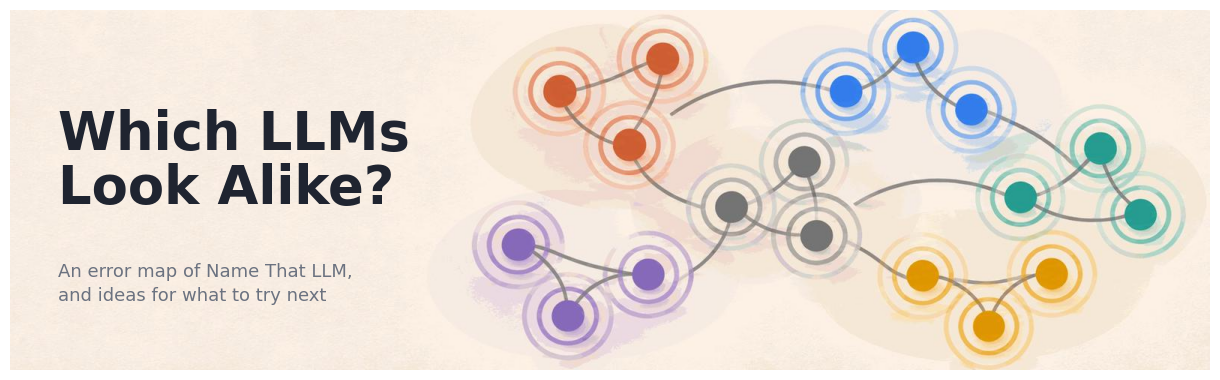

In [2]:
if RUN_ANALYSIS:
    cover_banner()

<table style="width:100%;border-collapse:separate;border-spacing:8px;margin:6px 0 2px 0;"><tr><td style="background:linear-gradient(135deg,#c96442,#9c4e33);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:20%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">34%</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">of 18 classes right (simple proxy model)</div></td><td style="background:linear-gradient(135deg,#4285f4,#3367be);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:20%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">70%</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">of texts get the right family</div></td><td style="background:linear-gradient(135deg,#2a9d8f,#207a6f);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:20%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">46%</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">of its mistakes cross a family boundary</div></td><td style="background:linear-gradient(135deg,#8e6bbf,#6e5394);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:20%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">+10 / -5</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">points from group tricks with 18 / 2 texts per prompt</div></td><td style="background:linear-gradient(135deg,#e0a100,#ae7d00);color:#1f2430;border-radius:12px;padding:16px 12px;text-align:center;width:20%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">65%</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">of texts have the truth in the top 3</div></td></tr></table>

<div style="background:linear-gradient(120deg,#c96442,#90482f);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key findings at a glance</div><ul style='margin:6px 0 0 18px'><li>A simple fingerprint detector gets <b>34%</b> of 18 classes right and the right <b>family 70%</b> of the time.</li><li>Many pairs are near coin flips for the text alone: the two <b>GLM</b> models, the three <b>GPT-5.6</b> models, <b>Gemini 3.7 vs 3.8 Flash</b>.</li><li><b>46%</b> of its mistakes cross a family boundary (GLM into Claude, Kimi and Qwen into GPT); a same-family fix cannot touch them.</li><li>Prompt-group tricks (centering, Hungarian) gain up to <b>+10 points</b> with all 18 texts per prompt, but <b>lose about 5</b> with two, and the gain vanishes when a quarter of a group is wrong.</li><li>The fingerprint keeps growing with text length, and the truth is in the top 3 for <b>65%</b> of texts, but an obvious two-class fix did not help.</li></ul><span style='opacity:.85;font-size:13px'>All numbers come from a simple proxy model on the training set, not from leaderboard results.</span></div>

<div style="background:#1f2430;color:#ffffff;padding:13px 18px;border-radius:8px;margin:12px 0;font-size:15px;line-height:1.55;"><b>How to read the numbers.</b> The error analysis uses a <i>simple proxy model</i> (character and word TF-IDF + a linear SVM, scored with 5 folds that keep every prompt in one fold). It is <b>not</b> the 0.70 pipeline, and its mistakes are not that pipeline's mistakes: the hidden test labels are not public, so nobody outside the organisers can see where the top notebooks go wrong. What the proxy shows is which models are hard to tell apart in the <i>text itself</i>. Section 11 lists ideas for improvement. <b>None of them has been tested here, and none is claimed to give a gain.</b></div>

**How to read this notebook.** Charts and short explanations come first; every code cell is collapsed, so you can scroll through without seeing code. Click **Show hidden code** under any figure to open the code that drew it.

**Contents:** 1 the task, 2 a proxy fingerprint model and its errors, 3 which pairs can be separated, 4 style habits, 5 more data and prompt difficulty, 6 prompt-group tricks, 7 fragile groups, 8 how much text, 9 the top-3 and a naive fix, 10 the public pipeline, 11 ideas, 12 limits, 13 credits.

## 1. The task in one picture
18 models answered the same 150 prompts, so the training set is a near-complete 150 x 18 board (2,699 texts; one cell is missing).
All Markdown, bullets and line breaks were removed, so each answer is a single paragraph. The labels are balanced, which
means "predict the most common class" gets nothing.

In [3]:
if RUN_ANALYSIS:
    print(df.shape, 'prompts:', df.prompt_id.nunique())
    print(df.model.value_counts().describe()[['min', 'max']].to_dict())
    print('Markdown or newlines in any text:', int(df.text.str.contains('\n|\\*\\*|^#', regex=True).sum()))

(2699, 4) prompts: 150
{'min': 149.0, 'max': 150.0}
Markdown or newlines in any text: 0


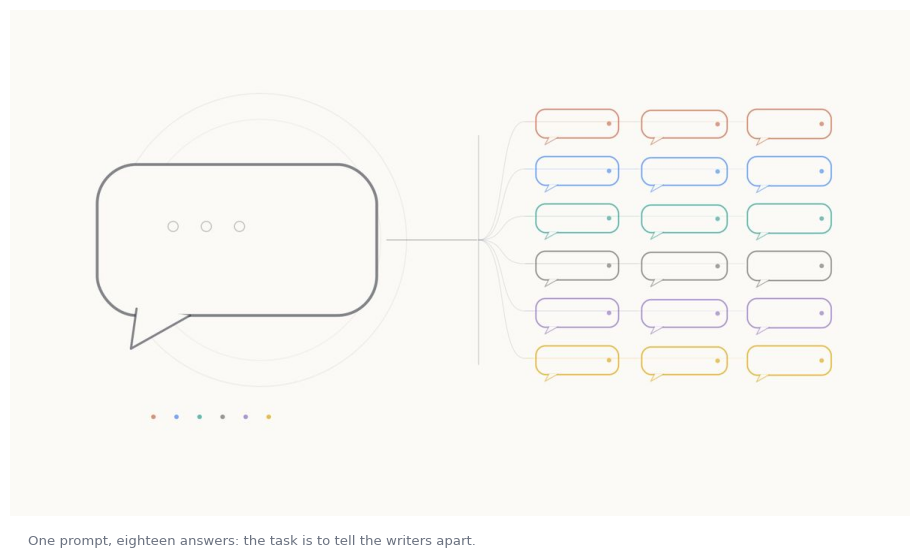

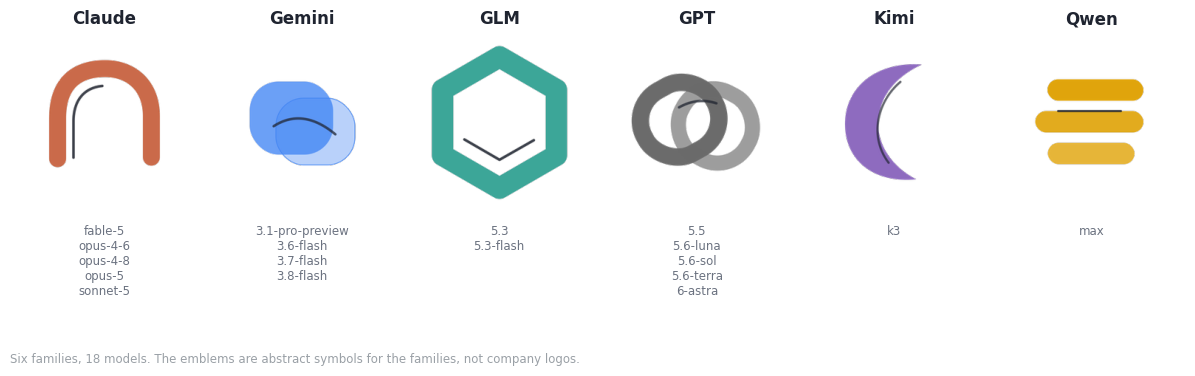

In [4]:
if RUN_ANALYSIS:
    show_image('concept_same_prompt', 'One prompt, eighteen answers: the task is to tell the writers apart.', width=9)
    families_strip(classes)

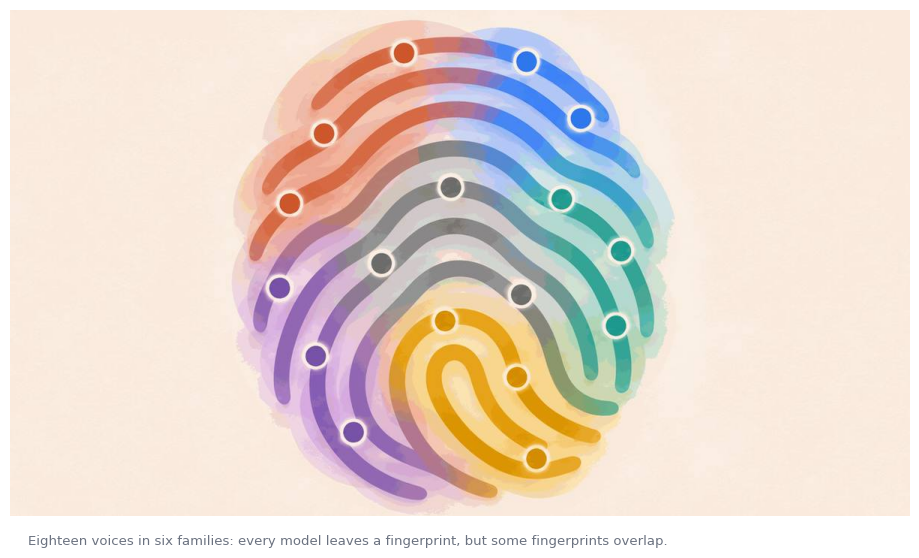

In [5]:
if RUN_ANALYSIS:
    show_image('hero_fingerprint', 'Eighteen voices in six families: every model leaves a fingerprint, but some fingerprints overlap.', width=9)

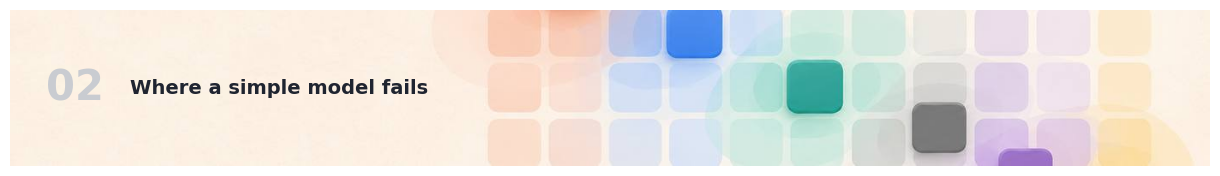

In [6]:
if RUN_ANALYSIS:
    band('band_confusion', '02', 'Where a simple model fails')

## 2. A proxy fingerprint model, and where it fails
Prompt-grouped folds matter: if two answers to the same prompt land on different sides of a split, the model can lean on
the *topic* instead of the *author*. Here every prompt stays in one fold.

<i>Note on overlap:</i> Areeb Ali's public notebook <i>0.702 | Read the Fingerprints</i> opens with a similar ruler (a TF-IDF linear
model on prompt-grouped folds, with a confusion map by lab). We reached the same first step independently, and it is the obvious one.
Where we go further is below: which pairs can be separated (Section 3), how the group tricks behave as the group changes (Sections 6 and 7),
text length (Section 8), and the spread of the public board (Section 10). We recommend his notebook for the typography audit and the
within-lab sibling specialists, which this notebook does not cover.

<div style="border-left:5px solid #8a94a6;background:rgba(138,148,166,0.16);padding:10px 16px;border-radius:6px;margin:10px 0;font-size:15px;line-height:1.5;"><b>In plain words</b> &middot; Think of it as a game of 'who wrote this paragraph?'. A basic detector guesses right about one time in three. It usually knows the family of the writer but not the exact model.</div>

In [7]:
if RUN_ANALYSIS:
    t0 = time.time(); oof = np.zeros((len(df), 18))
    for k, (tr, va) in enumerate(GroupKFold(5).split(df, y, groups)):
        v1 = TfidfVectorizer(analyzer='char', ngram_range=(1, 4), sublinear_tf=True, min_df=3, max_features=300000)
        v2 = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), sublinear_tf=True, min_df=2, lowercase=False,
                             token_pattern=r"(?u)\b\w+\b|[^\w\s]")
        Xtr = hstack([v1.fit_transform(df.text.iloc[tr]), v2.fit_transform(df.text.iloc[tr])]).tocsr()
        Xva = hstack([v1.transform(df.text.iloc[va]), v2.transform(df.text.iloc[va])]).tocsr()
        oof[va] = LinearSVC(C=0.5).fit(Xtr, y[tr]).decision_function(Xva)
    pred = oof.argmax(1)
    F = np.array([fam(c) for c in classes])
    right = pred == y; same_fam = (F[pred] == F[y]) & ~right; other_fam = F[pred] != F[y]
    print(f'accuracy {right.mean():.3f}   family correct {(F[pred] == F[y]).mean():.3f}   '
          f'exact model given right family {right.sum() / (F[pred] == F[y]).sum():.3f}   ({time.time() - t0:.0f}s)')
    print(f'of all errors: {same_fam.sum() / (~right).sum():.0%} are a wrong sibling in the right family, '
          f'{other_fam.sum() / (~right).sum():.0%} are a wrong family')

accuracy 0.343   family correct 0.698   exact model given right family 0.491   (33s)
of all errors: 54% are a wrong sibling in the right family, 46% are a wrong family


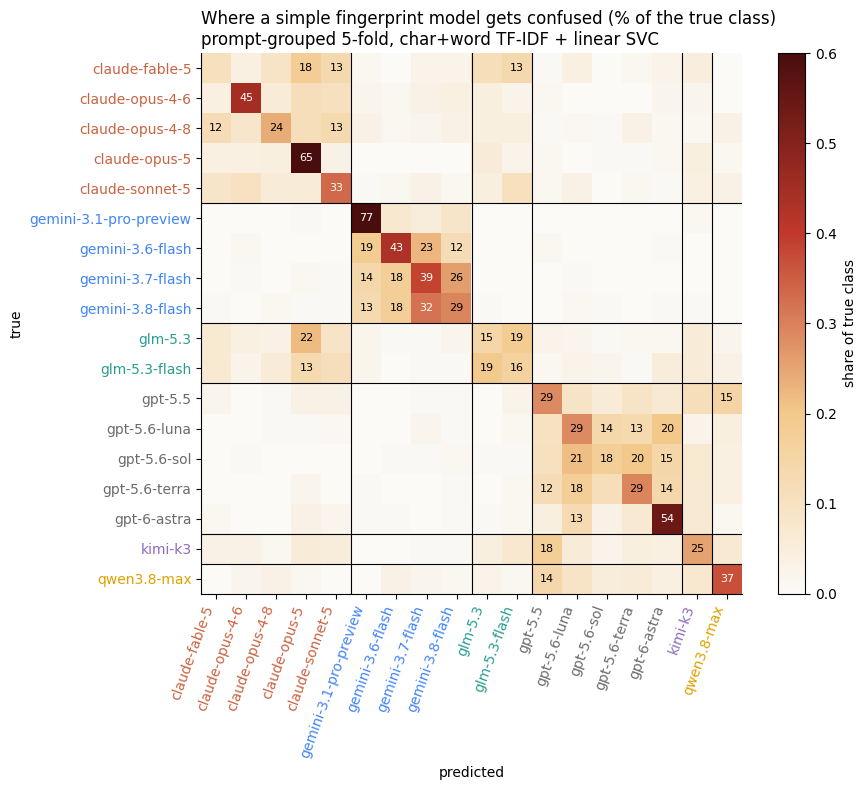

In [8]:
if RUN_ANALYSIS:
    cm = np.zeros((18, 18)); np.add.at(cm, (y, pred), 1); cm = (cm / cm.sum(1, keepdims=True))[np.ix_(o, o)]
    fig, ax = plt.subplots(figsize=(9.5, 8))
    im = ax.imshow(cm, cmap=LinearSegmentedColormap.from_list('c', ['#fbfaf7', '#f3c98b', '#c0392b', '#4a0d0d']), vmin=0, vmax=.6)
    ax.set_xticks(range(18)); ax.set_yticks(range(18)); ax.set_xticklabels(order, rotation=70, ha='right'); ax.set_yticklabels(order)
    colour_ticks(ax, order * 1); family_lines(ax, order)
    for i in range(18):
        for j in range(18):
            if cm[i, j] >= .12: ax.text(j, i, f'{cm[i, j] * 100:.0f}', ha='center', va='center', color='w' if cm[i, j] > .3 else 'k', fontsize=8)
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title('Where a simple fingerprint model gets confused (% of the true class)\nprompt-grouped 5-fold, char+word TF-IDF + linear SVC', loc='left')
    plt.colorbar(im, fraction=.04, label='share of true class'); plt.tight_layout(); plt.show()

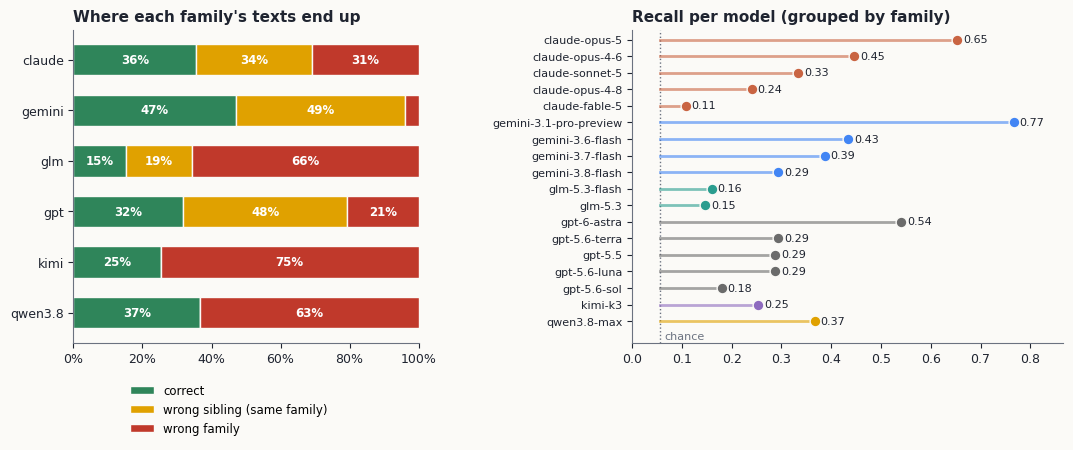

In [9]:
if RUN_ANALYSIS:
    fig = error_anatomy(classes, oof, y); plt.show()

**What the map shows (proxy model).** Gemini texts are almost always recognised as Gemini, and `gemini-3.1-pro-preview` is the easiest
single class. The big diagonal blocks are *families*: the three Gemini Flash versions, the three GPT-5.6 versions, and the two GLM
versions are mixed up with each other. A second source of error sits *between* families (GLM and Claude, Kimi and Qwen into GPT).

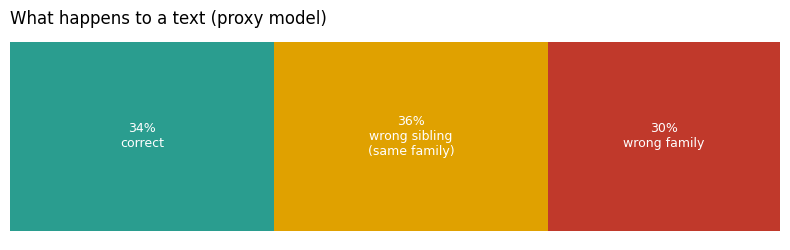

                  error source  errors  share of all proxy errors
Gemini Flash (3.6 / 3.7 / 3.8)     193                      0.109
  GPT-5.6 (luna / sol / terra)     147                      0.083
         GLM (5.3 / 5.3-flash)      57                      0.032
             Claude (5 models)     251                      0.142
              Between families     814                      0.459


In [10]:
if RUN_ANALYSIS:
    fig, ax = plt.subplots(figsize=(8, 2.6)); left = 0
    for v, c, l in zip([right.mean(), same_fam.mean(), other_fam.mean()], ['#2a9d8f', '#e0a100', '#c0392b'],
                       ['correct', 'wrong sibling\n(same family)', 'wrong family']):
        ax.barh(0, v, left=left, color=c); ax.text(left + v / 2, 0, f'{v * 100:.0f}%\n{l}', ha='center', va='center', color='w', fontsize=9); left += v
    ax.set_xlim(0, 1); ax.axis('off'); ax.set_title('What happens to a text (proxy model)', loc='left'); plt.tight_layout(); plt.show()

    blocks = {'Gemini Flash (3.6 / 3.7 / 3.8)': ['gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash'],
              'GPT-5.6 (luna / sol / terra)': ['gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra'],
              'GLM (5.3 / 5.3-flash)': ['glm-5.3', 'glm-5.3-flash'],
              'Claude (5 models)': [c for c in classes if fam(c) == 'claude']}
    wrong = ~right; rows = []
    for name, members in blocks.items():
        ids = [idx[m] for m in members]
        inside = wrong & np.isin(y, ids) & np.isin(pred, ids)
        rows.append((name, int(inside.sum()), inside.sum() / wrong.sum()))
    cross = wrong & (F[pred] != F[y])
    rows.append(('Between families', int(cross.sum()), cross.sum() / wrong.sum()))
    print(pd.DataFrame(rows, columns=['error source', 'errors', 'share of all proxy errors']).round(3).to_string(index=False))

The table is a **headroom measure for the proxy**, not a forecast: if a block were resolved perfectly, the proxy would win back at most that
share of its mistakes. It says where the mistakes are, not how hard they are to fix.

<div style="background:linear-gradient(120deg,#c96442,#90482f);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key takeaway</div>A simple fingerprint model gets 34% of 18 classes right and the right family 70% of the time. More than half of its mistakes are siblings of the same family; the rest cross a family boundary. Gemini is the most recognisable family, and the GLM and Claude families bleed into each other.</div>

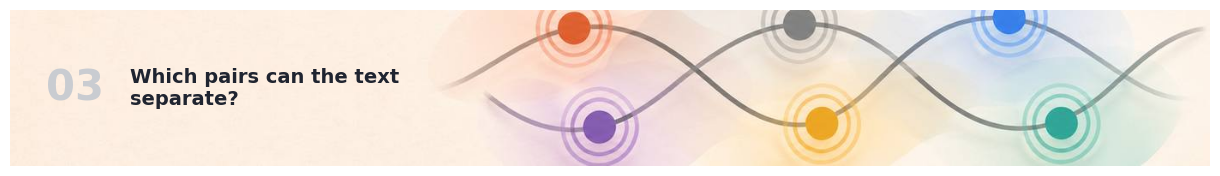

In [11]:
if RUN_ANALYSIS:
    band('band_pairs', '03', 'Which pairs can the text separate?')

## 3. Which pairs can the text itself separate?
For every pair of models we train a two-class classifier (same prompt-grouped folds) and report the AUC of its scores. 0.5 is a coin flip, 1.0 is perfect.

<div style="border-left:5px solid #8a94a6;background:rgba(138,148,166,0.16);padding:10px 16px;border-radius:6px;margin:10px 0;font-size:15px;line-height:1.5;"><b>In plain words</b> &middot; Some models write so alike that the text alone cannot tell them apart. The map below shows which ones, and how close to a coin flip each pair is.</div>

In [12]:
if RUN_ANALYSIS:
    pairs = sorted([(classes[i], classes[j], auc[i, j]) for i in range(18) for j in range(i + 1, 18)], key=lambda x: x[2])
    print(pd.DataFrame(pairs[:10], columns=['model A', 'model B', 'AUC']).round(3).to_string(index=False))
    same = [p[2] for p in pairs if fam(p[0]) == fam(p[1])]; cross_ = [p[2] for p in pairs if fam(p[0]) != fam(p[1])]
    print(f'mean AUC inside a family {np.mean(same):.3f}, between families {np.mean(cross_):.3f}')

         model A          model B   AUC
         glm-5.3    glm-5.3-flash 0.523
     gpt-5.6-sol    gpt-5.6-terra 0.566
  claude-fable-5          glm-5.3 0.572
    gpt-5.6-luna      gpt-5.6-sol 0.579
gemini-3.7-flash gemini-3.8-flash 0.579
  claude-fable-5    glm-5.3-flash 0.591
    gpt-5.6-luna    gpt-5.6-terra 0.614
gemini-3.6-flash gemini-3.7-flash 0.668
         gpt-5.5          kimi-k3 0.691
         gpt-5.5    gpt-5.6-terra 0.723
mean AUC inside a family 0.760, between families 0.941


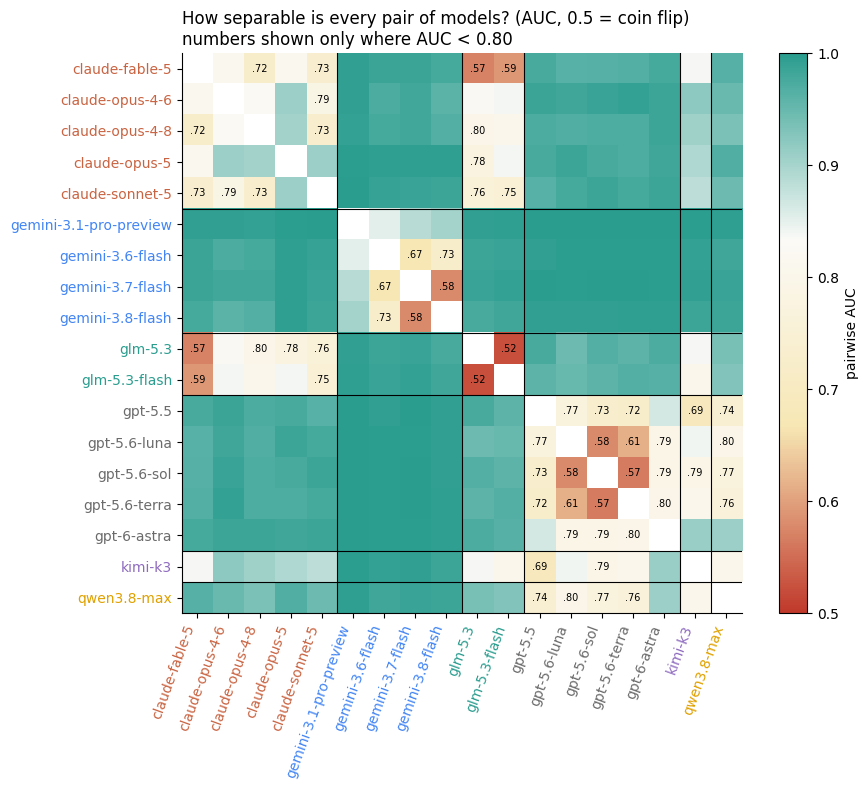

In [13]:
if RUN_ANALYSIS:
    a = auc[np.ix_(o, o)]
    fig, ax = plt.subplots(figsize=(9.5, 8))
    im = ax.imshow(a, cmap=LinearSegmentedColormap.from_list('c', ['#c0392b', '#f7e7b4', '#fbfaf7', '#2a9d8f']), vmin=.5, vmax=1)
    ax.set_xticks(range(18)); ax.set_yticks(range(18)); ax.set_xticklabels(order, rotation=70, ha='right'); ax.set_yticklabels(order)
    colour_ticks(ax, order * 1); family_lines(ax, order)
    for i in range(18):
        for j in range(18):
            if i != j and a[i, j] < .8: ax.text(j, i, f'{a[i, j]:.2f}'[1:], ha='center', va='center', fontsize=7)
    ax.set_title('How separable is every pair of models? (AUC, 0.5 = coin flip)\nnumbers shown only where AUC < 0.80', loc='left')
    plt.colorbar(im, fraction=.04, label='pairwise AUC'); plt.tight_layout(); plt.show()

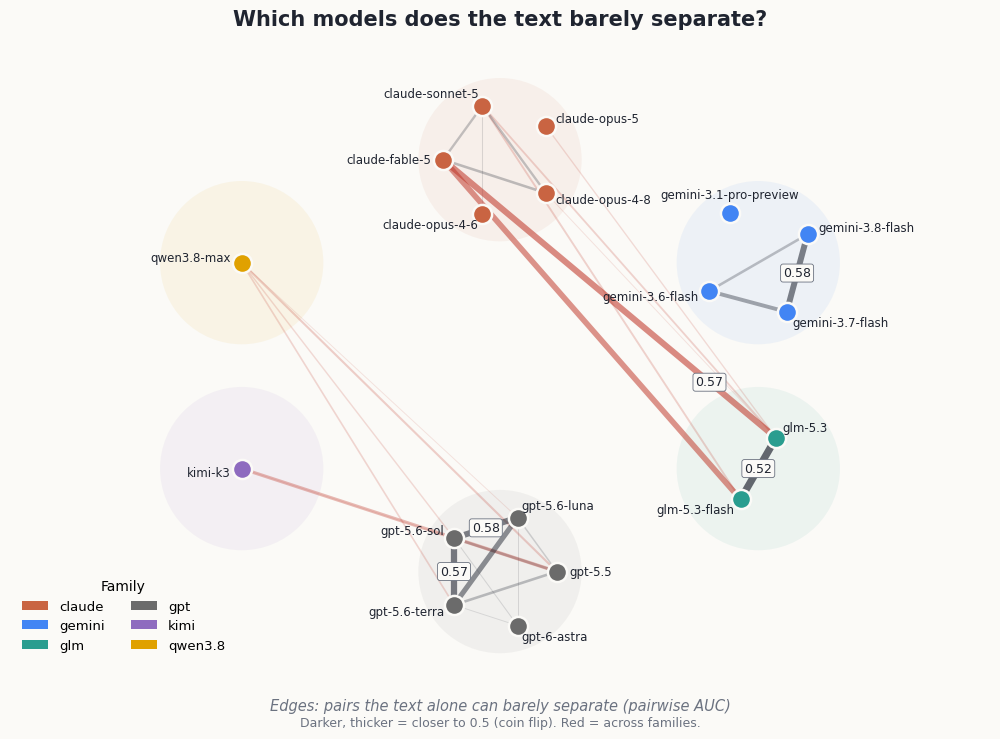

In [14]:
if RUN_ANALYSIS:
    fig = lookalike_network(auc, classes); plt.show()

Surface text almost cannot separate `glm-5.3` from `glm-5.3-flash`, the three GPT-5.6 models from each other, or `gemini-3.7-flash` from `gemini-3.8-flash`.
`claude-fable-5` is also close to both GLM models. Between most other pairs the classifier is close to perfect.

<div style="background:linear-gradient(120deg,#4285f4,#2f5faf);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key takeaway</div>Some pairs are almost coin flips for the text alone (the two GLM models, the three GPT-5.6 models, Gemini 3.7 against 3.8 Flash). Everything outside the families separates well. Evidence for these pairs has to come from somewhere other than punctuation and wording.</div>

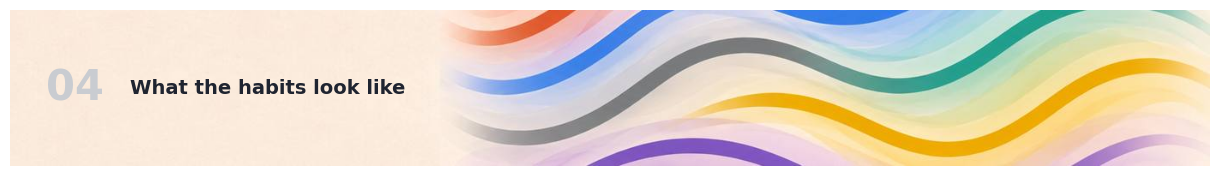

In [15]:
if RUN_ANALYSIS:
    band('band_fingerprint', '04', 'What the habits look like')

## 4. What the habits look like
Each text is compared with the average of all 18 answers to the *same* prompt, so the topic cancels out and only the writer's habit is left.
The colours are model means in units of the spread of a single text (so a value of 1 is a clear but not huge habit).

<div style="border-left:5px solid #8a94a6;background:rgba(138,148,166,0.16);padding:10px 16px;border-radius:6px;margin:10px 0;font-size:15px;line-height:1.5;"><b>In plain words</b> &middot; Models have small habits, like how long their words are or whether they use em dashes. These habits are part of why some families are easy to spot.</div>

share of within-prompt variance explained by model identity (eta^2):
avg_word           0.437
emdash             0.403
straight_quotes    0.275
comma              0.231
curly_quotes       0.221
colon              0.210
nonascii           0.179
semicolon          0.139
sent_len           0.071
hyphen             0.068
chars              0.012


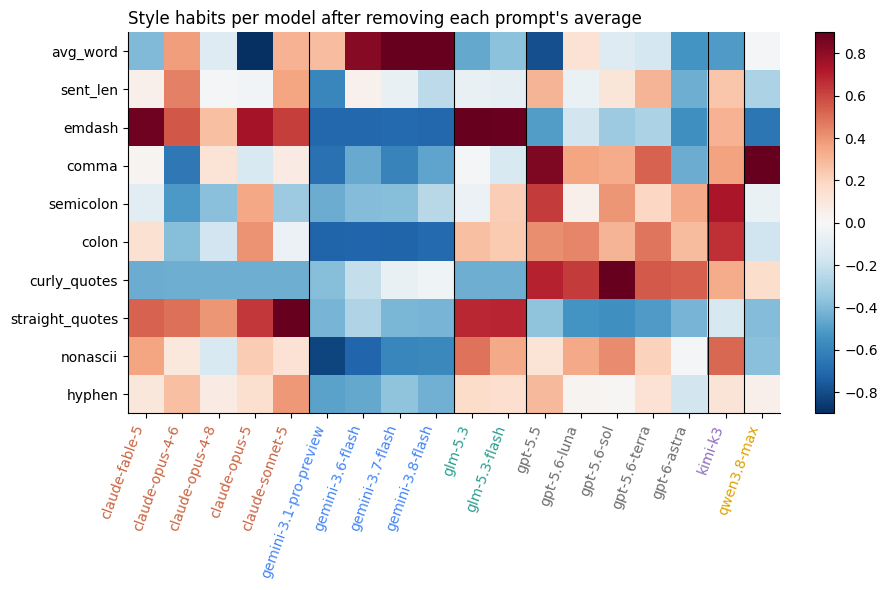

In [16]:
if RUN_ANALYSIS:
    def feats(t):
        w = re.findall(r"\w+", t); s = [x for x in re.split(r"(?<=[.!?])\s+", t) if x]; L = max(len(t), 1)
        return dict(avg_word=np.mean([len(x) for x in w]) if w else 0, sent_len=len(w) / max(len(s), 1),
                    emdash=t.count('\u2014') / L * 1e3, comma=t.count(',') / L * 1e3, semicolon=t.count(';') / L * 1e3,
                    colon=t.count(':') / L * 1e3, curly_quotes=(t.count('\u2019') + t.count('\u201c') + t.count('\u201d')) / L * 1e3,
                    straight_quotes=(t.count("'") + t.count('"')) / L * 1e3, nonascii=sum(ord(c) > 127 for c in t) / L * 1e3,
                    hyphen=t.count('-') / L * 1e3, chars=len(t))
    S = pd.DataFrame([feats(t) for t in df.text]); cols = list(S.columns)
    Sc = S - S.groupby(df.prompt_id.values).transform('mean')
    eta = {c: (Sc.groupby(df.model.values)[c].mean() ** 2 * Sc.groupby(df.model.values)[c].size()).sum() / (Sc[c] ** 2).sum() for c in cols}
    print('share of within-prompt variance explained by model identity (eta^2):')
    print(pd.Series(eta).sort_values(ascending=False).round(3).to_string())
    M = Sc.groupby(df.model.values)[cols].mean().loc[order]; Z = (M - M.mean()) / Sc.std()
    show = [c for c in cols if c != 'chars']
    fig, ax = plt.subplots(figsize=(9, 6))
    im = ax.imshow(Z[show].values.T, cmap='RdBu_r', vmin=-.9, vmax=.9, aspect='auto')
    ax.set_xticks(range(18)); ax.set_xticklabels(order, rotation=70, ha='right'); ax.set_yticks(range(len(show))); ax.set_yticklabels(show)
    colour_ticks(ax, order, axes=('x',)); family_lines(ax, order, axes=('x',))
    ax.set_title("Style habits per model after removing each prompt's average", loc='left'); plt.colorbar(im, fraction=.03); plt.tight_layout(); plt.show()

Gemini writes longer words and uses few em dashes and few non-ASCII characters; GPT is the family that uses curly quotes; Claude and GLM both lean on
em dashes and straight quotes, which is one reason they get mixed up. Text length carries almost no information once the prompt is accounted for.

## 5. Does more of the same data help?
Train on 15 to 120 prompts (18 texts each) and score on 30 prompts that were never seen. Three random splits; a small experiment, so it is an indication only.

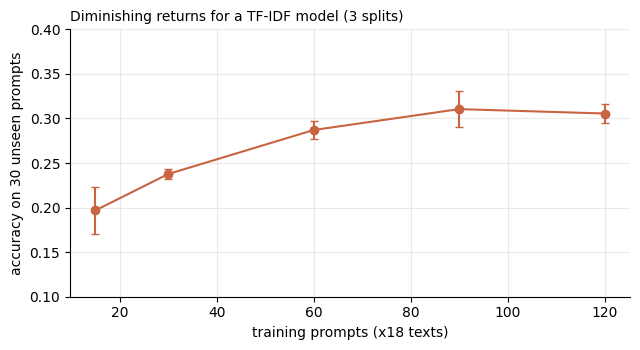

            mean    std
n_prompts              
15         0.197  0.026
30         0.238  0.006
60         0.287  0.010
90         0.310  0.020
120        0.306  0.010


In [17]:
if RUN_ANALYSIS:
    rng = np.random.RandomState(0); P = np.unique(groups); rows = []
    for rep in range(3):
        perm = rng.permutation(P); te = np.where(np.isin(groups, perm[:30]))[0]
        for n in (15, 30, 60, 90, 120):
            tr = np.where(np.isin(groups, perm[30:30 + n]))[0]
            v1 = TfidfVectorizer(analyzer='char', ngram_range=(1, 4), sublinear_tf=True, min_df=3, max_features=300000)
            m = LinearSVC(C=.5).fit(v1.fit_transform(df.text.iloc[tr]), y[tr])
            rows.append((rep, n, (m.predict(v1.transform(df.text.iloc[te])) == y[te]).mean()))
    lc = pd.DataFrame(rows, columns=['rep', 'n_prompts', 'acc']); g = lc.groupby('n_prompts').acc.agg(['mean', 'std'])
    fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.errorbar(g.index, g['mean'], yerr=g['std'], marker='o', color='#c96442', capsize=3)
    ax.set_xlabel('training prompts (x18 texts)'); ax.set_ylabel('accuracy on 30 unseen prompts'); ax.set_ylim(.1, .4); ax.grid(alpha=.25)
    ax.set_title('Diminishing returns for a TF-IDF model (3 splits)', loc='left', fontsize=10); plt.tight_layout(); plt.show()
    print(g.round(3).to_string())

The simple model flattens out at roughly 30% accuracy after 90 prompts. This is why public notebooks look for *different kinds of evidence*
(language-model likelihoods, embeddings, LoRA readouts) rather than only more text of the same sort.

<div style="background:linear-gradient(120deg,#8e6bbf,#664d89);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key takeaway</div>The simple model stops improving after about 90 training prompts, and no single style habit stands out. Gains in the public lineage came from adding a different kind of evidence, not from more of the same.</div>

### Are some prompts harder than others?
If some prompts were systematically harder (a topic with little room for style), one could weight them. We compare the spread of per-prompt accuracy with what chance alone would give for 18 texts per prompt.

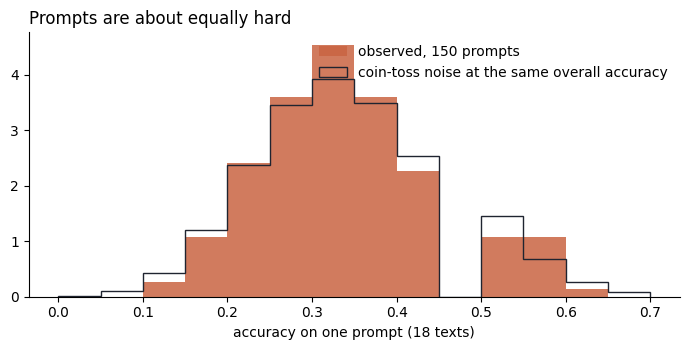

sd of per-prompt accuracy 0.103; sd expected from noise alone 0.112


In [18]:
if RUN_ANALYSIS:
    pa = pd.Series(right).groupby(groups).mean()
    sim = np.random.RandomState(0).binomial(18, right.mean(), size=(5000, 150)).ravel() / 18
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.hist(pa, bins=np.linspace(0, .7, 15), density=True, alpha=.85, color='#c96442', label='observed, 150 prompts')
    ax.hist(sim, bins=np.linspace(0, .7, 15), density=True, histtype='step', color='#1f2430', lw=1.6, label='coin-toss noise at the same overall accuracy')
    ax.set_xlabel('accuracy on one prompt (18 texts)'); ax.legend(frameon=False); ax.set_title('Prompts are about equally hard', loc='left')
    plt.tight_layout(); plt.show()
    print(f'sd of per-prompt accuracy {pa.std():.3f}; sd expected from noise alone {sim.std():.3f}')

The observed spread is no larger than coin-toss noise would give, so there is no evidence that some prompts are systematically harder. Weighting or filtering prompts by difficulty is unlikely to be worth the trouble with this proxy.

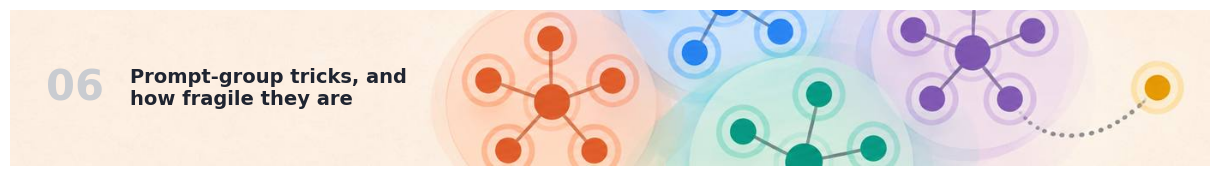

In [19]:
if RUN_ANALYSIS:
    band('band_groups', '06', 'Prompt-group tricks, and how fragile they are')

## 6. When do "prompt-group tricks" pay off?
Many public notebooks use the fact that each prompt was answered by all 18 models: **centering** (subtract the group's average score) and **Hungarian assignment** (each model can be used only once inside a group).
Offline these look strong; on the public board several authors report that they *lost* 0.009 to 0.017. Here we measure the proxy model when only **k texts per prompt** are available (correct groups, fixed temperature, nothing tuned).

<div style="border-left:5px solid #8a94a6;background:rgba(138,148,166,0.16);padding:10px 16px;border-radius:6px;margin:10px 0;font-size:15px;line-height:1.5;"><b>In plain words</b> &middot; All eighteen models answered the same questions, so a smart system can compare the answers to one question with each other. That only helps if many answers per question are present and grouped correctly.</div>

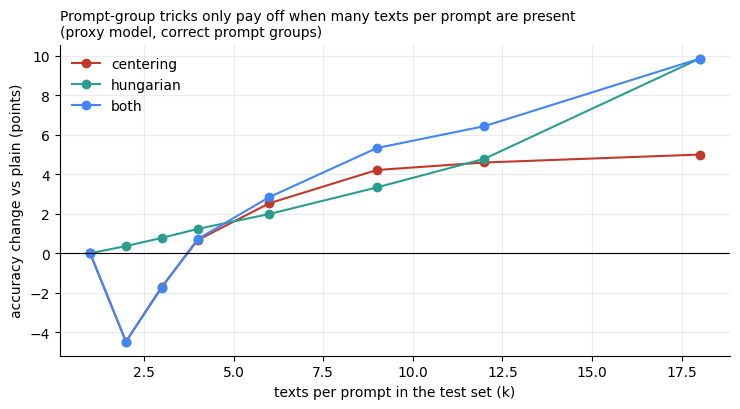

 k  plain  centering  hungarian  both
 1  0.360      0.360      0.360 0.360
 2  0.345      0.300      0.348 0.300
 3  0.332      0.315      0.340 0.315
 4  0.338      0.344      0.350 0.345
 6  0.344      0.369      0.364 0.373
 9  0.340      0.383      0.374 0.394
12  0.342      0.388      0.390 0.406
18  0.343      0.393      0.442 0.442


In [20]:
if RUN_ANALYSIS:
    from scipy.optimize import linear_sum_assignment
    from scipy.special import log_softmax
    def hungarian(S):
        L = log_softmax(S * 3.0, axis=1); r, c = linear_sum_assignment(-L)   # temperature fixed at 3, not tuned
        p = S.argmax(1).copy(); p[r] = c; return p
    def centred(S): return (S - S.mean(0, keepdims=True)).argmax(1) if len(S) > 1 else S.argmax(1)
    rng = np.random.RandomState(0); rows = []
    for k in (1, 2, 3, 4, 6, 9, 12, 18):
        r = {'plain': [], 'centering': [], 'hungarian': [], 'both': []}
        for rep in range(10):
            for p in np.unique(groups):
                pool = np.where(groups == p)[0]; ii = rng.choice(pool, size=min(k, len(pool)), replace=False); S = oof[ii]; yy = y[ii]
                r['plain'].append((S.argmax(1) == yy).mean()); r['centering'].append((centred(S) == yy).mean())
                r['hungarian'].append((hungarian(S) == yy).mean()); r['both'].append((hungarian(S - S.mean(0, keepdims=True) if len(S) > 1 else S) == yy).mean())
        rows.append({'k': k, **{a: np.mean(b) for a, b in r.items()}})
    A = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for c, col in (('centering', '#c0392b'), ('hungarian', '#2a9d8f'), ('both', '#4285f4')):
        ax.plot(A.k, (A[c] - A.plain) * 100, marker='o', color=col, label=c)
    ax.axhline(0, color='k', lw=.8); ax.set_xlabel('texts per prompt in the test set (k)'); ax.set_ylabel('accuracy change vs plain (points)')
    ax.set_title('Prompt-group tricks only pay off when many texts per prompt are present\n(proxy model, correct prompt groups)', loc='left', fontsize=10)
    ax.legend(frameon=False); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
    print(A.round(3).to_string(index=False))

**Reading.** With the right groups, centering *loses* about 4 to 6 points at k=2 (depending on the random draw) and only breaks even around k=4: with two texts the centred scores are exact opposites, so the method is forced to split the pair.
Hungarian never loses here, but it only becomes large (about +10 points) when nearly all 18 texts of a prompt are present. If the hidden test has few texts per prompt, these tricks have little to gain even in the best case.

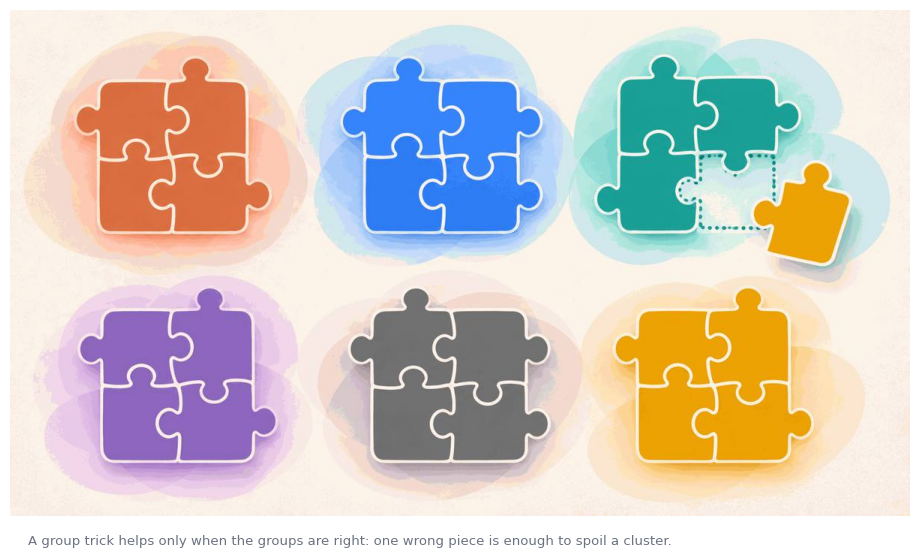

In [21]:
if RUN_ANALYSIS:
    show_image('hero_puzzle', 'A group trick helps only when the groups are right: one wrong piece is enough to spoil a cluster.', width=9)

## 7. How fragile is the gain if the groups are wrong?
In the real test the prompt of each text is not given, so a notebook has to *rebuild* the groups from the text. Two measurements: (a) cluster the pooled texts with k-means and run the same tricks on the clusters; (b) take correct groups and replace a fraction of each group with texts from other prompts ("intruders").

<div style="border-left:5px solid #8a94a6;background:rgba(138,148,166,0.16);padding:10px 16px;border-radius:6px;margin:10px 0;font-size:15px;line-height:1.5;"><b>In plain words</b> &middot; In the real test the question is not given, so the groups must be rebuilt from the text. Here we ask how much a few wrong group members can hurt.</div>

 k  purity  plain  hung_true_groups  hung_recovered_groups  centre_true  centre_recovered
 2   0.950  0.350             0.357                  0.357        0.273             0.263
 3   0.913  0.336             0.362                  0.362        0.329             0.322
 4   0.937  0.362             0.370                  0.373        0.378             0.365
 6   0.913  0.311             0.336                  0.330        0.370             0.343
 9   0.890  0.352             0.382                  0.369        0.379             0.378
18   0.917  0.343             0.442                  0.421        0.393             0.389


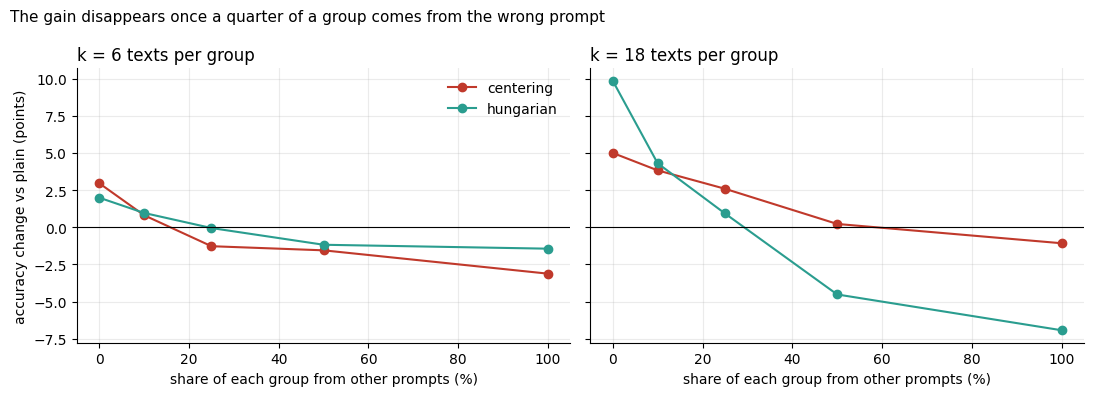

 k  intruders  plain  centering  hungarian
 6       0.00  0.339      0.368      0.359
 6       0.10  0.341      0.349      0.351
 6       0.25  0.344      0.331      0.344
 6       0.50  0.340      0.325      0.328
 6       1.00  0.343      0.312      0.329
18       0.00  0.343      0.393      0.442
18       0.10  0.342      0.380      0.385
18       0.25  0.345      0.371      0.354
18       0.50  0.346      0.348      0.301
18       1.00  0.352      0.341      0.282


In [22]:
if RUN_ANALYSIS:
    rng = np.random.RandomState(1); rows = []
    for k in (2, 3, 4, 6, 9, 18):
        ii = np.concatenate([rng.choice(np.where(groups == p)[0], size=min(k, (groups == p).sum()), replace=False) for p in np.unique(groups)])
        X = TfidfVectorizer(stop_words='english', sublinear_tf=True, min_df=2, max_df=.3).fit_transform(df.text.iloc[ii])
        lab = KMeans(150, n_init=1, random_state=0).fit_predict(X)
        purity = pd.crosstab(lab, groups[ii]).max(1).sum() / len(ii)
        def score(gr):
            pc = np.empty(len(ii), int); ph = np.empty(len(ii), int)
            for q in np.unique(gr):
                m = np.where(gr == q)[0]; S = oof[ii][m]; pc[m] = centred(S); ph[m] = hungarian(S) if len(m) <= 18 else S.argmax(1)
            return (pc == y[ii]).mean(), (ph == y[ii]).mean()
        oc, oh = score(groups[ii]); rc, rh = score(lab); pl = (oof[ii].argmax(1) == y[ii]).mean()
        rows.append(dict(k=k, purity=purity, plain=pl, hung_true_groups=oh, hung_recovered_groups=rh, centre_true=oc, centre_recovered=rc))
    R = pd.DataFrame(rows); print(R.round(3).to_string(index=False))
    rows = []
    for k in (6, 18):
        for f in (0, .1, .25, .5, 1.0):
            pl, hu, ce = [], [], []
            for rep in range(8):
                for p in np.unique(groups):
                    pool = np.where(groups == p)[0]; ii = rng.choice(pool, size=min(k, len(pool)), replace=False); nb = int(round(f * len(ii)))
                    if nb: ii[:nb] = rng.choice(np.where(groups != p)[0], size=nb, replace=False)
                    S = oof[ii]; yy = y[ii]; pl.append((S.argmax(1) == yy).mean()); hu.append((hungarian(S) == yy).mean()); ce.append((centred(S) == yy).mean())
            rows.append(dict(k=k, intruders=f, plain=np.mean(pl), centering=np.mean(ce), hungarian=np.mean(hu)))
    I = pd.DataFrame(rows)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, k in zip(axs, (6, 18)):
        d = I[I.k == k]
        for c, col in (('centering', '#c0392b'), ('hungarian', '#2a9d8f')):
            ax.plot(d.intruders * 100, (d[c] - d.plain) * 100, marker='o', color=col, label=c)
        ax.axhline(0, color='k', lw=.8); ax.set_title(f'k = {k} texts per group', loc='left'); ax.set_xlabel('share of each group from other prompts (%)'); ax.grid(alpha=.25)
    axs[0].set_ylabel('accuracy change vs plain (points)'); axs[0].legend(frameon=False)
    fig.suptitle('The gain disappears once a quarter of a group comes from the wrong prompt', x=.01, ha='left', fontsize=11); plt.tight_layout(); plt.show()
    print(I.round(3).to_string(index=False))

**Reading.** K-means on plain TF-IDF recovers prompt groups well when the whole pool is present (purity around 0.89 to 0.95 here), and the tricks keep most of their value. But the gain is **fragile**: at k=18 the Hungarian gain falls from about +10 points to about +4 with 10% intruders,
is near zero at 25%, and turns negative beyond that; centering turns negative at about 25% intruders for k=6. So a group-based trick is a bet on the quality of the groups.
One thing the simulation does *not* explain: with the right or the recovered groups, Hungarian never loses here, yet authors report losses on the board. Something in the hidden test must differ from this setup
(for example repeated models inside a group, or far worse groups); we cannot tell which.

<div style="background:linear-gradient(120deg,#e0a100,#a17300);color:#1f2430;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key takeaway</div>Prompt-group tricks are a bet. They need many texts per prompt and clean groups; with two or three texts, centering hurts, and a quarter of wrong members wipes out the gain.</div>

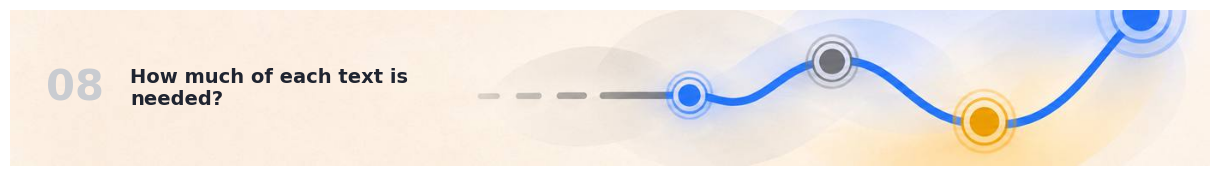

In [23]:
if RUN_ANALYSIS:
    band('band_length', '08', 'How much of each text is needed?')

## 8. How much of each text does the fingerprint need?

<div style="border-left:5px solid #8a94a6;background:rgba(138,148,166,0.16);padding:10px 16px;border-radius:6px;margin:10px 0;font-size:15px;line-height:1.5;"><b>In plain words</b> &middot; Does the detector need the whole paragraph, or are the first sentences enough? We cut each text short and see what is lost.</div>

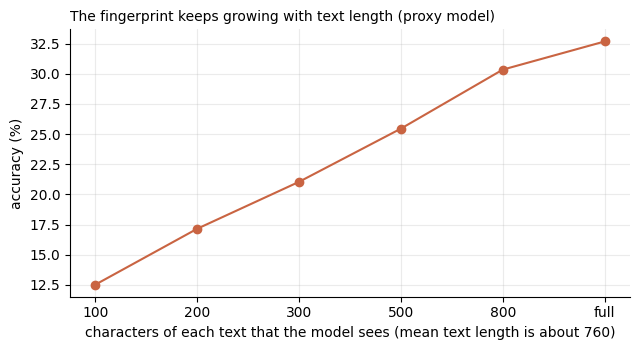

chars   acc
  100 0.125
  200 0.172
  300 0.210
  500 0.255
  800 0.303
 full 0.327


In [24]:
if RUN_ANALYSIS:
    rows = []
    for n in (100, 200, 300, 500, 800, 10 ** 6):
        t = df.text.str.slice(0, n); acc = []
        for tr, va in GroupKFold(5).split(df, y, groups):
            v = TfidfVectorizer(analyzer='char', ngram_range=(1, 4), sublinear_tf=True, min_df=3, max_features=200000)
            acc.append((LinearSVC(C=.5).fit(v.fit_transform(t.iloc[tr]), y[tr]).predict(v.transform(t.iloc[va])) == y[va]).mean())
        rows.append(('full' if n > 10 ** 5 else str(n), np.mean(acc)))
    T = pd.DataFrame(rows, columns=['chars', 'acc'])
    fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.plot(range(len(T)), T.acc * 100, marker='o', color='#c96442'); ax.set_xticks(range(len(T))); ax.set_xticklabels(T.chars)
    ax.set_xlabel('characters of each text that the model sees (mean text length is about 760)'); ax.set_ylabel('accuracy (%)'); ax.grid(alpha=.25)
    ax.set_title('The fingerprint keeps growing with text length (proxy model)', loc='left', fontsize=10); plt.tight_layout(); plt.show(); print(T.round(3).to_string(index=False))

Accuracy rises with every extra stretch of text and has not flattened at 800 characters (the average text is about 760 characters, so "full" is essentially the whole text for most rows). Any stage that reads only the first part of a text, or only a fraction of the test texts, gives up signal.
How much that costs in a GPU-time budget depends on the stage and is not measured here.

<div style="background:linear-gradient(120deg,#2a9d8f,#1e7166);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key takeaway</div>The fingerprint keeps growing with text length, so every stage that reads only part of a text, or only some of the texts, leaves signal on the table.</div>

## 9. The truth is in the top 3, but a naive specialist does not find it

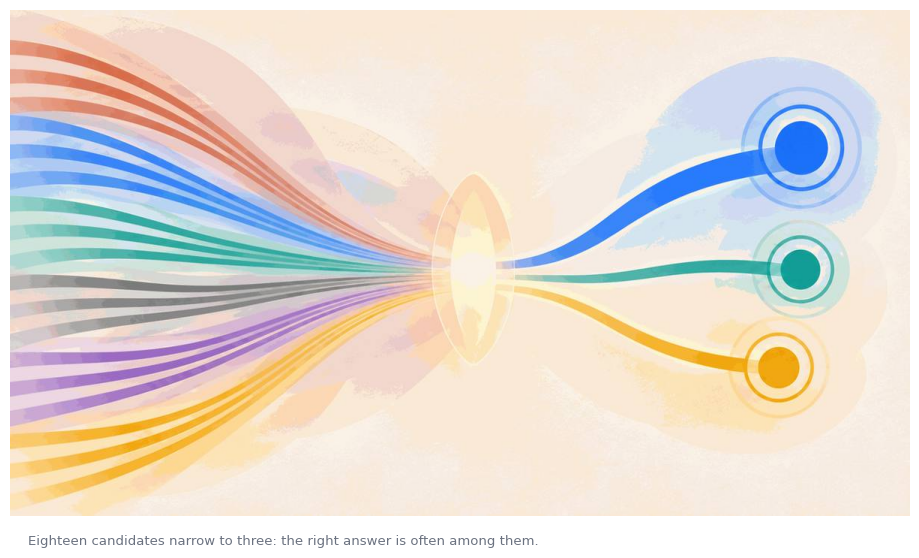

In [25]:
if RUN_ANALYSIS:
    show_image('hero_funnel', 'Eighteen candidates narrow to three: the right answer is often among them.', width=9)

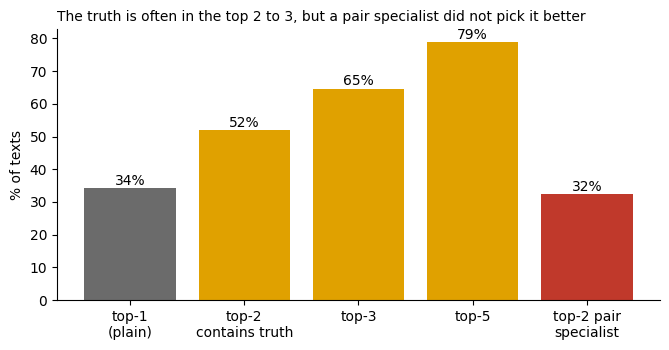

In [26]:
if RUN_ANALYSIS:
    order_s = np.argsort(-oof, 1)
    topk = {k: (order_s[:, :k] == y[:, None]).any(1).mean() for k in (1, 2, 3, 5)}
    new = pred.copy()
    for tr, va in GroupKFold(5).split(df, y, groups):
        v = TfidfVectorizer(analyzer='char', ngram_range=(1, 4), sublinear_tf=True, min_df=3, max_features=200000)
        Xtr = v.fit_transform(df.text.iloc[tr]); Xva = v.transform(df.text.iloc[va]); pm = {}
        for a, b in itertools.combinations(range(18), 2):
            mt = np.isin(y[tr], [a, b]); pm[(a, b)] = LinearSVC(C=.5).fit(Xtr[mt], y[tr][mt] == b)
        for loc, i in enumerate(va):
            a, b = sorted(order_s[i, :2]); new[i] = b if pm[(a, b)].decision_function(Xva[loc])[0] > 0 else a
    vals = [topk[1], topk[2], topk[3], topk[5], (new == y).mean()]
    fig, ax = plt.subplots(figsize=(6.8, 3.6)); ax.bar(range(5), np.array(vals) * 100, color=['#6b6b6b', '#e0a100', '#e0a100', '#e0a100', '#c0392b'])
    ax.set_xticks(range(5)); ax.set_xticklabels(['top-1\n(plain)', 'top-2\ncontains truth', 'top-3', 'top-5', 'top-2 pair\nspecialist'])
    for i, x in enumerate(vals): ax.text(i, x * 100 + 1, f'{x * 100:.0f}%', ha='center')
    ax.set_ylabel('% of texts'); ax.set_title('The truth is often in the top 2 to 3, but a pair specialist did not pick it better', loc='left', fontsize=10); plt.tight_layout(); plt.show()

The correct model is in the proxy's top 2 for about half of the texts and in the top 3 for about two thirds, so there is room. The most direct idea, a dedicated two-class classifier for the two leading candidates, did **not** help
(about 32% against 34% for plain top-1). This is a negative result for one specific recipe, not a verdict on every re-ranker; it is written down so nobody has to repeat it blindly.

<div style="background:linear-gradient(120deg,#c0392b,#8a291e);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">Key takeaway</div>The correct model is in the top 3 for about two thirds of the texts, but the obvious two-class fix does not find it. Room exists, but it is not cheap to capture.</div>

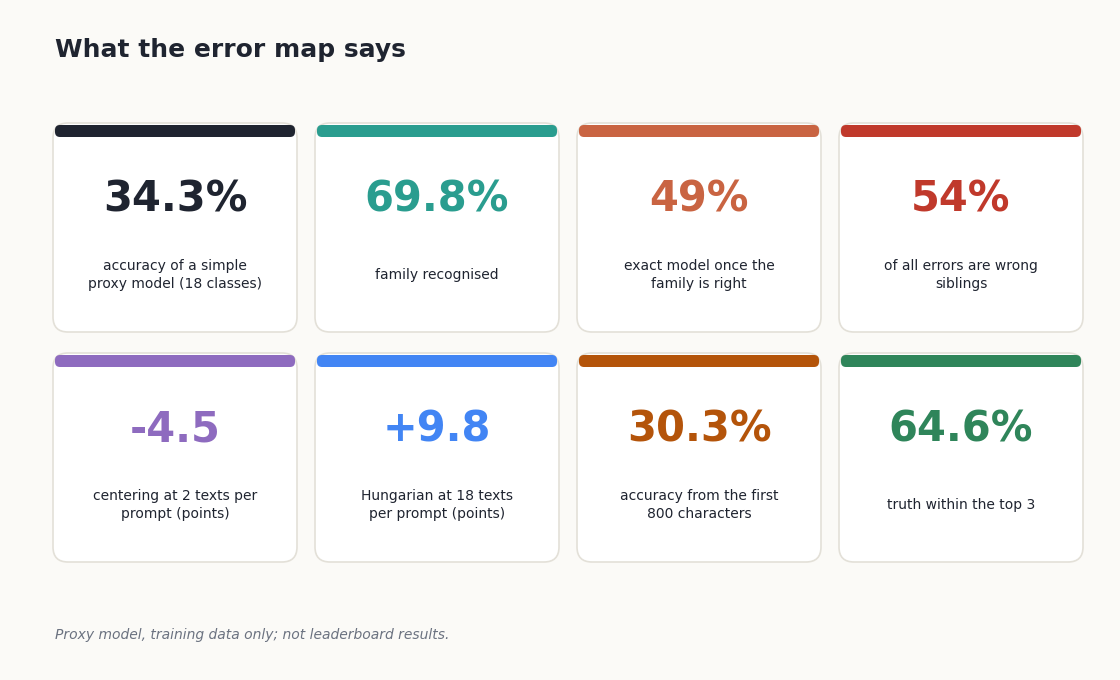

In [27]:
if RUN_ANALYSIS:
    n2 = A[A.k == 2].iloc[0]; n18 = A[A.k == 18].iloc[0]
    numbers = dict(acc=right.mean(), family_acc=(F[pred] == F[y]).mean(), within_family_acc=right.sum() / (F[pred] == F[y]).sum(),
                   siblings_share=same_fam.sum() / (~right).sum(), centering_k2=(n2.centering - n2.plain) * 100,
                   hung_k18=(n18.hungarian - n18.plain) * 100, text_acc_800=float(T.acc[T.chars == '800'].iloc[0]), top3=topk[3])
    fig = findings_card(numbers); plt.show()

## 10. What the strongest public notebooks already do
The current top public notebook family (about 0.70 on the public board) is a large stack. The summary below is read from the code of
[lightningv08's "0.704 | GLM Fable Routing + Qwen3.8-27B LoRA"](https://www.kaggle.com/code/lightningv08/0-704-glm-fable-routing-qwen3-8-27b-lora) (the 0.702 version before it differs by three small edits, listed below)
and from alex chilton's [write-up](https://www.kaggle.com/code/alexchilton/name-that-llm-0-702-all-public-what-failed). It is a reading of the code, not a re-run.

| Stage | What it is (from the code) | Where it plausibly helps (our reading, not measured) |
|---|---|---|
| LoRA readouts | Qwen3-14B, Qwen3-8B, Qwen2.5-14B and Llama-3.1-8B with trained adapters | all kinds; the backbone of the stack |
| Native Qwen3-Embedding-8B expert | LoRA over several depths of the embedding model | all kinds |
| ATLAS, spectral heads, SVC pools, Gaussian calibration | extra readouts and calibration of the logits | not analysed here |
| Qwen3.8-27B LoRA (quantised, with its own GPU kernels) | a larger model reading the full passage | all kinds |
| GLM-5.3 / GLM-5.3-Flash likelihood | per-token log-probabilities and entropy of the two GLM models on **a fixed 15% of the test texts** (90,000 token positions). In the 0.704 the texts are ordered by a priority that adds 0.35 times the claude-fable-5 mass to the family mass, so texts that look like Fable are more likely to be among the scored 15%; after the likelihood stage, a text the stack called GLM can be returned to claude-fable-5 when the Fable-versus-GLM margin rises by at least 0.30 (and is at least 0.25) | the GLM pair and GLM against Claude (and, in the 0.704, Fable against GLM) |
| Sibling residual + soft typography | a log-ratio refinement inside same-family groups, then typographic rules that scale (not zero) a forbidden label by 0.15 (0.05 in the 0.702) | same-family siblings |

**What other people tried and reported as not helping** (all numbers are the *authors'* public-board scores, quoted from alex chilton's notebook; this notebook did not re-run them):

<table style="width:100%;border-collapse:collapse;font-size:14.5px;margin:8px 0;"><tr><th style="text-align:left;padding:7px 10px;border-bottom:2px solid #8a94a6;">What was tried (public notebooks)</th><th style="text-align:left;padding:7px 10px;border-bottom:2px solid #8a94a6;">Reported on the board</th></tr><tr><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);">Hungarian assignment inside test-prompt clusters (several bases)</td><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);white-space:nowrap;"><span style="display:inline-block;background:#c0392b;color:#ffffff;border-radius:10px;padding:2px 9px;font-size:12px;font-weight:700;">lost 0.009 to 0.017</span></td></tr><tr><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);">Extra intra-family gates (Claude / GPT / Gemini / GLM) on a 0.559 base</td><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);white-space:nowrap;"><span style="display:inline-block;background:#6b7280;color:#ffffff;border-radius:10px;padding:2px 9px;font-size:12px;font-weight:700;">0.559, no change</span></td></tr><tr><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);">Within-Gemini gate on a 0.552 base</td><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);white-space:nowrap;"><span style="display:inline-block;background:#6b7280;color:#ffffff;border-radius:10px;padding:2px 9px;font-size:12px;font-weight:700;">0.552, no change</span></td></tr><tr><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);">Adding more LoRA backbones or members to a strong ensemble</td><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);white-space:nowrap;"><span style="display:inline-block;background:#e0a100;color:#1f2430;border-radius:10px;padding:2px 9px;font-size:12px;font-weight:700;">within 0.004 either way</span></td></tr><tr><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);">Native expert share 0.40 to 0.30 / 0.50</td><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);white-space:nowrap;"><span style="display:inline-block;background:#c0392b;color:#ffffff;border-radius:10px;padding:2px 9px;font-size:12px;font-weight:700;">0.680 to 0.674 / 0.679</span></td></tr><tr><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);">Typography evidence 1.5 to 1.2 and Sinkhorn 0.45 to 0.60</td><td style="padding:7px 10px;border-bottom:1px solid rgba(138,148,166,0.35);white-space:nowrap;"><span style="display:inline-block;background:#c0392b;color:#ffffff;border-radius:10px;padding:2px 9px;font-size:12px;font-weight:700;">0.662 to 0.659</span></td></tr></table>

**Noise warning from the same source.** Identical code spread over 0.012 across six submissions (0.682 to 0.694), so a single public score does not rank two
changes that differ by less than about 0.01.

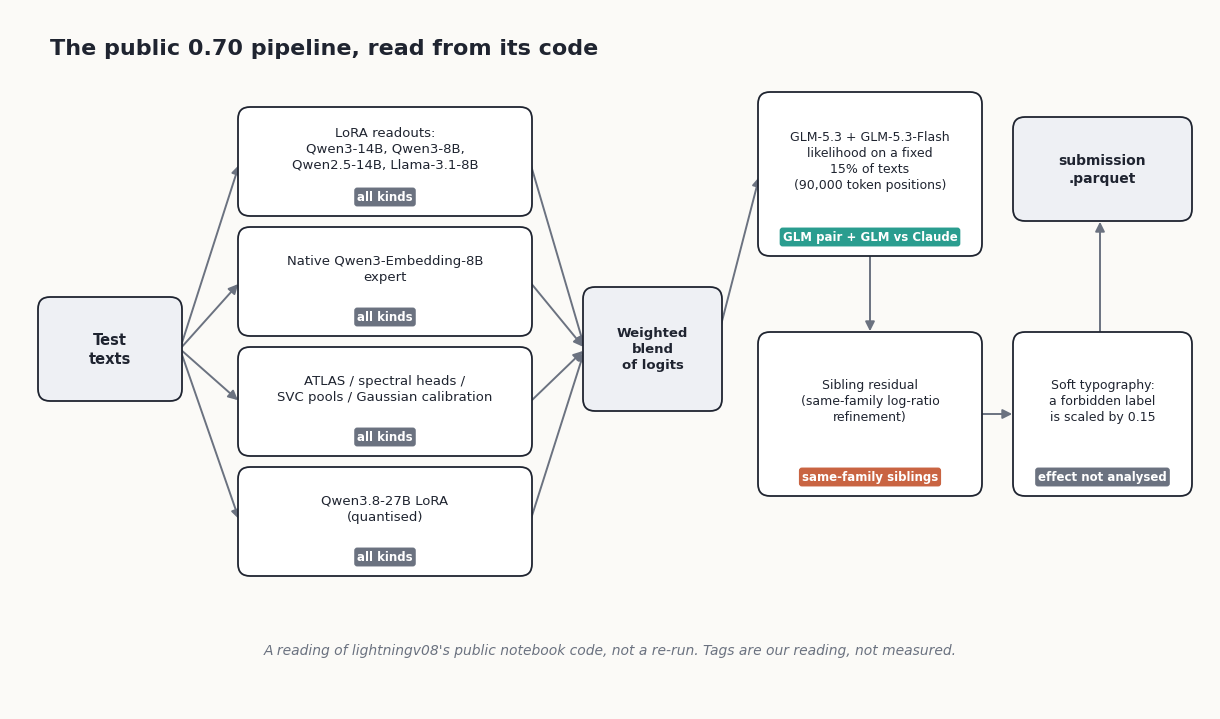

In [28]:
if RUN_ANALYSIS:
    fig = pipeline_architecture(); plt.show()

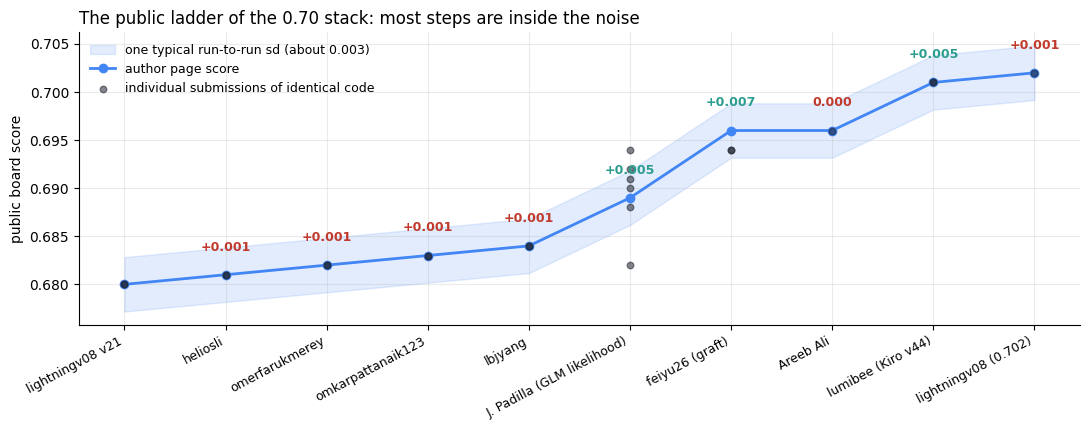

pooled run-to-run sd 0.0028 (df 23); median step 0.001; steps [0.001, 0.001, 0.001, 0.001, 0.005, 0.007, 0.0, 0.005, 0.001]


In [29]:
if RUN_ANALYSIS:
    import statistics as _st
    ROWS = [['dhruvtibarewal nlm-v27', [0.651, 0.651, 0.643, 0.651], 0.651], ['Roman Tamrazov Who am I?', [0.645, 0.654], 0.654], ['mercurydust V31', [0.66, 0.66], 0.66], ['omerfarukmerey 0.663 (version 8)', [0.662], 0.663], ['judith007 0.664', [0.659, 0.659], 0.664], ['bgunshui NTL Apex E (version 9)', [0.663, 0.663], 0.663], ['synthreaper Sovereign Gold Apex (version 11)', [0.666, 0.666], 0.665], ['Areeb Ali NTL We Back', [0.666], 0.666], ['zbigniewkirchner Pairwise Verifier + Matched', [0.667, 0.663], 0.667], ['omerfarukmerey Verifier + Matched Rows + Poo', [0.661], 0.668], ['pablodiegoo Starter Notebook (version 13)', [0.668, 0.668], 0.668], ['ozertuu Dual-SVC Blend + Residual Refinement', [0.668], 0.672], ['ozertuu Residual Sibling Gating M4 Apex (ver', [0.669], 0.673], ['ozertuu Dual-SVC BETTER!', [0.669], 0.672], ['Areeb Ali 0.672 Stack + Public DeBERTa-v3 Me', [0.67], 0.67], ['Areeb Ali 0.672 + DeBERTa-v3 + Our ModernBER', [0.673, 0.673], 0.673], ['lightningv08 ModernBERT + LoRA + Sparse Ense', [0.68, 0.68], 0.68], ['lightningv08 0.681 Qwen3-Embedding LoRA + Qw', [0.679], 0.681], ['heliosli lv681 a15 version 2 (version 22)', [0.681, 0.681], 0.681], ['omerfarukmerey 0.682 GSQ 12% + Mix 0.50 (ver', [0.682, 0.682], 0.682], ['omkarpattanaik123 V28 Sovereign Titan Apex F', [0.683, 0.683], 0.683], ['lbjyang ntl 684 ozertuu mirror (version 25)', [0.684, 0.684], 0.684], ['José Padilla 0.689 Real GLM-5.3 Likelihood o', [0.694, 0.682, 0.691, 0.69, 0.688, 0.692], 0.689], ['feiyu26 NTL 0684 v1 graft (version 27)', [0.694, 0.694], 0.696], ['Areeb Ali 0.696 THIS ACTUALLY WORKS (version', [0.696], 0.696], ['lumibee NTL Kiro v44 Apex Grandmaster (versi', [0.701, 0.701], 0.701], ['lightningv08 0.702 Soft Typography + GLM + Q', [0.702], 0.702], ['Lucas Boesen LoRA x Adaptive Centering', [0.549], 0.547], ['vnton37nguyn lora-instyle', [0.561], 0.563], ['josephadamski91 Teach the Model + ATLAS', [0.606], 0.607]]
    LADDER = [('lightningv08 v21', .680, [.680, .680]), ('heliosli', .681, [.681, .681]), ('omerfarukmerey', .682, [.682, .682]), ('omkarpattanaik123', .683, [.683, .683]),
              ('lbjyang', .684, [.684, .684]), ('J. Padilla (GLM likelihood)', .689, [.694, .682, .691, .690, .688, .692]), ('feiyu26 (graft)', .696, [.694, .694]),
              ('Areeb Ali', .696, [.696]), ('lumibee (Kiro v44)', .701, [.701, .701]), ('lightningv08 (0.702)', .702, [.702])]
    num = den = 0
    for _, r, p in ROWS:
        if len(r) >= 2:
            m = sum(r) / len(r); num += sum((x - m) ** 2 for x in r); den += len(r) - 1
    pooled_sd = (num / den) ** .5
    steps = [round(b[1] - a[1], 3) for a, b in zip(LADDER, LADDER[1:])]
    fig, ax = plt.subplots(figsize=(11, 4.4)); xs = np.arange(len(LADDER)); pts = [l[1] for l in LADDER]
    ax.fill_between(xs, np.array(pts) - pooled_sd, np.array(pts) + pooled_sd, color='#4285f4', alpha=.15, label='one typical run-to-run sd (about %.3f)' % pooled_sd)
    ax.plot(xs, pts, color='#4285f4', lw=2, marker='o', label='author page score')
    for x, l in zip(xs, LADDER):
        ax.scatter([x] * len(l[2]), l[2], s=22, color='#1f2430', alpha=.55, zorder=3, label='individual submissions of identical code' if x == 0 else None)
    for x, d in zip(xs[1:], steps):
        ax.text(x, pts[x] + .0025, ('+' if d > 0 else '') + ('%.3f' % d), ha='center', fontsize=9, color='#c0392b' if abs(d) <= .001 else '#2a9d8f', fontweight='bold')
    ax.set_xticks(xs); ax.set_xticklabels([l[0] for l in LADDER], rotation=28, ha='right', fontsize=9); ax.set_ylabel('public board score'); ax.grid(alpha=.25)
    ax.set_title('The public ladder of the 0.70 stack: most steps are inside the noise', loc='left'); ax.legend(frameon=False, fontsize=9, loc='upper left'); plt.tight_layout(); plt.show()
    print('pooled run-to-run sd %.4f (df %d); median step %.3f; steps %s' % (pooled_sd, den, _st.median(steps), steps))

<table style="width:100%;border-collapse:separate;border-spacing:8px;margin:6px 0 2px 0;"><tr><td style="background:linear-gradient(135deg,#4285f4,#3367be);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:25%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">0.704</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">best single public score reported (authors)</div></td><td style="background:linear-gradient(135deg,#c96442,#9c4e33);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:25%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">±0.003</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">typical run-to-run sd of identical code (pooled over the 17 notebooks with repeats)</div></td><td style="background:linear-gradient(135deg,#8e6bbf,#6e5394);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:25%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">+0.001</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">median step of the ladder; 6 of 9 steps are +0.001 or less</div></td><td style="background:linear-gradient(135deg,#2a9d8f,#207a6f);color:#ffffff;border-radius:12px;padding:16px 12px;text-align:center;width:25%;vertical-align:top;"><div style="font-size:34px;font-weight:800;line-height:1.1;">0.012</div><div style="font-size:13px;margin-top:6px;line-height:1.35;">widest spread of one notebook (six runs)</div></td></tr></table>

**What the public record shows** (the authors' reported public scores, from alex chilton's table; this notebook did not re-run them).
- The stack climbed from 0.680 to 0.702 in ten public versions. Six of the nine steps are +0.001 or less. The three larger ones (+0.005, +0.007, +0.005) came with a **new kind of evidence**: the GLM likelihood stage, its graft onto the 0.684 stack, and the Apex sibling stage.
- The newest step, 0.702 to 0.704 (+0.002, three small edits: a Fable-weighted order for the GLM stage, a rule that can return a GLM call to Fable after the likelihood stage, and a typography penalty of 0.15 instead of 0.05), is smaller than one run-to-run sd (about 0.003) and is a single reported value, so by itself it is not evidence that those edits help. It is not part of the ladder statistics below.
- Re-running identical code moves the score by about 0.003 (pooled sd over notebooks with repeats). The widest case, 0.012, is the notebook whose GLM coverage depended on elapsed time, which later versions fixed; so a fixed-coverage version such as the 0.702 may be steadier, but only one run of it is known.
- **Selection effect (illustration, not an estimate for this notebook).** If a version is the best of six submissions with noise of this size, its expected public-score inflation is about 1.3 standard deviations, roughly +0.004.

<div style="border-left:6px solid #e0a100;background:rgba(138,148,166,0.13);padding:12px 20px;border-radius:8px;margin:14px 0;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;color:#e0a100;">Limitations of the 0.704 pipeline (our reading of its code and logs)</div><ul style="margin:6px 0 0 18px;padding:0;"><li style="margin:5px 0;"><b>One noisy number.</b> The public score is a single board value. Identical code spread over 0.012 across six submissions (alex chilton's table), so small differences between versions are not evidence.</li><li style="margin:5px 0;"><b>Settings were chosen on the public board.</b> Many of its settings appear in the public record as arms compared by public score (native-expert share 0.40 / 0.30 / 0.50, typography evidence 1.5 to 1.2, GSQ share and mix weights in version titles), and the ladder above is the shape that choosing versions by public score produces. We cannot see how much of the 0.70 is real: it is best read as about 0.70, plus or minus a few thousandths, and possibly a little optimistic if the final standing uses test rows the public board does not show.</li><li style="margin:5px 0;"><b>The expensive evidence covers only part of the texts.</b> The GLM likelihood stage scores a fixed 15% of the test texts (90,000 token positions) and uses GLM weights quantised to IQ3_XXS, so its signal is approximate and absent for most texts.</li><li style="margin:5px 0;"><b>Texts are read in part.</b> The LoRA readouts use a maximum length of 384 tokens and the likelihood head a 160-token protocol (the 27B model reads full passages). Our Section 8 suggests accuracy keeps growing with length, so truncation may leave signal unused. That is a hypothesis, not measured on this pipeline.</li><li style="margin:5px 0;"><b>Hand-set constants.</b> The sibling-residual strength (0.10) and the typography penalty (0.15, raised from 0.05 in the 0.702) are fixed numbers in the final cell. We do not know how they were chosen and have not tested other values. The 0.704 changes three things at once, so the public record cannot say which one, if any, moved the score.</li><li style="margin:5px 0;"><b>Heavy dependence on other people's artifacts.</b> About 45 attached inputs (datasets, models, notebooks) must all be mounted, or the run stops with an assertion. It also uses extra generated passages from public pools (about 226,000 rows in the SVC pool and 24,000 matched rows, per this notebook's own run log) whose origin we have not audited. It needs two T4 GPUs, and the scoring rerun is slow.</li><li style="margin:5px 0;"><b>A silent failure was found in an ancestor.</b> The version it is based on had a complementary worker whose failed return code was ignored and whose output never reached the prediction; the author disabled it. Failures like this are hard to spot in a stack this size.</li><li style="margin:5px 0;"><b>No error analysis exists for it.</b> The hidden labels are not public, so where this pipeline fails is unknown. Part 1 describes a simple model, not this one.</li><li style="margin:5px 0;"><b>The score shown is quoted.</b> 0.704 is the authors' public-board score; the score of our own submission may differ within the noise.</li></ul></div>

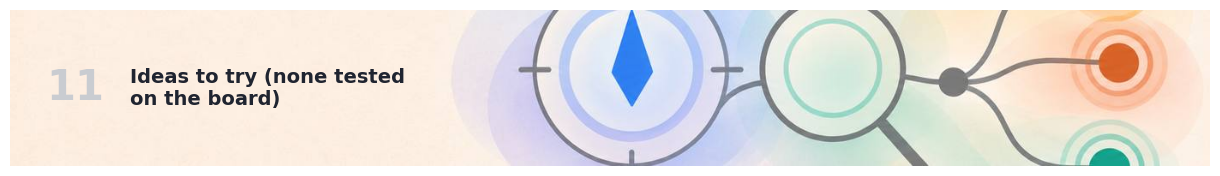

In [30]:
if RUN_ANALYSIS:
    band('band_ideas', '11', 'Ideas to try (none tested on the board)')

## 11. Ideas for improvement (none of them tested on the leaderboard)
These are hypotheses that follow from the measurements above. They are **not** leaderboard results and no gain is claimed. For each: what the proxy suggests, and why it might fail.

<div style="border-left:6px solid #c96442;background:rgba(138,148,166,0.13);padding:12px 18px;border-radius:8px;margin:12px 0;line-height:1.5;"><div><span style="display:inline-block;background:#c96442;color:#fff;border-radius:50%;width:26px;height:26px;text-align:center;line-height:26px;font-weight:800;margin-right:8px;">1</span><b style="font-size:16px;">Make group tricks conditional on group quality</b> <span style="display:inline-block;background:#c0392b;color:#fff;border-radius:10px;padding:2px 9px;font-size:11px;font-weight:700;margin-left:6px;">NOT TESTED</span></div><div style="margin-top:6px;"><b>Suggests:</b> the gain of Hungarian and centering is large only with many correct texts per group (Section 6) and disappears at about 25% wrong members (Section 7). A notebook could measure how tight each rebuilt group is and apply the constraint only to tight groups, or soften it (a prior instead of a hard one-to-one assignment).</div><div><b>Might not work:</b> the public failure table shows these tricks already lost on the board, and our simulation does not explain why.</div></div>

<div style="border-left:6px solid #4285f4;background:rgba(138,148,166,0.13);padding:12px 18px;border-radius:8px;margin:12px 0;line-height:1.5;"><div><span style="display:inline-block;background:#4285f4;color:#fff;border-radius:50%;width:26px;height:26px;text-align:center;line-height:26px;font-weight:800;margin-right:8px;">2</span><b style="font-size:16px;">Never use centering with groups of two or three</b> <span style="display:inline-block;background:#c0392b;color:#fff;border-radius:10px;padding:2px 9px;font-size:11px;font-weight:700;margin-left:6px;">NOT TESTED</span></div><div style="margin-top:6px;"><b>Suggests:</b> with two texts the centred scores are opposites, and the proxy loses about 4 to 6 points at k=2.</div><div><b>Might not work:</b> the real group sizes are unknown.</div></div>

<div style="border-left:6px solid #2a9d8f;background:rgba(138,148,166,0.13);padding:12px 18px;border-radius:8px;margin:12px 0;line-height:1.5;"><div><span style="display:inline-block;background:#2a9d8f;color:#fff;border-radius:50%;width:26px;height:26px;text-align:center;line-height:26px;font-weight:800;margin-right:8px;">3</span><b style="font-size:16px;">Spend the expensive evidence on the hard blocks, and read more of each text there</b> <span style="display:inline-block;background:#c0392b;color:#fff;border-radius:10px;padding:2px 9px;font-size:11px;font-weight:700;margin-left:6px;">NOT TESTED</span></div><div style="margin-top:6px;"><b>Suggests:</b> accuracy keeps growing with text length (Section 8), and GLM versus GLM-Flash, the GPT-5.6 trio and the Gemini Flash trio are the least separable by surface text (Section 3, AUC 0.52 to 0.67). The GLM likelihood stage reads a fixed 15% of the texts.</div><div><b>Might not work:</b> GPU time is the binding limit; public variants that raise the cover to 20% exist and we have no result for them.</div></div>

<div style="border-left:6px solid #8e6bbf;background:rgba(138,148,166,0.13);padding:12px 18px;border-radius:8px;margin:12px 0;line-height:1.5;"><div><span style="display:inline-block;background:#8e6bbf;color:#fff;border-radius:50%;width:26px;height:26px;text-align:center;line-height:26px;font-weight:800;margin-right:8px;">4</span><b style="font-size:16px;">A different model for between-family confusions</b> <span style="display:inline-block;background:#c0392b;color:#fff;border-radius:10px;padding:2px 9px;font-size:11px;font-weight:700;margin-left:6px;">NOT TESTED</span></div><div style="margin-top:6px;"><b>Suggests:</b> GLM into Claude and Kimi and Qwen into GPT make up 46% of the proxy's errors, and a same-family refinement cannot touch them.</div><div><b>Might not work:</b> intra-family gates did not help in the public failure table, and a naive top-2 pair specialist did not help here (Section 9).</div></div>

<div style="border-left:6px solid #e0a100;background:rgba(138,148,166,0.13);padding:12px 18px;border-radius:8px;margin:12px 0;line-height:1.5;"><div><span style="display:inline-block;background:#e0a100;color:#fff;border-radius:50%;width:26px;height:26px;text-align:center;line-height:26px;font-weight:800;margin-right:8px;">5</span><b style="font-size:16px;">Validate like the test</b> <span style="display:inline-block;background:#c0392b;color:#fff;border-radius:10px;padding:2px 9px;font-size:11px;font-weight:700;margin-left:6px;">NOT TESTED</span></div><div style="margin-top:6px;"><b>Suggests:</b> a forum comment credited by alex chilton (GoPain) reports that scoring on 2 answers per prompt tracked the board far better than scoring on all 18. Our Section 6 shows that the choice of k changes which tricks look good, which fits that advice.</div><div><b>Might not work:</b> we have not checked the claim itself.</div></div>

<div style="background:linear-gradient(120deg,#4285f4,#2f5faf);color:#ffffff;padding:14px 20px;border-radius:10px;margin:14px 0;font-size:15.5px;line-height:1.5;"><div style="font-size:11.5px;letter-spacing:2px;text-transform:uppercase;font-weight:700;opacity:.9;">If you remember only three things</div><ol style='margin:6px 0 0 18px'><li><b>Siblings are the hard part.</b> The two GLM models, the three GPT-5.6 models and the Gemini Flash trio are nearly coin flips for the text alone, and 46% of the proxy's mistakes are between families, where a same-family fix does not reach.</li><li><b>Group tricks are a bet.</b> They pay off with many correct texts per prompt and clean groups, hurt with two or three texts, and the gain vanishes when a quarter of a group is wrong.</li><li><b>Evidence beats volume.</b> The fingerprint keeps growing with text length, while more of the same data flattens out, so new kinds of evidence and longer reads look like the better bet. None of this is tested on the board.</li></ol></div>

## 12. Limits
- The error analysis is from a simple model, not from the top pipeline, and the hidden-test errors are unknown.
- Folds follow prompts (all 18 answers of a prompt together). The hidden test structure is unknown.
- Small experiments (learning curve, simulations with 8 to 10 repeats) are indications, not measurements. The temperature of the Hungarian step is fixed at 3 and was not tuned.
- Everything here is measured on the training set only.

## 13. Credits
The pipeline description rests on the public work of lightningv08, lumibee, alex chilton, ozertuu, Areeb Ali, feiyu26, José Padilla (estopadilla), jamesliebel and the dataset and model authors they credit.
<b>Illustrations.</b> The cover, the section banners, the family emblems and the concept images were created with AI assistance (ChatGPT image generation) and placed by this notebook's code. All charts and tables are computed and drawn by the code in this notebook.

Areeb Ali's <i>0.702 | Read the Fingerprints</i> overlaps with Section 2 (the plain TF-IDF ruler and its lab-level confusion map); it also adds the Open Pool sibling specialists and a typography audit, which are outside this notebook. Our Idea 4 is about errors between families, which a within-lab specialist does not touch, so the two are complementary.

The analysis in Part 1 runs none of their code and attaches none of their models. Part 2 is lightningv08's public notebook, reproduced unchanged and credited above; that notebook states on its page that it is released under the Apache 2.0 license. The datasets and models it attaches keep their own licences and credits.

---
# Part 2: the pipeline that produces the leaderboard score
Everything below is the public notebook **[0.704 | GLM Fable Routing + Qwen3.8-27B LoRA](https://www.kaggle.com/code/lightningv08/0-704-glm-fable-routing-qwen3-8-27b-lora)** by Vladislav Lavrentev (lightningv08), version 12 of that notebook, copied without any change to its code cells (later versions of it change the final stage). The credits of the original notebook follow unchanged.


# Apex and GLM likelihood calibration

This notebook builds on [the Claude Fable routing ensemble, V7](https://www.kaggle.com/code/lightningv08/0-702-apex-style-15-glm-qwen3-8-27b-lora?scriptVersionId=370826759). It retains the LoRA and encoder readers, the five-fold embedding expert, the Qwen3.8-27B adapter, and GLM-5.3 and GLM-5.3-Flash token likelihood. GLM work is capped at 15% of texts and 90,000 estimated token positions.

Preserve a clear GLM likelihood reassignment from a GLM class to Claude Fable through the style stage.


In [31]:
%%writefile pinned_assets.py
"""Explicit paths from the pinned attachment inventory; no model discovery."""
from pathlib import Path
import os
MOUNT_ALIASES = {'/kaggle/input/glm53-iq3xxs-segs-a-mirror': '/kaggle/input/datasets/jamesliebel/glm53-iq3xxs-segs-a-mirror', '/kaggle/input/glm53-iq3xxs-segs-b-mirror': '/kaggle/input/datasets/jamesliebel/glm53-iq3xxs-segs-b-mirror', '/kaggle/input/glm53-flash-iq3xxs-segs-mirror': '/kaggle/input/datasets/jamesliebel/glm53-flash-iq3xxs-segs-mirror', '/kaggle/input/nlm-l24-adapters': '/kaggle/input/datasets/dhruvtibarewal/nlm-l24-adapters', '/kaggle/input/ntl-olmo2-native24-final-inference-assets': '/kaggle/input/datasets/lightningv08/ntl-olmo2-native24-final-inference-assets', '/kaggle/input/name-that-llm-open-pool': '/kaggle/input/datasets/crtproduction/name-that-llm-open-pool', '/kaggle/input/ntl-extra-api-passages': '/kaggle/input/datasets/seyitkaangunes/ntl-extra-api-passages', '/kaggle/input/ntl-generations': '/kaggle/input/datasets/abdullah1afify/ntl-generations', '/kaggle/input/ntl-proxy-generations': '/kaggle/input/datasets/dophuchung/ntl-proxy-generations', '/kaggle/input/ntl-qwen3-8b-lora-claude-head': '/kaggle/input/datasets/zbigniewkirchner/ntl-qwen3-8b-lora-claude-head', '/kaggle/input/nlm-matched-clean': '/kaggle/input/datasets/dhruvtibarewal/nlm-matched-clean', '/kaggle/input/nlm-offline-wheels': '/kaggle/input/datasets/dhruvtibarewal/nlm-offline-wheels', '/kaggle/input/ntl-atlas-qwen3-8b-v1': '/kaggle/input/datasets/josephadamski91/ntl-atlas-qwen3-8b-v1', '/kaggle/input/ntl-free-proxy-generations': '/kaggle/input/datasets/lucasboesen/ntl-free-proxy-generations', '/kaggle/input/ntl-q14-lora': '/kaggle/input/datasets/nuridudak/ntl-q14-lora', '/kaggle/input/ntl-q14-lora-v4': '/kaggle/input/datasets/nuridudak/ntl-q14-lora-v4', '/kaggle/input/ntl-spectral-style-heads-paired-4404': '/kaggle/input/datasets/kirilltym/ntl-spectral-style-heads-paired-4404', '/kaggle/input/ntl-svc-prefit-pool-v4n': '/kaggle/input/datasets/nuridudak/ntl-svc-prefit-pool-v4n', '/kaggle/input/nlm-enc-v5': '/kaggle/input/datasets/dhruvtibarewal/nlm-enc-v5', '/kaggle/input/ntl-two-stage-encoders': '/kaggle/input/datasets/nuridudak/ntl-two-stage-encoders', '/kaggle/input/ntl-two-stage-lora': '/kaggle/input/datasets/nishantdahal/ntl-two-stage-lora', '/kaggle/input/ntl-handwriting-blend': '/kaggle/input/datasets/nishantdahal/ntl-handwriting-blend', '/kaggle/input/nlm-l24-adapters-v5': '/kaggle/input/datasets/dhruvtibarewal/nlm-l24-adapters-v5', '/kaggle/input/prvsiyans-extended-name-that-llm-dataset': '/kaggle/input/datasets/prvsiyan/prvsiyans-extended-name-that-llm-dataset', '/kaggle/input/qwen35-9b-safetensors': '/kaggle/input/datasets/bbucxi/qwen35-9b-safetensors', '/kaggle/input/ultrabert-380m-ntl': '/kaggle/input/datasets/pjmathematician/ultrabert-380m-ntl', '/kaggle/input/name-that-llm-glm4-9b-trunc25': '/kaggle/input/notebooks/lucasboesen/name-that-llm-glm4-9b-trunc25', '/kaggle/input/name-that-llm-extract-encoders2': '/kaggle/input/notebooks/lucasboesen/name-that-llm-extract-encoders2', '/kaggle/input/name-that-llm-electra-large-weights': '/kaggle/input/notebooks/lucasboesen/name-that-llm-electra-large-weights', '/kaggle/input/name-that-llm-desklib-weights': '/kaggle/input/notebooks/lucasboesen/name-that-llm-desklib-weights', '/kaggle/input/name-that-llm-train-lora24-s7': '/kaggle/input/notebooks/lucasboesen/name-that-llm-train-lora24-s7', '/kaggle/input/name-that-llm-train-tokattn': '/kaggle/input/notebooks/lucasboesen/name-that-llm-train-tokattn', '/kaggle/input/name-that-llm-train-tokattn2': '/kaggle/input/notebooks/lucasboesen/name-that-llm-train-tokattn2', '/kaggle/input/ntl-train-lora-qwen25-instyle': '/kaggle/input/notebooks/vnton37nguyn/ntl-train-lora-qwen25-instyle', '/kaggle/input/ntl-glm-likelihood-train': '/kaggle/input/notebooks/estopadilla/ntl-glm-likelihood-train', '/kaggle/input/llama-3-1-8b-base': '/kaggle/input/models/alexchilton/llama-3-1-8b-base', '/kaggle/input/qwen-3': '/kaggle/input/models/qwen-lm/qwen-3', '/kaggle/input/qwen-3-embedding': '/kaggle/input/models/qwen-lm/qwen-3-embedding', '/kaggle/input/qwen2.5': '/kaggle/input/models/qwen-lm/qwen2.5'}
PATHS = {'/kaggle/input/**/': [], '/kaggle/input/**/bitsandbytes-*.whl': ['/kaggle/input/nlm-offline-wheels/bitsandbytes-0.50.2-py3-none-manylinux_2_24_x86_64.whl', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/bitsandbytes-0.50.2-py3-none-manylinux_2_24_x86_64.whl'], '/kaggle/input/**/config.json': ['/kaggle/input/models/alexchilton/llama-3-1-8b-base/transformers/default/1/config.json', '/kaggle/input/models/qwen-lm/qwen-3-embedding/transformers/8b/1/config.json', '/kaggle/input/models/qwen-lm/qwen-3/transformers/14b-base/1/config.json', '/kaggle/input/models/qwen-lm/qwen-3/transformers/14b/1/config.json', '/kaggle/input/models/qwen-lm/qwen-3/transformers/4b-base/1/config.json', '/kaggle/input/models/qwen-lm/qwen-3/transformers/8b-base/1/config.json', '/kaggle/input/models/qwen-lm/qwen-3/transformers/8b/1/config.json', '/kaggle/input/models/qwen-lm/qwen2.5/transformers/14b/1/config.json', '/kaggle/input/models/qwen-lm/qwen2.5/transformers/7b/1/config.json', '/kaggle/input/name-that-llm-desklib-weights/desklib-detector/config.json', '/kaggle/input/name-that-llm-electra-large-weights/electra-large-discriminator/config.json', '/kaggle/input/name-that-llm-extract-encoders2/deberta-v3-large/config.json', '/kaggle/input/name-that-llm-glm4-9b-trunc25/glm4_9b_trunc25/config.json', '/kaggle/input/nlm-enc-v5/encoder/config.json', '/kaggle/input/ntl-handwriting-blend/deberta_v3_large/encoder/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/document-deberta-07nov/document-deberta-07nov/final/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/document-modernbert-07nov/document-modernbert-07nov/final/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/gsq3-base/qwen38-27b-gsq3/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/llama31-prefix24/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/ntl-tabular-offline-assets/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-27b-nf4/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/ntl-lora24-fivefold-training/lora24/final/base_config/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/olmo2-7b-fp16-offline-weights/olmo2-fp16-base/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/smollm3-3b-base-offline-weights/smollm3-base/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl-native-q8-multidepth-fivefold-0679/base/1_Pooling/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl-native-q8-multidepth-fivefold-0679/base/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl-native-wemm4-fivefold-0679/base/config.json', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/qwen38-mixed-tail8/name-that-llm-artifacts/qwen38-27b-mixed-tail8-text/config.json', '/kaggle/input/ntl-two-stage-encoders/desklib/config.json', '/kaggle/input/ntl-two-stage-encoders/modernbert/config.json', '/kaggle/input/qwen35-9b-safetensors/config.json', '/kaggle/input/ultrabert-380m-ntl/fold0/config.json', '/kaggle/input/ultrabert-380m-ntl/fold1/config.json', '/kaggle/input/ultrabert-380m-ntl/fold2/config.json', '/kaggle/input/ultrabert-380m-ntl/fold3/config.json', '/kaggle/input/ultrabert-380m-ntl/fold4/config.json'], '/kaggle/input/**/deberta-v3-large/config.json': ['/kaggle/input/name-that-llm-extract-encoders2/deberta-v3-large/config.json'], '/kaggle/input/**/deberta_v3_large/meta.json': ['/kaggle/input/ntl-handwriting-blend/deberta_v3_large/meta.json'], '/kaggle/input/**/desklib-detector/config.json': ['/kaggle/input/name-that-llm-desklib-weights/desklib-detector/config.json'], '/kaggle/input/**/electra-large-discriminator/config.json': ['/kaggle/input/name-that-llm-electra-large-weights/electra-large-discriminator/config.json'], '/kaggle/input/**/gen_passages.csv': ['/kaggle/input/datasets/lucasboesen/ntl-free-proxy-generations/gen_passages.csv'], '/kaggle/input/**/ll8v5/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/ll8v5/heads.pt'], '/kaggle/input/**/ll8v5_f0/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/ll8v5_f0/heads.pt'], '/kaggle/input/**/ll8v5_f1/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/ll8v5_f1/heads.pt'], '/kaggle/input/**/ll8v5_f2/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/ll8v5_f2/heads.pt'], '/kaggle/input/**/ll8v5_f3/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/ll8v5_f3/heads.pt'], '/kaggle/input/**/ll8v5_f4/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/ll8v5_f4/heads.pt'], '/kaggle/input/**/lora24/final/COMPLETE.json': ['/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/ntl-lora24-fivefold-training/lora24/final/COMPLETE.json'], '/kaggle/input/**/lora_qwen25_14b/meta.json': ['/kaggle/input/ntl-handwriting-blend/lora_qwen25_14b/meta.json'], '/kaggle/input/**/lora_qwen3_14b/meta.json': ['/kaggle/input/ntl-handwriting-blend/lora_qwen3_14b/meta.json'], '/kaggle/input/**/name-that-llm-train-lora24-s7/lora_out/job_final/COMPLETE.json': ['/kaggle/input/name-that-llm-train-lora24-s7/lora_out/job_final/COMPLETE.json'], '/kaggle/input/**/nlm_matched_clean.parquet': ['/kaggle/input/datasets/dhruvtibarewal/nlm-matched-clean/nlm_matched_clean.parquet'], '/kaggle/input/**/ntl-native-q8-multidepth-fivefold-0679/manifest.json': ['/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl-native-q8-multidepth-fivefold-0679/manifest.json'], '/kaggle/input/**/ntl-q14-lora-v4/heads.safetensors': ['/kaggle/input/ntl-q14-lora-v4/heads.safetensors'], '/kaggle/input/**/ntl-q14-lora/heads.safetensors': ['/kaggle/input/ntl-q14-lora/heads.safetensors'], '/kaggle/input/**/ntl-qwen3-8b-lora-claude-head/**/final/COMPLETE.json': ['/kaggle/input/ntl-qwen3-8b-lora-claude-head/final/COMPLETE.json'], '/kaggle/input/**/ntl-train-lora-qwen25-instyle/lora_out/job_final/COMPLETE.json': ['/kaggle/input/ntl-train-lora-qwen25-instyle/lora_out/job_final/COMPLETE.json'], '/kaggle/input/**/ntl666-cache-parts.json': ['/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl666-cache-parts.json'], '/kaggle/input/**/ntl_extra_passages_claude.csv': ['/kaggle/input/datasets/seyitkaangunes/ntl-extra-api-passages/ntl_extra_passages_claude.csv'], '/kaggle/input/**/ntl_generated*.csv': [], '/kaggle/input/**/ntl_generations.csv': ['/kaggle/input/datasets/abdullah1afify/ntl-generations/ntl_generations.csv'], '/kaggle/input/**/ntl_open_pool.parquet': ['/kaggle/input/name-that-llm-open-pool/ntl_open_pool.parquet'], '/kaggle/input/**/ntl_proxy_generations.csv': ['/kaggle/input/datasets/dophuchung/ntl-proxy-generations/ntl_proxy_generations.csv'], '/kaggle/input/**/passages_clean.csv': ['/kaggle/input/datasets/prvsiyan/prvsiyans-extended-name-that-llm-dataset/passages_clean.csv'], '/kaggle/input/**/q14v5/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q14v5/heads.pt'], '/kaggle/input/**/q14v5_f0/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q14v5_f0/heads.pt'], '/kaggle/input/**/q14v5_f1/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q14v5_f1/heads.pt'], '/kaggle/input/**/q14v5_f2/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q14v5_f2/heads.pt'], '/kaggle/input/**/q14v5_f3/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q14v5_f3/heads.pt'], '/kaggle/input/**/q14v5_f4/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q14v5_f4/heads.pt'], '/kaggle/input/**/q8v5/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q8v5/heads.pt'], '/kaggle/input/**/q8v5_f0/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q8v5_f0/heads.pt'], '/kaggle/input/**/q8v5_f1/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q8v5_f1/heads.pt'], '/kaggle/input/**/q8v5_f2/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q8v5_f2/heads.pt'], '/kaggle/input/**/q8v5_f3/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q8v5_f3/heads.pt'], '/kaggle/input/**/q8v5_f4/heads.pt': ['/kaggle/input/nlm-l24-adapters-v5/q8v5_f4/heads.pt'], '/kaggle/input/**/tokattn_debl23_final.pt': ['/kaggle/input/name-that-llm-train-tokattn2/tokattn_debl23_final.pt'], '/kaggle/input/**/tokattn_final.pt': ['/kaggle/input/name-that-llm-train-tokattn/tokattn_final.pt'], '/kaggle/input/**/ultrabert-380m-ntl': ['/kaggle/input/ultrabert-380m-ntl'], '/kaggle/input/ultrabert-380m-ntl/fold*': ['/kaggle/input/ultrabert-380m-ntl/fold0', '/kaggle/input/ultrabert-380m-ntl/fold1', '/kaggle/input/ultrabert-380m-ntl/fold2', '/kaggle/input/ultrabert-380m-ntl/fold3', '/kaggle/input/ultrabert-380m-ntl/fold4']}
CHECKPOINTS = {('llama', None, None): '/kaggle/input/models/alexchilton/llama-3-1-8b-base/transformers/default/1', ('llama', 4096, None): '/kaggle/input/models/alexchilton/llama-3-1-8b-base/transformers/default/1', (None, None, '1'): '/kaggle/input/models/alexchilton/llama-3-1-8b-base/transformers/default/1', ('qwen3', None, None): '/kaggle/input/models/qwen-lm/qwen-3-embedding/transformers/8b/1', ('qwen3', 4096, None): '/kaggle/input/models/qwen-lm/qwen-3-embedding/transformers/8b/1', ('qwen3', 5120, None): '/kaggle/input/models/qwen-lm/qwen-3/transformers/14b-base/1', ('qwen3', 2560, None): '/kaggle/input/models/qwen-lm/qwen-3/transformers/4b-base/1', ('qwen2', None, None): '/kaggle/input/models/qwen-lm/qwen2.5/transformers/14b/1', ('qwen2', 5120, None): '/kaggle/input/models/qwen-lm/qwen2.5/transformers/14b/1', ('qwen2', 3584, None): '/kaggle/input/models/qwen-lm/qwen2.5/transformers/7b/1', ('deberta-v2', None, None): '/kaggle/input/name-that-llm-desklib-weights/desklib-detector', ('deberta-v2', 1024, None): '/kaggle/input/name-that-llm-desklib-weights/desklib-detector', (None, None, 'desklib-detector'): '/kaggle/input/name-that-llm-desklib-weights/desklib-detector', ('electra', None, None): '/kaggle/input/name-that-llm-electra-large-weights/electra-large-discriminator', ('electra', 1024, None): '/kaggle/input/name-that-llm-electra-large-weights/electra-large-discriminator', (None, None, 'electra-large-discriminator'): '/kaggle/input/name-that-llm-electra-large-weights/electra-large-discriminator', (None, None, 'deberta-v3-large'): '/kaggle/input/name-that-llm-extract-encoders2/deberta-v3-large', ('glm4', None, None): '/kaggle/input/name-that-llm-glm4-9b-trunc25/glm4_9b_trunc25', ('glm4', 4096, None): '/kaggle/input/name-that-llm-glm4-9b-trunc25/glm4_9b_trunc25', (None, None, 'glm4_9b_trunc25'): '/kaggle/input/name-that-llm-glm4-9b-trunc25/glm4_9b_trunc25', ('modernbert', None, None): '/kaggle/input/nlm-enc-v5/encoder', ('modernbert', 1024, None): '/kaggle/input/nlm-enc-v5/encoder', (None, None, 'encoder'): '/kaggle/input/nlm-enc-v5/encoder', ('deberta-v2', 768, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/document-deberta-07nov/document-deberta-07nov/final', (None, None, 'final'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/document-deberta-07nov/document-deberta-07nov/final', ('qwen3_5', None, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/gsq3-base/qwen38-27b-gsq3', (None, None, 'qwen38-27b-gsq3'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/gsq3-base/qwen38-27b-gsq3', (None, None, 'llama31-prefix24'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/llama31-prefix24', (None, None, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/ntl-tabular-offline-assets', (None, None, 'ntl-tabular-offline-assets'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/ntl-tabular-offline-assets', (None, None, 'qwen38-27b-nf4'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-27b-nf4', (None, None, 'base_config'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/ntl-lora24-fivefold-training/lora24/final/base_config', ('olmo2', None, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/olmo2-7b-fp16-offline-weights/olmo2-fp16-base', ('olmo2', 4096, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/olmo2-7b-fp16-offline-weights/olmo2-fp16-base', (None, None, 'olmo2-fp16-base'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/olmo2-7b-fp16-offline-weights/olmo2-fp16-base', ('smollm3', None, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/smollm3-3b-base-offline-weights/smollm3-base', ('smollm3', 2048, None): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/smollm3-3b-base-offline-weights/smollm3-base', (None, None, 'smollm3-base'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/notebook-inputs/notebook-inputs/smollm3-3b-base-offline-weights/smollm3-base', (None, None, '1_Pooling'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl-native-q8-multidepth-fivefold-0679/base/1_Pooling', (None, None, 'base'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/ntl-native-q8-multidepth-fivefold-0679/base', (None, None, 'qwen38-27b-mixed-tail8-text'): '/kaggle/input/ntl-olmo2-native24-final-inference-assets/qwen38-mixed-tail8/name-that-llm-artifacts/qwen38-27b-mixed-tail8-text', (None, None, 'desklib'): '/kaggle/input/ntl-two-stage-encoders/desklib', (None, None, 'modernbert'): '/kaggle/input/ntl-two-stage-encoders/modernbert', (None, None, 'qwen35-9b-safetensors'): '/kaggle/input/qwen35-9b-safetensors', ('ultrabert', None, None): '/kaggle/input/ultrabert-380m-ntl/fold0', ('ultrabert', 1024, None): '/kaggle/input/ultrabert-380m-ntl/fold0', (None, None, 'fold0'): '/kaggle/input/ultrabert-380m-ntl/fold0', (None, None, 'fold1'): '/kaggle/input/ultrabert-380m-ntl/fold1', (None, None, 'fold2'): '/kaggle/input/ultrabert-380m-ntl/fold2', (None, None, 'fold3'): '/kaggle/input/ultrabert-380m-ntl/fold3', (None, None, 'fold4'): '/kaggle/input/ultrabert-380m-ntl/fold4'}

def asset_path(value):
    if Path(value).exists():
        return value
    for flat,namespaced in MOUNT_ALIASES.items():
        for origin,target in ((flat,namespaced),(namespaced,flat)):
            if value==origin or value.startswith(origin+'/'):
                resolved=target+value[len(origin):]
                assert Path(resolved).exists(), ('missing exact input',value,resolved)
                return resolved
    return value

def asset_paths(key, recursive=False):
    values=[asset_path(v) for v in PATHS[key]]
    for value in values:
        assert Path(value).exists(), value
    return values.copy()

def checkpoint(model_type, hidden=None, dir_name=None):
    path=asset_path(CHECKPOINTS[(model_type,hidden,dir_name)])
    assert Path(path,'config.json').is_file(), path
    return path


Writing pinned_assets.py


In [32]:
from pinned_assets import asset_path,asset_paths
import glob
import json
import os
import re
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd

NB_T0 = time.time()
FINAL_LOGITS = '/kaggle/temp/final-logits.npz'

wheels = [asset_path('/kaggle/input/nlm-offline-wheels/bitsandbytes-0.50.2-py3-none-manylinux_2_24_x86_64.whl')]
if wheels:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-index', '--no-deps', '-q'] + wheels, capture_output=True, text=True, check=True)

from pinned_assets import asset_paths

def first(pattern):
    values=asset_paths(pattern)
    assert values, pattern
    return values[0]

def adapter_dir(name):
    return os.path.dirname(first(f'/kaggle/input/**/{name}/heads.pt'))

def meta_dir(name):
    filename=first(f'/kaggle/input/**/{name}/meta.json')
    return os.path.dirname(filename),json.load(open(filename))['cfg']


DATA = next(p for p in ['/kaggle/input/competitions/name-that-llm', '/kaggle/input/name-that-llm'] if os.path.exists(p + '/train.csv'))
FAST_COMMIT = os.getenv('KAGGLE_IS_COMPETITION_RERUN') is None and len(pd.read_csv(DATA + '/test.csv')) < 50   # ours: the scoring rerun never takes the fast path
print('FAST_COMMIT', FAST_COMMIT)

open_pool = pd.read_parquet(first('/kaggle/input/**/ntl_open_pool.parquet'), columns=['text', 'model', 'flag_train_prompt_regen', 'match_weight'])
open_pool = open_pool[~open_pool.flag_train_prompt_regen.astype(bool)]
open_pool[['text', 'model']].to_parquet('/kaggle/working/open_pool.parquet')
POOL = '/kaggle/working/open_pool.parquet'
print('svc pool rows', len(open_pool))


def draw(g, n):
    w = np.nan_to_num(g.match_weight.to_numpy(dtype=np.float64))
    return g.take(np.random.RandomState(0).choice(len(g), size=n, replace=False, p=w / w.sum()).astype(np.intp))


matched_counts = pd.read_parquet(first('/kaggle/input/**/nlm_matched_clean.parquet'), columns=['model']).model.value_counts()
extra = pd.concat([draw(g, min(len(g), int(matched_counts.get(m, 0)))) for m, g in open_pool.groupby('model')])
EXTRA = '/kaggle/working/extra_matched.parquet'
extra[['text', 'model']].to_parquet(EXTRA)
print('external rows', len(extra), 'matched_clean rows', int(matched_counts.sum()))
del open_pool, extra

B8 = asset_path('/kaggle/input/models/qwen-lm/qwen-3/transformers/8b-base/1')
B14 = asset_path('/kaggle/input/models/qwen-lm/qwen-3/transformers/14b-base/1')
B25_14 = asset_path('/kaggle/input/models/qwen-lm/qwen2.5/transformers/14b/1')
BL = asset_path('/kaggle/input/models/alexchilton/llama-3-1-8b-base/transformers/default/1')
SHARDS = {'model-00001-of-00004.safetensors': 4976698672, 'model-00002-of-00004.safetensors': 4999802720,
          'model-00003-of-00004.safetensors': 4915916176, 'model-00004-of-00004.safetensors': 1168138808}
assert all(os.path.getsize(os.path.join(BL, f)) == n for f, n in SHARDS.items()), BL
if not FAST_COMMIT:
    shutil.copytree(BL, '/tmp/llama-3.1/8b', dirs_exist_ok=True)
    BL = '/tmp/llama-3.1/8b'

AQ8V5 = [adapter_dir(f'q8v5_f{k}') for k in range(5)] + [adapter_dir('q8v5')]
AQ14V5 = [adapter_dir(f'q14v5_f{k}') for k in range(5)] + [adapter_dir('q14v5')]
ALL8V5 = [adapter_dir(f'll8v5_f{k}') for k in range(5)] + [adapter_dir('ll8v5')]
N14B, N14BC = meta_dir('lora_qwen3_14b')
Q25_14, Q25_14C = meta_dir('lora_qwen25_14b')
OQ1 = os.path.dirname(first('/kaggle/input/**/ntl-q14-lora/heads.safetensors'))
OQ4 = os.path.dirname(first('/kaggle/input/**/ntl-q14-lora-v4/heads.safetensors'))

NATIVE = os.path.dirname(first('/kaggle/input/**/ntl-native-q8-multidepth-fivefold-0679/manifest.json'))
NATIVE_BASE = asset_path('/kaggle/input/models/qwen-lm/qwen-3-embedding/transformers/8b/1')
assert all(os.path.exists(f'{NATIVE}/fold{k}/trainables.safetensors') and os.path.exists(f'{NATIVE}/calibration/fold{k}.json') for k in range(5)), NATIVE
assert os.path.exists(f'{NATIVE}/base/model.safetensors.index.json') and os.path.exists(f'{NATIVE_BASE}/model.safetensors.index.json'), (NATIVE, NATIVE_BASE)

LB_ROOT = os.path.dirname(first('/kaggle/input/**/ntl666-cache-parts.json'))
GSQ_ASSETS = LB_ROOT
PREFIT = '/kaggle/temp/ntl666-prefit'
import zipfile
from pathlib import PurePosixPath
parts_meta = json.loads(open(f'{LB_ROOT}/ntl666-cache-parts.json').read())
assert parts_meta['format'] == 'ntl666-cache-parts-v1'
assert [x['name'] for x in parts_meta['parts']] == [f'ntl666-prefit.part{i:03d}.bin' for i in range(len(parts_meta['parts']))]
os.makedirs('/kaggle/temp', exist_ok=True)
shutil.rmtree(PREFIT, ignore_errors=True)
prefit_zip = '/kaggle/temp/ntl666-prefit.zip'
try:
    with open(prefit_zip, 'wb') as joined:
        for part in parts_meta['parts']:
            assert os.path.getsize(f"{LB_ROOT}/{part['name']}") == part['bytes'], part['name']
            with open(f"{LB_ROOT}/{part['name']}", 'rb') as stream:
                shutil.copyfileobj(stream, joined, 16 * 1024 * 1024)
    assert os.path.getsize(prefit_zip) == parts_meta['archive_bytes']
    with zipfile.ZipFile(prefit_zip) as archive:
        entries = archive.infolist()
        assert len(entries) == parts_meta['files'] and len({e.filename for e in entries}) == len(entries)
        for entry in entries:
            path = PurePosixPath(entry.filename)
            assert not path.is_absolute() and '..' not in path.parts and chr(92) not in entry.filename and path.parts[0] == 'ntl666-prefit' and not entry.is_dir()
        assert archive.read('ntl666-prefit/COMPLETE') == b'ntl666-v14-data-numeric-v1' + chr(10).encode()
        provenance = json.loads(archive.read('ntl666-prefit/provenance.json'))
        assert provenance['status'] == 'COMPLETE' and provenance['pool_rows'] == 190588 and provenance['dataset_version'] == 13
        archive.extractall('/kaggle/temp')
finally:
    if os.path.exists(prefit_zip):
        os.remove(prefit_zip)
for name in ('core/svc4', 'core/tfidf', 'core/distort'):
    assert os.path.isdir(f'{PREFIT}/{name}'), name
assert os.path.exists(f'{GSQ_ASSETS}/gsq3-base/qwen38-27b-gsq3/config.json') and os.path.exists(f'{GSQ_ASSETS}/gsq120k-trained/gsq120k-inference/gsq/final.safetensors')
assert len([asset_path(p) for p in ['/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/accelerate-1.15.0-py3-none-any.whl', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/bitsandbytes-0.50.2-py3-none-manylinux_2_24_x86_64.whl', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/huggingface_hub-1.32.0-py3-none-any.whl', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/safetensors-0.8.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/tokenizers-0.22.2-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl', '/kaggle/input/ntl-olmo2-native24-final-inference-assets/name-that-llm-artifacts/qwen38-offline-linux/transformers-5.14.1-py3-none-any.whl']]) >= 6

DEB = os.path.dirname(first('/kaggle/input/**/deberta_v3_large/meta.json'))
if not FAST_COMMIT:
    shutil.copytree(DEB, '/kaggle/working/deberta_v3_large', dirs_exist_ok=True)
    DEB = '/kaggle/working/deberta_v3_large'

for name, value in dict(B8=B8, B14=B14, B25_14=B25_14, BL=BL, N14B=N14B, Q25_14=Q25_14, OQ1=OQ1, OQ4=OQ4, NATIVE=NATIVE, NATIVE_BASE=NATIVE_BASE, PREFIT=PREFIT, GSQ_ASSETS=GSQ_ASSETS, DEB=DEB).items():
    print(f'{name:10s} {value}')
print('setup', round(time.time() - NB_T0), 's')


FAST_COMMIT True
svc pool rows 231036
external rows 24443 matched_clean rows 24443
B8         /kaggle/input/models/qwen-lm/qwen-3/transformers/8b-base/1
B14        /kaggle/input/models/qwen-lm/qwen-3/transformers/14b-base/1
B25_14     /kaggle/input/models/qwen-lm/qwen2.5/transformers/14b/1
BL         /kaggle/input/models/alexchilton/llama-3-1-8b-base/transformers/default/1
N14B       /kaggle/input/ntl-handwriting-blend/lora_qwen3_14b
Q25_14     /kaggle/input/ntl-handwriting-blend/lora_qwen25_14b
OQ1        /kaggle/input/ntl-q14-lora
OQ4        /kaggle/input/ntl-q14-lora-v4
NATIVE     /kaggle/input/datasets/lightningv08/ntl-olmo2-native24-final-inference-assets/ntl-native-q8-multidepth-fivefold-0679
NATIVE_BASE /kaggle/input/models/qwen-lm/qwen-3-embedding/transformers/8b/1
PREFIT     /kaggle/temp/ntl666-prefit
GSQ_ASSETS /kaggle/input/datasets/lightningv08/ntl-olmo2-native24-final-inference-assets
DEB        /kaggle/input/ntl-handwriting-blend/deberta_v3_large
setup 11 s


In [33]:
%%writefile pngy_residual.py
"""Mass-preserving sibling log-ratio refinement; operates on post-blend logits."""
import re
import numpy as np
from scipy.special import logsumexp, softmax
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MARKERS = (",", ".", ";", ":", "!", "?", "—", "–", "’", "“", "”",
           "'", '"', "(", ")", "[", "]", "*", "", "**", " - ", "  ")
FUNCTIONS = ("the", "and", "but", "which", "however", "therefore", "moreover", "because", "perhaps",
             "might", "would", "could", "should", "also", "although", "overall", "finally", "we", "you", "i")
WORDS = re.compile(r"[A-Za-z]+(?:['’][A-Za-z]+)?")

def features(texts):
    rows = []
    for value in texts:
        if not isinstance(value, str):
            value = str(value)
        counts = np.array([value.count(m) for m in MARKERS], dtype=np.float64)
        tokens = WORDS.findall(value)
        n, chars = max(1, len(tokens)), max(1, len(value))
        lengths = np.array([len(t) for t in tokens] or [0], dtype=float)
        lower = [t.lower() for t in tokens]
        shape = [np.log1p(len(tokens)), np.log1p(len(value)), chars/n,
                 len(set(lower))/n, lengths.mean(), lengths.std(),
                 sum(c.isupper() for c in value)/chars, sum(c.isdigit() for c in value)/chars,
                 sum(ord(c) > 127 for c in value)/chars, sum(c.isspace() for c in value)/chars]
        rows.append(np.r_[shape, counts/n, [lower.count(w)/n for w in FUNCTIONS]])
    return np.asarray(rows, dtype=np.float64)

def family_columns(labels):
    return [np.array([i for i, label in enumerate(labels) if label.startswith(f + "-")])
            for f in ("claude", "gpt", "gemini", "glm")]

def refine(log_probability, evidence, families, strength=0.10):
    z, style = np.asarray(log_probability, dtype=float), np.asarray(evidence, dtype=float)
    result = z.copy()
    for columns in families:
        if len(columns) < 2:
            continue
        p = softmax(z[:, columns], axis=1)
        q = np.maximum(style[:, columns], 1e-15)
        q /= q.sum(1, keepdims=True)
        top = np.partition(p, -2, axis=1)[:, -2:]
        gate = np.clip((0.65 - (top[:, 1] - top[:, 0])) / 0.65, 0, 1) * strength
        mixed = (1 - gate[:, None]) * p + gate[:, None] * q
        result[:, columns] = logsumexp(z[:, columns], axis=1, keepdims=True) + np.log(mixed)
    return result

class Residual:
    def __init__(self, labels):
        self.labels = list(labels)
        self.families = family_columns(labels)

    def fit(self, texts, target):
        x = features(texts)
        target = np.asarray(target)
        self.models = []
        for columns in self.families:
            if len(columns) < 2:
                continue
            selected = np.isin(target, np.asarray(self.labels)[columns])
            model = make_pipeline(StandardScaler(), LogisticRegression(
                C=0.03, max_iter=500, class_weight="balanced", random_state=166))
            model.fit(x[selected], target[selected])
            self.models.append((columns, model))
        return self

    def predict_log_probability(self, base, texts):
        x = features(texts)
        evidence = np.ones((len(x), len(self.labels)), dtype=float)
        for columns, model in self.models:
            p = model.predict_proba(x)
            for j, label in enumerate(model.classes_):
                evidence[:, self.labels.index(label)] = p[:, j]
        return refine(base, evidence, self.families)



Writing pngy_residual.py


In [34]:
%%writefile pipe.py
import gc
import os
import threading
import time
from collections import deque
import numpy as np

def _flat(x):
    if isinstance(x, dict):
        parts = [x[k] for k in sorted(x)]
    else:
        parts = x if isinstance(x, (tuple, list)) else [x]
    return np.concatenate([np.ravel(np.asarray(p, dtype=np.float64)) for p in parts])

def _agree(batches, work, workers, tag, log):
    probe = [batches[len(batches) // 2 + i] for i in range(workers)]
    try:
        ref = [work(b) for b in probe]
        if any((r is None for r in ref)):
            return False
        got = [None] * workers
        err = []

        def go(i):
            try:
                got[i] = work(probe[i])
            except Exception as e:
                err.append(e)
        threads = [threading.Thread(target=go, args=(i,)) for i in range(workers)]
        [t.start() for t in threads]
        [t.join() for t in threads]
        ok = not err and all((g is not None and np.abs(_flat(r) - _flat(g)).max() <= 0.02 * (np.abs(_flat(r)).mean() + 1e-06) for r, g in zip(ref, got)))
    except Exception as e:
        log(f'{tag}: concurrent check raised {e!r:.100}')
        ok = False
    log(f"{tag}: concurrent check {('passed' if ok else 'failed, single worker')}")
    return ok

def pipelined(batches, work, store, fallback, workers=2, tag='pipe', log=print):
    batches = list(batches)
    t0 = time.time()
    workers = min(workers, int(os.environ.get('NTL_PIPE_WORKERS', workers)))
    if workers < 2 or len(batches) < 6 or (not _agree(batches, work, workers, tag, log)):
        workers = 1
    queue = deque(batches)
    redo = []
    lock = threading.Lock()
    stop = threading.Event()

    def loop():
        while not stop.is_set():
            with lock:
                if not queue:
                    return
                b = queue.popleft()
            try:
                r = work(b)
            except Exception:
                with lock:
                    redo.append(b)
                stop.set()
                return
            with lock:
                if r is None:
                    redo.append(b)
                else:
                    store(b, r)
    if workers == 1:
        while queue:
            b = queue.popleft()
            r = work(b)
            if r is None:
                redo.append(b)
            else:
                store(b, r)
    else:
        threads = [threading.Thread(target=loop) for _ in range(workers)]
        [t.start() for t in threads]
        [t.join() for t in threads]
    rest = redo + list(queue)
    if rest:
        gc.collect()
        try:
            import torch
            torch.cuda.empty_cache()
        except Exception:
            pass
    for b in rest:
        fallback(b)
    log(f'{tag}: {len(batches)} batches, {workers} worker(s), {len(redo)} redone sequentially, {time.time() - t0:.0f}s')

def spans_devices(model):
    return len({p.device for p in model.parameters()}) > 1


Writing pipe.py


In [35]:
%%writefile gauss.py
import itertools
import numpy as np
K = 18
DEFAULT = {"red": "wpca", "d": 256, "se_shrink": "lw", "sp_shrink": "lw", "lam_floor": 1e-4, "n_exact": 3, "inj": True,
           "iters": 5, "repel": True, "sp_scale": 1.0}

def _lse(A, axis=None, keepdims=False):
    m = np.max(A, axis=axis, keepdims=True); m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(A - m), axis=axis, keepdims=True)) + m
    if keepdims: return out
    return np.squeeze(out, axis=axis) if axis is not None else float(out.item())

def log_softmax(L): return L - _lse(L, axis=1, keepdims=True)

def _lw_shrinkage(X):
    from sklearn.covariance import ledoit_wolf_shrinkage
    return float(ledoit_wolf_shrinkage(X, assume_centered=True))

def _shrunk(S, a):
    d = S.shape[0]; return (1 - a) * S + a * (np.trace(S) / d) * np.eye(d)

def _two_way(Z, y, pinv, G, iters=4):
    P = np.zeros((G, Z.shape[1])); cnt_p = np.bincount(pinv, minlength=G).astype(float)
    cls = np.unique(y); mu = np.zeros((K, Z.shape[1]))
    for _ in range(iters):
        R = Z - P[pinv]
        for c in cls: mu[c] = R[y == c].mean(0)
        R = Z - mu[y]; P = np.zeros_like(P); np.add.at(P, pinv, R); P /= cnt_p[:, None]
    return mu, P, cnt_p

def fit(X, y, prompts, cfg=None):
    c = dict(DEFAULT); c.update(cfg or {})
    X = np.asarray(X, dtype=np.float64); y = np.asarray(y); N, D = X.shape
    pu, pinv = np.unique(np.asarray(prompts), return_inverse=True); G = len(pu)
    mx = X.mean(0); sx = X.std(0); sx = np.where(sx > 1e-8, sx, 1.0); Xs = (X - mx) / sx
    if c["red"] == "none":
        V = np.eye(D)
    else:
        if c["red"] == "wpca":
            Pm = np.zeros((G, D)); np.add.at(Pm, pinv, Xs); Pm /= np.bincount(pinv)[:, None]; R = Xs - Pm[pinv]
        elif c["red"] == "pca": R = Xs
        else: raise ValueError(c["red"])
        d = int(min(c["d"], N - G - 1, D))
        if N < D:
            w, U = np.linalg.eigh(R @ R.T); o = np.argsort(w)[::-1][:d]; w, U = np.clip(w[o], 1e-12, None), U[:, o]
            V = (R.T @ U) / np.sqrt(w)
        else:
            _, _, Vt = np.linalg.svd(R, full_matrices=False); V = Vt[:d].T
    Z = Xs @ V; d = Z.shape[1]
    mu, P, ng = _two_way(Z, y, pinv, G)
    E = Z - mu[y] - P[pinv]; dof = max(N - G - len(np.unique(y)) + 1, 1)
    Se_raw = E.T @ E / dof
    ae = _lw_shrinkage(E) if c["se_shrink"] == "lw" else float(c["se_shrink"]); Se = _shrunk(Se_raw, ae)
    Pc = P - P.mean(0); Sp_raw = Pc.T @ Pc / max(G - 1, 1) - np.mean(1.0 / ng) * Se_raw
    ap = _lw_shrinkage(Pc) if c["sp_shrink"] == "lw" else float(c["sp_shrink"])
    tr = max(np.trace(Sp_raw), 1e-8 * np.trace(Se)); Sp = (1 - ap) * Sp_raw + ap * (tr / d) * np.eye(d); Sp *= c["sp_scale"]
    L = np.linalg.cholesky(Se); Li = np.linalg.inv(L); M = Li @ Sp @ Li.T; M = 0.5 * (M + M.T)
    lam, Q = np.linalg.eigh(M); lam = np.clip(lam, c["lam_floor"], None); A = Q.T @ Li
    W = V @ A.T
    return {"mx": mx, "sx": sx, "W": W, "m": mu @ A.T, "lam": lam, "T1": 1.0, "Tg": 1.0,
            "info": {"d": int(d), "a_e": round(ae, 4), "a_p": round(ap, 4), "lam_pct": np.round(np.percentile(lam, [5, 50, 95, 100]), 3).tolist()}, "cfg": c}

def transform(X, prm): return ((np.asarray(X, dtype=np.float64) - prm["mx"]) / prm["sx"]) @ prm["W"]

_MASK = {}
def _inj_mask(n, C):
    if (n, C) not in _MASK:
        grids = np.meshgrid(*[np.arange(C)] * n, indexing="ij"); bad = np.zeros([C] * n, bool)
        for i, j in itertools.combinations(range(n), 2): bad |= grids[i] == grids[j]
        _MASK[(n, C)] = bad
    return _MASK[(n, C)]

def singleton_ll(U, m, lam):
    R = U[:, None, :] - m[None]; return -0.5 * (R ** 2 / (1 + lam)).sum(-1)

def joint_terms(U, m, lam):
    n = len(U); gam = lam / (1 + n * lam); R = U[:, None, :] - m[None]
    a = -0.5 * (R ** 2 * (1 - gam)).sum(-1); G = R * np.sqrt(gam); B = np.einsum("icd,jed->ijce", G, G)
    return a, B

def joint_table(a, B):
    n, C = a.shape; Q = np.zeros([C] * n)
    for i in range(n):
        sh = [1] * n; sh[i] = C; Q = Q + a[i].reshape(sh)
    for i, j in itertools.combinations(range(n), 2):
        sh = [1] * n; sh[i] = C; sh[j] = C; Q = Q + B[i, j].reshape(sh)
    return Q

def exact_marginals(Q, T=1.0, inj=True):
    n = Q.ndim; C = Q.shape[0]; Qt = Q / T
    if inj and n >= 2: Qt = np.where(_inj_mask(n, C), -np.inf, Qt)
    lz = _lse(Qt); out = np.empty((n, C))
    for i in range(n):
        ax = tuple(k for k in range(n) if k != i); out[i] = (_lse(Qt, axis=ax) if ax else Qt) - lz
    return out

def em_marginals(U, m, lam, T=1.0, iters=5, repel=False, q0=None):
    n = len(U); v = lam / (1 + (n - 1) * lam)
    L = singleton_ll(U, m, lam) / T if q0 is None else np.log(np.clip(q0, 1e-300, None))
    q = np.exp(log_softmax(L))
    for _ in range(iters):
        s = U - q @ m; S = s.sum(0); Pm = (S[None] - s) * v
        R = U[:, None, :] - Pm[:, None, :] - m[None]; L = -0.5 * (R ** 2 / (1 + v)).sum(-1) / T
        if repel:
            lo = np.log(np.clip(1 - q, 1e-6, None)); L = L + (lo.sum(0)[None] - lo)
        q = np.exp(log_softmax(L))
    return log_softmax(L)

LAM_DIFF = 1e6
def lam_g(prm, cfg=None):
    c = dict(prm.get("cfg", DEFAULT)); c.update(cfg or {})
    return np.full_like(prm["lam"], LAM_DIFF) if c.get("diff") else prm["lam"]

def group_logpost(U, prm, T1=None, Tg=None, cfg=None):
    c = dict(prm.get("cfg", DEFAULT)); c.update(cfg or {}); n = len(U); lg = lam_g(prm, cfg)
    T1 = prm["T1"] if T1 is None else T1; Tg = prm["Tg"] if Tg is None else Tg
    if n == 1: return log_softmax(singleton_ll(U, prm["m"], prm["lam"]) / T1)
    if n <= c["n_exact"]:
        a, B = joint_terms(U, prm["m"], lg); return exact_marginals(joint_table(a, B), Tg, c["inj"])
    return em_marginals(U, prm["m"], lg, Tg, c["iters"], c["repel"])

def scores(X_pool, lab, prm, T1=None, Tg=None, cfg=None, U=None):
    U = transform(X_pool, prm) if U is None else U; lab = np.asarray(lab); n = len(U); out = np.empty((n, prm["m"].shape[0]))
    sizes = np.bincount(lab); s1 = sizes[lab] == 1
    T1 = prm["T1"] if T1 is None else T1
    if s1.any(): out[s1] = log_softmax(singleton_ll(U[s1], prm["m"], prm["lam"]) / T1)
    for g in np.where(sizes >= 2)[0]:
        ii = np.where(lab == g)[0]; out[ii] = group_logpost(U[ii], prm, T1, Tg, cfg)
    return out


Writing gauss.py


In [36]:
%%writefile atlas_infer.py
import gc
import json
import os
import re
import threading
import time

import numpy as np
import torch
from safetensors.torch import load_file
from torch import nn
from torch.nn import functional as F

from pipe import pipelined

TEMPERATURES = (1.0, 2.0, 4.0, 8.0)
HEAD_CHUNK_TOKENS = 64


class Route(threading.local):
    labels = None


class SourceLinear(nn.Module):
    def __init__(self, base, sources, rank, alpha, route):
        super().__init__()
        self.base = base
        self.route = route
        self.scaling = alpha / rank
        dev = base.weight.device
        self.a = nn.Parameter(torch.zeros(rank, base.in_features, device=dev, dtype=torch.float32), requires_grad=False)
        self.b = nn.Parameter(torch.zeros(sources, base.out_features, rank, device=dev, dtype=torch.float32), requires_grad=False)

    def forward(self, x):
        labels = self.route.labels
        if labels is None or labels.numel() != x.shape[0]:
            raise ValueError('source label missing for a batch row')
        out = self.base(x)
        delta = torch.bmm(F.linear(x.float(), self.a), self.b.index_select(0, labels.to(self.b.device)).transpose(1, 2))
        return out + (delta * self.scaling).to(out.dtype)


def score_columns(logp, mask):
    lp = logp.float()
    valid = mask.float().unsqueeze(1)
    mean_lp = (lp * valid).sum(-1) / valid.sum(-1).clamp_min(1)
    gap = (lp.unsqueeze(1) - lp.unsqueeze(2)).clamp_min(0).sum(2)
    cols = [mean_lp] + [(torch.exp(-gap / t) * valid).sum(-1) / valid.sum(-1).clamp_min(1) for t in TEMPERATURES]
    return torch.stack(cols, -1)


class AtlasModel(nn.Module):
    def __init__(self, base, labels, rank, alpha):
        super().__init__()
        self.base = base
        self.labels = list(labels)
        self.route = Route()
        self.base.requires_grad_(False)
        self.base.config.use_cache = False
        hit = [(n, m) for n, m in self.base.named_modules() if n.split('.')[-1] in ('q_proj', 'k_proj', 'v_proj', 'o_proj') and isinstance(m, nn.Linear)]
        if not hit:
            raise ValueError('no attention projections found')
        for name, m in hit:
            parent, leaf = name.rsplit('.', 1)
            setattr(self.base.get_submodule(parent), leaf, SourceLinear(m, len(labels), rank, alpha, self.route))
        emb = self.base.get_input_embeddings().weight
        self.control = nn.Parameter(torch.zeros(len(labels), 1, emb.shape[1], device=emb.device, dtype=torch.float32), requires_grad=False)

    @property
    def device(self):
        return self.control.device

    def load_state(self, state):
        own = {n: p for n, p in self.named_parameters() if n.endswith(('.a', '.b')) or n == 'control'}
        if set(own) != set(state):
            raise ValueError(f'adapter key mismatch: {sorted(set(own) ^ set(state))[:6]}')
        with torch.no_grad():
            for n, p in own.items():
                t = state[n]
                if tuple(t.shape) != tuple(p.shape) or not torch.isfinite(t).all():
                    raise ValueError(f'bad adapter tensor {n}')
                p.copy_(t.to(device=p.device, dtype=p.dtype))

    def token_logp(self, ids, mask, labels):
        self.route.labels = labels
        tok = self.base.get_input_embeddings()(ids)
        ctrl = self.control.index_select(0, labels).to(tok.dtype)
        embeds = torch.cat([ctrl, tok], 1)
        attn = torch.cat([mask.new_ones(len(ids), 1), mask], 1)
        hid = self.base.model(inputs_embeds=embeds, attention_mask=attn, use_cache=False).last_hidden_state[:, 1:-1]
        tgt = ids[:, 1:]
        head = self.base.get_output_embeddings()
        parts = []
        for s in range(0, hid.shape[1], HEAD_CHUNK_TOKENS):
            h, y = hid[:, s:s + HEAD_CHUNK_TOKENS], tgt[:, s:s + HEAD_CHUNK_TOKENS]
            logits = head(h.to(head.weight.device)).float()
            parts.append(-F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.to(logits.device).reshape(-1), reduction='none').reshape(y.shape))
        return torch.cat(parts, 1).to(ids.device)

    @torch.no_grad()
    def score(self, ids, mask, chunk=3):
        outs = []
        for first in range(0, len(self.labels), chunk):
            last = min(len(self.labels), first + chunk)
            src = torch.arange(first, last, device=ids.device).repeat_interleave(len(ids))
            lp = self.token_logp(ids.repeat(last - first, 1), mask.repeat(last - first, 1), src)
            outs.append(lp.reshape(last - first, len(ids), -1).transpose(0, 1))
        cols = score_columns(torch.cat(outs, 1), mask[:, 1:])
        return cols, torch.isfinite(cols).flatten(1).all(1)


def split_device_map(base_path, n_gpu, head_weight=2.4):
    from accelerate import init_empty_weights
    from transformers import AutoConfig, AutoModelForCausalLM
    if n_gpu < 2:
        return {'': 0}
    cfg = AutoConfig.from_pretrained(base_path)
    with init_empty_weights():
        meta = AutoModelForCausalLM.from_config(cfg, torch_dtype=torch.float16)
    first = int(round((cfg.num_hidden_layers + head_weight) / 2.0))
    dm = {'model.embed_tokens': 0, 'model.rotary_emb': 0, 'model.norm': 1, 'lm_head': 1}
    for i in range(cfg.num_hidden_layers):
        dm[f'model.layers.{i}'] = 0 if i < first else 1
    tensors = [n for n, _ in meta.named_parameters()] + [n for n, _ in meta.named_buffers()]
    missing = [n for n in tensors if not any(n == k or n.startswith(k + '.') for k in dm)]
    if missing:
        raise RuntimeError(f'device map does not cover {missing[:3]}')
    return dm


class Scorer:
    def __init__(self, base_path, bundle_dir, log=print):
        self.log = log
        meta = json.load(open(os.path.join(bundle_dir, 'atlas_bundle.json'), encoding='utf-8'))
        self.labels = list(meta['labels'])
        cfg = meta['config']
        n_gpu = torch.cuda.device_count()
        t0 = time.time()
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.tok = AutoTokenizer.from_pretrained(base_path)
        self.tok.padding_side = 'right'
        if self.tok.pad_token_id is None:
            self.tok.pad_token = self.tok.eos_token
        try:
            dm = split_device_map(base_path, n_gpu)
        except Exception as e:
            self.log(f'explicit device map failed ({e!r:.100}), using device_map=auto')
            dm = 'auto'
        base = AutoModelForCausalLM.from_pretrained(base_path, dtype=torch.float16, attn_implementation='sdpa', device_map=dm)
        if any(p.device.type != 'cuda' for p in base.parameters()):
            raise RuntimeError('ATLAS base did not fit on the GPUs')
        self.model = AtlasModel(base, self.labels, cfg['rank'], cfg['alpha'])
        self.model.load_state(load_file(os.path.join(bundle_dir, 'adapters.safetensors')))
        self.model.eval()
        per_dev = {}
        for p in base.parameters():
            per_dev[str(p.device)] = per_dev.get(str(p.device), 0) + p.numel() * p.element_size()
        self.max_len = int(cfg['max_length'])
        head_path = os.path.join(bundle_dir, 'atlas_head.json')
        self.head = json.load(open(head_path)) if os.path.exists(head_path) else None
        lite_path = os.path.join(bundle_dir, 'atlas_head_meanlp.json')
        self.lite = json.load(open(lite_path)) if os.path.exists(lite_path) else None
        self.log(f'atlas loaded in {time.time() - t0:.0f}s, weights per device: ' + ', '.join(f'{k} {v / 2 ** 30:.1f} GiB' for k, v in sorted(per_dev.items())))
        self.n_gpu = n_gpu

    def encode(self, texts):
        return self.tok(list(texts), truncation=True, max_length=self.max_len)['input_ids']

    def _pack(self, enc, rows):
        pk = self.tok.pad({'input_ids': [enc[int(i)] for i in rows]}, padding=True, return_tensors='pt')
        return pk['input_ids'].to(self.model.device), pk['attention_mask'].to(self.model.device)

    def _chunks(self, enc, rows, batch, chunk, max_tokens):
        lens = np.array([len(enc[int(i)]) for i in rows])
        order = np.asarray(rows)[np.argsort(-lens, kind='stable')]
        out, a = [], 0
        while a < len(order):
            width = max(1, len(enc[int(order[a])]))
            size = max(1, min(batch, max_tokens // (chunk * width)))
            out.append(order[a:a + size])
            a += size
        return out

    def _score_rows(self, enc, rows, chunk):
        ids, mask = self._pack(enc, rows)
        p, ok = self.model.score(ids, mask, chunk)
        return p.float().cpu().numpy(), ok.cpu().numpy()

    def run(self, enc, rows, batch=4, chunk=3, max_tokens=14000, workers=2):
        out = np.zeros((len(enc), len(self.labels), 5), np.float32)
        done = np.zeros(len(enc), dtype=bool)
        chunks = self._chunks(enc, rows, batch, chunk, max_tokens)
        total = float(sum(len(enc[int(i)]) for i in rows))
        stat = {'invalid': 0, 'oom': 0, 'tokens': 0, 'rows': 0, 'next': 200, 't0': time.time()}

        def work(item):
            return self._score_rows(enc, item, chunk)

        def store(item, res):
            p, ok = res
            good = ok & np.isfinite(p).reshape(len(p), -1).all(1)
            out[item[good]] = p[good]
            done[item[good]] = True
            stat['invalid'] += int((~good).sum())
            stat['rows'] += len(item)
            stat['tokens'] += sum(len(enc[int(i)]) for i in item)
            if stat['rows'] >= stat['next']:
                stat['next'] += 200
                spent = time.time() - stat['t0']
                self.log(f"atlas {stat['rows']}/{len(rows)} rows, {spent:.0f}s elapsed, about {spent / stat['tokens'] * (total - stat['tokens']):.0f}s left")

        def fallback(item, c=chunk):
            try:
                store(item, self._score_rows(enc, item, c))
            except torch.cuda.OutOfMemoryError:
                gc.collect()
                torch.cuda.empty_cache()
                stat['oom'] += 1
                if len(item) > 1:
                    half = len(item) // 2
                    fallback(item[:half], c)
                    fallback(item[half:], c)
                elif c > 1:
                    fallback(item, 1)
                else:
                    stat['invalid'] += 1

        pipelined(chunks, work, store, fallback, workers if self.n_gpu >= 2 else 1, tag='atlas', log=self.log)
        self.log(f"atlas scored {int(done.sum())}/{len(rows)} rows in {time.time() - stat['t0']:.0f}s (invalid {stat['invalid']}, oom retries {stat['oom']})")
        return out, done

    def run_candidates(self, enc, cand, max_seqs=16, max_tokens=8192, workers=1):
        n, k = cand.shape
        rows = np.repeat(np.arange(n), k)
        labels = cand.ravel()
        lens = np.array([len(enc[int(r)]) for r in rows])
        order = np.argsort(-lens, kind='stable')
        batches, a = [], 0
        while a < len(order):
            size = max(1, min(max_seqs, max_tokens // max(1, int(lens[order[a]]))))
            batches.append(order[a:a + size])
            a += size
        out = np.full(n * k, np.nan, np.float32)
        stat = {'done': 0, 'next': 2000, 't0': time.time(), 'oom': 0}

        @torch.no_grad()
        def work(item):
            pk = self.tok.pad({'input_ids': [enc[int(rows[i])] for i in item]}, padding=True, return_tensors='pt')
            ids, mask = pk['input_ids'].to(self.model.device), pk['attention_mask'].to(self.model.device)
            lp = self.model.token_logp(ids, mask, torch.as_tensor(labels[item], device=ids.device))
            valid = mask[:, 1:].float()
            return ((lp * valid).sum(1) / valid.sum(1).clamp_min(1)).float().cpu().numpy()

        def store(item, vals):
            out[item] = np.where(np.isfinite(vals), vals, np.nan)
            stat['done'] += len(item)
            if stat['done'] >= stat['next']:
                stat['next'] += 2000
                spent = time.time() - stat['t0']
                self.log(f"atlas lite {stat['done']}/{len(order)} sequences, {spent:.0f}s elapsed, about {spent / stat['done'] * (len(order) - stat['done']):.0f}s left")

        def fallback(item):
            try:
                store(item, work(item))
            except torch.cuda.OutOfMemoryError:
                gc.collect()
                torch.cuda.empty_cache()
                stat['oom'] += 1
                if len(item) > 1:
                    half = len(item) // 2
                    fallback(item[:half])
                    fallback(item[half:])

        pipelined(batches, work, store, fallback, workers if self.n_gpu >= 2 else 1, tag='atlas lite', log=self.log)
        out = out.reshape(n, k)
        done = np.isfinite(out).all(1)
        self.log(f"atlas lite scored {int(done.sum())}/{n} rows ({n * k} sequences) in {time.time() - stat['t0']:.0f}s (oom retries {stat['oom']})")
        return out, done

    def candidate_logprobs(self, mean_lp, cand):
        z = self.lite['slope'] * mean_lp + np.asarray(self.lite['b'])[cand]
        z = z - z.max(1, keepdims=True)
        return z - np.log(np.exp(z).sum(1, keepdims=True))

    def calibrated(self, scores):
        feats = scores - scores.mean(1, keepdims=True)
        z = (feats / np.asarray(self.head['std'])) @ np.asarray(self.head['a']) + np.asarray(self.head['b'])
        z = z - z.max(1, keepdims=True)
        return z - np.log(np.exp(z).sum(1, keepdims=True))

    def close(self):
        del self.model
        gc.collect()
        torch.cuda.empty_cache()


Writing atlas_infer.py


In [37]:
%%writefile native_q8.py
import argparse
import gc
import json
import os
import shutil
import time
from pathlib import Path
import numpy as np
import pandas as pd
INSTRUCTION = 'Instruct: Identify the language model that generated the text based on its writing style.\nQuery: '
DEPTHS = (3, 6, 9, 12, 18, 24, 30, 36)
SUFFIXES = ('q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj')
RANK = 16
SCALE = 2.0
TOKEN_LIMIT = 512
TERMINAL = 151643

def log_softmax(z):
    z = np.asarray(z, dtype=np.float64)
    z = z - z.max(axis=-1, keepdims=True)
    return z - np.log(np.exp(z).sum(axis=-1, keepdims=True))

def calibrate(plain, centered, bias, groups, selections, use_centered=True):
    plain, centered, bias = (np.asarray(x, dtype=np.float64) for x in (plain, centered, bias))
    groups = np.asarray(groups)
    folds = plain.shape[0]
    assert plain.shape == centered.shape and plain.ndim == 3 and (plain.shape[-1] == 18)
    assert bias.shape == (folds, 18) and groups.shape == (plain.shape[1],) and (len(selections) == folds)
    assert all((np.isfinite(x).all() for x in (plain, centered, bias)))
    _, inverse = np.unique(groups, return_inverse=True)
    count = np.bincount(inverse)
    eligible = (count[inverse] >= 2) & (count[inverse] <= 18)
    out = []
    for k, state in enumerate(selections):
        assert not state['outer_labels_used'] and state['centered_head_trained']
        assert state['plain_scale'] > 0 and state['centered_scale'] > 0
        means = np.zeros((len(count), 18))
        np.add.at(means, inverse, centered[k])
        means /= count[:, None]
        relative = centered[k] - means[inverse] + bias[k]
        a = log_softmax(plain[k] * state['plain_scale'])
        b = log_softmax(relative * state['centered_scale'])
        weight = float(state['selected_centered_weight'])
        assert 0 <= weight <= 0.5
        fraction = np.where(eligible & use_centered, weight, 0.0)[:, None]
        out.append(log_softmax((1 - fraction) * a + fraction * b))
    return np.stack(out)

def windows(tokenizer, texts):
    prefix = tokenizer(INSTRUCTION, add_special_tokens=False)['input_ids']
    assert tokenizer('', add_special_tokens=True)['input_ids'] == [TERMINAL], 'unexpected end-of-text handling'
    capacity = TOKEN_LIMIT - len(prefix) - 1
    first_capacity = TOKEN_LIMIT - 1
    full = tokenizer([INSTRUCTION + str(t) for t in texts], truncation=False, add_special_tokens=False)['input_ids']
    seqs, owners, weights = ([], [], [])
    for row, tokens in enumerate(full):
        assert len(tokens) > 0
        seqs.append(tokens[:first_capacity] + [TERMINAL])
        owners.append(row)
        weights.append(max(1, min(len(tokens), first_capacity) - len(prefix)))
        pos = first_capacity
        while pos < len(tokens):
            chunk = tokens[pos:pos + capacity]
            seqs.append(prefix + chunk + [TERMINAL])
            owners.append(row)
            weights.append(len(chunk))
            pos += len(chunk)
    return (seqs, np.asarray(owners), np.asarray(weights, dtype=np.float64))

class NativeQ8:

    def __init__(self, base, assets, work, log=print, gpus=None):
        import torch
        from torch import nn
        from transformers import AutoModel, AutoTokenizer
        self.torch, self.nn, self.log = (torch, nn, log)
        torch.set_num_threads(2)
        for key in ('allow_tf32', 'allow_fp16_reduced_precision_reduction', 'allow_bf16_reduced_precision_reduction'):
            setattr(torch.backends.cuda.matmul, key, False)
        torch.backends.cudnn.allow_tf32 = False
        self.assets = Path(assets)
        self.labels = json.loads((self.assets / 'manifest.json').read_text())['classes']
        origin = Path(base)
        index = json.loads((self.assets / 'base' / 'model.safetensors.index.json').read_text())
        shards = sorted(set(index['weight_map'].values()))
        small = ['config.json', 'model.safetensors.index.json', 'tokenizer.json', 'tokenizer_config.json', 'merges.txt', 'vocab.json']
        self.staged = Path(work) / 'native-q8-base'
        self.staged.mkdir(parents=True, exist_ok=True)
        for name in small:
            src = self.assets / 'base' / name
            assert src.is_file(), str(src)
            dst = self.staged / name
            if not dst.exists():
                shutil.copyfile(src, dst)
        for name in shards:
            src, dst = (origin / name, self.staged / name)
            assert src.is_file(), str(src)
            if not dst.exists():
                try:
                    os.symlink(src, dst)
                except OSError:
                    shutil.copyfile(src, dst)
        for k in range(5):
            assert (self.assets / f'fold{k}' / 'trainables.safetensors').is_file(), k
        cfg = json.loads((self.staged / 'config.json').read_text())
        self.layers, self.hidden = (cfg['num_hidden_layers'], cfg['hidden_size'])
        assert self.layers == 36
        gpus = gpus if gpus is not None else torch.cuda.device_count()
        assert gpus >= 1
        self.head_device = 'cuda:0'
        place = {'embed_tokens': 0, 'norm': gpus - 1, 'rotary_emb': gpus - 1}
        cut = 16 if gpus >= 2 else self.layers
        place.update({f'layers.{i}': 0 if i < cut else 1 for i in range(self.layers)})
        self.tokenizer = AutoTokenizer.from_pretrained(self.staged, local_files_only=True)
        self.tokenizer.padding_side = 'right'
        if self.tokenizer.pad_token_id is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
        loaded = AutoModel.from_pretrained(self.staged, local_files_only=True, dtype=torch.float16, device_map=place, attn_implementation='sdpa', output_loading_info=True)
        if isinstance(loaded, tuple):
            self.model, info = loaded
            assert not any((info.get(k) for k in ('missing_keys', 'mismatched_keys', 'error_msgs', 'unexpected_keys'))), info
        else:
            self.model = loaded
        self.model.config.use_cache = False
        self.loras = {}
        for name, mod in list(self.model.named_modules()):
            if isinstance(mod, nn.Linear) and name.rsplit('.', 1)[-1] in SUFFIXES:
                wrapped = self._lora(mod)
                parent, attr = name.rsplit('.', 1)
                setattr(self.model.get_submodule(parent), attr, wrapped)
                self.loras[name] = wrapped
        assert len(self.loras) == self.layers * len(SUFFIXES), len(self.loras)
        dev = self.head_device
        self.norms = nn.ModuleList([nn.LayerNorm(self.hidden, device=dev, dtype=torch.float32) for _ in DEPTHS])
        self.plain = nn.Linear(self.hidden * len(DEPTHS), 18, device=dev, dtype=torch.float32)
        self.centered = nn.Linear(self.hidden * len(DEPTHS), 18, device=dev, dtype=torch.float32)
        self.model.requires_grad_(False).eval()
        for m in (self.norms, self.plain, self.centered):
            m.requires_grad_(False).eval()
        self.expected = {}
        for name, mod in self.loras.items():
            self.expected[f'encoder.backbone.base_model.model.{name}.lora_A.default.weight'] = mod.a.weight
            self.expected[f'encoder.backbone.base_model.model.{name}.lora_B.default.weight'] = mod.b.weight
        for prefix, m in (('norms', self.norms), ('plain', self.plain), ('centered', self.centered)):
            self.expected.update({f'{prefix}.{n}': p for n, p in m.named_parameters()})
        assert len(self.expected) == 2 * len(self.loras) + 2 * len(DEPTHS) + 4
        self.current = None

    def _lora(self, base):
        torch, nn = (self.torch, self.nn)

        class TaskLoRA(nn.Module):

            def __init__(self, layer):
                super().__init__()
                self.base_layer = layer
                dev = layer.weight.device
                self.a = nn.Linear(layer.in_features, RANK, bias=False, device=dev, dtype=torch.float32)
                self.b = nn.Linear(RANK, layer.out_features, bias=False, device=dev, dtype=torch.float32)

            def forward(self, x):
                result = self.base_layer(x)
                return (result + self.b(self.a(x.float())) * SCALE).to(result.dtype)
        return TaskLoRA(base)

    def load_fold(self, fold):
        if self.current == fold:
            return
        from safetensors.torch import load_file
        torch = self.torch
        state = load_file(str(self.assets / f'fold{fold}' / 'trainables.safetensors'))
        assert set(state) == set(self.expected), (sorted(set(state) - set(self.expected))[:3], sorted(set(self.expected) - set(state))[:3])
        with torch.inference_mode():
            for name, param in self.expected.items():
                assert state[name].shape == param.shape and state[name].dtype == torch.float32, name
                assert torch.isfinite(state[name]).all(), name
                param.copy_(state[name].to(param.device))
        del state
        gc.collect()
        self.current = fold

    def _features(self, seqs, idx):
        torch = self.torch
        batch = self.tokenizer.pad({'input_ids': [seqs[i] for i in idx]}, padding=True, return_tensors='pt').to('cuda:0')
        out = self.model(**batch, output_hidden_states=True, use_cache=False, return_dict=True)
        assert len(out.hidden_states) == self.layers + 1
        pos = batch['attention_mask'].sum(1) - 1
        rows = torch.arange(len(idx))
        parts = []
        for depth, norm in zip(DEPTHS, self.norms):
            hs = out.last_hidden_state if depth == self.layers else out.hidden_states[depth]
            pooled = hs[rows.to(hs.device), pos.to(hs.device)].float()
            if depth == self.layers:
                pooled = self.nn.functional.normalize(pooled, dim=-1)
            parts.append(norm(pooled.to(self.head_device)))
        return torch.cat(parts, dim=-1)

    def predict(self, texts, folds=range(5), batch_size=4, on_fold=None):
        torch = self.torch
        seqs, owners, weights = windows(self.tokenizer, texts)
        order = sorted(range(len(seqs)), key=lambda i: (len(seqs[i]), seqs[i]))
        n = len(texts)
        res = {'plain': [], 'centered': [], 'centered_bias': [], 'folds': []}
        finite = np.ones(n, dtype=bool)
        for fold in folds:
            self.load_fold(fold)
            t0 = time.time()
            vals = {'plain': np.zeros((n, 18)), 'centered': np.zeros((n, 18))}
            with torch.inference_mode():
                for s in range(0, len(order), batch_size):
                    idx = order[s:s + batch_size]
                    try:
                        feats = self._features(seqs, idx)
                    except torch.cuda.OutOfMemoryError:
                        torch.cuda.empty_cache()
                        feats = torch.cat([self._features(seqs, [i]) for i in idx], 0)
                    ok = torch.isfinite(feats).all(1).cpu().numpy()
                    if not ok.all():
                        for i, good in zip(idx, ok):
                            if not good:
                                finite[owners[i]] = False
                        feats = torch.nan_to_num(feats)
                    own = owners[idx]
                    for name, head in (('plain', self.plain), ('centered', self.centered)):
                        sc = head(feats).float().cpu().numpy().astype(np.float64)
                        np.add.at(vals[name], own, sc * weights[idx][:, None])
                    del feats
            denom = np.bincount(owners, weights=weights, minlength=n)[:, None]
            for name in ('plain', 'centered'):
                res[name].append(vals[name] / denom)
            res['centered_bias'].append(self.centered.bias.detach().cpu().numpy().astype(np.float64).copy())
            res['folds'].append(int(fold))
            self.log(f'native: fold {fold} done, {n} rows, {len(seqs)} windows, {time.time() - t0:.0f}s, non-finite rows {int((~finite).sum())}')
            if on_fold is not None:
                on_fold({k: np.stack(v) if k != 'folds' else np.asarray(v) for k, v in res.items()}, finite)
        return ({k: np.stack(v) if k != 'folds' else np.asarray(v) for k, v in res.items()}, finite)

def save(path, ids, labels, res, finite):
    tmp = str(path) + '.tmp.npz'
    np.savez(tmp, ids=np.asarray(ids, dtype=str), labels=np.asarray(labels), finite=finite, **res)
    os.replace(tmp, path)

def main():
    p = argparse.ArgumentParser()
    p.add_argument('--base', required=True)
    p.add_argument('--assets', required=True)
    p.add_argument('--query', required=True)
    p.add_argument('--out', required=True)
    p.add_argument('--work', required=True)
    p.add_argument('--batch', type=int, default=4)
    p.add_argument('--limit', type=int, default=0)
    a = p.parse_args()
    T0 = time.time()

    def log(*x):
        print(f'[{time.time() - T0:7.0f}s]', *x, flush=True)
    frame = pd.read_csv(a.query, dtype={'id': str})
    assert frame.id.is_unique and len(frame)
    if a.limit:
        frame = frame.iloc[:a.limit]
    texts = frame.text.fillna('').astype(str).tolist()
    model = NativeQ8(a.base, a.assets, a.work, log=log)
    log('native: backbone and heads built')
    res, finite = model.predict(texts, batch_size=a.batch, on_fold=lambda r, f: save(a.out, frame.id.values, model.labels, r, f))
    assert len(res['folds']), 'no fold finished'
    save(a.out, frame.id.values, model.labels, res, finite)
    log('native: saved', a.out, 'folds', res['folds'].tolist())
if __name__ == '__main__':
    main()


Writing native_q8.py


In [38]:
%%writefile ntl660_readout.py
import json
import re
from pathlib import Path

import joblib
import numpy as np
from scipy.sparse import csr_matrix, diags, hstack

LABELS = sorted(['gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra',
                 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash',
                 'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5',
                 'qwen3.8-max', 'glm-5.3', 'glm-5.3-flash', 'kimi-k3'])
FUNCTION_WORDS = frozenset('a an the and or but if while although because as so than that which who whom whose this these those it its they them their theirs he him his she her hers we us our ours you your yours i me my mine in on at to from with without for of by over under between through into about is are was were be been being have has had do does did can could will would shall should may might must not no nor all any some each every both either neither other another such only also just very too more most less least here there when where why how what whether then now still yet even much many few little'.split())
VIEWS = [('char', 3, 5, 250000, 1.), ('word', 1, 3, 180000, .7),
         ('shape', 2, 6, 60000, .5), ('function', 1, 3, 50000, .5)]


def shape_view(text):
    return re.sub(r'[^\W\d_]+', lambda m: 'X' if m[0].isupper() else 'x', text)


def function_view(text):
    return ' '.join(t.lower() if t.lower() in FUNCTION_WORDS or not t.isalnum() else 'CONTENT'
                    for t in re.findall(r'\w+|[^\w\s]', text))


def prepare(texts, view, keep=()):
    if view == 'shape':
        return [shape_view(t) for t in texts]
    if view == 'function':
        return [function_view(t) for t in texts]
    if view == 'distort':
        keep = set(keep)
        return [re.sub(r"[A-Za-z’']+", lambda m: m[0] if m[0].lower() in keep else '*', t) for t in texts]
    return texts


def log_softmax(z):
    z = z - z.max(1, keepdims=True)
    return z - np.log(np.exp(z).sum(1, keepdims=True))


def softmax(z):
    z = z - z.max(1, keepdims=True)
    z = np.exp(z)
    return z / z.sum(1, keepdims=True)


def sparse_group_centre(X, groups, lo=2, hi=18):
    X = csr_matrix(X)
    _, inv, cnt = np.unique(np.asarray(groups), return_inverse=True, return_counts=True)
    keep = np.flatnonzero((cnt >= lo) & (cnt <= hi))
    if not len(keep):
        return X.copy()
    col = np.full(len(cnt), -1)
    col[keep] = np.arange(len(keep))
    rows = np.flatnonzero(col[inv] >= 0)
    M = csr_matrix((np.ones(len(rows)), (rows, col[inv][rows])), shape=(X.shape[0], len(keep)))
    means = diags(1.0 / cnt[keep]) @ (M.T @ X)
    return (X - M @ means).tocsr()


def style_groups(texts):
    from scipy.cluster.hierarchy import fcluster, linkage
    from scipy.spatial.distance import squareform
    from sklearn.feature_extraction.text import TfidfVectorizer
    if len(texts) < 2:
        return np.ones(len(texts), dtype=int)
    try:
        X = TfidfVectorizer(stop_words='english', sublinear_tf=True, max_features=100000,
                            dtype=np.float32).fit_transform(texts)
        D = np.clip(1.0 - (X @ X.T).toarray(), 0., 1.)
    except ValueError as exc:
        if 'empty vocabulary' not in str(exc):
            raise
        D = np.ones((len(texts), len(texts)), dtype=np.float32) - np.eye(len(texts), dtype=np.float32)
    med = max(float(np.median(D[np.triu_indices(len(texts), 1)])), 1e-6)
    D = np.asarray(D / med, dtype=np.float64).copy()
    np.fill_diagonal(D, 0.)
    return fcluster(linkage(squareform(D, checks=False), method='average'), .90, criterion='distance')


class Readout:
    def __init__(self, folder):
        self.folder = Path(folder)
        self.meta = json.loads((self.folder / 'metadata.json').read_text())
        if self.meta['labels'] != LABELS:
            raise ValueError('Unexpected canonical class order')
        self.vectorizers = [joblib.load(self.folder / e['file']) for e in self.meta['views']]
        from sklearn.feature_extraction.text import TfidfVectorizer
        assert all(type(v) is TfidfVectorizer and not callable(v.analyzer) and
                   v.preprocessor is None and v.tokenizer is None for v in self.vectorizers)

    def matrix(self, texts):
        return hstack([v.transform(prepare(texts, e['view'], self.meta.get('keep', []))) * e['weight']
                       for v, e in zip(self.vectorizers, self.meta['views'])], format='csr')

    def raw(self, X, state='model'):
        with np.load(self.folder / (state + '.npz'), allow_pickle=False) as z:
            scores = np.asarray(X @ z['coef'].T) + z['intercept']
            classes = z['classes'].copy()
        if len(classes) == 2 and scores.shape[1] == 1:
            scores = np.column_stack([-scores[:, 0], scores[:, 0]])
        return scores, classes

    def scores(self, texts, state='model'):
        return self.raw(self.matrix(texts), state)


def core_votes(root, texts):
    votes = {}
    for key, weight in [('svc4', 12.0), ('tfidf', .25), ('distort', .10)]:
        r = Readout(Path(root) / 'core' / key)
        scores, classes = r.scores(texts)
        assert classes.tolist() == list(range(len(LABELS)))
        votes[key] = log_softmax(scores) * weight
    return votes


def complementary_style(root, texts):
    root = Path(root)
    r = Readout(root / 'comp' / 'stylegram')
    X = r.matrix(texts)
    d, classes = r.raw(X, 'plain')
    assert classes.tolist() == list(range(len(LABELS)))
    P = softmax(d)
    groups = style_groups(texts)
    sizes = np.bincount(groups)[groups]
    rows = (sizes >= 2) & (sizes <= 18)
    if rows.any():
        d, _ = r.raw(sparse_group_centre(X[rows], groups[rows]), 'twin')
        P[rows] = softmax(d)
    gates = {}
    for family in ['claude', 'gpt', 'gemini', 'glm']:
        g = Readout(root / 'comp' / 'gates' / family)
        d, classes = g.scores(texts)
        expected = [i for i, label in enumerate(LABELS) if label.startswith(family)]
        assert classes.tolist() == expected
        gates[family] = d
    return P, gates, groups


Writing ntl660_readout.py


In [39]:
%%writefile gsq_infer_model.py
import json
import math
import struct
import time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from accelerate.utils import set_module_tensor_to_device
from transformers import AutoTokenizer
from transformers.models.qwen3_5.configuration_qwen3_5 import Qwen3_5TextConfig
from transformers.models.qwen3_5 import modeling_qwen3_5 as qm
from gsq_infer_layers import GSQLinear,DenseFrozenLinear
from delta_turing import triangular_chunk_gated_delta_rule

REVISION="b5ce0b76f60020a875dee4f6ec9d934cca4121e4"


class TensorReader:
    def __init__(self,base):
        self.base=Path(base)
        self.index=json.loads((self.base/"model.safetensors.index.json").read_text())["weight_map"]
        self.headers,self.maps={},{}
        for shard in sorted(set(self.index.values())):
            path=self.base/shard
            assert path.is_file(),f"Missing exact GSQ shard: {path}"
            with path.open("rb") as stream:
                size=struct.unpack("<Q",stream.read(8))[0];assert size<2**21
                self.headers[shard]=(8+size,json.loads(stream.read(size)))
            self.maps[shard]=np.memmap(path,dtype=np.uint8,mode="r")
        missing=[key for key,shard in self.index.items() if key not in self.headers[shard][1]]
        assert all(key.startswith("mtp.") for key in missing),missing
        self.stale_mtp_keys=missing

    def has(self,key):
        return key in self.index and key in self.headers[self.index[key]][1]

    def array(self,key):
        assert self.has(key),f"Required actual GSQ tensor is missing: {key}"
        shard=self.index[key];offset,header=self.headers[shard];item=header[key]
        lo,hi=item["data_offsets"]
        dtype={"I32":"<i4","I64":"<i8","BF16":"<u2","F16":"<f2","F32":"<f4"}[item["dtype"]]
        value=self.maps[shard][offset+lo:offset+hi].view(dtype).reshape(item["shape"])
        return value,item["dtype"]

    def tensor(self,key,device="cuda",bf16_dtype=None):
        value,dtype=self.array(key)
        if dtype=="BF16":
            assert bf16_dtype in (torch.float16,torch.float32)
            fp32=(value.astype(np.uint32)<<16).view(np.float32)
            result=torch.from_numpy(fp32).to(bf16_dtype)
        else:
            result=torch.from_numpy(value.copy())
        return result.to(device)


class QuantizedCPUEmbedding(nn.Module):
    def __init__(self,reader):
        super().__init__()
        prefix="model.language_model.embed_tokens."
        self.packed,dtype=reader.array(prefix+"weight_packed");assert dtype=="I32"
        self.scale_bits,dtype=reader.array(prefix+"weight_scale");assert dtype=="BF16"
        assert self.packed.shape==(248320,640) and self.scale_bits.shape==(248320,80)
        self.cpu_packed_bytes=self.packed.nbytes+self.scale_bits.nbytes
        self.last_lookup={}

    @torch.no_grad()
    def forward(self,ids):
        began=time.perf_counter()
        assert ids.device.type=="cpu"
        flat=ids.numpy().reshape(-1)
        unique,inverse=np.unique(flat,return_inverse=True)
        words=self.packed[unique].astype(np.uint32,copy=False)
        shifts=np.arange(8,dtype=np.uint32)*4
        q=((words[:,:,None]>>shifts)&15).reshape(len(unique),5120).astype(np.int16)-8
        scales=(self.scale_bits[unique].astype(np.uint32)<<16).view(np.float32)
        values=(q.reshape(len(unique),80,64).astype(np.float32)*scales[:,:,None]).reshape(len(unique),5120)
        decoded=torch.from_numpy(values).to(torch.float16)
        selected=decoded.index_select(0,torch.from_numpy(inverse)).reshape(*ids.shape,5120)
        result=selected.to("cuda",non_blocking=False)
        self.last_lookup=dict(unique_rows=len(unique),requested_rows=len(flat),
            transferred_bytes=selected.numel()*selected.element_size(),seconds=time.perf_counter()-began)
        return result


class GSQClassifier(nn.Module):
    def __init__(self,base,*,pad_multiple=8):
        super().__init__();began=time.perf_counter()
        assert torch.cuda.device_count()==1
        self.pad_multiple=pad_multiple
        self.depths=[8,16,24,32,40,48,56,64]
        config=json.loads((Path(base)/"config.json").read_text())
        quant=config["quantization_config"]
        assert quant["quant_method"]=="compressed-tensors" and quant["format"]=="pack-quantized"
        assert quant["config_groups"]["group_0"]["weights"]["num_bits"]==3
        assert quant["config_groups"]["group_0"]["weights"]["group_size"]==128
        cfg=Qwen3_5TextConfig(**config["text_config"])
        assert cfg.num_hidden_layers==64 and cfg.hidden_size==5120
        cfg._attn_implementation="sdpa";cfg.use_cache=False
        self.cfg=cfg
        delta=triangular_chunk_gated_delta_rule
        qm.FusedRMSNormGated=None
        with torch.device("meta"):self.model=qm.Qwen3_5TextModel(cfg)
        self.model.norm=nn.Identity()
        self.reader=TensorReader(base)
        prefix="model.language_model."
        packed_count=dense_count=packed_gpu_bytes=0
        for name,module in list(self.model.named_modules()):
            if not isinstance(module,nn.Linear):continue
            assert name.startswith("layers.") and module.bias is None
            layer=int(name.split(".")[1]);rank=16 if layer>=56 else 0
            key=prefix+name+"."
            if self.reader.has(key+"weight_packed"):
                shape,_=self.reader.array(key+"weight_shape")
                assert tuple(shape)==(module.out_features,module.in_features)
                packed=self.reader.tensor(key+"weight_packed")
                scales=self.reader.tensor(key+"weight_scale",bf16_dtype=torch.float32)
                replacement=GSQLinear(packed,scales,module.in_features,module.out_features,rank)
                packed_count+=1;packed_gpu_bytes+=packed.numel()*packed.element_size()+scales.numel()*scales.element_size()
            else:
                assert ".linear_attn.in_proj_a" in name or ".linear_attn.in_proj_b" in name,name
                replacement=DenseFrozenLinear(self.reader.tensor(key+"weight",bf16_dtype=torch.float16),module.in_features,module.out_features,rank)
                dense_count+=1
            parent,_,attribute=name.rpartition(".");setattr(self.model.get_submodule(parent),attribute,replacement)
        self.model.embed_tokens=QuantizedCPUEmbedding(self.reader)
        self.model.rotary_emb=qm.Qwen3_5TextRotaryEmbedding(cfg,device="cuda")
        for name,parameter in list(self.model.named_parameters()):
            if ".lora_A" in name or ".lora_B" in name:continue
            value=self.reader.tensor(prefix+name,bf16_dtype=torch.float16)
            set_module_tensor_to_device(self.model,name,"cuda",value=value,dtype=value.dtype)
        for name,parameter in self.model.named_parameters():parameter.requires_grad_(".lora_A" in name or ".lora_B" in name)
        assert not any(value.is_meta or value.device.type!="cuda" for value in self.model.parameters())
        assert not any(value.is_meta for value in self.model.buffers())
        for layer in self.model.layers:
            if hasattr(layer,"linear_attn"):
                layer.linear_attn.chunk_gated_delta_rule=delta
                layer.linear_attn.causal_conv1d_fn=None
        assert all(not p.requires_grad for layer in self.model.layers[:56] for p in layer.parameters())
        self.norms=nn.ModuleList([nn.LayerNorm(5120) for _ in self.depths]).to("cuda")
        self.plain=nn.Linear(40960,18).to("cuda");self.centered=nn.Linear(40960,18).to("cuda")
        self.tokenizer=AutoTokenizer.from_pretrained(base,local_files_only=True)
        self.tokenizer.pad_token_id=248044;self.tokenizer.padding_side="right"
        self.load_report=dict(revision=REVISION,seconds=time.perf_counter()-began,packed_linears=packed_count,
            ignored_original_BF16_linears=dense_count,packed_gpu_bytes=packed_gpu_bytes,
            CPU_packed_embedding_bytes=self.model.embed_tokens.cpu_packed_bytes,
            trainable_parameters=sum(p.numel() for p in self.parameters() if p.requires_grad),
            delta_backend=delta.__module__,causal_convolution="native PyTorch",pad_multiple=pad_multiple,
            all_decoder_layers=64,LoRA_target_layers=list(range(56,64)),
            dtype="FP16 compute/FP32 GSQ scales+LoRA+norms+heads; BF16 decoded on CPU",
            stale_unused_MTP_index_entries=len(self.reader.stale_mtp_keys))

    def forward(self,token_rows):
        assert all(ids and ids[-1]==248044 for ids in token_rows)
        batch=self.tokenizer.pad({"input_ids":token_rows},padding=True,pad_to_multiple_of=self.pad_multiple,return_tensors="pt")
        assert batch.attention_mask.sum(1).tolist()==[len(ids) for ids in token_rows]
        assert batch.input_ids.shape[1]<=self.cfg.max_position_embeddings
        raw=[]
        with torch.no_grad():
            hidden=self.model.embed_tokens(batch.input_ids)
            attention=batch.attention_mask.to("cuda")
            pos=torch.arange(hidden.shape[1],device="cuda")[None].expand(hidden.shape[0],-1)
            kwargs=dict(config=self.cfg,inputs_embeds=hidden,attention_mask=attention,past_key_values=None,position_ids=pos)
            masks={"full_attention":qm.create_causal_mask(**kwargs),"linear_attention":qm.create_recurrent_attention_mask(**kwargs)}
            rope=self.model.rotary_emb(hidden,pos[None].expand(3,-1,-1))
            mask=attention.unsqueeze(-1).float();denominator=mask.sum(1)
            for index in range(56):
                with torch.autocast("cuda",dtype=torch.float16):
                    hidden=self.model.layers[index](hidden,position_embeddings=rope,
                        attention_mask=masks[self.cfg.layer_types[index]],position_ids=pos,past_key_values=None,use_cache=False)
                if index+1 in self.depths:raw.append((hidden.float()*mask).sum(1)/denominator)
        assert len(raw)==7 and not hidden.requires_grad
        for index in range(56,64):
            layer=self.model.layers[index]
            def apply(value,block=layer,rotary=rope,position=pos,attention_mask=masks[self.cfg.layer_types[index]]):
                with torch.autocast("cuda",dtype=torch.float16):
                    return block(value,position_embeddings=rotary,attention_mask=attention_mask,
                                 position_ids=position,past_key_values=None,use_cache=False)
            hidden=apply(hidden)
        raw.append((hidden.float()*mask).sum(1)/denominator)
        features=torch.cat([norm(value) for norm,value in zip(self.norms,raw)],-1)
        assert features.shape==(len(token_rows),40960) and torch.isfinite(features).all()
        return features


Writing gsq_infer_model.py


In [40]:
%%writefile gsq_infer_layers.py
import math
import torch
import triton
import triton.language as tl
from torch import nn
from torch.nn import functional as F


@triton.jit
def unpack3_kernel(P,S,W,N:tl.constexpr,K:tl.constexpr,PACKED_COLS:tl.constexpr,GROUPS:tl.constexpr,BLOCK:tl.constexpr):
    element=tl.program_id(0)*BLOCK+tl.arange(0,BLOCK)
    valid=element<N*K
    row=element//K;col=element%K
    bit=col*3;word=bit//32;shift=bit%32
    low=tl.load(P+row*PACKED_COLS+word,mask=valid,other=0).to(tl.uint32)
    crosses=shift>29
    high=tl.load(P+row*PACKED_COLS+word+1,mask=valid&crosses,other=0).to(tl.uint32)
    unsigned=((low>>shift)|(high<<((32-shift)&31)))&7
    signed=unsigned.to(tl.int32)-4
    scale=tl.load(S+row*GROUPS+col//128,mask=valid,other=0).to(tl.float32)
    tl.store(W+element,signed.to(tl.float32)*scale,mask=valid)


def dequantize(packed,scales):
    n,groups=scales.shape;k=groups*128
    output=torch.empty((n,k),device=packed.device,dtype=torch.float16)
    unpack3_kernel[(triton.cdiv(n*k,512),)](packed,scales,output,n,k,packed.shape[1],groups,512)
    return output


class GSQLinear(nn.Module):
    def __init__(self,packed,scales,in_features,out_features,rank):
        super().__init__()
        assert packed.dtype==torch.int32 and scales.dtype==torch.float32
        assert tuple(packed.shape)==(out_features,in_features*3//32)
        assert tuple(scales.shape)==(out_features,in_features//128)
        self.register_buffer("packed",packed,persistent=False)
        self.register_buffer("scales",scales,persistent=False)
        self.in_features,self.out_features=in_features,out_features
        self.bias=None
        initialize_lora(self,rank)
    def forward(self,value):
        base=F.linear(value,dequantize(self.packed,self.scales))
        return add_lora(self,value,base)


class DenseFrozenLinear(nn.Module):
    def __init__(self,weight,in_features,out_features,rank):
        super().__init__()
        assert tuple(weight.shape)==(out_features,in_features)
        self.register_buffer("base_weight",weight,persistent=False)
        self.in_features,self.out_features=in_features,out_features
        self.bias=None
        initialize_lora(self,rank)
    def forward(self,value):
        return add_lora(self,value,F.linear(value,self.base_weight))


def initialize_lora(module,rank):
    module.scale=2.
    module.dropout=nn.Identity()
    if rank:
        module.lora_A=nn.Parameter(torch.empty(rank,module.in_features,device="cuda",dtype=torch.float32))
        module.lora_B=nn.Parameter(torch.zeros(module.out_features,rank,device="cuda",dtype=torch.float32))
        nn.init.kaiming_uniform_(module.lora_A,a=math.sqrt(5))
    else:
        module.register_parameter("lora_A",None);module.register_parameter("lora_B",None)


def add_lora(module,value,base):
    if module.lora_A is None:return base
    with torch.autocast("cuda",dtype=torch.float16):
        extra=F.linear(F.linear(module.dropout(value),module.lora_A),module.lora_B)
    return base+module.scale*extra.to(base.dtype)


Writing gsq_infer_layers.py


In [41]:
%%writefile delta_turing.py
import torch
from torch.nn import functional as F
from transformers.models.qwen3_5.modeling_qwen3_5 import l2norm

def triangular_chunk_gated_delta_rule(
    query,
    key,
    value,
    g,
    beta,
    chunk_size=64,
    initial_state=None,
    output_final_state=False,
    use_qk_l2norm_in_kernel=False,
    **kwargs,
):
    initial_dtype = query.dtype
    if use_qk_l2norm_in_kernel:
        query = l2norm(query, dim=-1, eps=1e-6)
        key = l2norm(key, dim=-1, eps=1e-6)
    query, key, value, beta, g = [
        x.transpose(1, 2).contiguous().to(torch.float32) for x in (query, key, value, beta, g)
    ]

    batch_size, num_heads, sequence_length, k_head_dim = key.shape
    v_head_dim = value.shape[-1]
    pad_size = (chunk_size - sequence_length % chunk_size) % chunk_size
    query = F.pad(query, (0, 0, 0, pad_size))
    key = F.pad(key, (0, 0, 0, pad_size))
    value = F.pad(value, (0, 0, 0, pad_size))
    beta = F.pad(beta, (0, pad_size))
    g = F.pad(g, (0, pad_size))
    total_sequence_length = sequence_length + pad_size
    scale = 1 / (query.shape[-1] ** 0.5)
    query = query * scale

    v_beta = value * beta.unsqueeze(-1)
    k_beta = key * beta.unsqueeze(-1)
    query, key, value, k_beta, v_beta = [
        x.reshape(x.shape[0], x.shape[1], -1, chunk_size, x.shape[-1]) for x in (query, key, value, k_beta, v_beta)
    ]
    g = g.reshape(g.shape[0], g.shape[1], -1, chunk_size)
    mask = torch.triu(torch.ones(chunk_size, chunk_size, dtype=torch.bool, device=query.device), diagonal=0)

    g = g.cumsum(dim=-1)
    decay_mask = ((g.unsqueeze(-1) - g.unsqueeze(-2)).tril().exp().float()).tril()
    attn = -((k_beta @ key.transpose(-1, -2)) * decay_mask).masked_fill(mask, 0)
    with torch.autocast(device_type=query.device.type, enabled=False):
        identity = torch.eye(chunk_size, dtype=torch.float32, device=attn.device)
        coefficient = identity - attn.float()
        identity = identity.expand_as(coefficient)
        attn = torch.linalg.solve_triangular(coefficient, identity,
                                             upper=False, unitriangular=True)
    value = attn @ v_beta
    k_cumdecay = attn @ (k_beta * g.exp().unsqueeze(-1))
    last_recurrent_state = (
        torch.zeros(batch_size, num_heads, k_head_dim, v_head_dim, dtype=value.dtype, device=value.device)
        if initial_state is None
        else initial_state.to(value)
    )
    core_attn_out = torch.zeros_like(value)
    mask = torch.triu(torch.ones(chunk_size, chunk_size, dtype=torch.bool, device=query.device), diagonal=1)

    for i in range(0, total_sequence_length // chunk_size):
        q_i, k_i, v_i = query[:, :, i], key[:, :, i], value[:, :, i]
        attn = q_i @ k_i.transpose(-1, -2) * decay_mask[:, :, i]
        v_prime = (k_cumdecay[:, :, i]) @ last_recurrent_state
        v_new = v_i - v_prime
        attn_inter = (q_i * g[:, :, i, :, None].exp()) @ last_recurrent_state
        core_attn_out[:, :, i] = attn_inter + attn @ v_new
        last_recurrent_state = (
            last_recurrent_state * g[:, :, i, -1, None, None].exp()
            + (k_i * (g[:, :, i, -1, None] - g[:, :, i]).exp()[..., None]).transpose(-1, -2) @ v_new
        )

    if not output_final_state:
        last_recurrent_state = None
    core_attn_out = core_attn_out.reshape(core_attn_out.shape[0], core_attn_out.shape[1], -1, core_attn_out.shape[-1])
    core_attn_out = core_attn_out[:, :, :sequence_length]
    core_attn_out = core_attn_out.transpose(1, 2).contiguous().to(initial_dtype)
    return core_attn_out, last_recurrent_state


Writing delta_turing.py


In [42]:
%%writefile adapter.py
import json
from pathlib import Path

import torch
from safetensors import safe_open

REVISION = "b5ce0b76f60020a875dee4f6ec9d934cca4121e4"


def load_final(model, final_file, metadata_file, complete_file):
    final_file, metadata_file, complete_file = map(Path, (final_file, metadata_file, complete_file))
    for path in (final_file, metadata_file, complete_file):
        if not path.is_file():
            raise FileNotFoundError(f"Required final training artifact missing: {path}")
    metadata = json.loads(metadata_file.read_text(encoding="utf-8"))
    complete = json.loads(complete_file.read_text(encoding="utf-8"))
    assert complete["status"] == "TRAINED_FULLTEXT_GSQ3_PUBLIC119899_OFFICIAL2_EPOCHS"
    assert complete["rows_seen"] == {"external": 119899, "official": 5398}
    assert complete["final_artifact"]["path"] == final_file.name == "final.safetensors"
    assert complete["contract_hash"] == metadata["checkpoint_contract_hash"]
    assert metadata["source_revision"] == REVISION
    assert metadata["rank"] == 16 and metadata["alpha"] == 32
    assert metadata["depths"] == [8, 16, 24, 32, 40, 48, 56, 64]
    assert metadata["lora_target_layer_indices"] == list(range(56, 64))
    assert metadata["executed_decoder_layers"] == 64 and metadata["text_truncation"] is False
    assert len(metadata["labels"]) == 18
    assert final_file.stat().st_size == complete["final_artifact"]["bytes"]
    expected = {name: param for name, param in model.named_parameters() if param.requires_grad}
    export_keys = {"backbone." + name.removeprefix("model.") if name.startswith("model.") else name: name
                   for name in expected}
    with safe_open(str(final_file), framework="pt", device="cpu") as weights:
        assert set(weights.keys()) == set(export_keys), "Final adapter tensor names differ from model trainable parameters"
        with torch.no_grad():
            for key, name in export_keys.items():
                source = weights.get_tensor(key)
                target = expected[name]
                assert source.dtype == target.dtype and source.shape == target.shape and torch.isfinite(source).all(), key
                target.copy_(source.to(target.device))
    model.eval()
    return metadata


Writing adapter.py


In [43]:
%%writefile gsq_infer.py
import argparse
import json
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd


def read_rows(path, text_column):
    frame = pd.read_parquet(path).reset_index(drop=True)
    assert text_column in frame and frame[text_column].notna().all()
    texts = frame[text_column].astype(str).tolist()
    assert all(texts)
    return frame, texts


def worker(args):
    assert os.environ.get("CUDA_VISIBLE_DEVICES") in ("0", "1")
    import torch
    from adapter import load_final
    from gsq_infer_model import GSQClassifier

    assert torch.cuda.device_count() == 1, "GSQ worker must see one isolated GPU"
    assert torch.cuda.get_device_capability(0) >= (7, 5), "GSQ T4 path requires SM 7.5 or newer"
    torch.set_grad_enabled(False)
    frame, texts = read_rows(args.input, args.text_column)
    indices = np.arange(len(texts), dtype=np.int64)[args.worker_id::2]
    assert len(indices)
    model = GSQClassifier(args.base)
    metadata = load_final(model, args.final, args.metadata, args.complete)
    tokenizer = model.tokenizer
    features = np.empty((len(indices), 40960), dtype=np.float32)
    plain = np.empty((len(indices), 18), dtype=np.float32)
    for begin in range(0, len(indices), args.batch_size):
        batch_ids = indices[begin:begin + args.batch_size]
        token_rows = tokenizer([texts[int(i)] for i in batch_ids], add_special_tokens=False,
                               truncation=False)["input_ids"]
        token_rows = [ids + [248044] for ids in token_rows]
        assert all(len(ids) <= model.cfg.max_position_embeddings for ids in token_rows), "Full text exceeds model context"
        with torch.inference_mode():
            value = model(token_rows)
            score = model.plain(value)
        stop = begin + len(batch_ids)
        features[begin:stop] = value.float().cpu().numpy()
        plain[begin:stop] = score.float().cpu().numpy()
        del value, score
    args.output.parent.mkdir(parents=True, exist_ok=True)
    np.savez(args.output, row_index=indices, features=features, plain_logits=plain)
    print(json.dumps(dict(worker=args.worker_id, rows=len(indices), labels=metadata["labels"],
                          load_report=model.load_report)), flush=True)


def group_codes(args, frame):
    assert (args.groups is None) != (args.prompt_column is None), "Provide exactly one group source"
    if args.groups is not None:
        codes = np.load(args.groups, allow_pickle=False)
        assert codes.ndim == 1 and len(codes) == len(frame) and np.issubdtype(codes.dtype, np.integer)
        assert np.all(codes >= 0), "Explicit group codes must be nonnegative"
        return codes
    assert args.prompt_column in frame, "Requested prompt column is missing"
    assert frame[args.prompt_column].notna().all(), "Missing prompt group is ambiguous"
    return pd.factorize(frame[args.prompt_column], sort=False)[0]


def combine(args, outputs):
    from safetensors import safe_open

    frame, _ = read_rows(args.input, args.text_column)
    n = len(frame)
    features = np.empty((n, 40960), dtype=np.float32)
    plain = np.empty((n, 18), dtype=np.float32)
    seen = np.zeros(n, dtype=bool)
    for path in outputs:
        with np.load(path, allow_pickle=False) as item:
            ids = item["row_index"]
            assert ids.ndim == 1 and np.issubdtype(ids.dtype, np.integer)
            assert len(np.unique(ids)) == len(ids)
            assert np.all((0 <= ids) & (ids < n)) and not np.any(seen[ids])
            assert item["features"].shape == (len(ids), 40960)
            assert item["plain_logits"].shape == (len(ids), 18)
            features[ids] = item["features"]
            plain[ids] = item["plain_logits"]
            seen[ids] = True
    assert seen.all() and np.isfinite(features).all() and np.isfinite(plain).all()
    metadata = json.loads(args.metadata.read_text(encoding="utf-8"))
    with safe_open(str(args.final), framework="pt", device="cpu") as weights:
        kernel = weights.get_tensor("centered.weight").numpy().astype(np.float32)
        bias = weights.get_tensor("centered.bias").numpy().astype(np.float32)
    assert kernel.shape == (18, 40960) and bias.shape == (18,)
    groups = group_codes(args, frame)
    centered = plain.copy()
    valid_centered = np.zeros(n, dtype=bool)
    for group in np.unique(groups):
        ids = np.flatnonzero(groups == group)
        if len(ids) == 1:
            continue
        centered[ids] = (features[ids] - features[ids].mean(0, keepdims=True)) @ kernel.T + bias
        valid_centered[ids] = True
    assert np.isfinite(centered).all() and len(groups) == n
    args.output.parent.mkdir(parents=True, exist_ok=True)
    np.savez(args.output, row_index=np.arange(n, dtype=np.int64), features=features,
             plain_logits=plain, centered_logits=centered, valid_centered=valid_centered,
             group_code=groups, labels=np.asarray(metadata["labels"]))


def parent(args):
    _, texts = read_rows(args.input, args.text_column)
    worker_count = min(2, len(texts))
    outputs = [args.work_dir / f"gsq-worker-{i}.npz" for i in range(worker_count)]
    args.work_dir.mkdir(parents=True, exist_ok=True)
    children = []
    for device in range(worker_count):
        command = [sys.executable, str(Path(__file__).resolve()), "--worker-id", str(device),
                   "--base", str(args.base), "--final", str(args.final), "--metadata", str(args.metadata),
                   "--complete", str(args.complete), "--input", str(args.input), "--output", str(outputs[device]),
                   "--text-column", args.text_column,
                   "--batch-size", str(args.batch_size)]
        env = os.environ.copy()
        env.update(CUDA_VISIBLE_DEVICES=str(device), HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1",
                   TOKENIZERS_PARALLELISM="false")
        children.append(subprocess.Popen(command, env=env))
    codes = [child.wait() for child in children]
    if any(code != 0 for code in codes):
        raise RuntimeError(f"GSQ workers failed: exit codes {codes}; outputs were not combined")
    combine(args, outputs)


def main():
    p = argparse.ArgumentParser(description=__doc__)
    for name in ("base", "final", "metadata", "complete", "input", "output"):
        p.add_argument("--" + name, type=Path, required=True)
    p.add_argument("--work-dir", type=Path)
    p.add_argument("--text-column", default="text")
    p.add_argument("--prompt-column")
    p.add_argument("--groups", type=Path)
    p.add_argument("--batch-size", type=int, default=1)
    p.add_argument("--worker-id", type=int, choices=(0, 1))
    args = p.parse_args()
    assert args.batch_size >= 1
    if args.worker_id is None:
        assert args.work_dir is not None and os.environ.get("CUDA_VISIBLE_DEVICES") in (None, "", "0,1")
        assert (args.groups is None) != (args.prompt_column is None), "Provide --groups or --prompt-column"
        parent(args)
    else:
        worker(args)


if __name__ == "__main__":
    main()


Writing gsq_infer.py


In [44]:
%%writefile gsq_stage.py
import json
import os
import shutil
import signal
import subprocess
import sys
import tempfile
import time
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd

BASE_FILES = {'config.json': 5038, 'merges.txt': 3353259, 'model.safetensors.index.json': 198539, 'tokenizer.json': 12809320,
              'tokenizer_config.json': 17928, 'vocab.json': 6722759, 'model-00001-of-00003.safetensors': 2272369784,
              'model-00002-of-00003.safetensors': 4777704120, 'model-00003-of-00003.safetensors': 4777704376}


@contextmanager
def staged_tree(source, files, label, temp_root='/tmp'):
    source, temp_root = Path(source), Path(temp_root)
    assert source.is_dir()
    for name, size in files.items():
        item = source / name
        assert item.is_file() and item.stat().st_size == size, (label, name, size)
    total = sum(files.values())
    free = shutil.disk_usage(temp_root).free
    assert free > total + 2 * 2 ** 30, ('not enough local disk to stage', label, total, free)
    destination = Path(tempfile.mkdtemp(prefix='ntl-stage-' + label + '-', dir=temp_root))
    start = time.monotonic()
    try:
        for name, size in files.items():
            with (source / name).open('rb') as reader, (destination / name).open('wb') as writer:
                while block := reader.read(16 * 1024 * 1024):
                    writer.write(block)
            assert (destination / name).stat().st_size == size
        print(json.dumps({'stage': label, 'staged_bytes': total, 'seconds': round(time.monotonic() - start)}), flush=True)
        yield destination
    finally:
        shutil.rmtree(destination, ignore_errors=True)


def run(assets, ids, texts, groups, work, labels, log=print):
    assets, work = Path(assets), Path(work)
    inference = assets / 'gsq120k-trained' / 'gsq120k-inference' / 'gsq'
    final, metadata, complete = inference / 'final.safetensors', inference / 'final.json', inference / 'COMPLETE.json'
    for path in (final, metadata, complete):
        assert path.is_file(), path
    wheels = sorted((assets / 'name-that-llm-artifacts' / 'qwen38-offline-linux').glob('*.whl'))
    assert len(wheels) >= 6, wheels
    work.mkdir(parents=True, exist_ok=True)
    target = work / 'python'
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-index', '--no-deps', '--disable-pip-version-check', '--target', str(target)] + [str(w) for w in wheels],
                   check=True, capture_output=True)
    query = work / 'query.parquet'
    pd.DataFrame({'id': list(ids), 'text': list(texts)}).to_parquet(query, index=False)
    group_file = work / 'groups.npy'
    np.save(group_file, np.asarray(groups, dtype=np.int64), allow_pickle=False)
    output = work / 'gsq.npz'
    if output.exists():
        output.unlink()
    started = time.monotonic()
    with staged_tree(assets / 'gsq3-base' / 'qwen38-27b-gsq3', BASE_FILES, 'gsq3-base') as base:
        env = dict(os.environ, PYTHONPATH=str(target), CUDA_VISIBLE_DEVICES='', HF_HUB_OFFLINE='1', TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false')
        command = [sys.executable, '-u', str(Path(__file__).resolve().parent / 'gsq_infer.py'), '--base', str(base), '--final', str(final), '--metadata', str(metadata),
                   '--complete', str(complete), '--input', str(query), '--groups', str(group_file), '--output', str(output), '--work-dir', str(work / 'workers'), '--batch-size', '1']
        process = subprocess.Popen(command, env=env, start_new_session=True)
        code = process.wait()
        if code != 0:
            raise RuntimeError(f'GSQ stage exited with code {code}')
    with np.load(output, allow_pickle=False) as z:
        saved = [str(x) for x in z['labels'].tolist()]
        assert sorted(saved) == sorted(labels) and len(saved) == 18
        logits = z['plain_logits'][:, [saved.index(l) for l in labels]].astype(np.float64)
        assert len(logits) == len(ids) and np.isfinite(logits).all()
    logits -= logits.max(1, keepdims=True)
    probs = np.exp(logits)
    probs /= probs.sum(1, keepdims=True)
    log(f'GSQ 27B scored {len(ids)} rows in {time.monotonic() - started:.0f} s')
    return probs


Writing gsq_stage.py


In [45]:
%%writefile qwen_groups.py
import argparse
import json
import os
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from transformers import AutoModel, AutoTokenizer


def stage(base, assets, work):
    base, assets, staged = Path(base), Path(assets), Path(work) / 'qgroup-base'
    staged.mkdir(parents=True, exist_ok=True)
    index = json.loads((assets / 'base' / 'model.safetensors.index.json').read_text())
    for name in ('config.json', 'model.safetensors.index.json', 'tokenizer.json', 'tokenizer_config.json', 'merges.txt', 'vocab.json'):
        target = staged / name
        if not target.exists():
            shutil.copyfile(assets / 'base' / name, target)
    for name in sorted(set(index['weight_map'].values())):
        source, target = base / name, staged / name
        assert source.is_file(), str(source)
        if not target.exists():
            try:
                os.symlink(source, target)
            except OSError:
                shutil.copyfile(source, target)
    return staged


def main():
    p = argparse.ArgumentParser()
    for key in ('base', 'assets', 'query', 'out', 'work'):
        p.add_argument('--' + key, required=True)
    p.add_argument('--max_len', type=int, default=512)
    p.add_argument('--tok_budget', type=int, default=8192)
    p.add_argument('--mem_frac', type=float, default=0.88)
    a = p.parse_args()
    started = time.time()
    frame = pd.read_csv(a.query, dtype={'id': str})
    texts = frame.text.fillna('').astype(str).tolist()
    staged = stage(a.base, a.assets, a.work)
    tok = AutoTokenizer.from_pretrained(staged, local_files_only=True)
    auto, plain = tok('hello')['input_ids'], tok('hello', add_special_tokens=False)['input_ids']
    eos = auto[-1] if (len(auto) > len(plain) and auto[-1] != plain[-1]) else (tok.eos_token_id if tok.eos_token_id is not None else 151643)
    pad = tok.pad_token_id if tok.pad_token_id is not None else eos
    gpus = torch.cuda.device_count()
    assert gpus >= 1
    max_memory = {i: f'{int(torch.cuda.get_device_properties(i).total_memory * a.mem_frac / 2 ** 30)}GiB' for i in range(gpus)}
    model = AutoModel.from_pretrained(staged, local_files_only=True, dtype=torch.float16, device_map='auto', max_memory=max_memory).eval()
    first = next(model.parameters()).device
    ids = []
    for t in texts:
        x = tok(t, truncation=True, max_length=a.max_len - 1)['input_ids']
        ids.append(x if x[-1] == eos else x + [eos])
    order = np.argsort([len(x) for x in ids], kind='stable')
    emb = np.zeros((len(texts), model.config.get_text_config().hidden_size), np.float16)
    budget, done, ooms = a.tok_budget, 0, 0
    with torch.inference_mode():
        while done < len(order):
            end = done + 1
            while end < len(order) and (end - done + 1) * len(ids[order[end]]) <= budget:
                end += 1
            idx = order[done:end]
            try:
                width = max(len(ids[i]) for i in idx)
                inp = torch.full((len(idx), width), pad)
                att = torch.zeros((len(idx), width), dtype=torch.long)
                for r, i in enumerate(idx):
                    inp[r, :len(ids[i])] = torch.tensor(ids[i])
                    att[r, :len(ids[i])] = 1
                hidden = model(input_ids=inp.to(first), attention_mask=att.to(first), use_cache=False).last_hidden_state
                vec = hidden[torch.arange(len(idx), device=hidden.device), (att.sum(1) - 1).to(hidden.device)].float()
                emb[idx] = torch.nn.functional.normalize(vec, dim=-1).cpu().numpy().astype(np.float16)
                done = end
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                ooms += 1
                budget = max(len(ids[order[done]]), budget // 2)
                print(f'qwen_groups: OOM, token budget -> {budget}', flush=True)
    assert np.isfinite(emb).all()
    os.makedirs(os.path.dirname(os.path.abspath(a.out)), exist_ok=True)
    np.save(a.out, emb)
    print(f'qwen_groups: {len(texts)} rows, dim {emb.shape[1]}, {ooms} OOM retries, {time.time() - started:.0f} s', flush=True)


if __name__ == '__main__':
    main()


Writing qwen_groups.py


In [46]:
%%writefile infer.py
import os, sys, time, gc, argparse, json, re
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np, pandas as pd, scipy.sparse as sp, torch
from pipe import pipelined, spans_devices
LABELS = ['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max']
L2I = {l: i for i, l in enumerate(LABELS)}
p = argparse.ArgumentParser()
p.add_argument('--data', required=True)
p.add_argument('--models', required=True)
p.add_argument('--out', default='submission.parquet')
p.add_argument('--save_final_logits', default='')
p.add_argument('--comp_path', default='')
p.add_argument('--comp_w', type=float, default=0.0)
p.add_argument('--tfidf_w', type=float, default=1.0)
p.add_argument('--distort_w', type=float, default=0.0)
p.add_argument('--adapt_thr', type=float, default=0.15)
p.add_argument('--adapt_w', type=float, default=0.0)
p.add_argument('--extra', default='')
p.add_argument('--extra_w', type=float, default=0.5)
p.add_argument('--svc_w', type=float, default=0.0)
p.add_argument('--pool', default='')
p.add_argument('--sk_div', type=int, default=1)
p.add_argument('--sinkhorn', type=float, default=0.0)
p.add_argument('--sinkhorn_target_mix', type=float, default=0.35)
p.add_argument('--atlas_dir', default='')
p.add_argument('--atlas_base', default='')
p.add_argument('--atlas_mode', default='off', choices=['off', 'head', 'lite', 'mix'])
p.add_argument('--atlas_member_w', type=float, default=0.0)
p.add_argument('--atlas_k', type=int, default=6)
p.add_argument('--atlas_w', type=float, default=0.0)
p.add_argument('--atlas_margin', type=float, default=0.0)
p.add_argument('--atlas_bs', type=int, default=4)
p.add_argument('--atlas_chunk', type=int, default=3)
p.add_argument('--atlas_workers', type=int, default=2)
p.add_argument('--save_lp', default='')
p.add_argument('--native_dir', default='')
p.add_argument('--native_base', default='')
p.add_argument('--native_share', type=float, default=0.0)
p.add_argument('--native_cent', type=int, default=1)
p.add_argument('--native_work', default='/kaggle/temp/native')
p.add_argument('--native_min_agree', type=float, default=0.35)
p.add_argument('--prefit_core', default='')
p.add_argument('--gsq_dir', default='')
p.add_argument('--gsq_share', type=float, default=0.0)
p.add_argument('--gsq_work', default='/kaggle/temp/gsq')
p.add_argument('--gsq_min_agree', type=float, default=0.3)
p.add_argument('--group_embed_base', default='')
p.add_argument('--group_embed_assets', default='')
p.add_argument('--group_work', default='/kaggle/temp/qgroups')
p.add_argument('--group_sim', type=float, default=0.7)
a = p.parse_args()
torch.backends.cuda.matmul.allow_fp16_reduced_precision_reduction = False
T0 = time.time()

def log(*x):
    print(f'[{time.time() - T0:7.0f}s]', *x, flush=True)
train = pd.read_csv(os.path.join(a.data, 'train.csv'))
test = pd.read_csv(os.path.join(a.data, 'test.csv'))
train['text'] = train.text.fillna('')
test['text'] = test.text.fillna('')
y = train.model.map(L2I).values
Gtr = train.prompt_id.values
log('train', len(train), 'test', len(test))

def capped_agglo(S, cap=18, thr=0.02):
    n = len(S)
    A = S.astype(np.float32).copy()
    np.fill_diagonal(A, -np.inf)
    size = np.ones(n, np.int32)
    alive = np.ones(n, bool)
    lab = np.arange(n)
    while True:
        ok = (size[:, None] + size[None, :] <= cap) & alive[:, None] & alive[None, :]
        M = np.where(ok, A, -np.inf)
        k = int(np.argmax(M))
        i, j = divmod(k, n)
        if not np.isfinite(M[i, j]) or M[i, j] < thr:
            break
        new = (size[i] * A[i] + size[j] * A[j]) / (size[i] + size[j])
        A[i] = new
        A[:, i] = new
        A[i, i] = -np.inf
        A[j] = -np.inf
        A[:, j] = -np.inf
        size[i] += size[j]
        alive[j] = False
        lab[lab == j] = i
    return lab
from sklearn.feature_extraction.text import TfidfVectorizer
try:
    v = TfidfVectorizer(sublinear_tf=True, stop_words='english', min_df=2, max_df=0.05)
    Xc = v.fit_transform(test.text.values)
    Gte = capped_agglo((Xc @ Xc.T).toarray(), 18, a.adapt_thr)
except ValueError as e:
    log('clustering fallback:', e)
    Gte = np.arange(len(test))
log('test clusters', len(np.unique(Gte)), 'sizes', np.bincount(np.bincount(Gte)[np.bincount(Gte) > 0]).tolist())
if a.group_embed_base:
    try:
        import subprocess
        os.makedirs(a.group_work, exist_ok=True)
        emb_path = os.path.join(a.group_work, 'group_emb.npy')
        if os.path.exists(emb_path):
            os.remove(emb_path)
        gcmd = [sys.executable, '-u', os.path.join(os.path.dirname(os.path.abspath(__file__)), 'qwen_groups.py'), '--base', a.group_embed_base, '--assets', a.group_embed_assets, '--query', os.path.join(a.data, 'test.csv'), '--out', emb_path, '--work', a.group_work]
        gcode = subprocess.run(gcmd, env=dict(os.environ, HF_HUB_OFFLINE='1', TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false')).returncode
        E_q = np.load(emb_path).astype(np.float32)
        assert gcode == 0 and E_q.shape[0] == len(test) and np.isfinite(E_q).all()
        G_q = capped_agglo(E_q @ E_q.T, 18, a.group_sim)
        _sz_old, _sz_new = (np.bincount(Gte)[Gte], np.bincount(G_q)[G_q])
        log('qwen groups', len(np.unique(G_q)), 'clusters (tf-idf', len(np.unique(Gte)), ') rows in groups of 2..18: qwen', round(float(((_sz_new >= 2) & (_sz_new <= 18)).mean()), 3), 'tf-idf', round(float(((_sz_old >= 2) & (_sz_old <= 18)).mean()), 3))
        assert np.bincount(G_q).max() <= 18
        Gte = G_q
        del E_q
    except Exception as _e:
        log('QWEN GROUPS SKIPPED, keeping the TF-IDF groups:', repr(_e))
LP = {}
EXT_T, EXT_Y = (np.array([], dtype=object), np.array([], dtype=int))
EXTRA_DF = pd.DataFrame(columns=['text', 'model'])

def _norm_text_key(value):
    import unicodedata
    return re.sub('\\s+', ' ', unicodedata.normalize('NFKC', str(value or ''))).strip()
if a.extra:
    _E = pd.read_parquet(a.extra) if a.extra.endswith('.parquet') else pd.read_csv(a.extra)
    if not {'text', 'model'}.issubset(_E.columns):
        raise ValueError(f'External file must contain text/model columns: {a.extra}')
    _E = _E[_E.model.isin(LABELS)].copy()
    _E['text'] = _E.text.fillna('').astype(str)
    _official_keys = {_norm_text_key(t) for t in train.text.values}
    _seen = set(_official_keys)
    _keep = []
    for _t in _E.text.values:
        _k = _norm_text_key(_t)
        _ok = bool(_k) and _k not in _seen
        _keep.append(_ok)
        if _ok:
            _seen.add(_k)
    EXTRA_DF = _E.loc[_keep, ['text', 'model']].reset_index(drop=True)
    EXT_T = EXTRA_DF.text.astype(str).values
    EXT_Y = EXTRA_DF.model.map(L2I).values.astype(int)
    log('matched-clean extra rows after exact de-dup', len(EXT_T))
FIT_T = np.concatenate([train.text.values, EXT_T])
FIT_Y = np.concatenate([y, EXT_Y])
FIT_W = np.concatenate([np.ones(len(train), dtype=np.float32), np.full(len(EXT_T), a.extra_w, dtype=np.float32)])
if a.tfidf_w > 0:
    from sklearn.linear_model import LogisticRegression
    mats_tr, mats_te = ([], [])
    for kw in [dict(analyzer='char_wb', ngram_range=(2, 5), min_df=3, max_features=60000), dict(token_pattern='\\w+|[^\\w\\s]', ngram_range=(1, 2), min_df=3, max_features=30000)]:
        vec = TfidfVectorizer(sublinear_tf=True, lowercase=False, **kw).fit(FIT_T)
        mats_tr.append(vec.transform(FIT_T))
        mats_te.append(vec.transform(test.text.values))
    LP['tfidf'] = LogisticRegression(C=20, max_iter=3000).fit(sp.hstack(mats_tr).tocsr(), FIT_Y, sample_weight=FIT_W).predict_log_proba(sp.hstack(mats_te).tocsr()) * a.tfidf_w
    gc.collect()
    log('tfidf done')
else:
    LP['tfidf'] = np.zeros((len(test), 18), dtype=np.float32)
    log('tfidf skipped (zero ensemble weight)')
if a.svc_w > 0:
    import re as _re
    from scipy.sparse import hstack as _hs
    from sklearn.svm import LinearSVC
    _FW = set('a an the and or but if while although because as so than that which who whom whose this these those it its they them their theirs he him his she her hers we us our ours you your yours i me my mine in on at to from with without for of by over under between through into about is are was were be been being have has had do does did can could will would shall should may might must not no nor all any some each every both either neither other another such only also just very too more most less least here there when where why how what whether then now still yet even much many few little'.split())
    _shape = lambda t: _re.sub('[^\\W\\d_]+', lambda m_: 'X' if m_[0].isupper() else 'x', t)
    _func = lambda t: ' '.join((w.lower() if w.lower() in _FW or not w.isalnum() else 'CONTENT' for w in _re.findall('\\w+|[^\\w\\s]', t)))
    _parts = []
    _official = train[['text', 'model']].copy()
    _official['text'] = _official.text.fillna('').astype(str)
    _official['_srcw'] = 1.0
    _parts.append(_official)
    _seen = {_norm_text_key(t) for t in _official.text.values}
    if len(EXTRA_DF):
        _e = EXTRA_DF[['text', 'model']].copy()
        _e['_srcw'] = float(a.extra_w)
        _keep = []
        for _t in _e.text.values:
            _k = _norm_text_key(_t)
            _ok = bool(_k) and _k not in _seen
            _keep.append(_ok)
            if _ok:
                _seen.add(_k)
        _e = _e.loc[_keep].copy()
        _parts.append(_e)
    if a.pool and os.path.exists(a.pool):
        _P = pd.read_parquet(a.pool)
        if not {'text', 'model'}.issubset(_P.columns):
            raise ValueError(f'Pool must contain text/model columns: {a.pool}')
        _P = _P[_P.model.isin(LABELS)][['text', 'model']].copy()
        _P['text'] = _P.text.fillna('').astype(str)
        _P['_srcw'] = 0.35
        _keep = []
        for _t in _P.text.values:
            _k = _norm_text_key(_t)
            _ok = bool(_k) and _k not in _seen
            _keep.append(_ok)
            if _ok:
                _seen.add(_k)
        _P = _P.loc[_keep].copy()
        _parts.append(_P)
    _fitdf = pd.concat(_parts, ignore_index=True)
    _fit = _fitdf.text.astype(str).tolist()
    _fy = _fitdf.model.map(L2I).to_numpy(dtype=int)
    _sw = _fitdf['_srcw'].to_numpy(dtype=np.float32)
    log(f'svc4 fit rows={len(_fit)} source_weighted; external clean={len(EXTRA_DF)}')
    _A, _B = ([], [])
    for view, lo, hi, mf, wv in [('char', 3, 5, 250000, 1.0), ('word', 1, 3, 180000, 0.7), ('shape', 2, 6, 60000, 0.5), ('function', 1, 3, 50000, 0.5)]:
        prep = _shape if view == 'shape' else _func if view == 'function' else lambda s_: s_
        an = 'char' if view == 'shape' else 'word' if view == 'function' else view
        o = dict(analyzer=an, ngram_range=(lo, hi), lowercase=False, sublinear_tf=True, min_df=2, max_features=mf, dtype=np.float32)
        if an == 'word':
            o['token_pattern'] = '(?u)\\b\\w+\\b|[^\\w\\s]'
        _v = TfidfVectorizer(**o)
        _A.append(_v.fit_transform([prep(t) for t in _fit]) * wv)
        _B.append(_v.transform([prep(t) for t in test.text.values]) * wv)
    _svc = LinearSVC(C=0.5, random_state=42, max_iter=5000, class_weight='balanced')
    _svc.fit(_hs(_A, format='csr'), _fy, sample_weight=_sw)
    _d = _svc.decision_function(_hs(_B, format='csr'))
    LP['svc4'] = (_d - _d.max(1, keepdims=True) - np.log(np.exp(_d - _d.max(1, keepdims=True)).sum(1, keepdims=True))) * a.svc_w
    del _A, _B, _parts, _fitdf, _svc
    gc.collect()
    log('svc4 done')
if a.distort_w > 0:
    import re, collections
    wre = re.compile("[A-Za-z’']+")
    cnt = collections.Counter((w.lower() for t in FIT_T for w in wre.findall(t)))
    keep = {w for w, _ in cnt.most_common(100)}
    dist = lambda arr: [wre.sub(lambda m_: m_.group(0) if m_.group(0).lower() in keep else '*', t) for t in arr]
    Dtr, Dte = (dist(FIT_T), dist(test.text.values))
    vs = [TfidfVectorizer(sublinear_tf=True, lowercase=False, analyzer='char', ngram_range=(2, 6), min_df=2), TfidfVectorizer(sublinear_tf=True, lowercase=True, token_pattern='[^\\s]+', ngram_range=(1, 3), min_df=2)]
    Xa = sp.hstack([v_.fit_transform(Dtr) for v_ in vs]).tocsr()
    Xb = sp.hstack([v_.transform(Dte) for v_ in vs]).tocsr()
    LP['distort'] = LogisticRegression(C=10, max_iter=3000).fit(Xa, FIT_Y, sample_weight=FIT_W).predict_log_proba(Xb) * a.distort_w
    log('distort done')
if a.prefit_core:
    from ntl660_readout import core_votes
    _pv = core_votes(a.prefit_core, test.text.tolist())
    assert set(_pv) == {'svc4', 'tfidf', 'distort'} and all((v.shape == (len(test), 18) and np.isfinite(v).all() for v in _pv.values()))
    LP.update(_pv)
    log('prefit core votes loaded', {k: round(float(abs(v).max()), 2) for k, v in _pv.items()})
from transformers import AutoTokenizer, AutoModel

@torch.no_grad()
def l24_predict(spec, texts, groups=None, train_texts=None):
    from transformers import AutoConfig
    from safetensors.torch import load_file
    from concurrent.futures import ThreadPoolExecutor
    adapters = spec.get('adapters') or [spec['adapter']]
    aw = spec.get('adapter_weights')
    if aw is None or len(aw) != len(adapters):
        aw = [1.0 / len(adapters)] * len(adapters)
    tok = AutoTokenizer.from_pretrained(spec['path'])
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    cfg = AutoConfig.from_pretrained(spec['path'])
    tc = cfg.text_config if hasattr(cfg, 'text_config') else cfg
    tc.num_hidden_layers = spec['keep']
    tc.use_cache = False
    if getattr(tc, 'layer_types', None) is not None:
        tc.layer_types = tc.layer_types[:spec['keep']]
    _ms = []
    if spec.get('dp') and torch.cuda.device_count() >= 2:
        try:
            for _d in range(2):
                _ms.append(AutoModel.from_pretrained(spec['path'], config=cfg, dtype=torch.float16, device_map={'': _d}).eval())
                for _n in ('vision_tower', 'multi_modal_projector'):
                    if getattr(_ms[-1], _n, None) is not None:
                        setattr(_ms[-1], _n, None)
                gc.collect()
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats(_d)
                _ms[-1](input_ids=torch.full((spec.get('bs', 16), spec.get('max_len', 384)), tok.pad_token_id, device=f'cuda:{_d}'), output_hidden_states=True, use_cache=False)
                assert torch.cuda.max_memory_allocated(_d) < torch.cuda.get_device_properties(_d).total_memory - (1 << 30), 'under 1 GiB to spare'
        except Exception as _e:
            log(f"  l24 {spec['name']}: one split copy instead of one per GPU ({_e!r:.80})")
            _ms = []
        gc.collect()
        torch.cuda.empty_cache()
    if not _ms:
        _ms = [AutoModel.from_pretrained(spec['path'], config=cfg, dtype=torch.float16, device_map='auto').eval()]
    m = _ms[0]
    if spec.get('no_final_norm'):
        for _m in _ms:
            _m.norm = torch.nn.Identity()
    mods = dict(m.named_modules())
    first = next(m.parameters()).device
    L = spec['layers']
    _mods = [dict(_m.named_modules()) for _m in _ms]
    _eos = spec.get('eos_id')
    _tk = lambda tx: [x + ([_eos] if _eos is not None else []) for x in tok(list(tx), truncation=True, max_length=spec.get('max_len', 384) - (1 if _eos is not None else 0))['input_ids']]
    enc = _tk(texts)
    order = np.argsort([len(x) for x in enc])
    bs = spec.get('bs', 16)

    def lsm(z):
        return z - z.max(1, keepdims=True) - np.log(np.exp(z - z.max(1, keepdims=True)).sum(1, keepdims=True))
    P_acc, C_acc = (0.0, 0.0)
    FEATS = None
    OVF = [0, 0]
    if train_texts is not None:
        enc_tr = _tk(train_texts)

    def featurize(enc_, norms, hid):
        order_ = np.argsort([len(x) for x in enc_])
        Z_ = np.zeros((len(enc_), hid * len(L)), np.float32)
        batches = [order_[i:i + bs] for i in range(0, len(order_), bs)]

        def feats(mm, b, check=True):
            dev = next(mm.parameters()).device
            width = max((len(enc_[j]) for j in b))
            ids = torch.full((len(b), width), tok.pad_token_id)
            att = torch.zeros((len(b), width), dtype=torch.long)
            for r, j in enumerate(b):
                ids[r, :len(enc_[j])] = torch.tensor(enc_[j])
                att[r, :len(enc_[j])] = 1
            with torch.no_grad():
                hs = mm(input_ids=ids.to(dev), attention_mask=att.to(dev), output_hidden_states=True, use_cache=False).hidden_states
                if check and (not all((torch.isfinite(hs[l]).all() for l in L))):
                    return None
                mask = att.unsqueeze(-1).float()
                mask[:, 0] = 0
                mg = {d_: mask.to(d_) for d_ in {hs[l].device for l in L}}
                return torch.cat([nm(((hs[l].float() * mg[hs[l].device]).sum(1) / mg[hs[l].device].sum(1)).cpu()) for l, nm in zip(L, norms)], -1).numpy()

        def put(b, r):
            Z_[b] = r

        def checked(k, b):
            mm = _ms[k]
            r = feats(mm, b)
            if r is None:
                mm.to(torch.bfloat16)
                r = feats(mm, b, check=False)
                mm.to(torch.float16)
                OVF[k] += 1
            put(b, r)

        def run_copy(k, n):
            for b in batches[k::n]:
                checked(k, b)
        if len(_ms) == 1:
            if spans_devices(_ms[0]):
                pipelined(batches, lambda b: feats(_ms[0], b), put, lambda b: checked(0, b), workers=2, tag='l24 ' + spec['name'], log=log)
            else:
                for b in batches:
                    checked(0, b)
        else:
            try:
                with ThreadPoolExecutor(len(_ms)) as _ex:
                    for _f in [_ex.submit(run_copy, k, len(_ms)) for k in range(len(_ms))]:
                        _f.result()
            except Exception as _e:
                log(f"  l24 {spec['name']}: two-copy pass failed ({_e!r:.80}), one copy from here on")
                del _ms[1:], _mods[1:]
                gc.collect()
                torch.cuda.empty_cache()
                for b in batches:
                    checked(0, b)
        return Z_
    for ai, ad in enumerate(adapters):
        adp = os.path.join(ad, 'adapter') if os.path.exists(os.path.join(ad, 'adapter', 'adapter_config.json')) else ad
        acfg = json.load(open(os.path.join(adp, 'adapter_config.json')))
        scale = acfg['lora_alpha'] / acfg['r']
        sd = load_file(os.path.join(adp, 'adapter_model.safetensors'))
        deltas = []
        for k, v in sd.items():
            if '.lora_A.' not in k:
                continue
            name = k.replace('base_model.model.', '', 1).split('.lora_A.')[0]
            if name not in mods and 'model.' + name in mods:
                name = 'model.' + name
            B = sd[k.replace('.lora_A.', '.lora_B.')]
            for _md in _mods:
                W = _md[name].weight
                W += (B.to(W.device, torch.float32) @ v.to(W.device, torch.float32) * scale).to(W.dtype)
                deltas.append((W, B, v))
        if os.path.exists(os.path.join(ad, 'heads.pt')):
            H = torch.load(os.path.join(ad, 'heads.pt'), map_location='cpu')
        else:
            H = dict(load_file(os.path.join(ad, 'heads.safetensors')))
        if os.path.exists(os.path.join(ad, 'meta.json')):
            _lab = json.load(open(os.path.join(ad, 'meta.json')))['labels']
            _perm = [_lab.index(l) for l in LABELS]
            for _p in ('plain', 'centered'):
                H[f'{_p}.weight'] = H[f'{_p}.weight'][_perm]
                H[f'{_p}.bias'] = H[f'{_p}.bias'][_perm]
        hid = H['norms.0.weight'].shape[0]
        norms = [torch.nn.LayerNorm(hid) for _ in L]
        for i, nm in enumerate(norms):
            nm.load_state_dict({'weight': H[f'norms.{i}.weight'], 'bias': H[f'norms.{i}.bias']})
        Z = featurize(enc, norms, hid)
        if train_texts is not None and ai == len(adapters) - 1:
            FEATS = (Z.copy(), featurize(enc_tr, norms, hid))
        for W, B, A_ in deltas:
            W -= (B.to(W.device, torch.float32) @ A_.to(W.device, torch.float32) * scale).to(W.dtype)
        torch.cuda.empty_cache()
        del deltas, sd
        gc.collect()
        hd = lambda p, X: lsm(X @ H[f'{p}.weight'].float().numpy().T + H[f'{p}.bias'].float().numpy())
        P_acc = P_acc + hd('plain', Z) * aw[ai]
        if groups is not None:
            Zc = Z.copy()
            for g in np.unique(groups):
                ii = groups == g
                Zc[ii] -= Zc[ii].mean(0)
            C_acc = C_acc + hd('centered', Zc) * aw[ai]
        log(f"  l24 {spec['name']}: adapter {os.path.basename(ad)} done (bf16 redo batches {sum(OVF)})")
    del m, mods, _ms, _mods
    gc.collect()
    torch.cuda.empty_cache()
    if train_texts is not None:
        return (P_acc, C_acc if groups is not None else None, FEATS)
    return (P_acc, C_acc if groups is not None else None)

def gpu_mem():
    return ' '.join((f'gpu{i}:{torch.cuda.memory_allocated(i) / 1000000000.0:.1f}GB' for i in range(torch.cuda.device_count())))
specs = json.loads(a.models)
failed = []

def run_l24(spec):
    log('l24', spec['name'])
    out = {}
    if spec.get('gauss', 0) > 0:
        plain, cent, (Zte_g, Ztr_g) = l24_predict(spec, test.text.values, Gte if a.adapt_w > 0 else None, train_texts=train.text.values)
        import gauss as _ga
        prm = _ga.fit(Ztr_g, y, Gtr, dict(red='wpca', d=128, se_shrink='lw', sp_shrink='lw', lam_floor=0.0001, n_exact=3, inj=True, iters=5, repel=True, sp_scale=1.0))
        prm['T1'] = prm['Tg'] = 3.0
        _sz = np.bincount(Gte)[Gte]
        _rows = (_sz >= 2) & (_sz <= 18)
        _q = _ga.scores(Ztr_g[[0, 1]], np.zeros(2, dtype=int), prm)
        assert np.allclose(np.exp(_q).sum(1), 1)
        _G = np.zeros((len(test), 18))
        if _rows.any():
            _G[_rows] = _ga.scores(Zte_g[_rows], np.unique(Gte[_rows], return_inverse=True)[1], prm)
        out[spec['name'] + '_gauss'] = _G * spec['gauss']
        log(f"  gaussian head {spec['name']}: {int(_rows.sum())} grouped test rows, weight {spec['gauss']}")
    else:
        plain, cent = l24_predict(spec, test.text.values, Gte if a.adapt_w > 0 else None)
    out[spec['name']] = plain * spec.get('w', 1.0)
    if cent is not None:
        rows = np.bincount(Gte)[Gte] >= 2
        out[spec['name'] + '_twin'] = np.where(rows[:, None], cent, 0.0) * a.adapt_w * spec.get('w', 1.0) * spec.get('twin', 1.0)
    LP.update(out)

def run_enc(spec):
    log('enc', spec['name'])
    from safetensors.torch import load_file as _lf
    _ck = spec['ckpt']
    _meta = json.load(open(os.path.join(_ck, 'meta.json')))
    _perm = [_meta['labels'].index(l) for l in LABELS]
    _hd = _lf(os.path.join(_ck, 'head.safetensors'))
    _W = _hd['weight'].float().numpy()[_perm]
    _b = _hd['bias'].float().numpy()[_perm]
    _etok = AutoTokenizer.from_pretrained(os.path.join(_ck, 'encoder'))
    _enc = AutoModel.from_pretrained(os.path.join(_ck, 'encoder'), dtype=torch.float32).to('cuda:0').eval()
    _ids = _etok(list(test.text.values), truncation=True, max_length=_meta['max_len'])['input_ids']
    _ord = np.argsort([len(x) for x in _ids], kind='stable')
    Z_ = np.zeros((len(_ids), _enc.config.hidden_size), np.float32)
    with torch.inference_mode():
        for _s in range(0, len(_ord), 32):
            _idx = _ord[_s:_s + 32]
            _bt = _etok.pad({'input_ids': [_ids[i] for i in _idx]}, return_tensors='pt').to('cuda:0')
            _m = _bt['attention_mask'].unsqueeze(-1).float()
            Z_[_idx] = ((_enc(**_bt).last_hidden_state * _m).sum(1) / _m.sum(1).clamp(min=1)).cpu().numpy()
    del _enc
    _zz = Z_ @ _W.T + _b
    LP[spec['name']] = (_zz - _zz.max(1, keepdims=True) - np.log(np.exp(_zz - _zz.max(1, keepdims=True)).sum(1, keepdims=True))) * spec.get('w', 1.0)
RUNNERS = {'l24': run_l24, 'enc': run_enc}
for spec in specs:
    try:
        RUNNERS[spec['type']](spec)
    except Exception as _e:
        failed.append(spec['name'])
        log(f"MEMBER FAILED {spec['name']}: {_e!r}")
    gc.collect()
    torch.cuda.empty_cache()
    log(spec['name'], 'done', gpu_mem())
log('members failed:', failed if failed else 'none')
assert not failed, failed
tot = sum(LP.values())
if a.save_lp:
    np.save(a.save_lp, tot)
COMP_P = None
if a.comp_w > 0 and a.comp_path and os.path.exists(a.comp_path):
    try:
        _cm = json.load(open(a.comp_path.replace('comp_logit.npy', 'comp_meta.json')))
        assert _cm['ids'] == test['id'].astype(str).tolist(), 'comp stack row order differs'
        _cl = np.load(a.comp_path)[:, [_cm['labels'].index(l) for l in LABELS]]
        COMP_P = np.exp(_cl - _cl.max(1, keepdims=True))
        COMP_P /= COMP_P.sum(1, keepdims=True)
        assert np.isfinite(COMP_P).all()
        log(f"comp stack loaded ({_cm['seconds']:.0f}s)")
    except Exception as _e:
        log('COMP SKIPPED:', repr(_e))
        raise
        COMP_P = None
elif a.comp_w > 0:
    log('COMP SKIPPED: no stack output')

def blend(terms):
    total = sum(terms.values())
    active = sum((abs(v).max() > 0 for v in terms.values()))
    lpn = total / max(1, active) if a.sk_div else total
    P = np.exp(lpn - lpn.max(1, keepdims=True))
    P /= P.sum(1, keepdims=True)
    if COMP_P is not None:
        P = (1 - a.comp_w) * P + a.comp_w * COMP_P
        P /= P.sum(1, keepdims=True)
    return P

def decide_scores(P):
    Q = P.copy()
    rho = float(np.clip(a.sinkhorn_target_mix, 0.0, 1.0))
    marg = np.clip(P.mean(0), 1e-06, None)
    marg /= marg.sum()
    prior = np.bincount(y, minlength=18).astype(np.float64) + 1.0
    prior /= prior.sum()
    target = np.clip((1.0 - rho) * marg + rho * prior, 1e-06, None)
    target /= target.sum()
    for _ in range(100):
        Q *= len(Q) * target[None, :] / np.clip(Q.sum(0, keepdims=True), 1e-12, None)
        Q /= np.clip(Q.sum(1, keepdims=True), 1e-12, None)
    return (1 - a.sinkhorn) * np.log(P + 1e-12) + a.sinkhorn * np.log(Q + 1e-12)

def decide(P):
    return decide_scores(P).argmax(1)

def save_final_logits(z):
    if a.save_final_logits:
        np.savez(a.save_final_logits, ids=test.id.astype(str).values.astype('U'), labels=np.array(LABELS), logits=np.asarray(z, dtype=np.float64))

def write_pred(pred, tag):
    sub = pd.DataFrame({'id': test.id.values, 'model': [LABELS[i] for i in pred]})
    assert sub.model.isin(LABELS).all() and sub.id.is_unique and (len(sub) == len(test))
    sub.to_parquet(a.out, index=False)
    log(f'wrote {tag}', sub.model.value_counts().to_dict())

def write(P, tag):
    save_final_logits(decide_scores(P))
    write_pred(decide(P), tag)
P = blend(LP)
write(P, 'blend without ATLAS')

def atlas_lite(k):
    import atlas_infer
    scorer = atlas_infer.Scorer(a.atlas_base, a.atlas_dir, log=log)
    try:
        enc = scorer.encode(test.text.values)
        to_b = np.array([scorer.labels.index(l) for l in LABELS])
        cand = np.argsort(-P, 1)[:, :k]
        mean_lp, done = scorer.run_candidates(enc, to_b[cand], workers=a.atlas_workers)
        lp = scorer.candidate_logprobs(mean_lp[done], to_b[cand][done])
    finally:
        scorer.close()
    rows = np.repeat(lp.min(1, keepdims=True), 18, 1)
    np.put_along_axis(rows, cand[done], lp, 1)
    term = np.zeros((len(test), 18))
    term[done] = rows
    return (term, done)

def atlas_scores(rows, calibrate):
    import atlas_infer
    scorer = atlas_infer.Scorer(a.atlas_base, a.atlas_dir, log=log)
    try:
        enc = scorer.encode(test.text.values)
        out, done = scorer.run(enc, rows, batch=a.atlas_bs, chunk=a.atlas_chunk, workers=a.atlas_workers)
        order = [scorer.labels.index(l) for l in LABELS]
        if calibrate:
            res = np.zeros((len(test), 18))
            res[done] = scorer.calibrated(out[done])
        else:
            raw = out[..., 1:].mean(-1)
            res = np.divide(raw, raw.sum(1, keepdims=True), out=np.zeros_like(raw), where=raw.sum(1, keepdims=True) > 0)
    finally:
        scorer.close()
    return (res[:, order], done)
if a.atlas_mode != 'off' and a.atlas_dir:
    try:
        if a.atlas_mode == 'lite':
            term, done = atlas_lite(a.atlas_k)
            P = blend({**LP, 'atlas': a.atlas_member_w * term})
            log(f'atlas lite top-{a.atlas_k} on {int(done.sum())}/{len(test)} rows at weight {a.atlas_member_w}', gpu_mem())
        elif a.atlas_mode == 'head':
            lp, done = atlas_scores(np.arange(len(test)), True)
            P = blend({**LP, 'atlas': a.atlas_member_w * lp})
            log(f'atlas head on {int(done.sum())}/{len(test)} rows at weight {a.atlas_member_w}', gpu_mem())
        else:
            top2 = np.sort(P, 1)
            margin = top2[:, -1] - top2[:, -2]
            rows = np.where(margin < a.atlas_margin)[0] if a.atlas_margin > 0 else np.arange(len(test))
            A_, done = atlas_scores(rows, False)
            use = rows[done[rows]]
            mixed = P.copy()
            mixed[use] += a.atlas_w * (A_[use] - P[use])
            P = mixed / mixed.sum(1, keepdims=True)
            log(f'atlas mixed on {len(use)}/{len(rows)} rows at weight {a.atlas_w}', gpu_mem())
    except Exception as _e:
        log('ATLAS SKIPPED:', repr(_e))
    write(P, 'final blend')
if a.gsq_share > 0 and a.gsq_dir:
    try:
        import gsq_stage as _gs
        import shutil as _sh
        _sh.rmtree('/tmp/llama-3.1', ignore_errors=True)
        gc.collect()
        torch.cuda.empty_cache()
        Q27 = _gs.run(a.gsq_dir, test['id'].astype(str).tolist(), test.text.tolist(), Gte, a.gsq_work, LABELS, log)
        _agree = float((Q27.argmax(1) == P.argmax(1)).mean())
        log(f'GSQ 27B agreement with the blend {_agree:.3f}')
        if _agree < a.gsq_min_agree:
            raise RuntimeError(f'GSQ agreement {_agree:.3f} below {a.gsq_min_agree}: refusing to use it')
        P = (1 - a.gsq_share) * P + a.gsq_share * Q27
        P /= P.sum(1, keepdims=True)
        write(P, 'blend with GSQ 27B')
    except Exception as _e:
        log('GSQ SKIPPED:', repr(_e))
        raise

def rowsoftmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def native_stage(P):
    import subprocess
    import native_q8
    os.makedirs(a.native_work, exist_ok=True)
    out = os.path.join(a.native_work, 'native.npz')
    if os.path.exists(out):
        os.remove(out)
    gc.collect()
    torch.cuda.empty_cache()
    cmd = [sys.executable, '-u', os.path.join(os.path.dirname(os.path.abspath(__file__)), 'native_q8.py'), '--base', a.native_base, '--assets', a.native_dir, '--query', os.path.join(a.data, 'test.csv'), '--out', out, '--work', a.native_work]
    env = dict(os.environ, HF_HUB_OFFLINE='1', TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false')
    code = subprocess.run(cmd, env=env).returncode
    if not os.path.exists(out):
        raise RuntimeError(f'native worker produced nothing (exit code {code})')
    z = np.load(out, allow_pickle=False)
    folds = z['folds'].tolist()
    assert z['ids'].astype(str).tolist() == test['id'].astype(str).tolist(), 'native row order differs'
    labels = z['labels'].astype(str).tolist()
    order = [labels.index(l) for l in LABELS]
    states = [json.load(open(os.path.join(a.native_dir, 'calibration', f'fold{k}.json')))['models']['qwen8'] for k in folds]
    lp = native_q8.calibrate(z['plain'][:, :, order], z['centered'][:, :, order], z['centered_bias'][:, order], Gte, states, bool(a.native_cent))
    share = (a.native_share * z['finite'])[:, None]
    logP = np.log(np.maximum(P, 1e-15))
    agree = [float((lp[i].argmax(1) == P.argmax(1)).mean()) for i in range(len(folds))]
    log(f'native folds {folds} (worker exit {code}); agreement with the blend per fold', [round(v, 3) for v in agree], 'rows without native', int((~z['finite']).sum()))
    if min(agree) < a.native_min_agree:
        raise RuntimeError(f'native agreement {min(agree):.3f} below {a.native_min_agree}: refusing to use it')
    probs = np.zeros_like(P)
    for i in range(len(folds)):
        probs += rowsoftmax(decide_scores(rowsoftmax((1 - share) * logP + share * lp[i]))) / len(folds)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(1), 1)
    return probs
if a.native_share > 0 and a.native_dir and a.native_base:
    try:
        probs = native_stage(P)
        changed = int((probs.argmax(1) != decide(P)).sum())
        write_pred(probs.argmax(1), 'final blend with native q8')
        save_final_logits(np.log(np.maximum(probs, 1e-15)))
        log(f'native q8 at share {a.native_share}: {changed}/{len(test)} decisions differ from the blend-only decision', gpu_mem())
    except Exception as _e:
        log('NATIVE SKIPPED:', repr(_e))
        raise


Writing infer.py


In [47]:
def run(cmd, env=None):
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
    for line in proc.stdout:
        if not re.search(r'Warning|warn', line):
            print(line, end='')
    return proc.wait()



# The reference complementary worker resolves a config-only directory.
# Its output is absent; make the effective zero contribution explicit.
COMP_SEC = 0.0


In [48]:
LAYERS = [2, 4, 6, 8, 12, 16, 20, 24]
MODELS = [
    {"name": "q14v5", "type": "l24", "path": B14, "adapters": AQ14V5, "keep": 27, "layers": LAYERS, "w": 3.0, "bs": 8, "max_len": 384, "twin": 0.35, "gauss": 0.70},
    {"name": "q8v5", "type": "l24", "path": B8, "adapters": AQ8V5, "keep": 24, "layers": LAYERS, "w": 2.0, "bs": 16, "max_len": 384, "twin": 0.35, "gauss": 0.44, "dp": True},
    {"name": "ll8v5", "type": "l24", "path": BL, "adapters": ALL8V5, "keep": 24, "layers": LAYERS, "w": 1.0, "bs": 16, "max_len": 384, "twin": 0.35, "dp": True},
    {"name": "n14b_clean", "type": "l24", "path": B14, "adapters": [OQ4, N14B], "adapter_weights": [0.72, 0.28], "keep": N14BC['keep'], "layers": N14BC['layers'],
     "w": 2.5, "bs": 8, "max_len": N14BC['max_len'], "twin": 0.35, "no_final_norm": True, "eos_id": N14BC['eos_id']},
    {"name": "q25_14", "type": "l24", "path": B25_14, "adapters": [Q25_14], "keep": Q25_14C['keep'], "layers": Q25_14C['layers'], "w": 1.0, "bs": 8,
     "max_len": Q25_14C['max_len'], "twin": 0.35, "no_final_norm": True, "eos_id": Q25_14C['eos_id']},
    {"name": "deb", "type": "enc", "ckpt": DEB, "w": 1.0},
]
OUT = '/kaggle/working/submission.parquet'
cmd = [sys.executable, 'infer.py', '--data', DATA, '--models', json.dumps(MODELS),
       '--prefit_core', PREFIT, '--tfidf_w', '0', '--distort_w', '0', '--svc_w', '0',
       '--adapt_w', '1.0', '--adapt_thr', '0.15', '--sinkhorn', '0.30', '--sinkhorn_target_mix', '0.35',
       '--native_dir', NATIVE, '--native_base', NATIVE_BASE, '--native_share', '0.40', '--native_cent', '1',
       '--group_embed_base', NATIVE_BASE, '--group_embed_assets', NATIVE, '--group_sim', '0.70',
       '--gsq_dir', GSQ_ASSETS, '--gsq_share', '0.03',
       '--comp_path', '/kaggle/working/comp_logit.npy', '--comp_w', '0.0', '--out', OUT, '--save_final_logits', FINAL_LOGITS]
if FAST_COMMIT:
    ids = pd.read_csv(os.path.join(DATA, 'test.csv')).id
    pd.DataFrame({'id': ids, 'model': 'gpt-5.5'}).to_parquet(OUT, index=False)
    sys.path.insert(0, os.getcwd())
    from ntl660_readout import core_votes
    smoke = core_votes(PREFIT, pd.read_csv(os.path.join(DATA, 'test.csv')).text.fillna('').tolist())
    assert set(smoke) == {'svc4', 'tfidf', 'distort'} and all(len(v) == len(ids) and np.isfinite(v).all() for v in smoke.values())
    print('prefit core votes smoke ok', {k: v.shape for k, v in smoke.items()})
else:
    assert run(cmd, env=dict(os.environ, NTL_PIPE_WORKERS='1')) == 0, 'ensemble worker failed'


prefit core votes smoke ok {'svc4': (3, 18), 'tfidf': (3, 18), 'distort': (3, 18)}


In [49]:
submission = pd.read_parquet(OUT)
test_ids = pd.read_csv(os.path.join(DATA, 'test.csv')).id
assert len(submission) == len(test_ids) and set(submission.id) == set(test_ids)
assert list(submission.columns) == ['id', 'model'] and submission.id.is_unique and submission.model.notna().all()
print(submission.model.value_counts().to_string())
for path in ['/kaggle/working/open_pool.parquet', '/kaggle/working/extra_matched.parquet']:
    if os.path.exists(path):
        os.remove(path)
shutil.rmtree('/kaggle/working/deberta_v3_large', ignore_errors=True)
print('total', round(time.time() - NB_T0), 's')


model
gpt-5.5    3
total 18 s


In [50]:
from pathlib import Path
Path('/kaggle/temp/v1').mkdir(parents=True,exist_ok=True)


In [51]:
%%writefile /kaggle/temp/v1/segio.py
"""Read and write the binary files of ntl-segrun (see the header of tools/ntl-segrun/ntl-segrun.cpp)."""
import struct

import numpy as np


def write_texts(path, texts):
    with open(path, 'wb') as f:
        f.write(b'NTLT')
        f.write(struct.pack('<I', len(texts)))
        for t in texts:
            b = t.encode('utf-8')
            f.write(struct.pack('<I', len(b)))
            f.write(b)


def write_tokens(path, seqs):
    """seqs: list of (ids, n_prefix)."""
    with open(path, 'wb') as f:
        f.write(b'NTLK')
        f.write(struct.pack('<I', len(seqs)))
        for ids, n_prefix in seqs:
            ids = np.asarray(ids, dtype='<i4')
            f.write(struct.pack('<II', len(ids), n_prefix))
            f.write(ids.tobytes())


def read_tokens(path):
    out = []
    with open(path, 'rb') as f:
        assert f.read(4) == b'NTLK'
        (n,) = struct.unpack('<I', f.read(4))
        for _ in range(n):
            nt, npre = struct.unpack('<II', f.read(8))
            ids = np.frombuffer(f.read(4 * nt), dtype='<i4')
            out.append((ids, npre))
    return out


def read_scores(path):
    """List of float32 arrays [n_scored, 4]: logprob, entropy, E[logp^2], rank."""
    out = []
    with open(path, 'rb') as f:
        assert f.read(4) == b'NTLP'
        n, nf = struct.unpack('<II', f.read(8))
        for _ in range(n):
            (ns,) = struct.unpack('<I', f.read(4))
            out.append(np.frombuffer(f.read(4 * ns * nf), dtype='<f4').reshape(ns, nf))
    return out


def read_state(path):
    with open(path, 'rb') as f:
        assert f.read(4) == b'NTLS'
        dt, w, nt, nr = struct.unpack('<IIIQ', f.read(20))
        dtype = {0: '<f4', 1: '<f2'}.get(dt)
        if dtype is None:  # bf16
            raw = np.frombuffer(f.read(2 * w * nr), dtype='<u2').astype('<u4') << 16
            return raw.view('<f4').reshape(nr, w)
        return np.frombuffer(f.read(np.dtype(dtype).itemsize * w * nr), dtype=dtype).reshape(nr, w).astype('f4')


Writing /kaggle/temp/v1/segio.py


In [52]:
%%writefile /kaggle/temp/v1/features.py
"""Per-text likelihood features from the per-token scores of ntl-segrun.

Per scored token: lp = log-prob of the true token, H = entropy of the next-token distribution,
m2 = E_p[logp^2] (so Var_p[logp] = m2 - H^2), rank = how many tokens beat the true one (0 = top-1).
"""
import numpy as np
import pandas as pd


def one(s, n_chars):
    lp, h, m2, rank = s[:, 0].astype(np.float64), s[:, 1].astype(np.float64), s[:, 2].astype(np.float64), s[:, 3]
    n = len(lp)
    var = np.maximum(m2 - h * h, 1e-9)
    half = max(n // 2, 1)
    q = np.quantile(lp, [0.05, 0.10, 0.25, 0.50, 0.75, 0.90]) if n else np.zeros(6)
    return {
        'n_tok': n,
        'lp_mean': lp.mean(),
        'lp_std': lp.std(),
        'lp_q05': q[0], 'lp_q10': q[1], 'lp_q25': q[2], 'lp_q50': q[3], 'lp_q75': q[4], 'lp_q90': q[5],
        'lp_min': lp.min(),
        'ent_mean': h.mean(),
        'ent_std': h.std(),
        # Fast-DetectGPT analytic curvature: how far the text's log-likelihood sits above the model's own expectation
        'fdg': (lp + h).sum() / np.sqrt(var.sum()),
        'surprise_mean': (-lp - h).mean(),          # observed surprisal minus expected surprisal
        'z_mean': ((lp + h) / np.sqrt(var)).mean(),
        'logrank_mean': np.log1p(rank).mean(),
        'top1': (rank == 0).mean(),
        'top5': (rank < 5).mean(),
        'top20': (rank < 20).mean(),
        'rank_ge100': (rank >= 100).mean(),
        'lp_mean_first': lp[:half].mean(),
        'lp_mean_second': lp[half:].mean() if n > half else lp.mean(),
        'bpc': -lp.sum() / max(n_chars, 1) / np.log(2),
        'tok_per_char': n / max(n_chars, 1),
    }


def text_features(scores, texts):
    return pd.DataFrame([one(s, len(t)) for s, t in zip(scores, texts)])


Writing /kaggle/temp/v1/features.py


In [53]:
%%writefile /kaggle/temp/v1/run_pipeline.py
"""Score text likelihood by streaming each model segment once per state chunk."""

import argparse
import glob
import json
import os
import re
import shutil
import struct
import subprocess
import sys
import threading
import time

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import features  # noqa: E402
import segio  # noqa: E402

CHAT_PREFIX = '[gMASK]<sop><|user|><|assistant|><think></think>'


def seg_index(path):
    m = re.search(r'seg(\d+)-of-(\d+)', os.path.basename(path))
    assert m, path
    return int(m.group(1)), int(m.group(2))


def gguf_kv_u32(path, key):
    """Read one uint32 metadata value from a GGUF header without the gguf package."""
    with open(path, 'rb') as f:
        assert f.read(4) == b'GGUF'
        _ver, _nt, nkv = struct.unpack('<IQQ', f.read(20))

        def rstr():
            (n,) = struct.unpack('<Q', f.read(8))
            return f.read(n).decode('utf-8', 'replace')

        sizes = {0: 1, 1: 1, 2: 2, 3: 2, 4: 4, 5: 4, 6: 4, 7: 1, 10: 8, 11: 8, 12: 8}

        def skip(t):
            if t == 8:
                rstr()
            elif t == 9:
                it, n = struct.unpack('<IQ', f.read(12))
                if it in sizes:
                    f.seek(sizes[it] * n, 1)
                else:
                    for _ in range(n):
                        skip(it)
            else:
                f.seek(sizes[t], 1)

        for _ in range(nkv):
            k = rstr()
            (t,) = struct.unpack('<I', f.read(4))
            if k == key:
                assert t == 4, (key, t)
                return struct.unpack('<I', f.read(4))[0]
            skip(t)
    return None


class EarlyFailure(RuntimeError):
    """ntl-segrun failed before writing any output (model load or context reservation, e.g. out of GPU memory)."""


_PREFETCHED = {}


def prefetch(path):
    """Read a file once in a daemon thread (page cache warm-up for the next mmap); each file at most once."""
    path = os.path.realpath(path)
    if path in _PREFETCHED:
        return
    info = _PREFETCHED[path] = {'s': None}

    def read():
        t0 = time.time()
        with open(path, 'rb', buffering=0) as f:
            try:
                os.posix_fadvise(f.fileno(), 0, 0, os.POSIX_FADV_SEQUENTIAL)
            except (AttributeError, OSError):
                pass
            buf = bytearray(16 << 20)
            while f.readinto(buf):
                pass
        info['s'] = time.time() - t0
    threading.Thread(target=read, daemon=True).start()


def run(cmd, log, on_ready=None):
    """Run one ntl-segrun call; on_ready() is called when it prints "context ready" (the model is loaded)."""
    t0 = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors='replace')
    lines = []
    for line in p.stdout:
        lines.append(line)
        if on_ready is not None and 'context ready' in line:
            on_ready()
            on_ready = None
    p.wait()
    out = ''.join(lines)
    with open(log, 'a') as lf:
        lf.write('$ ' + ' '.join(cmd) + '\n' + out)
    dt = time.time() - t0
    if p.returncode != 0:
        print('\n'.join(out.splitlines()[-40:]), flush=True)
        err = EarlyFailure if 'context ready' not in out else RuntimeError
        raise err(f'failed ({p.returncode}): {" ".join(cmd)}')
    return dt


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--bin', required=True)
    ap.add_argument('--segs', required=True, help='JSON list of the pinned segment paths')
    ap.add_argument('--csv', required=True)
    ap.add_argument('--text-col', default='text')
    ap.add_argument('--id-col', default='id')
    ap.add_argument('--out', required=True)
    ap.add_argument('--tag', required=True)
    ap.add_argument('--work', default='/tmp/ntl')
    ap.add_argument('--prefix', default=CHAT_PREFIX)
    ap.add_argument('--max-text-tokens', type=int, default=320)
    ap.add_argument('--seq-batch', type=int, default=8)
    ap.add_argument('--state-dtype', default='auto', help='auto | f32 | f16 | bf16')
    ap.add_argument('--threads', type=int, default=min(4, os.cpu_count() or 4))
    ap.add_argument('--limit', type=int, default=-1)
    ap.add_argument('--disk-frac', type=float, default=0.8, help='share of the free work disk the state may use')
    ap.add_argument('--pack', action='store_true', help='sort by length and pack padded decodes (ntl-segrun --pack)')
    ap.add_argument('--ubatch-div', type=int, default=1, help='n_ubatch = n_batch / P (pipeline parallel on 2 GPUs)')
    ap.add_argument('--prefetch', action='store_true', help='read the next segment while the current one computes')
    ap.add_argument('--prefetch-after', default='', help='with --prefetch: file to read during the last segment')
    a = ap.parse_args()
    main_run(a)


def main_run(a):

    t_start = time.time()

    os.makedirs(a.out, exist_ok=True)
    os.makedirs(a.work, exist_ok=True)
    log = os.path.join(a.out, f'{a.tag}_run.log')
    segrun = os.path.join(a.bin, 'ntl-segrun')

    segs = sorted(json.loads(a.segs), key=lambda p: seg_index(p)[0])
    assert segs, a.segs
    n_seg = seg_index(segs[0])[1]
    assert [seg_index(p)[0] for p in segs] == list(range(n_seg)), segs
    ranges = [(gguf_kv_u32(p, 'ntl.layer_start'), gguf_kv_u32(p, 'ntl.layer_end')) for p in segs]
    print(f'[{a.tag}] {n_seg} segments, layers {ranges}', flush=True)
    for (s0, e0), (s1, _e1) in zip(ranges, ranges[1:]):
        assert e0 == s1, ranges

    df = pd.read_csv(a.csv)
    if a.limit > 0:
        df = df.iloc[:a.limit]
    texts = df[a.text_col].astype(str).tolist()
    tx = os.path.join(a.work, f'{a.tag}_texts.bin')
    tk = os.path.join(a.work, f'{a.tag}_tok.bin')
    segio.write_texts(tx, texts)
    run([segrun, 'tokenize', '--model', segs[0], '--texts', tx, '--out', tk, '--prefix', a.prefix,
         '--max-text-tokens', str(a.max_text_tokens)], log)
    seqs = segio.read_tokens(tk)
    n_rows = np.array([len(ids) for ids, _ in seqs])
    # processing order: longest first when packing (similar lengths share a decode, little padding)
    order = np.argsort(-n_rows, kind='stable') if a.pack else np.arange(len(seqs))
    print(f'[{a.tag}] {len(seqs)} texts, {n_rows.sum()} rows, max {n_rows.max()}, prefix {seqs[0][1]}', flush=True)

    # state width: glm5-next hc*n_embd, glm-dsa n_embd (read from the first segment's metadata)
    n_embd = gguf_kv_u32(segs[0], 'glm5-next.embedding_length')
    if n_embd is not None:
        width = gguf_kv_u32(segs[0], 'glm5-next.hyper_connection.count') * n_embd
    else:
        width = gguf_kv_u32(segs[0], 'glm-dsa.embedding_length')
    free = shutil.disk_usage(a.work).free
    if a.state_dtype == 'auto':
        # exact f32 if the whole state fits in one chunk, else bf16 (half the disk, no overflow risk)
        a.state_dtype = 'f32' if n_rows.sum() * width * 4 <= free * a.disk_frac else 'bf16'
        print(f'[{a.tag}] state dtype auto -> {a.state_dtype}', flush=True)
    el = 2 if a.state_dtype in ('f16', 'bf16') else 4
    max_rows = int(free * a.disk_frac / (width * el))
    chunks, cur, cur_rows = [], [], 0
    for i in order:
        r = n_rows[i]
        if cur and cur_rows + r > max_rows:
            chunks.append(cur)
            cur, cur_rows = [], 0
        cur.append(i)
        cur_rows += r
    chunks.append(cur)
    print(f'[{a.tag}] state width {width}, {el} B/value, {free/2**30:.1f} GiB free on {a.work} -> '
          f'{len(chunks)} chunk(s)', flush=True)

    multi_gpu = False
    try:
        out = subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout
        multi_gpu = out.count('GPU ') > 1
    except FileNotFoundError:
        pass

    timing = {'tag': a.tag, 'n_texts': len(seqs), 'n_rows': int(n_rows.sum()), 'chunks': [], 'segments': segs,
              'ranges': ranges, 'seq_batch': a.seq_batch, 'state_dtype': a.state_dtype, 'prefix': a.prefix,
              'pack': a.pack, 'ubatch_div': a.ubatch_div}
    all_scores = [None] * len(seqs)
    st = os.path.join(a.work, f'{a.tag}_state.bin')
    done = 0
    for ci, idx in enumerate(chunks):
        ctk = os.path.join(a.work, f'{a.tag}_tok_c{ci}.bin')
        segio.write_tokens(ctk, [seqs[i] for i in idx])
        sc = os.path.join(a.work, f'{a.tag}_scores_c{ci}.bin')
        seg_t = []
        for k, p in enumerate(segs):
            while True:
                cmd = [segrun, 'run', '--model', p, '--tokens', ctk, '--threads', str(a.threads),
                       '--seq-batch', str(a.seq_batch), '--state-dtype', a.state_dtype]
                if multi_gpu:
                    cmd.append('--split-mid')
                if a.pack:
                    cmd.append('--pack')
                if a.ubatch_div > 1:
                    cmd += ['--ubatch-div', str(a.ubatch_div)]
                if k > 0:
                    cmd += ['--state-in', st]
                cmd += ['--out', sc if k == n_seg - 1 else st]
                nxt = (segs[k + 1] if k + 1 < n_seg else segs[0] if ci + 1 < len(chunks) else a.prefetch_after)
                ready = (lambda f=nxt: prefetch(f)) if a.prefetch and nxt else None
                try:
                    dt = run(cmd, log, on_ready=ready)
                    break
                except EarlyFailure:
                    # nothing written yet (the input state is intact): retry with half the texts per decode
                    if a.seq_batch == 1:
                        raise
                    a.seq_batch //= 2
                    timing['seq_batch_reduced_to'] = a.seq_batch
                    print(f'[{a.tag}] segment {k+1} failed before writing: retrying with seq-batch {a.seq_batch}', flush=True)
            seg_t.append(dt)
            print(f'[{a.tag}] chunk {ci+1}/{len(chunks)} segment {k+1}/{n_seg} {os.path.basename(p)}: {dt:.0f} s '
                  f'(total {time.time()-t_start:.0f} s)', flush=True)
        for i, s in zip(idx, segio.read_scores(sc)):
            all_scores[i] = s
        done += len(idx)
        timing['chunks'].append({'n_texts': len(idx), 'seg_seconds': seg_t})
        for f in (ctk, sc, st):
            if os.path.exists(f):
                os.remove(f)

    ok = [i for i, s in enumerate(all_scores) if s is not None]
    off = np.zeros(len(ok) + 1, dtype=np.int64)
    off[1:] = np.cumsum([len(all_scores[i]) for i in ok])
    np.savez_compressed(os.path.join(a.out, f'{a.tag}_scores.npz'),
                        ids=df[a.id_col].astype(str).values[ok],
                        scores=np.concatenate([all_scores[i] for i in ok]).astype(np.float32),
                        offsets=off,
                        n_prefix=np.array([seqs[i][1] for i in ok]),
                        tokens=np.concatenate([seqs[i][0][seqs[i][1]:] for i in ok]).astype(np.int32))
    feats = features.text_features([all_scores[i] for i in ok], [texts[i] for i in ok])
    feats.insert(0, a.id_col, df[a.id_col].astype(str).values[ok])
    feats.to_csv(os.path.join(a.out, f'{a.tag}_features.csv'), index=False)
    timing['total_s'] = time.time() - t_start
    if a.prefetch:
        timing['prefetch_s'] = {os.path.basename(k): v['s'] for k, v in _PREFETCHED.items()}
    timing['n_done'] = len(ok)
    with open(os.path.join(a.out, f'{a.tag}_timing.json'), 'w') as f:
        json.dump(timing, f, indent=1)
    print(f'[{a.tag}] done: {len(ok)}/{len(seqs)} texts in {timing["total_s"]:.0f} s', flush=True)


if __name__ == '__main__':
    main()


Writing /kaggle/temp/v1/run_pipeline.py


In [54]:
%%writefile /kaggle/temp/v1/v1_stage.py
"""Rank by GLM probability and add two-model likelihood evidence on selected texts."""

import argparse
import glob
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.special import log_softmax

PREFIX = '[gMASK]<sop><|system|>Reasoning Effort: Max<|user|><|assistant|><think></think>'


def entropy(z):
    return float(-(np.exp(z) * z).sum(1).mean())


def match_temperature(z, h_ref):
    """T' with mean entropy of log_softmax(T' z) equal to h_ref (entropy decreases with T')."""
    lo, hi = 1e-3, 1e3
    if entropy(log_softmax(z * hi, 1)) > h_ref or entropy(log_softmax(z * lo, 1)) < h_ref:
        raise ValueError('entropy_ref out of reach')
    for _ in range(100):
        mid = np.sqrt(lo * hi)
        if entropy(log_softmax(z * mid, 1)) > h_ref:
            lo = mid
        else:
            hi = mid
    return float(np.sqrt(lo * hi))


def member_logp(model, feats, ids):
    """feats: {'flash': DataFrame, 'glm53': DataFrame} indexed by id -> (n, 18) log-probs, model['classes'] order."""
    blocks = [feats[t].add_prefix(f'{t}:') for t in ('flash', 'glm53')]
    F = pd.concat(blocks, axis=1).reindex(ids)
    for c in model['diff_features']:
        F[f'd:{c}'] = F[f'flash:{c}'] - F[f'glm53:{c}']
    X = F[model['features']].to_numpy(np.float64)
    assert np.isfinite(X).all(), 'non-finite likelihood features'
    z = ((X - np.asarray(model['mean'])) / np.asarray(model['scale'])) @ np.asarray(model['coef']).T + np.asarray(model['intercept'])
    return log_softmax(z, 1)


def main():
    ap = argparse.ArgumentParser()
    for k in ('--test-csv', '--final-logits', '--out', '--report', '--bin', '--pipeline', '--flash-segs', '--glm53-segs',
              '--model', '--work', '--outdir'):
        ap.add_argument(k, required=True)
    ap.add_argument('--pack', action='store_true')
    ap.add_argument('--ubatch-div', type=int, default=1)
    ap.add_argument('--seq-batch', type=int, default=8)
    ap.add_argument('--max-text-tokens', type=int, default=0,
                    help='0 = the cut the member was trained with (model max_text_tokens); any other value must match it')
    ap.add_argument('--select-classes', default='glm-5.3,glm-5.3-flash',
                    help='texts are scored in decreasing order of the S10 probability of these classes')
    ap.add_argument('--max-cover', type=float, default=0.15, help='at most this fraction of the test is scored')
    ap.add_argument('--min-texts', type=int, default=50, help='fewer texts than this fit: keep S10')
    ap.add_argument('--prefetch', action='store_true', help='run_pipeline --prefetch (page-cache warm-up of segments)')
    ap.add_argument('--max-changed', type=float, default=0.25,
                    help='sanity guard: the blend changes ~11%% of the predictions on train OOF (W=1); far more means '
                         'something is broken (e.g. features unlike train): fail instead of submitting it')
    a = ap.parse_args()

    t0 = time.monotonic()
    rep = {'status': 'started'}
    out_report = Path(a.report)

    def save(**kw):
        rep.update(kw)
        out_report.write_text(json.dumps(rep, indent=1))
        print('V1', json.dumps({k: v for k, v in kw.items() if not isinstance(v, dict)}), flush=True)

    model = json.loads(Path(a.model).read_text())
    assert model['format'] == 'ntl-v1-ll-model-1'
    a.max_text_tokens = a.max_text_tokens or model['max_text_tokens']
    assert a.max_text_tokens == model['max_text_tokens'], 'the test must be cut like the train features'
    frame = pd.read_csv(a.test_csv, dtype={'id': str})
    frame['text'] = frame.text.fillna('').astype(str)
    ids = frame.id.tolist()
    with np.load(a.final_logits, allow_pickle=False) as f:
        assert f['ids'].astype(str).tolist() == ids, 'final-logits ids differ from the test order'
        labels = f['labels'].astype(str).tolist()
        z = f['logits'].astype(np.float64)
    assert sorted(labels) == sorted(model['classes']) and z.shape == (len(ids), 18) and np.isfinite(z).all()

    zl = log_softmax(z, 1)
    sel_cls = a.select_classes.split(',')
    assert all(c in labels for c in sel_cls), sel_cls
    mass = np.exp(zl[:, [labels.index(c) for c in sel_cls]]).sum(1)
    fable_mass = np.exp(zl[:, labels.index('claude-fable-5')])
    priority = mass + 0.35 * np.minimum(fable_mass, mass)
    order = np.argsort(-priority, kind='stable')

    # Bound work before starting, below the measured 160k-token pass.
    tpc = model.get('tok_per_char', 0.235)
    rows_i = np.minimum(frame.text.str.len().to_numpy() * tpc * 1.05, a.max_text_tokens) + 13
    cum = np.cumsum(rows_i[order])
    n_sel = min(int((cum <= 90000).sum()), int(a.max_cover * len(ids)))
    save(status='selected', n_texts=len(ids), n_selected=n_sel,
         estimated_token_rows=int(cum[n_sel-1]) if n_sel else 0)
    if n_sel < a.min_texts:
        np.savez(Path(a.outdir)/'post-glm.npz', ids=np.asarray(ids), labels=np.asarray(labels), logits=zl)
        save(status='fallback_s10', reason='Insufficient selected texts')
        return
    sel = np.sort(order[:n_sel])
    sel_ids = [ids[i] for i in sel]

    Path(a.work).mkdir(parents=True, exist_ok=True)
    Path(a.outdir).mkdir(parents=True, exist_ok=True)
    times = {}
    for tag, segs in (('flash', a.flash_segs), ('glm53', a.glm53_segs)):
        query = Path(a.work) / f'v1_query_{tag}.csv'
        frame.iloc[sel][['id', 'text']].to_csv(query, index=False)
        cmd = [sys.executable, a.pipeline, '--bin', a.bin, '--segs', segs, '--csv', str(query), '--out', a.outdir,
               '--tag', tag, '--work', str(Path(a.work) / 'state'), '--seq-batch', str(a.seq_batch),
               '--state-dtype', 'auto', '--max-text-tokens', str(a.max_text_tokens), '--prefix', PREFIX]
        if a.pack:
            cmd.append('--pack')
        if a.ubatch_div > 1:
            cmd += ['--ubatch-div', str(a.ubatch_div)]
        if a.prefetch:
            cmd.append('--prefetch')
            if tag == 'flash':
                cmd += ['--prefetch-after', json.loads(a.glm53_segs)[0]]
        t = time.monotonic()
        with open(Path(a.outdir) / f'{tag}_pipeline.txt', 'w') as log:
            code = subprocess.call(cmd, stdout=log, stderr=subprocess.STDOUT)
        times[tag] = time.monotonic() - t
        if code != 0:
            raise RuntimeError(f'V1 {tag} pipeline failed with exit code {code}; see {tag}_pipeline.txt')
        save(status=f'{tag}_done', times=times)

    feats = {t: pd.read_csv(Path(a.outdir) / f'{t}_features.csv', dtype={'id': str}).set_index('id')
             for t in ('flash', 'glm53')}
    for t, f in feats.items():
        assert set(sel_ids) <= set(f.index), f'{t}: features missing for some texts'
        feats[t] = f.loc[sel_ids]
    ll = member_logp(model, feats, sel_ids)[:, [model['classes'].index(c) for c in labels]]

    tp = match_temperature(zl, model['entropy_ref'])
    w = model['W'] / tp
    before = zl.argmax(1)
    post_ll = zl.copy()
    post_ll[sel] += w * ll
    after = post_ll.argmax(1)
    np.savez(Path(a.outdir)/'post-glm.npz', ids=np.asarray(ids), labels=np.asarray(labels), logits=post_ll)
    changed = float((before != after).mean())
    changed_sel = float((before[sel] != after[sel]).mean())
    agrees = float((ll.argmax(1) == before[sel]).mean())
    if changed > a.max_changed:
        save(status='error_sanity', changed=changed, changed_selected=changed_sel, temperature=tp, weight=w,
             member_argmax_agrees_s10=agrees)
        raise RuntimeError(f'V1 blend changes {changed:.1%} of the predictions (> {a.max_changed:.0%}): not submitted')
    sub = pd.DataFrame({'id': ids, 'model': np.asarray(labels)[after]})
    assert len(sub) == len(frame) and sub.id.is_unique and sub.model.isin(labels).all()
    sub.to_parquet(a.out, index=False)
    assert pd.read_parquet(a.out).equals(sub)
    count = lambda p: {labels[i]: int(n) for i, n in zip(*np.unique(p, return_counts=True))}
    save(status='applied', n_blended=len(sel_ids), entropy_s10=entropy(zl), temperature=tp, weight=w, changed=changed,
         changed_selected=changed_sel, member_argmax_agrees_s10=agrees,
         counts_s10=count(before), counts_v1=count(after), times=times, total_s=time.monotonic() - t0)


if __name__ == '__main__':
    main()


Writing /kaggle/temp/v1/v1_stage.py


In [55]:
Path('/kaggle/temp/v1/ll_model.json').write_text('{"format": "ntl-v1-ll-model-1", "features": ["flash:n_tok", "flash:lp_mean", "flash:lp_std", "flash:lp_q05", "flash:lp_q10", "flash:lp_q25", "flash:lp_q50", "flash:lp_q75", "flash:lp_q90", "flash:lp_min", "flash:ent_mean", "flash:ent_std", "flash:fdg", "flash:surprise_mean", "flash:z_mean", "flash:logrank_mean", "flash:top1", "flash:top5", "flash:top20", "flash:rank_ge100", "flash:lp_mean_first", "flash:lp_mean_second", "flash:bpc", "flash:tok_per_char", "glm53:n_tok", "glm53:lp_mean", "glm53:lp_std", "glm53:lp_q05", "glm53:lp_q10", "glm53:lp_q25", "glm53:lp_q50", "glm53:lp_q75", "glm53:lp_q90", "glm53:lp_min", "glm53:ent_mean", "glm53:ent_std", "glm53:fdg", "glm53:surprise_mean", "glm53:z_mean", "glm53:logrank_mean", "glm53:top1", "glm53:top5", "glm53:top20", "glm53:rank_ge100", "glm53:lp_mean_first", "glm53:lp_mean_second", "glm53:bpc", "glm53:tok_per_char", "d:lp_mean", "d:lp_q50", "d:ent_mean", "d:top1", "d:logrank_mean", "d:fdg"], "diff_features": ["lp_mean", "lp_q50", "ent_mean", "top1", "logrank_mean", "fdg"], "mean": [121.38532789922193, -2.7803846505372083, 3.097825097087325, -9.037813317417966, -7.333253962996272, -4.376777090907936, -1.6158449170146885, -0.30363898588225063, -0.03409017864621625, -13.478645561447228, 1.6547750254399232, 1.241843176512571, -6.6471115795172695, 1.1256096250972856, -0.6509554042356471, 1.314347139907373, 0.45188089629737493, 0.7099387436903867, 0.8417969355641189, 0.06987658387522303, -2.9887337676830588, -2.573760688804061, 0.7122438537480235, 0.17556811209707204, 121.38532789922193, -2.812101332697135, 3.0687895181142895, -8.975851290090828, -7.287101179849398, -4.418885495672406, -1.7056639001032916, -0.3376782801735176, -0.0392805059912824, -13.361867175008598, 1.8394780051200452, 1.3843021665605892, -5.501231789836153, 0.9726233275770891, -0.5569220074723701, 1.3681972075472397, 0.4471236599702501, 0.7007655834496941, 0.8339825162661187, 0.07560197108786391, -3.026507322164044, -2.5995706754525263, 0.7196566479854759, 0.17556811209707204, 0.03171668215992607, 0.08981898308860324, -0.18470297968012234, 0.004757236327124889, -0.05385006763986662, -1.145879789681117], "scale": [38.592979005558206, 0.5988023434785398, 0.3880666202313587, 1.2651451190799916, 1.245037603437369, 1.1240408839035936, 0.6848026605381858, 0.25756256241253866, 0.06412675345221755, 1.8794767077860175, 0.36873250713136524, 0.15963580740408476, 1.9640795929663162, 0.3465082108844926, 0.20448646067471712, 0.3620435087818863, 0.07959753720287464, 0.08339241874766047, 0.06710865822483786, 0.04139980210192376, 0.6895990966172538, 0.6348438311759198, 0.22707099654607205, 0.03392095256315838, 38.592979005558206, 0.6132050679231041, 0.4198763557915873, 1.38380805397124, 1.293859968160405, 1.0976572767828576, 0.7001444609437095, 0.27757737066080584, 0.06946829639443497, 1.9848421277855721, 0.40314974548105265, 0.16199908419501954, 2.030416672130051, 0.3736486993572914, 0.2893104289558502, 0.3808710393692196, 0.07780374596108659, 0.08320120953109782, 0.06873486075940839, 0.04453472095126764, 0.683807700183431, 0.717116655469136, 0.227680935297412, 0.03392095256315838, 0.32824260283744167, 0.380842200659128, 0.16093052162576027, 0.04337485325968618, 0.19200436145002478, 1.905887391985024], "coef": [[-0.06940070984026342, 0.10218803384155796, -0.10449556855818597, 0.050833713834707965, 0.029471256014503972, 0.2064236683807975, 0.04152579751342489, 0.10011151220408283, 0.06306650783398199, -0.06936550215146765, -0.20170334599159198, 0.0954098067129377, 0.25076826774931626, 0.038048582718493366, 0.0879875745425837, -0.01064770820488679, 0.026355787373272443, 0.1555551371749171, -0.0030870961342364103, 0.12333655514417023, -0.00909000653998989, 0.20242430308752002, 0.050668049306142354, 0.1735736815897637, -0.06940070984026342, 0.06039048607922554, -0.01748078949745143, -0.096050689650006, 0.07428775540638542, 0.10537131205429756, 0.09679734622260205, 0.07487116240977784, 0.141187047357883, -0.15242982747242814, -0.1454710602515456, -0.0627652679699293, 0.1253205177584775, 0.05784810393914934, 0.038311684463502936, 0.028481601375793166, -0.007121847913253451, 0.04922507355464619, -0.01645753290921352, -0.04835848239392935, 0.1206508905697725, -0.010202341557182824, 0.09099733283110376, 0.1735736815897637, 0.07360008058927336, -0.10328463890179257, -0.09773136500216231, 0.06114054601854305, -0.07657508739304277, 0.12491607302423098], [-0.27308200885772593, 0.07526189078809645, -0.131437915642093, 0.04632654763218192, 0.06021011896099205, -0.08068057411102672, 0.07112555467757038, 0.14749293795227192, 0.021988054343681666, -0.05325697085563757, -0.14677512788642086, 0.12930422217682308, -0.028357798855977733, 0.02612857077307902, 0.08910527771044773, -0.09499200887006208, 0.10488026378691331, 0.1461102402041511, 0.06374997892549883, -0.11962192435079316, -0.2357636362704654, 0.39499817742560067, -0.08919275563465683, 0.057262121592808225, -0.27308200885772593, 0.03829509716544983, 0.000957115127064535, -0.17390586339384212, -0.11758339155240273, 0.15184750074263226, 0.04957822465742139, -0.11987325773366131, 0.04934309145576599, -0.14173876858057127, -0.08502829250285676, -0.06351754015466908, 0.07625524754583801, 0.028894485224554557, 0.03255504948781556, -0.027649221572406308, 0.12957942590859553, 0.1861574962571462, 0.14119925310670525, -0.02424730826538737, 0.05606734163902229, 0.012923715468210133, -0.07666212003081248, 0.057262121592808225, 0.06575700025985277, 0.03674763372839612, -0.12329312182938595, -0.03996679887700924, -0.12427036687776219, -0.11046135300243268], [-0.038003372519655874, 0.054385446379199294, -0.10748455153802167, 0.0823558304435, -0.1358783126794774, 0.03432575849173638, 0.12596508791732736, -0.1574865162396906, -0.08668389060268653, 0.00520515123528877, -0.01671192963065932, -0.057084161253563, 0.061060089240904204, -0.07619992889599002, 0.013524216064757264, -0.09223787726621702, -0.03953662735360317, 0.20781529943759902, 0.08410025645093487, -0.0905404756524612, -0.05193249499098788, 0.16358925858517875, 0.05652905888071671, 0.03210405075524166, -0.038003372519655874, 0.04511501669548815, 0.07185279441937975, -0.06706614857985749, -0.0053482165985838685, 0.11338734399096616, 0.06286517391175177, 0.0257639416542483, -0.1722455695857165, -0.17286526353947448, -0.013612154424763729, 0.200912282350288, -0.04944622127359967, -0.05935259596370297, 0.04337316670376969, -0.031186571147161116, 0.0018567452275227779, 0.034407075949474474, 0.2657267286041039, -0.06101832524897019, 0.03920539915498692, 0.041360976986450824, 0.033737315352691845, 0.03210405075524166, 0.014932174627891384, 0.11092920891387523, -0.004191219372867686, -0.07588451956125648, -0.11206028237266398, 0.11560142965269285], [0.1332680928665223, 0.06737936014359873, 0.11751460397045753, 0.04200945835327355, 0.0041718039273808075, 0.16755111759632665, 0.17592958523611485, -0.09032607866848898, 0.024213697063074302, 0.04108580930437467, -0.09864893900712433, 0.2643550964092003, 0.1537267381333343, -0.01146249360148421, 0.19786744019489266, -0.037473191969560345, -0.12052856326691441, 0.18674130452721513, 0.08082209891694721, 0.01699125804310564, -0.19152765386592768, 0.3268084527757364, 0.07029665010273466, 0.14515547279640426, 0.1332680928665223, 0.03961144039534334, 0.05428064980859709, 0.08667627143208023, -0.0753148867651708, 0.020261648377351216, 0.0741688009558052, -0.00822924253844778, -0.18396913163569492, -0.0981451447770254, -0.06176695853222269, 0.15376912376276228, -0.017640482127336904, 0.0016362899544342248, -0.04425782711057732, -0.019296463061803933, -0.07414325364320061, 0.2542743816072348, 0.12937914360677347, 0.19845575921096412, 0.027296110609397718, 0.03384119153802916, 0.015007043973892464, 0.14515547279640426, 0.04891803385395669, 0.17999101138054116, -0.07129621453178196, -0.08818828514674121, -0.03238187880974811, 0.1772135540101047], [-0.05871006424487397, 0.03934862307041067, 0.03223638687048614, 0.1104527141730722, 0.07969179255215743, -0.03595630334327365, -0.038890287992255225, -0.03953068069735346, 0.04405072942206329, 0.02493228504571338, -0.13715980997812535, -0.04107359440390849, 0.14311524721671817, 0.07795842076794328, 0.09683736979335766, 0.026031254957282583, 0.010854263059164506, 0.18876735415611642, 0.15458218123598627, 0.21307213375045253, -0.0784846515059209, 0.16995946739876885, 0.05205149360022238, -0.08547137782605171, -0.05871006424487397, 0.05080816948302928, 0.004177649584047623, -0.10493103171854404, 0.11621843436634965, 0.1927734359279376, -0.07648830427493346, -0.01825451349945741, -0.13234210560728146, 0.031126293774556116, -0.08658176496522903, 0.07174118635716459, -0.017039872201999345, 0.010035066351341647, -0.0006470842124612798, 0.08974680675641947, 0.045023005180355624, 0.016797215477211528, 0.11115705267464769, -0.03600938238829063, -0.12259408683417045, 0.20986734728069797, 0.04753118040252267, -0.08547137782605171, -0.023134654813332416, 0.07068725533117698, -0.0973703679299773, -0.06084137815973197, -0.12894244953440576, 0.1656382105460042], [-0.0020672197228700077, -0.0461165239127655, 0.1190674711482114, -0.10358001420519292, -0.1710210871871977, -0.012622979946681021, 0.14781740691139011, -0.08008406923725495, -0.03036067588561329, 0.11106265999088251, 0.09062302204311332, -0.041304254181566434, -0.10099936050108077, -0.016741223865727742, -0.034349923955211435, 0.05905198150311783, -0.12841996359976052, -0.006816378618359575, -0.15544053812106495, 0.04395702413769389, 0.19769618239277506, -0.2966171553640023, -0.09867288676123652, -0.11428283941347525, -0.0020672197228700077, -0.028922562223976163, 0.09180243632444114, -0.19916767112936065, -0.07902514571765026, 0.017546630281493163, 0.17590638271304262, 0.06485206450715884, 0.16419783152572304, 0.03444962795313122, 0.09135670336136886, -0.09816087593685417, 0.1751056249335141, -0.05110407184048911, 0.12303238062128433, 0.052859276528582924, -0.05254263208860943, 0.07074642797960247, -0.044199813092150354, 0.16157993587443203, 0.0893334711830491, -0.13203177334291355, -0.1035982418123032, -0.11428283941347525, -0.030097314527685336, -0.05759373813207704, -0.021218955558267125, -0.1414160226514413, 0.00649370140735074, -0.2906300579147391], [-0.07260377957217772, -0.05650091927625106, 0.11217872045161677, -0.10265186387461087, -0.030915847305801925, -0.2688439911388818, -0.003907658325077459, -0.05001205460029712, 0.060312404551677384, 0.06266031169322407, 0.09971196839578211, 0.08160903468685606, -0.27001952073488306, -0.008467797108701791, -0.09734634724477692, 0.013162805409444407, 0.052138146754254384, -0.014946408561363556, -0.12341813067976565, -0.042860953186471464, -0.07357594240725203, -0.03165599777423161, -0.1602248307510553, -0.10095736961101835, -0.07260377957217772, -0.02163750358911075, -0.01929858577707289, 0.24015792333068633, -0.09788579091417861, -0.23046090270867703, 0.023412257702746745, 0.11543316621332404, 0.049778513451586, 0.009665109566784406, 0.08487500684730732, 0.013526254441546554, -0.08999764467904896, -0.056066328040701593, -0.1373668051983376, 0.04966633188442922, 0.09726291381816217, -0.24047004971641048, -0.06864374367471361, -0.012859911560588662, 0.2732503174571404, -0.29580505465698537, -0.08519464580238523, -0.10095736961101835, -0.06265078279143543, -0.05006781636397164, 0.015843524669079664, -0.07878645586932338, -0.073701238262309, -0.1823859655250203], [-0.034804455874000655, -0.13371156410191423, 0.017847144226947873, 0.17768912678933516, -0.022165239768046168, -0.16644343630050384, -0.044102756193569466, 0.013863600716955986, 0.24629215520638517, 0.07231345751727339, 0.04182379184976722, 0.15507498413789927, -0.3345616290500546, 0.1865612538960915, -0.2082643834703499, 0.04324391656423562, 0.03242335524204204, 0.010836317031011511, -0.03819435673678314, 0.07900218368240543, -0.09040481443098966, -0.1624718393968381, -0.07321782308211877, -0.23472111366422257, -0.034804455874000655, -0.03495985001766463, 0.030134906703507693, 0.07018608619455759, 0.0025186860241051758, -0.29562812211320266, -0.02191690560347659, 0.06514698250336015, 0.3015638485369947, 0.1715013310858658, 0.0009161777165890526, 0.10557613417286106, -0.21504601912283094, 0.056385049453255426, 0.16137042789049133, 0.054304112027858085, 0.0014028178126831606, -0.155975837868277, -0.17666143601792492, 0.16024834418772357, -0.04039328112926558, -0.028327997404016418, -0.13528622002192886, -0.23472111366422257, -0.17861557342932427, -0.03901008001059355, 0.09353374773898236, 0.05698404855907676, -0.026180052711949623, -0.1156797860313033], [-0.11186816598726078, -0.05329813715113244, -0.026357848194808287, -0.13452445891484247, -0.1502738920623752, -0.1538622998800485, 0.06137069703541959, -0.04662756848333584, 0.13304983903181675, 0.23067198332017794, 0.03659530272608114, 0.3251717441881989, -0.4527533963412981, 0.05316229493869135, -0.0008804180243000996, 0.05671431577803973, 0.11089742594473516, -0.27179530315610256, -0.24064720277873577, 0.16173609258471142, -0.001553204136518404, -0.1004336726757443, -0.10188943586681477, -0.15717637848766927, -0.11186816598726078, 0.012153089427818755, 0.03944969255781264, 0.06588677982917522, -0.004640243423334967, 0.008052550930425112, 0.08316106841542738, 0.013582132267034855, 0.14309706207503697, 0.07963221100994722, -0.008671033916837913, 0.18384629929203342, -0.3287556474519791, -0.010589119989541738, -0.12149895748537101, 0.10191016617352065, 0.08165595058703834, -0.27643645600152655, -0.2650302265728774, -0.025858578612462265, -0.016554804589201163, 0.0370914295934426, -0.1573916091021613, -0.15717637848766927, -0.11993380846025095, -0.042531906338767224, 0.10557104189072898, 0.05703819069639486, -0.09521440498689737, -0.11634095471180392], [0.004413955757619904, -0.06037617646141136, 0.14325875244835803, -0.15297162613061346, 0.1160806326260341, 0.09377882796517237, -0.094141557100761, 0.03303492152856712, -0.057867345187059285, -0.0670852829085587, 0.026553479544434096, -0.05261766720252924, 0.19008209230817044, 0.07607976966142976, 0.23116480413385385, 0.12689407697143298, 0.008741011735136842, -0.19586931539340646, -0.03541851167821635, -0.09809725594426419, -0.01829050181165831, -0.09384371451424485, 0.1301503746003017, 0.12985935195845968, 0.004413955757619904, 0.1661654589626142, -0.08348260848970304, 0.047118910764631254, 0.24100838721258958, 0.27878572213202313, -0.036913750139817104, 0.24426924949973491, 0.08089170561177429, 0.09539125580938197, -0.14576438306905146, 0.15807669468501043, 0.4489297159284768, -0.11542560616252082, 0.11690360005778767, -0.020709679890642842, 0.11535081301503311, 0.3068360883686124, -0.041077669568682064, 0.09713467664806659, -0.07358356292747148, 0.3553893521937178, -0.011303068440765854, 0.12985935195845968, -0.42056362066254066, -0.10141583839687285, 0.42599753190011125, -0.1908700946117736, 0.28035245537555203, -0.2823766102909395], [0.021453169103888243, 0.16234743944269892, -0.1302779945722615, 0.11286520819120713, 0.07484239976969263, 0.24974169587108316, 0.04120396235249916, 0.10089230223401902, 0.06859747523699285, -0.008071636886205621, -0.09591117747604029, 0.16341371401285, 0.4992453620858775, -0.17849059941608028, 0.03343847415696943, -0.08180794520128852, -0.0031940730360464384, 0.3090934644830715, 0.10378554742860795, 0.19637191878830662, 0.11513258483667944, 0.1821003633570029, 0.026566266933552705, 0.10755928638533549, 0.021453169103888243, 0.010320417870782698, 0.057312421354772665, 0.043111412271658614, -0.028491979743118224, 0.03141442169961865, 0.04840085123746539, 0.05663663313799844, 0.04187111782321304, 0.08132620327207232, 0.03372335607171432, -0.02729773983036252, 0.16086610191063794, -0.05332306787845864, 0.02734393981914687, -0.09883534219423853, -0.15586741449825975, -0.11778483493273277, -0.14557708234740233, -0.20460057871941342, -0.03505348461496612, 0.05247789601111855, 0.14474956333856984, 0.10755928638533549, 0.27688512663784237, -0.014890694480156163, -0.3042376974555391, 0.27372607586325903, 0.04179844624576484, 0.3431117782750726], [0.16531381941560475, -0.037083191011983214, 0.08628187415422098, 0.06672280122226679, 0.009961414945704886, 0.022122823048570186, -0.09424987740449534, -0.10944651427674883, -0.07425002303462881, 0.09384590019293126, -0.05775747585715538, -0.2191655375270085, 0.03568633197301756, 0.12554554031773654, 0.028070847042794663, 0.010508805391497168, 0.16825550859336064, -0.023258507886188474, 0.03114888125289252, 0.10055401138175822, -0.04382198296452898, -0.01944743519394531, 0.16085213344036056, 0.06863140167272308, 0.16531381941560475, -0.06974165059519931, 0.010092590753569367, -0.06482533905446734, 0.060083439138573176, -0.013484040834640523, -0.10079061664341647, -0.002112522709807648, -0.14152619221828577, -0.11156783513542529, -0.0005088300858398403, -0.0214009366719473, 0.003122302909437815, 0.11500392851309801, 0.008653651129456796, -0.02782995485971409, 0.09772892766337775, 0.00816625791373644, 0.13630292819901615, -0.0893342116377528, -0.14866734997260456, 0.020684287797757727, 0.18682127922662367, 0.06863140167272308, 0.06263791394209435, 0.01582131692749479, -0.13106229909474543, 0.1334655222743604, 0.0750205281863382, 0.033449626017445055], [0.0327426911422868, -0.04158173829273587, -0.0842499564926695, -0.03485549275907791, 0.15259511906557532, 0.0026720322740353174, -0.11571740845821374, 0.025777418456819034, 0.03437208302655565, -0.060596845033285635, 0.16233150309227115, -0.1708277724640674, 0.06479298470071711, -0.10088551638295175, -0.17493089209627466, -0.04183365154052118, -0.05932880526406804, -0.23055066976175392, 0.04793742214277917, -0.16035621344528844, -0.0003967313105844369, -0.07399582084124565, -0.014802338795916956, -0.059823778666229864, 0.0327426911422868, -0.05826686262858003, -0.06996626147851845, 0.057765807229963, -0.08416247701500662, 0.06620642346381321, -0.17626967386173917, -0.025771456912727333, -0.0651770545503517, 0.1080104181490452, 0.13794019776214062, -0.10341144214874591, 0.01495136106322667, -0.05320778634526337, -0.1840271183456907, -0.023875112234029144, -0.06293876825437329, -0.10162734564886795, 0.1218254529800166, 0.016473464092182612, 0.002544434305153032, -0.09972677766653266, -0.08571584465964088, -0.059823778666229864, 0.03299478198930387, 0.1159814918815069, 0.026386209771182906, 0.004021803857497531, -0.03152148800970293, 0.05084302810950505], [-0.02687962396141555, 0.0009116301333238196, 0.02137251267020715, -0.018768130929337174, 0.14089400255998918, 0.009034779550125749, -0.002942046423951715, 0.15992929930438637, -0.1758830730857085, -0.19686867914438141, -0.04523687150983157, -0.2142550250952029, -0.19469803543753653, 0.04656287579793585, -0.03863143549204249, 0.08116007398659333, -0.03087821123034445, -0.0833369297933882, -0.15736296848586084, -0.017299667694590695, 0.04153804430753591, -0.04035066587139467, 0.026997597002693777, -0.07446521807383034, -0.02687962396141555, -0.019379324256419885, -0.11365170239630687, 0.06896901512984155, -0.08324106603357657, -0.07091024622601741, -0.00764006003218497, 0.06911342295379835, -0.18852568924505395, 0.034830068731558826, -0.06680818400564222, -0.06960936121256224, -0.12633120552102525, 0.10388689239827939, 0.07105203357499246, 0.1073210042901282, -0.014464311865106797, -0.06668014359512082, -0.073221743593955, -0.03795944521891064, 0.007512785450648874, -0.04129367397920023, 0.01931256766959445, -0.07446521807383034, 0.03786646218296451, 0.00875539656186156, 0.06371319267311147, -0.030719456578526087, -0.05985272628307961, -0.0660571305643595], [0.04343487478479568, -0.049802433497836314, -0.03441816675546406, -0.0650279842424463, -0.04021324561186038, 0.04737555198640511, -0.15267730665005103, 0.012190179913465897, -0.02746304805730228, -0.07943611779906963, 0.09163021488590527, -0.1365730013594493, -0.06401170090112644, -0.011443379550243776, -0.061134677717274606, -0.049718086628978746, 0.0653865489804156, -0.11106721112922453, 0.034234678530664336, -0.13688873741533425, 0.07534179567254642, -0.17294882858946972, -0.010509300974618092, -0.001307186963315139, 0.04343487478479568, -0.07216031073451132, 0.024277375697254626, 0.09109284893203662, -0.031751063600452434, -0.062116290320087746, -0.11020105665139436, -0.07076301104486239, -0.09435213463843119, -0.034756388043358045, 0.13254722332013458, -0.23213382763342286, -0.021701626460231382, -0.024588098704016056, -0.18543646269887568, -0.10511010810407784, 0.021118592146499315, -0.16244956154755114, 0.11553663043634903, -0.13559084035140018, -0.14272146983652448, 0.013378828635627577, 0.03771889788517132, -0.001307186963315139, 0.043953022036614366, -0.07193836803202247, -0.12209828367772851, 0.08210984980839903, 0.11475408903390331, -0.04284656670545583], [-0.042270471812587036, 0.012323294315463139, -0.12264634106412328, 0.0008986683594727319, -0.16607113744034968, -0.1186677414578119, 0.04350468657997569, 0.10733132706113521, -0.13258774882778648, -0.01641008097695138, -0.03307278794210514, -0.024197066491384617, -0.25815972445783086, 0.013898067488641815, 0.019393089357308654, -0.020442632362700098, -0.2816308597829322, -0.15663047919477052, 0.015825782958223577, -0.06509318412300605, 0.0845045044854501, -0.07803661799737274, -0.11973104762076213, -0.0064434508188333135, -0.042270471812587036, 0.009732709980774766, -0.08662018695830567, -0.0423456794538851, 0.059272644636123015, -0.139638750973454, -0.007371811257331409, -0.2200936850053404, -0.22780692328103566, 0.05591215671429494, -0.021926001435476673, -0.058732217824832775, -0.29380878259243387, 0.007684530464662662, 0.05108669635595874, -0.06774370611061567, -0.217451630401289, 0.07035998706628152, -0.0910383613835188, -0.17904567239971889, 0.035782590319760416, -0.024582536351464394, -0.10437868527008226, -0.0064434508188333135, 0.004298864371779921, 0.09177937180883818, -0.020850924260284398, -0.12676864623756723, 0.09583372621737227, 0.046963952034570496], [0.18010702329337724, -0.026363117758564734, 0.09017295820308457, -0.053550991761398985, -0.05201231920725817, 0.12276444886498879, -0.04739969483879098, -0.09721658108281975, 0.058285629402613205, -0.08193880454483725, 0.09612515927886903, -0.01111976570125259, 0.053303989470287035, -0.05673220335498133, -0.07476149902096524, 0.0607718448406402, 0.21398478677712726, -0.09322405117823541, 0.13660584649092294, -0.05839380793393332, 0.018518806345961387, -0.07130072441462597, 0.08584849963868478, 0.11209256461272808, 0.18010702329337724, -0.06479038502244362, 0.06279925685661207, 0.2336399590561953, -0.05053646254587932, -0.10237069157839052, 0.01857323593722282, -0.2263695702773786, 0.03589166718184849, -0.012820479135414693, 0.03537465452472763, -0.08602362629616038, -0.030629417350701623, 0.06816164360838306, 0.10380832509948461, 0.0025047180731466315, 0.14662825238331176, -0.024365749921967078, 0.047926045562154115, 0.2727687251111099, -0.06717763236866238, -0.04460079366939273, 0.11056276017336389, 0.11209256461272808, 0.07294450978101734, -0.11937591296044749, 0.13162940004902263, 0.12967040357505522, 0.10962291276329142, 0.08756223389198395], [0.1489562460287349, -0.009311916649754275, 0.0014379186740366813, -0.024223506181497052, 0.10063254084033532, -0.11871337785101375, -0.11441418483655563, -0.029893436085713546, -0.1691327704380572, -0.008747637999471505, 0.18758302346283093, -0.24612075664483307, 0.25178006340144593, -0.1835222341838814, -0.10708951597577077, -0.04838597335806917, -0.13039999471275254, -0.017423862341288135, 0.000776130281205474, -0.14586895776646094, 0.262109702193875, -0.29877754999669237, 0.008280295981769895, 0.008410782161182257, 0.1489562460287349, -0.06273343699262127, -0.05663675458970078, -0.2563125911908638, 0.10459137712522798, -0.07103794484608855, -0.09527116328919237, -0.03820149542475304, 0.19812291574202523, 0.022479030617059925, 0.11940534358548377, -0.06439513938218014, 0.18584604673157668, -0.02587931498246373, -0.10425670015237729, -0.06455785793518883, -0.1530775850784871, 0.14881997505850697, -0.14714562600932854, -0.0517781683276542, -0.00489766841606561, -0.10044407687736394, 0.07309249428654611, 0.008410782161182257, 0.10020778441197661, -0.030583692916989935, 0.13067580002052093, 0.03528521704078535, 0.036824116011988636, 0.061478539184444944]], "intercept": [-0.24156619910319668, -0.2706344949609409, 0.1599590154711437, 0.15208768105334894, 0.30625938485474286, 0.10409653774215712, 0.04202424664962271, -0.4606111789516119, -0.5934719275153107, -0.9130411778695865, -0.8603894527611426, 0.4153259959919418, 0.3842094509062752, 0.36802156260962093, 0.38676548930903965, 0.2783911068181156, 0.3899820806974939, 0.3525918790582875], "classes": ["claude-fable-5", "claude-opus-4-6", "claude-opus-4-8", "claude-opus-5", "claude-sonnet-5", "gemini-3.1-pro-preview", "gemini-3.6-flash", "gemini-3.7-flash", "gemini-3.8-flash", "glm-5.3", "glm-5.3-flash", "gpt-5.5", "gpt-5.6-luna", "gpt-5.6-sol", "gpt-5.6-terra", "gpt-6-astra", "kimi-k3", "qwen3.8-max"], "C": 0.05, "W": 1.0, "entropy_ref": 0.5692304418233374, "max_text_tokens": 160, "tok_per_char": 0.19383936500423704, "train_rows": 2699, "source": "experiments/bench/ll_trunc/L160"}')


25188

In [56]:
from pathlib import Path
V1_TEST_CSV=os.path.join(DATA,'test.csv')
Path('/kaggle/temp/v1').mkdir(parents=True,exist_ok=True)
# GLM segment paths come from the pinned Kaggle input versions.
import json, os, shutil, subprocess, sys
from pathlib import Path
V1_DIR = Path('/kaggle/temp/v1')
V1_OUT = Path('/kaggle/working/v1')
V1_OUT.mkdir(parents=True, exist_ok=True)
GLM_SEGMENTS = {'jamesliebel/glm53-iq3xxs-segs-a-mirror': [['glm53_iq3xxs-seg00-of-19-L0-6.gguf', 12753355264], ['glm53_iq3xxs-seg01-of-19-L6-10.gguf', 15651714688], ['glm53_iq3xxs-seg02-of-19-L10-14.gguf', 14583346912], ['glm53_iq3xxs-seg03-of-19-L14-18.gguf', 14583346912], ['glm53_iq3xxs-seg04-of-19-L18-22.gguf', 14583346912], ['glm53_iq3xxs-seg05-of-19-L22-26.gguf', 14583346912], ['glm53_iq3xxs-seg06-of-19-L26-30.gguf', 14583346912], ['glm53_iq3xxs-seg07-of-19-L30-34.gguf', 14583346912], ['glm53_iq3xxs-seg08-of-19-L34-38.gguf', 14583346912], ['glm53_iq3xxs-seg09-of-19-L38-42.gguf', 14583346912]], 'jamesliebel/glm53-iq3xxs-segs-b-mirror': [['glm53_iq3xxs-seg10-of-19-L42-46.gguf', 14583346912], ['glm53_iq3xxs-seg11-of-19-L46-50.gguf', 14583346912], ['glm53_iq3xxs-seg12-of-19-L50-54.gguf', 14583346912], ['glm53_iq3xxs-seg13-of-19-L54-58.gguf', 14583346912], ['glm53_iq3xxs-seg14-of-19-L58-62.gguf', 14583346912], ['glm53_iq3xxs-seg15-of-19-L62-66.gguf', 14583346912], ['glm53_iq3xxs-seg16-of-19-L66-70.gguf', 14583346912], ['glm53_iq3xxs-seg17-of-19-L70-74.gguf', 14583346912], ['glm53_iq3xxs-seg18-of-19-L74-78.gguf', 16345433920]], 'jamesliebel/glm53-flash-iq3xxs-segs-mirror': [['flash_iq3xxs-seg00-of-06-L0-8.gguf', 14879704352], ['flash_iq3xxs-seg01-of-06-L8-16.gguf', 22864262976], ['flash_iq3xxs-seg02-of-06-L16-24.gguf', 21821175680], ['flash_iq3xxs-seg03-of-06-L24-32.gguf', 21821175680], ['flash_iq3xxs-seg04-of-06-L32-40.gguf', 21821175680], ['flash_iq3xxs-seg05-of-06-L40-45.gguf', 14407253632]]}

def pinned_dataset(owner, slug):
    namespaced = Path('/kaggle/input/datasets') / owner / slug
    flat = Path('/kaggle/input') / slug
    if namespaced.is_dir():
        return namespaced
    assert flat.is_dir(), (namespaced, flat)
    return flat

V1_FLASH, V1_GLM53 = [], []
for ref, files in GLM_SEGMENTS.items():
    owner, slug = ref.split('/')
    root = pinned_dataset(owner, slug)
    for filename, size in files:
        p = root / filename
        assert p.is_file() and p.stat().st_size == size, p
        (V1_FLASH if filename.startswith('flash_') else V1_GLM53).append(str(p))
assert len(V1_FLASH) == 6 and len(V1_GLM53) == 19
V1_FLASH.sort()
V1_GLM53.sort()
artifacts = Path('/kaggle/input/notebooks/estopadilla/ntl-glm-likelihood-train/ntl-bin')
if not (artifacts/'ntl-segrun').is_file():
    artifacts = Path('/kaggle/input/ntl-glm-likelihood-train/ntl-bin')
for filename in ('ntl-segrun','lib/libcublas.so.13','lib/libcublasLt.so.13','lib/libcudart.so.13'):
    assert (artifacts/filename).is_file(), artifacts/filename
V1_BIN = Path('/kaggle/temp/v1-bin')
V1_BIN.mkdir(exist_ok=True)
shutil.copyfile(artifacts/'ntl-segrun',V1_BIN/'ntl-segrun')
(V1_BIN/'ntl-segrun').chmod(0o755)
V1_ENV = dict(os.environ,LD_LIBRARY_PATH=str(artifacts/'lib')+':'+os.environ.get('LD_LIBRARY_PATH',''))
sys.path.insert(0,str(V1_DIR))
import segio
from v1_stage import PREFIX
smoke_texts = pd.read_csv(V1_TEST_CSV,dtype={'id':str}).text.head(3).fillna('').tolist()
smoke_root = V1_OUT
segio.write_texts(str(smoke_root/'smoke.bin'),smoke_texts)
smoke_results = {}
for tag, segments in (('flash',V1_FLASH),('glm53',V1_GLM53)):
    tokens = smoke_root/f'{tag}-smoke-tokens.bin'
    subprocess.run([str(V1_BIN/'ntl-segrun'),'tokenize','--model',segments[0],'--texts',str(smoke_root/'smoke.bin'),
                    '--out',str(tokens),'--max-text-tokens','160','--prefix',PREFIX],env=V1_ENV,check=True)
    smoke_results[tag] = str(tokens)
print('Verified 25 GLM segments, CUDA runtime and two tokenizers', flush=True)


llama_model_loader: loaded meta data with 78 key-value pairs and 234 tensors from /kaggle/input/glm53-flash-iq3xxs-segs-mirror/flash_iq3xxs-seg00-of-06-L0-8.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = glm5-next
llama_model_loader: - kv   1:                               general.type str              = model
llama_model_loader: - kv   2:                     general.sampling.top_p f32              = 0.950000
llama_model_loader: - kv   3:                      general.sampling.temp f32              = 1.000000
llama_model_loader: - kv   4:                               general.name str              = GLM 5.3 Flash
llama_model_loader: - kv   5:                         general.size_label str              = 288x10B
llama_model_loader: - kv   6:                            general.license str              = mit
llama_mod

Verified 25 GLM segments, CUDA runtime and two tokenizers


In [57]:
if not FAST_COMMIT:
    command=[sys.executable,str(V1_DIR/'v1_stage.py'),'--test-csv',V1_TEST_CSV,
             '--final-logits',FINAL_LOGITS,'--out',OUT,'--report',str(V1_OUT/'report.json'),
             '--bin',str(V1_BIN),'--pipeline',str(V1_DIR/'run_pipeline.py'),
             '--flash-segs',json.dumps(V1_FLASH),'--glm53-segs',json.dumps(V1_GLM53),
             '--model',str(V1_DIR/'ll_model.json'),'--work','/kaggle/temp/v1-work',
             '--outdir',str(V1_OUT),'--seq-batch','8','--ubatch-div','1']
    subprocess.run(command,env=V1_ENV,check=True)


In [58]:
%%writefile apex_postprocess.py
"""Apex sibling residual and typography, with explicit GLM evidence routing."""
import json
import numpy as np
import pandas as pd
from scipy.special import softmax
from pngy_residual import Residual,features,refine

def aligned_logits(path,ids,labels):
    with np.load(path,allow_pickle=False) as z:
        assert z['ids'].astype(str).tolist()==list(ids), 'logits row order differs'
        saved=z['labels'].astype(str).tolist()
        assert set(saved)==set(labels) and len(saved)==len(labels)
        out=np.asarray(z['logits'],dtype=np.float64)[:,[saved.index(x) for x in labels]]
    assert out.shape==(len(ids),len(labels)) and np.isfinite(out).all()
    return out

def apply_arrays(base,evidence,labels,families,texts,current,strength=.10,corrected=False,penalty=0.,post=None):
    refined=refine(base,evidence,families,strength=strength)
    predicted=np.asarray(labels)[refined.argmax(1)]
    out=np.asarray(current,dtype=object).copy()
    if corrected:
        out=predicted.astype(object)
    else:
        keep=np.isin(out,['glm-5.3','glm-5.3-flash'])
        fable_idx = labels.index('claude-fable-5')
        glm_idx = [labels.index('glm-5.3'), labels.index('glm-5.3-flash')]
        base_glm = np.isin(np.asarray(labels)[base.argmax(1)], ['glm-5.3', 'glm-5.3-flash'])
        before = base[:, fable_idx] - base[:, glm_idx].max(axis=1)
        after = post[:, fable_idx] - post[:, glm_idx].max(axis=1)
        fable_return = (
            (out == 'claude-fable-5') & base_glm &
            ((after - before) >= 0.30) & (after >= 0.25)
        )
        out[~(keep | fable_return)] = predicted[~(keep | fable_return)]
    probs=softmax(refined,axis=1)
    allowed={'claude-opus-4-6','claude-opus-5','glm-5.3','glm-5.3-flash'}
    rules=[(' — ',np.array([x not in allowed for x in labels])),
           ('’',np.array([x.startswith(('claude-','glm-')) for x in labels])),
           ('—',np.array([x.startswith('gemini-') for x in labels]))]
    lookup={x:i for i,x in enumerate(labels)}
    for i,text in enumerate(texts):
        for marker,forbidden in rules:
            if marker in text and forbidden[lookup[out[i]]]:
                probs[i,forbidden]*=penalty
                if probs[i].sum()>0:
                    probs[i]/=probs[i].sum()
                    out[i]=labels[probs[i].argmax()]
    return out,refined

def apply_postprocessing(train,query,base_file,glm_file,output,strength=.10,corrected=False,penalty=0.):
    labels=sorted(train.model.unique()); ids=query.id.astype(str).tolist()
    current=pd.read_parquet(output)
    assert current.id.astype(str).tolist()==ids and current.model.isin(labels).all()
    base=aligned_logits(glm_file if corrected else base_file,ids,labels)
    post=aligned_logits(glm_file,ids,labels)
    model=Residual(labels).fit(train.text.fillna('').astype(str),train.model)
    x=features(query.text.fillna('').astype(str)); evidence=np.ones_like(base)
    for columns,estimator in model.models:
        prediction=estimator.predict_proba(x)
        for j,label in enumerate(estimator.classes_):evidence[:,labels.index(label)]=prediction[:,j]
    predictions,_=apply_arrays(base,evidence,labels,model.families,query.text.fillna('').astype(str).tolist(),
                               current.model.to_numpy(),strength,corrected,penalty,post=post)
    result=pd.DataFrame({'id':ids,'model':predictions})
    assert result.id.is_unique and result.model.isin(labels).all()
    result.to_parquet(output,index=False)
    assert pd.read_parquet(output).equals(result)
    print(json.dumps({'stage':'apex','strength':strength,'post_glm_evidence':corrected,
                      'forbidden_probability_multiplier':penalty,
                      'changed':int((predictions!=current.model.to_numpy()).sum())}),flush=True)
    return result


Writing apex_postprocess.py


## Credits and references

### Ensemble lineage and inference

- **Alex Chilton** assembled the public attachments and reproduced the [scored 0.701 Apex release](https://www.kaggle.com/code/alexchilton/name-that-llm-0-702-all-public-what-failed?scriptVersionId=370092394). His [Llama 3.1 checkpoint attachment](https://www.kaggle.com/models/alexchilton/llama-3-1-8b-base) provides the original Meta base used by the Llama reader.
- **LumiBee** supplied the [Apex v44 sibling residual and typographic rules](https://www.kaggle.com/code/lumibee/ntl-kiro-v44-apex-grandmaster). The residual adjusts relative scores among models in the same family while preserving their total probability.
- **Ertuğrul Özer (`ozertuu`)** developed the Apex ensemble line. **`lbjyang`** made the [0.684 public mirror](https://www.kaggle.com/code/lbjyang/ntl-684-ozertuu-mirror). **`feiyu26`** combined that stack with the likelihood stage in the [0.696 graft](https://www.kaggle.com/code/feiyu26/ntl-0684-v1-graft?scriptVersionId=369151207), and **Areeb Ali** reproduced that graft with [input and mount-order checks](https://www.kaggle.com/code/areebbb/0-696-this-actually-works?scriptVersionId=369569661).
- **José Padilla (`estopadilla`)** built [the GLM likelihood stage and its runner](https://www.kaggle.com/code/estopadilla/0-689-real-glm-5-3-likelihood-on-2xt4) and [trained the likelihood classifier](https://www.kaggle.com/code/estopadilla/ntl-glm-likelihood-train). **`jamesliebel`** published the [GLM-5.3 segment A](https://www.kaggle.com/datasets/jamesliebel/glm53-iq3xxs-segs-a-mirror), [segment B](https://www.kaggle.com/datasets/jamesliebel/glm53-iq3xxs-segs-b-mirror) and [Flash segments](https://www.kaggle.com/datasets/jamesliebel/glm53-flash-iq3xxs-segs-mirror). The base model is from [Z.ai](https://huggingface.co/zai-org) and the runner uses [llama.cpp / ggml](https://github.com/ggml-org/llama.cpp).

### Trained readers and data

- **CHEN Han (`concyclics`)** developed the [multi-depth Qwen3-Embedding-8B expert](https://www.kaggle.com/code/concyclics/0-679?scriptVersionId=365653660) and supplied its five trained fold states.
- **Dhruv Tibarewal** supplied the [Qwen and Llama L24 adapters](https://www.kaggle.com/datasets/dhruvtibarewal/nlm-l24-adapters-v5), [matched-text pool](https://www.kaggle.com/datasets/dhruvtibarewal/nlm-matched-clean), and [offline wheels](https://www.kaggle.com/datasets/dhruvtibarewal/nlm-offline-wheels).
- **Nuri Dudak** supplied the [Qwen3-14B v4 adapters](https://www.kaggle.com/datasets/nuridudak/ntl-q14-lora-v4). **Nishant Dahal** released [two-stage LoRA weights](https://www.kaggle.com/datasets/nishantdahal/ntl-two-stage-lora). **`vnton37nguyn`** trained the [Qwen2.5 in-style adapter](https://www.kaggle.com/code/vnton37nguyn/ntl-train-lora-qwen25-instyle).
- **Lucas Boesen** supplied the [encoder extraction notebook and encoder outputs](https://www.kaggle.com/code/lucasboesen/name-that-llm-extract-encoders2). **`crtproduction`** published the [Open Pool](https://www.kaggle.com/datasets/crtproduction/name-that-llm-open-pool) and the flags identifying passages regenerated from or close to training prompts.
- [Qwen base models and tokenizers](https://www.kaggle.com/organizations/qwen-lm) are from the Qwen team. Adapter, corpus, checkpoint and library licenses remain with their respective releases. [Competition data and citation](https://www.kaggle.com/competitions/name-that-llm/data).

### Experiment reference

- **Flexonafft** proposed including Claude Fable in the [V46 GLM selection ranking](https://www.kaggle.com/code/flexonafft/ntl-kiro-v44-reproduction-residual-after-glm/versions). This variant uses a capped partial Fable contribution, keeping the original GLM likelihood work limits.

### Calibration reference

- **Flexonafft** motivated Fable-aware GLM selection in [V46](https://www.kaggle.com/code/flexonafft/ntl-kiro-v44-reproduction-residual-after-glm/versions). **Ertuğrul Özer** explored forwarding likelihood logits through Apex in [V69–V70](https://www.kaggle.com/code/ozertuu/residual-sibling-gating-apex-better/versions). This variant keeps only clear GLM-to-Fable decisions.


In [59]:
if not FAST_COMMIT:
    from apex_postprocess import apply_postprocessing
    train_df=pd.read_csv(os.path.join(DATA,'train.csv'))
    query_df=pd.read_csv(V1_TEST_CSV,dtype={'id':str})
    final=apply_postprocessing(train_df,query_df,FINAL_LOGITS,str(V1_OUT/'post-glm.npz'),OUT,
                              strength=0.1, corrected=False, penalty=0.15)
else:
    final=pd.read_parquet(OUT)
assert final.id.astype(str).tolist()==pd.read_csv(V1_TEST_CSV,dtype={'id':str}).id.tolist()
assert final.columns.tolist()==['id','model'] and final.id.is_unique
display(final.head())


,id,model
0,00353fb1c541,gpt-5.5
1,005f5a9a6139,gpt-5.5
2,0062a53d5487,gpt-5.5


---
**Copy & Edit note.** In the interactive run of this notebook the last cell below removes `submission.parquet` from the output (`WRITE_SUBMISSION = False`), so the page shows the analysis and the pipeline rather than a ready file. The scoring rerun keeps the file. To produce it yourself, set the flag to `True` and Run All.


In [60]:
import os
WRITE_SUBMISSION = False
if os.getenv('KAGGLE_IS_COMPETITION_RERUN') is None and not WRITE_SUBMISSION:
    for _f in ('/kaggle/working/submission.parquet',):
        if os.path.exists(_f):
            os.remove(_f)
            print('removed', _f, '(WRITE_SUBMISSION = False)')


removed /kaggle/working/submission.parquet (WRITE_SUBMISSION = False)
